In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.formula.api import ols
from sklearn import metrics
import matplotlib.dates as mdates
import matplotlib.ticker as ticker
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, Ridge, Lasso
from sklearn.preprocessing import StandardScaler as scale
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline
sns.set()

In [ ]:
!unzip '/content/final_data.csv.zip'

Archive:  /content/final_data.csv.zip
  inflating: final_data.csv          


In [ ]:
df = pd.read_csv('final_data.csv')

Loaded 115,609 rows
Unique orders: 96,516
Unique English categories: 71
Orders with ≥1 category: 94,488


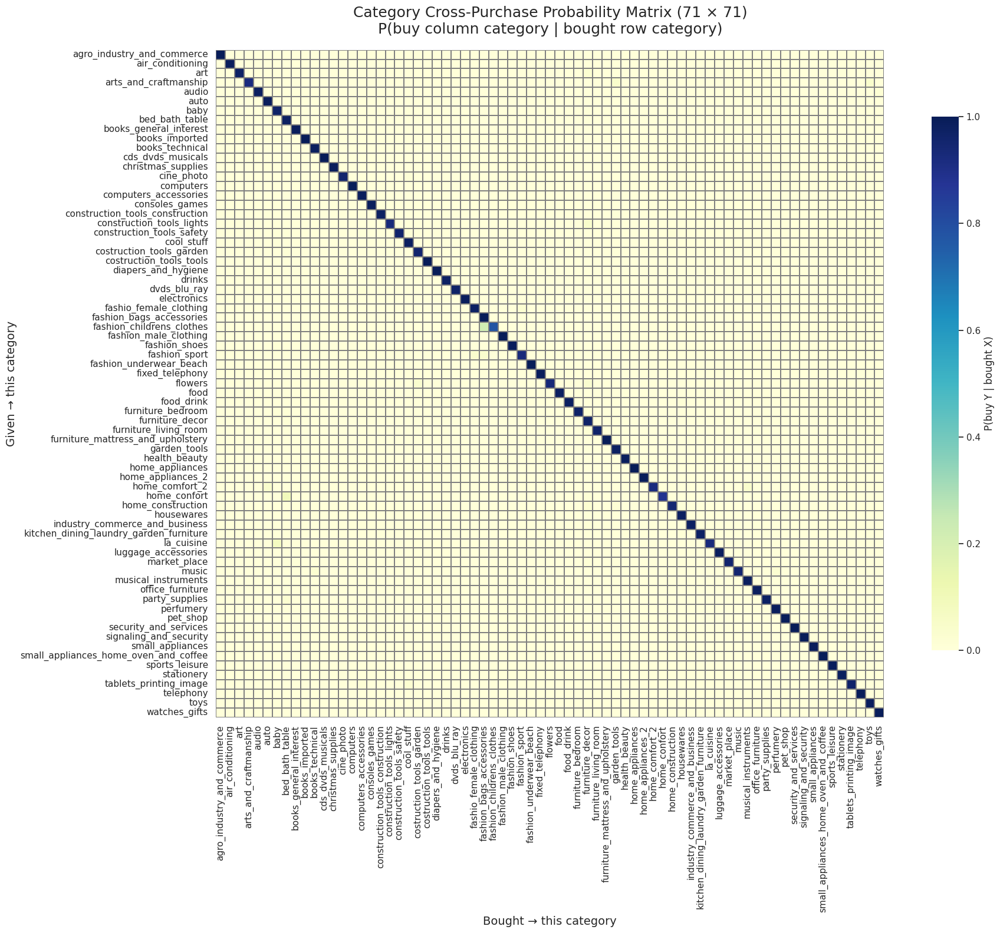

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# -------------------------------
# 1. Load the data
# -------------------------------
df = pd.read_csv("final_data.csv")

print(f"Loaded {len(df):,} rows")
print(f"Unique orders: {df['order_id'].nunique():,}")
print(f"Unique English categories: {df['product_category_name_english'].nunique()}")

# -------------------------------
# 2. Keep only delivered orders and valid categories
# -------------------------------
df = df[df['order_status'] == 'delivered'].copy()
df = df.dropna(subset=['product_category_name_english'])

# -------------------------------
# 3. Group by order_id → list of distinct categories per order
# -------------------------------
order_categories = (
    df.groupby('order_id')['product_category_name_english']
      .apply(lambda x: list(set(x)))  # distinct categories per order
      .reset_index()
)

print(f"Orders with ≥1 category: {len(order_categories):,}")

# -------------------------------
# 4. Build co-occurrence counts (71×71)
# -------------------------------
categories = sorted(df['product_category_name_english'].unique())
n = len(categories)
cat_to_idx = {cat: i for i, cat in enumerate(categories)}

co_occurrence = np.zeros((n, n), dtype=int)

for cat_list in order_categories['product_category_name_english']:
    if len(cat_list) < 1:
        continue
    # all pairs in the same order (including self-pairs)
    for i in range(len(cat_list)):
        for j in range(len(cat_list)):
            idx_i = cat_to_idx[cat_list[i]]
            idx_j = cat_to_idx[cat_list[j]]
            co_occurrence[idx_i, idx_j] += 1

# -------------------------------
# 5. Turn counts into conditional probabilities
# P(Y | X) = co_occurrence[X,Y] / total orders that contain X
# -------------------------------
# total number of orders that contain each category X
orders_with_category = np.sum(co_occurrence, axis=1)   # sum over columns

# avoid division by zero
orders_with_category[orders_with_category == 0] = 1

# conditional probability matrix
conditional_prob = co_occurrence / orders_with_category[:, None]

# Turn into DataFrame for nice plotting
prob_df = pd.DataFrame(
    conditional_prob,
    index=categories,
    columns=categories
)

# -------------------------------
# 6. Plot 71×71 heatmap
# -------------------------------
plt.figure(figsize=(20, 16))
sns.heatmap(
    prob_df,
    cmap="YlGnBu",
    square=True,
    cbar_kws={"shrink": 0.8, "label": "P(buy Y | bought X)"},
    linewidths=0.1,
    linecolor='gray'
)

plt.title("Category Cross-Purchase Probability Matrix (71 × 71)\n"
          "P(buy column category | bought row category)",
          fontsize=18, pad=20)
plt.xlabel("Bought → this category", fontsize=14)
plt.ylabel("Given → this category", fontsize=14)
plt.tight_layout()
plt.savefig("category_cross_purchase_71x71.png", dpi=300, bbox_inches='tight')
plt.show()

# -------------------------------
# 7. Optional: Interactive version with Plotly (great for exploring 71×71)
# -------------------------------
import plotly.express as px

fig = px.imshow(
    prob_df.values,
    x=categories,
    y=categories,
    color_continuous_scale="Viridis",
    aspect="auto",
    title="Interactive Category Cross-Purchase Probability (71×71)"
)
fig.update_layout(
    width=900,
    height=900,
    xaxis_title="Bought → this category",
    yaxis_title="Given → this category"
)
fig.show()

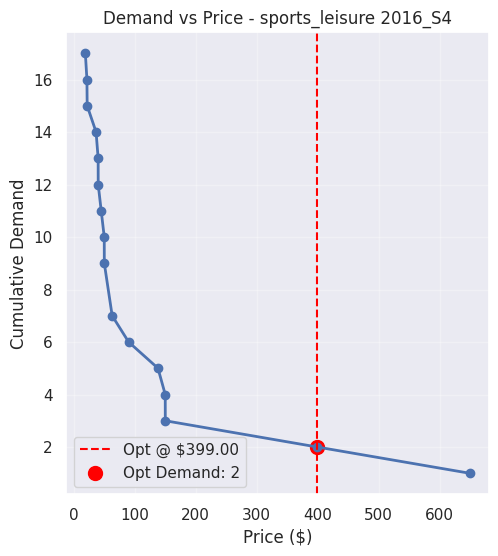

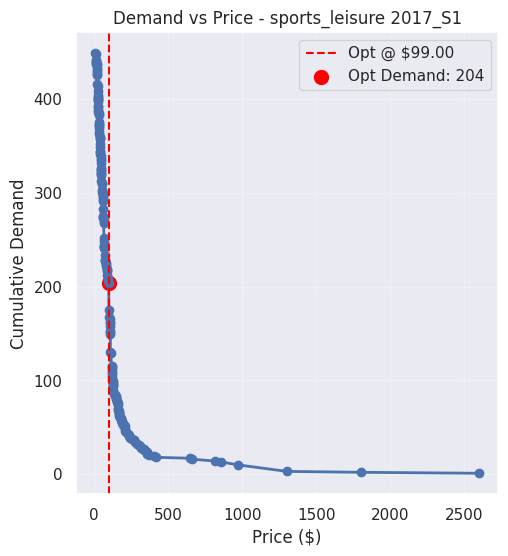

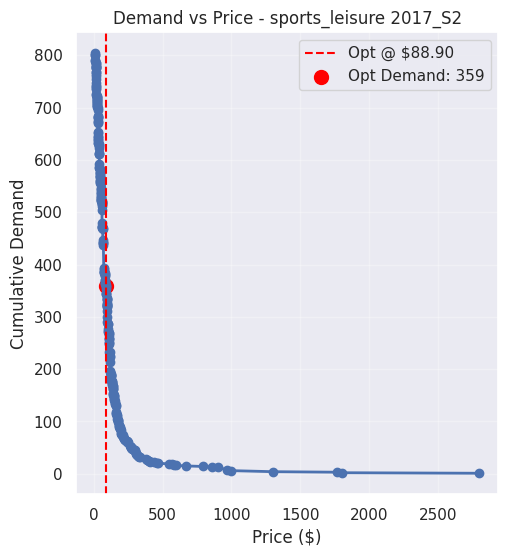

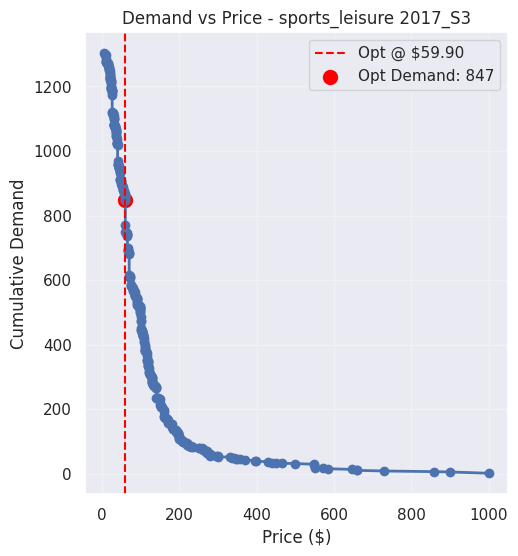

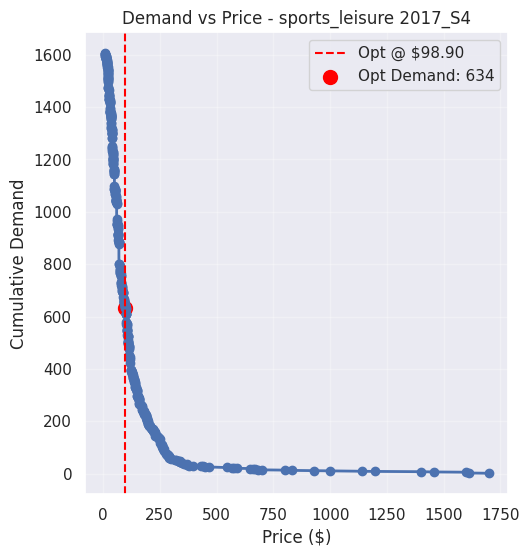

...

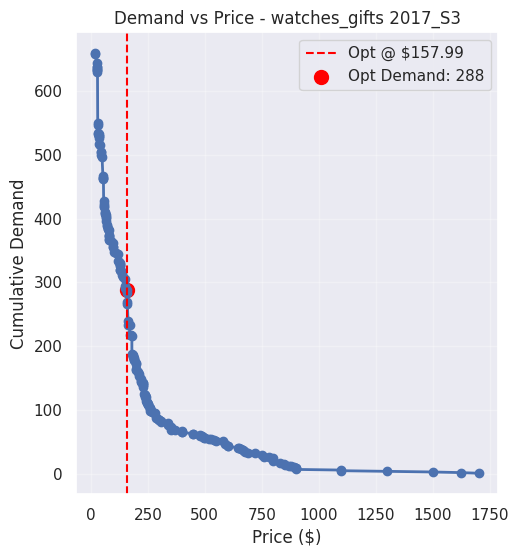

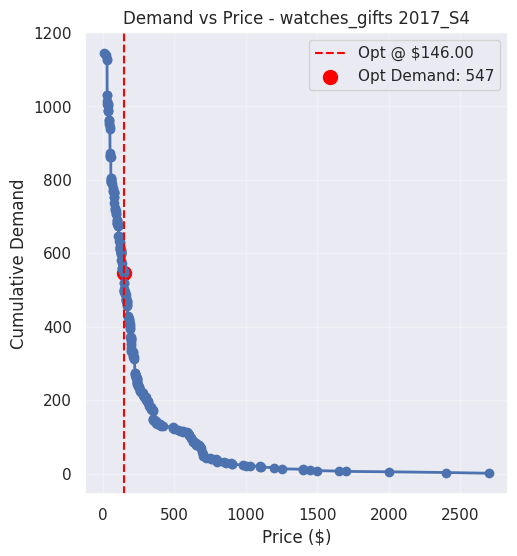

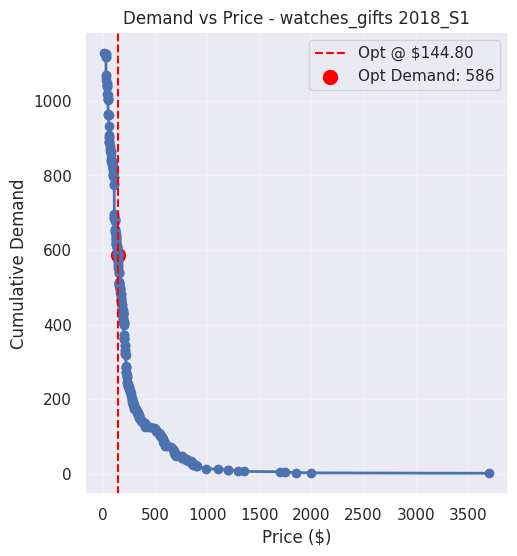

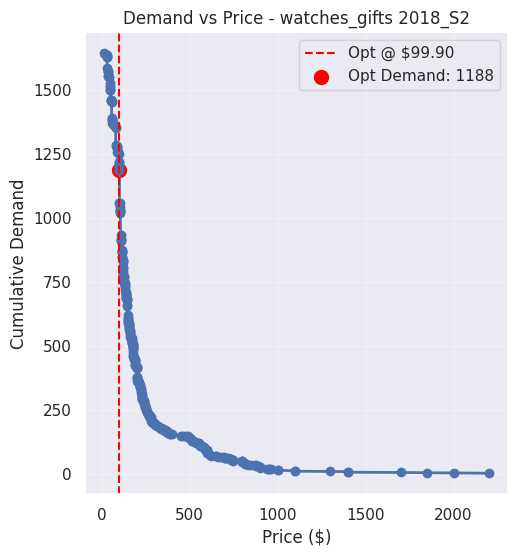

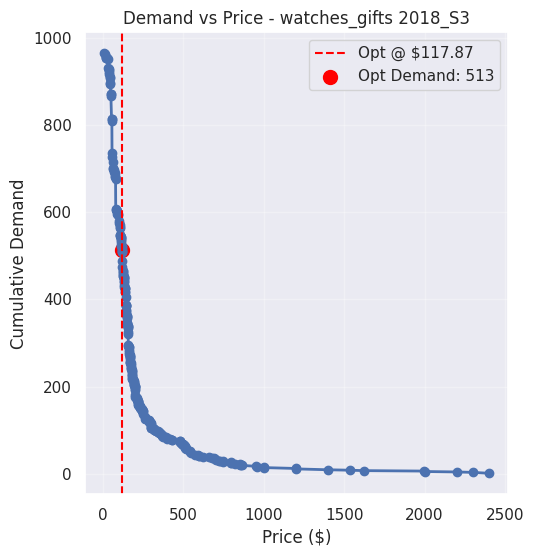

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load data
df = pd.read_csv('final_data.csv')

# Filter delivered
df = df[df['order_status'] == 'delivered']

# Convert timestamp
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])

# Add month and season (4 months per season: 1-4, 5-8, 9-12)
df['month'] = df['order_purchase_timestamp'].dt.month
df['season'] = np.ceil(df['month'] / 3).astype(int)  # Season 1: Jan-Apr (1), 2: May-Aug (2), 3: Sep-Dec (3)

# Add year-season key for grouping
df['year_season'] = df['order_purchase_timestamp'].dt.year.astype(str) + '_S' + df['season'].astype(str)

# Unique categories
unique_categories = df['product_category_name_english'].unique()

results = {}

top_categories = df.groupby('product_category_name_english')['price'].sum().sort_values(ascending=False).head(5).index  # For plots

for cat in unique_categories:
    df_cat = df[df['product_category_name_english'] == cat].copy()

    results[cat] = {}

    for ys in sorted(df_cat['year_season'].unique()):
        df_ys = df_cat[df_cat['year_season'] == ys].copy()

        # Sort by price descending
        df_ys = df_ys.sort_values('price', ascending=False).reset_index(drop=True)

        prices = df_ys['price'].values
        freights = df_ys['freight_value'].values
        n = len(df_ys)

        # Unique prices descending
        unique_prices_ys = np.sort(df_ys['price'].unique())[::-1]

        # Map to unique prices
        emp_prices = []
        emp_demands = []
        emp_revenues = []
        emp_profits = []  # For reference
        j = 0
        cum_freight = 0
        for p in unique_prices_ys:
            while j < n and prices[j] >= p:
                cum_freight += freights[j]
                j += 1
            demand = j
            revenue = p * demand
            profit = revenue - cum_freight
            emp_prices.append(p)
            emp_demands.append(demand)
            emp_revenues.append(revenue)
            emp_profits.append(profit)

        # Optimal revenue
        max_rev_idx = np.argmax(emp_revenues)
        opt_price = emp_prices[max_rev_idx]
        opt_demand = emp_demands[max_rev_idx]
        opt_revenue = emp_revenues[max_rev_idx]
        opt_profit = emp_profits[max_rev_idx]  # For reference

        # Number of unique months in this year-season
        num_months = len(df_ys['month'].unique())

        # Avg revenue per month
        avg_opt_revenue_per_month = opt_revenue / num_months if num_months > 0 else 0

        results[cat][ys] = {
            'optimal_price': opt_price,
            'optimal_demand': opt_demand,
            'optimal_revenue': opt_revenue,
            'avg_opt_revenue_per_month': avg_opt_revenue_per_month,
            'num_months': num_months,
            'optimal_profit': opt_profit  # Reference
        }

        # Plot for top categories
        if cat in top_categories:
            asc_prices = emp_prices[::-1]
            asc_demands = emp_demands[::-1]
            asc_revenues = emp_revenues[::-1]

            plt.figure(figsize=(12, 6))

            # Demand vs Price
            plt.subplot(1, 2, 1)
            plt.plot(asc_prices, asc_demands, 'o-', linewidth=2, markersize=6)
            plt.axvline(opt_price, color='red', linestyle='--', label=f'Opt @ ${opt_price:.2f}')
            plt.scatter(opt_price, opt_demand, color='red', s=100, label=f'Opt Demand: {opt_demand}')
            plt.xlabel('Price ($)')
            plt.ylabel('Cumulative Demand')
            plt.title(f'Demand vs Price - {cat} {ys}')
            plt.legend()
            plt.grid(True, alpha=0.3)

            # Revenue vs Price
            plt.subplot


Product: bb50f2e236e5eea0100680137654686c
Optimal Price: 325.0
Optimal Demand: 209
Optimal Revenue: 67925.0


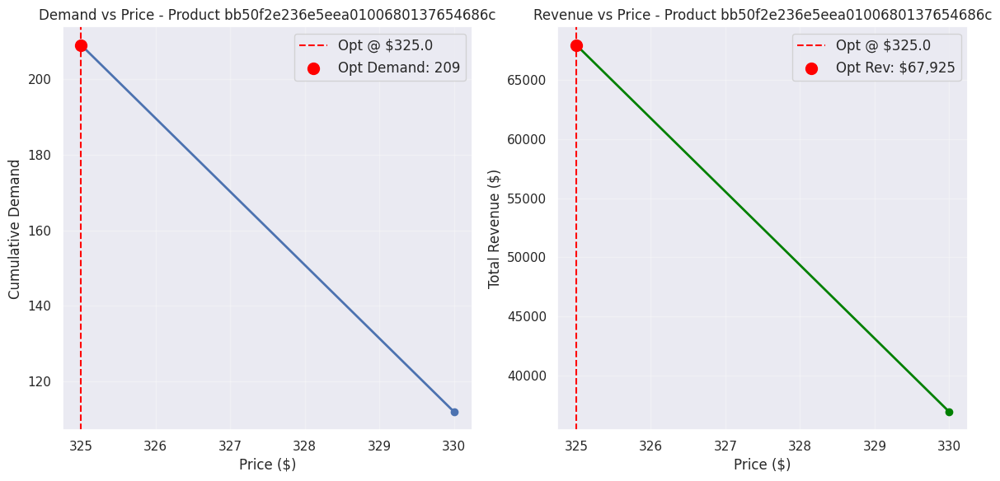


Product: 6cdd53843498f92890544667809f1595
Optimal Price: 349.9
Optimal Demand: 149
Optimal Revenue: 52135.1


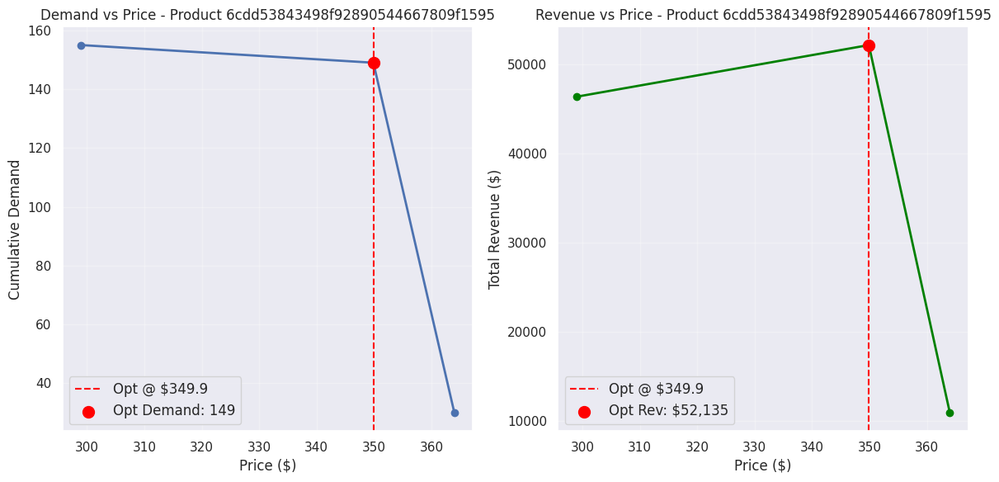


Product: d6160fb7873f184099d9bc95e30376af
Optimal Price: 1200.0
Optimal Demand: 39
Optimal Revenue: 46800.0


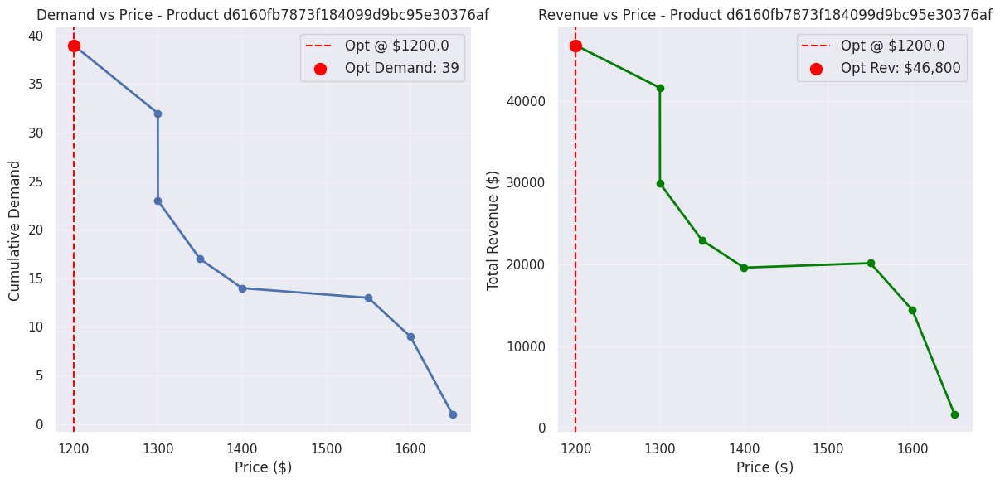


Product: d1c427060a0f73f6b889a5c7c61f2ac4
Optimal Price: 119.0
Optimal Demand: 329
Optimal Revenue: 39151.0


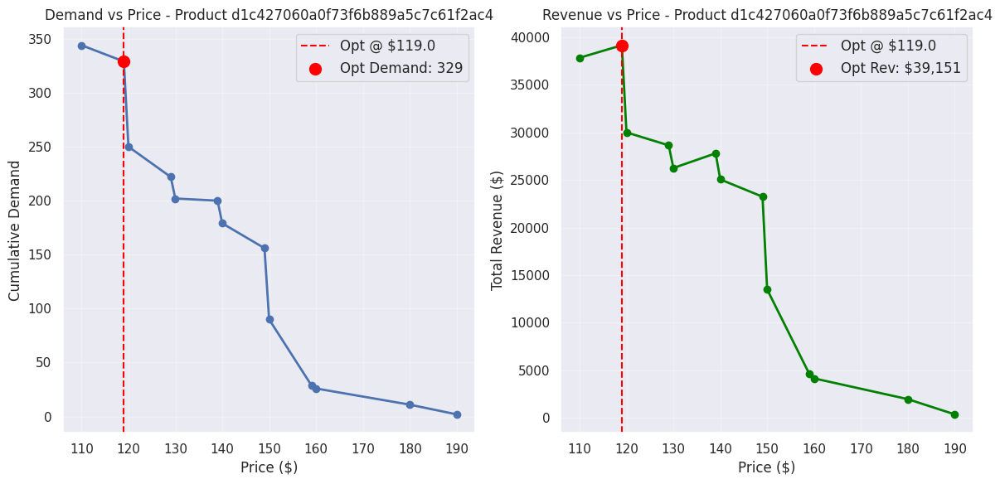

Streaming output truncated to the last 5000 lines.
Optimal Price: 18.25
Optimal Demand: 1
Optimal Revenue: 18.25

Product: 6683234fec5b07e96c1bffb5e68e2e75
Optimal Price: 18.2
Optimal Demand: 1
Optimal Revenue: 18.2

Product: e7a7e6b2b4959a39ac5ca07aa21e09ea
Optimal Price: 18.16
Optimal Demand: 1
Optimal Revenue: 18.16

Product: efefc6ae386eed5b7286cdae6168d55b
Optimal Price: 18.15
Optimal Demand: 1
Optimal Revenue: 18.15

Product: 8213da1c8eae3aa3fa5c70d87fc1581c
Optimal Price: 18.13
Optimal Demand: 1
Optimal Revenue: 18.13

Product: b162dfc96ebbb5bed62e6f3ecc8ceefe
Optimal Price: 18.1
Optimal Demand: 1
Optimal Revenue: 18.1

Product: 9538a4d0d20e31d209def88993f8dca3
Optimal Price: 18.0
Optimal Demand: 1
Optimal Revenue: 18.0

Product: 78eacca1151432fda7271e7e53e49720
Optimal Price: 18.0
Optimal Demand: 1
Optimal Revenue: 18.0

Product: 489f5d51b1c23a85ccfa4062d0cb021b
Optimal Price: 18.0
Optimal Demand: 1
Optimal Revenue: 18.0

Product: e52ba7b3c98465f5b618ed526d399357
Optimal Price:

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('final_data.csv')
df = df[df['order_status'] == 'delivered']

# Top 20 products by revenue for demo (full would be too many; adjust as needed)
product_revenue = df.groupby('product_id')['price'].sum().sort_values(ascending=False)
top_products = product_revenue.index.tolist()

results = {}
total_opt_revenue = 0

for prod in top_products:
    df_prod = df[df['product_id'] == prod].copy()

    # Sort by price descending
    df_prod = df_prod.sort_values('price', ascending=False).reset_index(drop=True)

    prices = df_prod['price'].values
    n = len(df_prod)

    # Unique prices descending
    unique_prices = np.sort(df_prod['price'].unique())[::-1]

    # Map to unique prices
    emp_prices = []
    emp_demands = []
    emp_revenues = []
    j = 0  # Index in sorted df
    for p in unique_prices:
        while j < n and prices[j] >= p:
            j += 1
        demand = j
        revenue = p * demand
        emp_prices.append(p)
        emp_demands.append(demand)
        emp_revenues.append(revenue)

    # Optimal for revenue
    max_rev_idx = np.argmax(emp_revenues)
    opt_price_rev = emp_prices[max_rev_idx]
    opt_demand_rev = emp_demands[max_rev_idx]
    opt_rev = emp_revenues[max_rev_idx]

    results[prod] = {
        'optimal_price': opt_price_rev,
        'optimal_demand': opt_demand_rev,
        'optimal_revenue': opt_rev
    }

    total_opt_revenue += opt_rev

    print(f"\nProduct: {prod}")
    print(f"Optimal Price: {opt_price_rev}")
    print(f"Optimal Demand: {opt_demand_rev}")
    print(f"Optimal Revenue: {opt_rev}")

    # Plots for top 5 only to avoid too many figures
    if prod in top_products[:4]:
        # Reverse for ascending plot
        asc_prices = emp_prices[::-1]
        asc_demands = emp_demands[::-1]
        asc_revenues = emp_revenues[::-1]

        plt.figure(figsize=(12, 6))

        # Demand vs Price
        plt.subplot(1, 2, 1)
        plt.plot(asc_prices, asc_demands, 'o-', linewidth=2, markersize=6)
        plt.axvline(opt_price_rev, color='red', linestyle='--', label=f'Opt @ ${opt_price_rev}')
        plt.scatter(opt_price_rev, opt_demand_rev, color='red', s=100, zorder=5, label=f'Opt Demand: {opt_demand_rev}')
        plt.xlabel('Price ($)')
        plt.ylabel('Cumulative Demand')
        plt.title(f'Demand vs Price - Product {prod}')
        plt.legend(fontsize=12)
        plt.grid(True, alpha=0.3)

        # Revenue vs Price
        plt.subplot(1, 2, 2)
        plt.plot(asc_prices, asc_revenues, 'o-', color='green', linewidth=2, markersize=6)
        plt.axvline(opt_price_rev, color='red', linestyle='--', label=f'Opt @ ${opt_price_rev}')
        plt.scatter(opt_price_rev, opt_rev, color='red', s=100, zorder=5, label=f'Opt Rev: ${opt_rev:,.0f}')
        plt.xlabel('Price ($)')
        plt.ylabel('Total Revenue ($)')
        plt.title(f'Revenue vs Price - Product {prod}')
        plt.legend(fontsize=12)
        plt.grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()

print(f"\nTotal Optimal Revenue: {total_opt_revenue}")

X=10000: Approx Max Profit $2172035.29, Categories: ['computers', 'small_appliances_home_oven_and_coffee', 'home_appliances_2', 'agro_industry_and_commerce', 'musical_instruments', 'small_appliances', 'fixed_telephony', 'construction_tools_safety', 'watches_gifts', 'air_conditioning', 'music', 'costruction_tools_tools', 'furniture_bedroom', 'audio', 'kitchen_dining_laundry_garden_furniture', 'security_and_services', 'la_cuisine', 'party_supplies', 'furniture_mattress_and_upholstery', 'fashion_childrens_clothes', 'arts_and_craftmanship', 'cds_dvds_musicals']
X=20000: Approx Max Profit $3438279.55, Categories: ['computers', 'small_appliances_home_oven_and_coffee', 'home_appliances_2', 'agro_industry_and_commerce', 'musical_instruments', 'small_appliances', 'fixed_telephony', 'construction_tools_safety', 'watches_gifts', 'air_conditioning', 'cool_stuff', 'music', 'costruction_tools_tools', 'furniture_bedroom', 'construction_tools_construction', 'audio', 'kitchen_dining_laundry_garden_furn

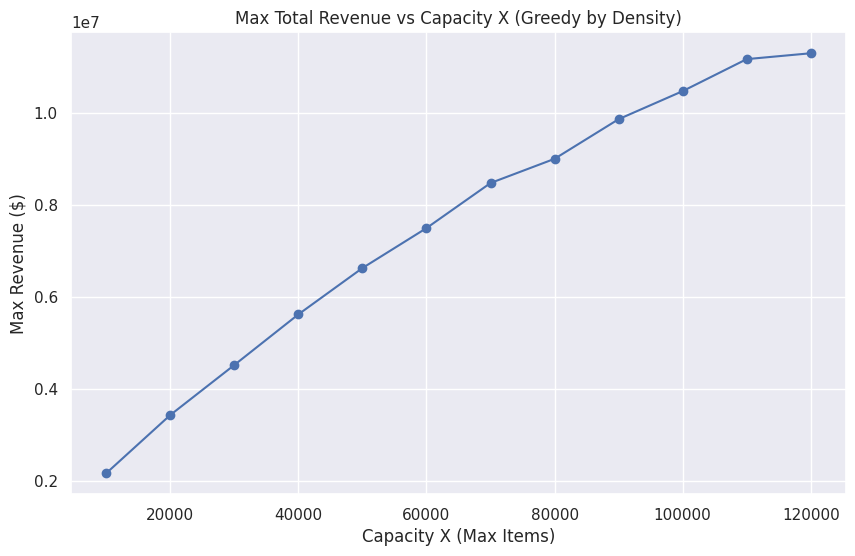

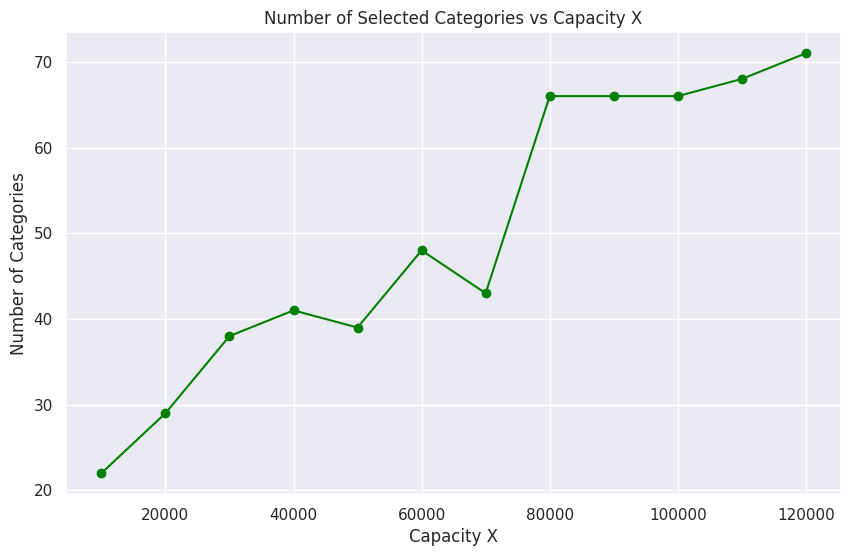

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load data
df = pd.read_csv('final_data.csv')

# Filter delivered
df = df[df['order_status'] == 'delivered']

# Compute profit per row
df['profit'] = df['price'] - df['freight_value']

# Group by category
cat_summary = df.groupby('product_category_name_english').agg(
    total_items=('order_item_id', 'count'),
    total_profit=('profit', 'sum')
).reset_index()

# Compute density
cat_summary['density'] = cat_summary['total_profit'] / cat_summary['total_items']

# Sort by density descending for greedy
cat_summary = cat_summary.sort_values('density', ascending=False).reset_index(drop=True)

# Categories list
categories = cat_summary['product_category_name_english'].values
weights = cat_summary['total_items'].values.astype(int)
values = cat_summary['total_profit'].values

# X values
X_values = np.arange(10000, 120001, 10000)

# Results (greedy select)
results = {}

for X in X_values:
    current_weight = 0
    current_value = 0
    sel_cats = []

    for i in range(len(categories)):
        if current_weight + weights[i] <= X:
            current_weight += weights[i]
            current_value += values[i]
            sel_cats.append(categories[i])

    results[X] = {
        'max_profit': current_value,
        'selected_categories': sel_cats
    }
    print(f"X={X}: Approx Max Profit ${current_value:.2f}, Categories: {sel_cats}")

# Table
table_df = pd.DataFrame([
    {'X': X, 'Max Profit': res['max_profit'], 'Selected Categories': ', '.join(res['selected_categories'])}
    for X, res in results.items()
])
print("\nTable:\n", table_df.to_string(index=False))

# Plot: Max Profit vs X
plt.figure(figsize=(10, 6))
plt.plot(list(results.keys()), [res['max_profit'] for res in results.values()], marker='o')
plt.title('Max Total Revenue vs Capacity X (Greedy by Density)')
plt.xlabel('Capacity X (Max Items)')
plt.ylabel('Max Revenue ($)')
plt.grid(True)
plt.show()

# Plot: Number of Categories vs X
plt.figure(figsize=(10, 6))
plt.plot(list(results.keys()), [len(res['selected_categories']) for res in results.values()], marker='o', color='green')
plt.title('Number of Selected Categories vs Capacity X')
plt.xlabel('Capacity X')
plt.ylabel('Number of Categories')
plt.grid(True)
plt.show()

In [ ]:
for res in results.values():
  print(len(res['selected_categories']))

22
29
38
41
39
48
43
66
66
66
68
71
71


Top Categories by Units Sold:
 product_category_name_english
bed_bath_table           11685
health_beauty             9747
sports_leisure            8736
furniture_decor           8558
computers_accessories     7927
housewares                7154
watches_gifts             6032
telephony                 4580
garden_tools              4452
auto                      4260
Name: order_item_id, dtype: int64
Top Categories by Revenue:
 product_category_name_english
health_beauty            1266992.59
watches_gifts            1207633.40
bed_bath_table           1082024.32
sports_leisure            989781.66
computers_accessories     922593.78
furniture_decor           746811.14
housewares                646232.97
cool_stuff                628528.54
auto                      594994.54
garden_tools              490451.78
Name: price, dtype: float64
Top Product ID: 53b36df67ebb7c41585e8d54d6772e08
Top Seller ID: 7d13fca15225358621be4086e1eb0964
Aggregated Data:
     price  units_sold  avg_freight

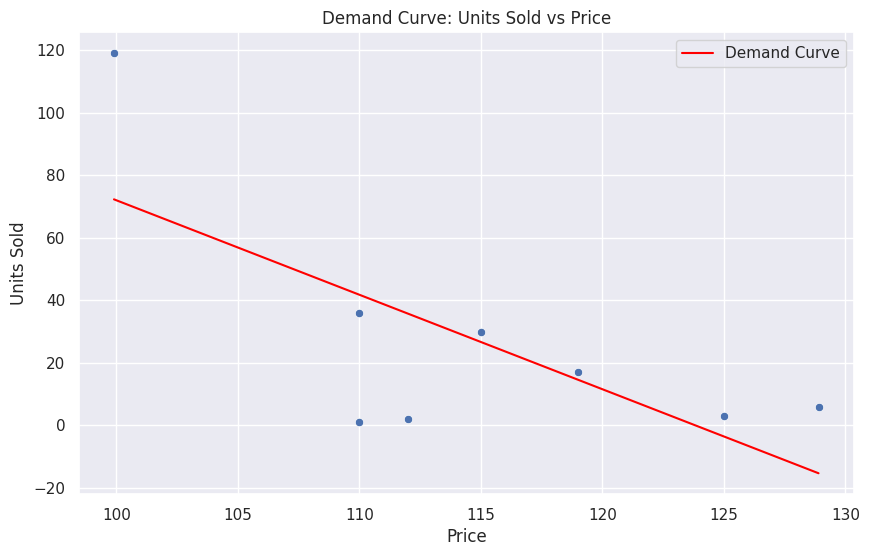

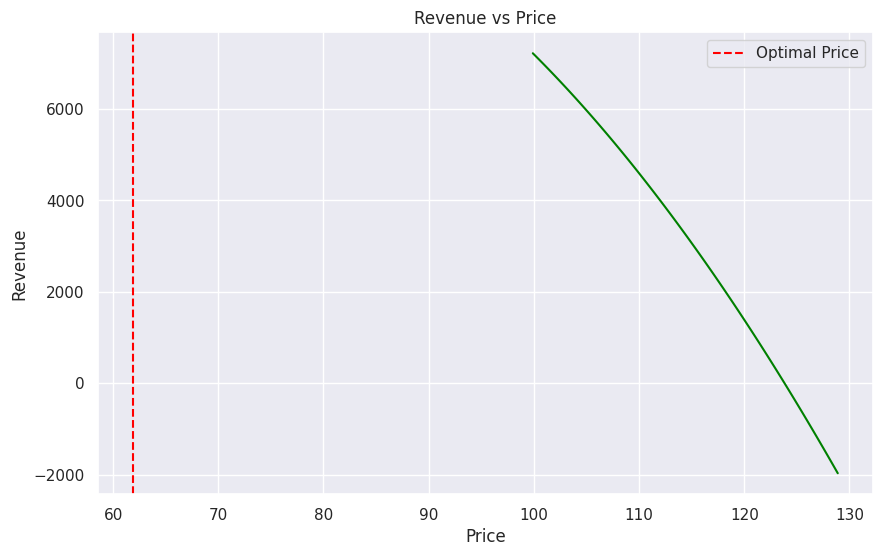

Lasso Coefficients: {'price': np.float64(-56.6133634105971), 'avg_freight': np.float64(-0.0), 'avg_review': np.float64(1.2293263741927238), 'avg_name_len': np.float64(0.0), 'avg_desc_len': np.float64(0.0), 'avg_photos': np.float64(0.0), 'avg_weight': np.float64(0.0), 'avg_length_cm': np.float64(0.0), 'avg_height_cm': np.float64(0.0), 'avg_width_cm': np.float64(0.0), 'avg_payment_seq': np.float64(21.491957085931666), 'avg_installments': np.float64(-23.91904793293613), 'avg_payment_value': np.float64(8.266683606807838), 'avg_zip_code': np.float64(0.0), 'avg_seller_zip': np.float64(0.0)}
MSE: 2219.3993510563428


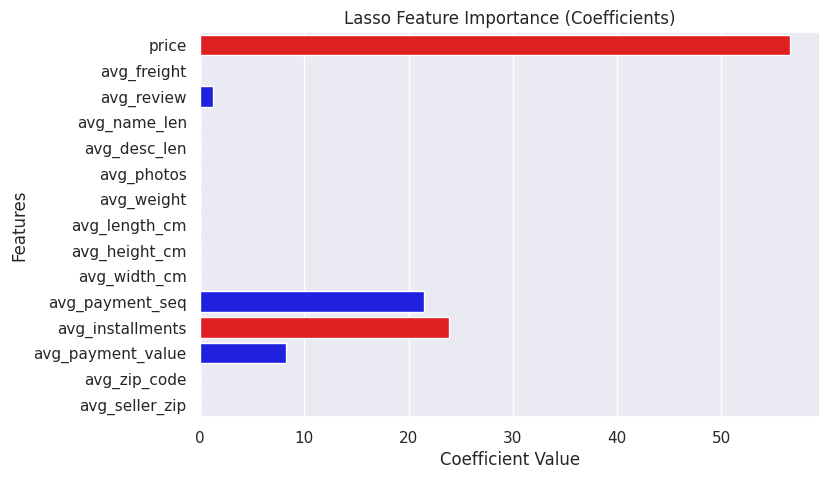

RF Feature Importances: {'price': np.float64(0.32723140357635383), 'avg_freight': np.float64(0.379240793162096), 'avg_review': np.float64(0.049018995430238396), 'avg_name_len': np.float64(0.0), 'avg_desc_len': np.float64(0.0), 'avg_photos': np.float64(0.0), 'avg_weight': np.float64(0.0), 'avg_length_cm': np.float64(0.0), 'avg_height_cm': np.float64(0.0), 'avg_width_cm': np.float64(0.0), 'avg_payment_seq': np.float64(0.012325591307343944), 'avg_installments': np.float64(0.09504654604196347), 'avg_payment_value': np.float64(0.05388699813589221), 'avg_zip_code': np.float64(0.08324967234611218), 'avg_seller_zip': np.float64(0.0)}


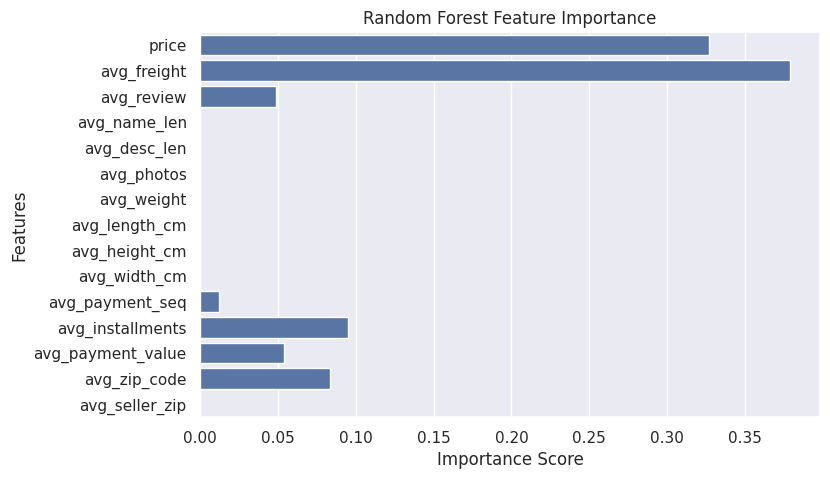

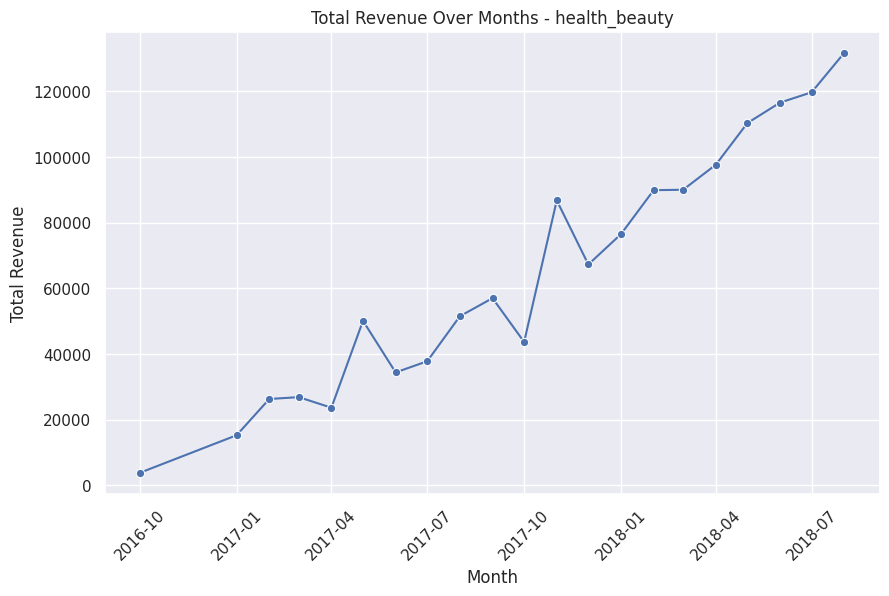

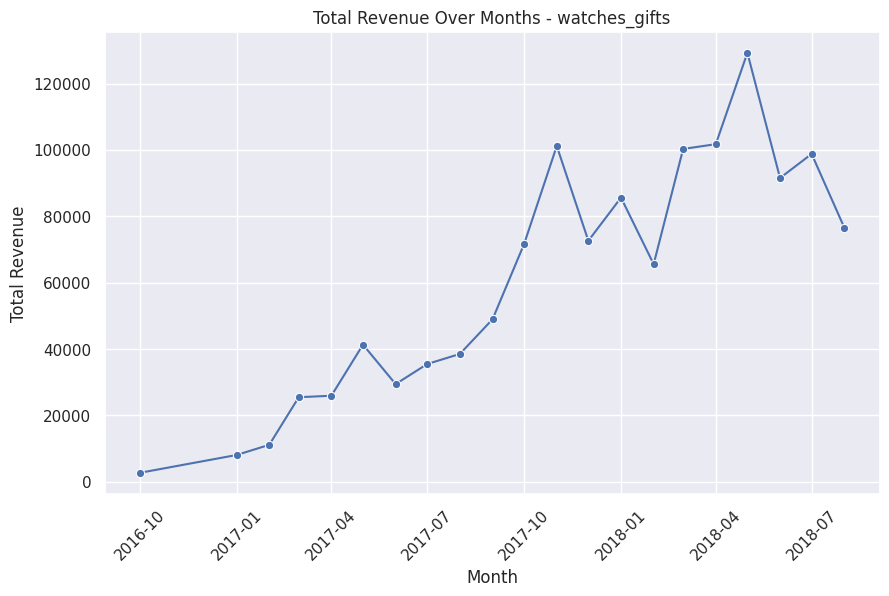

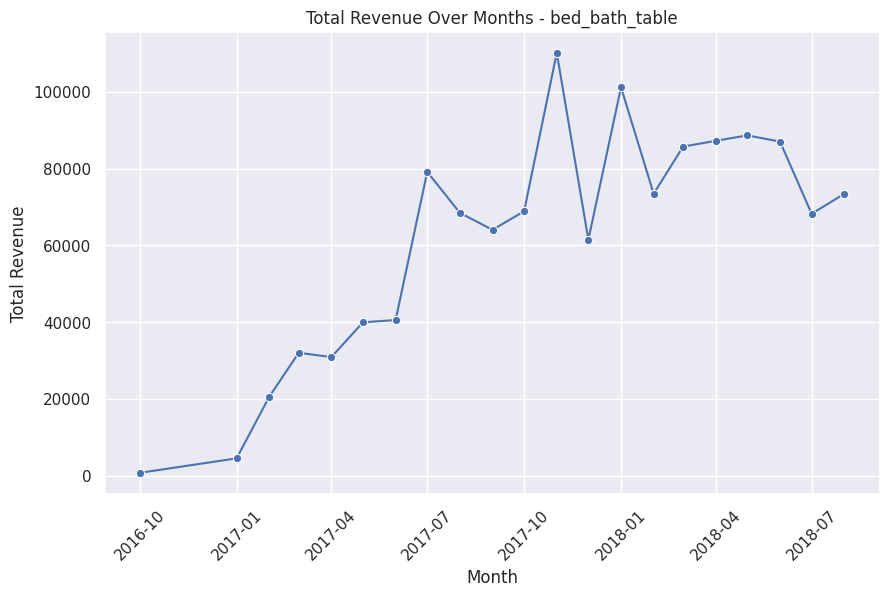

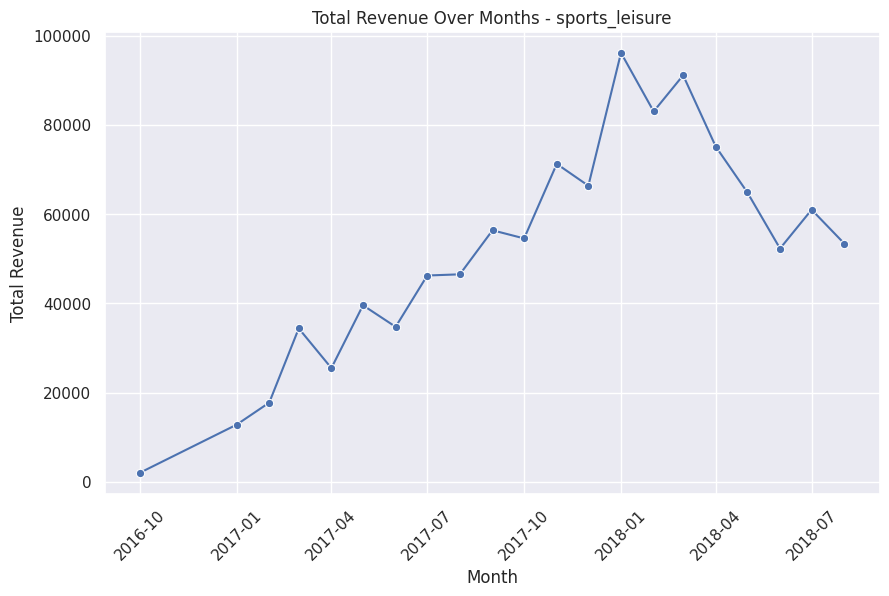

...

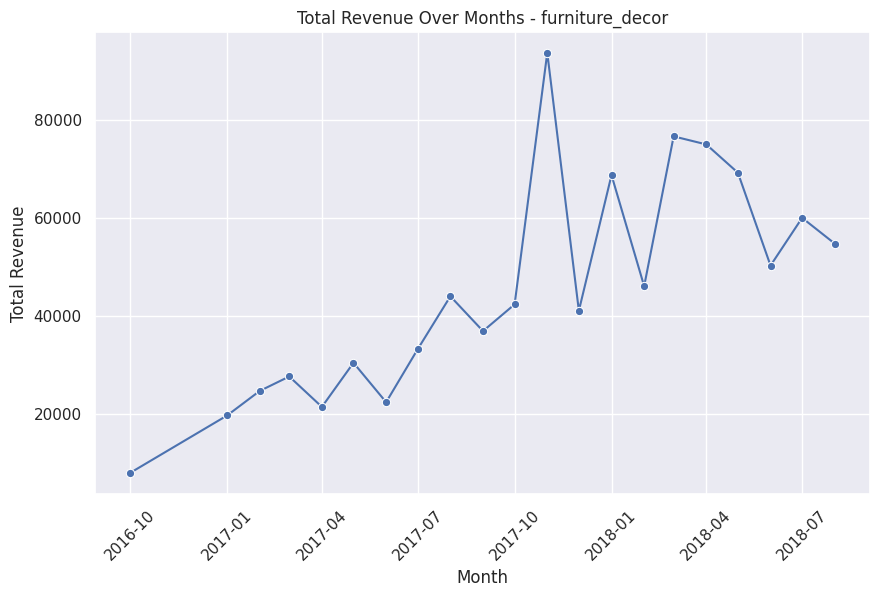

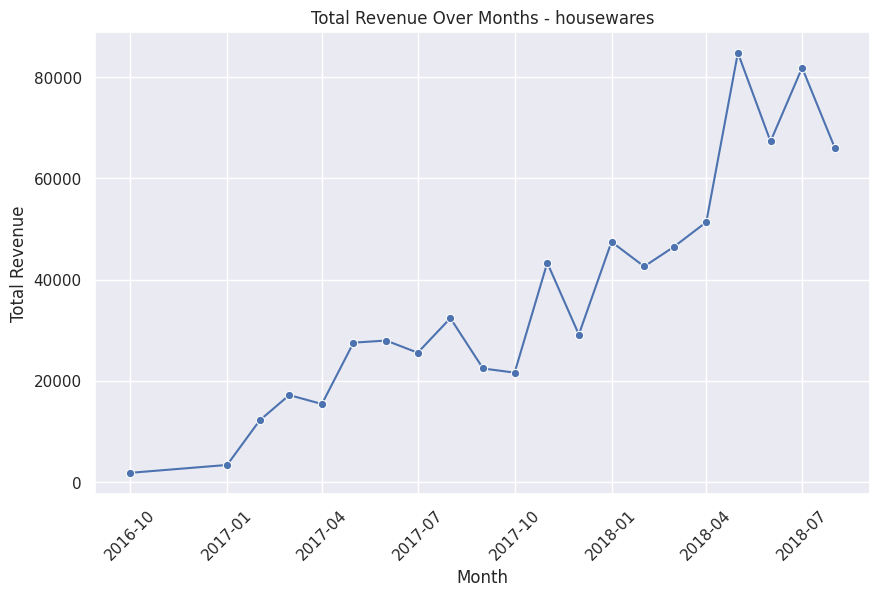

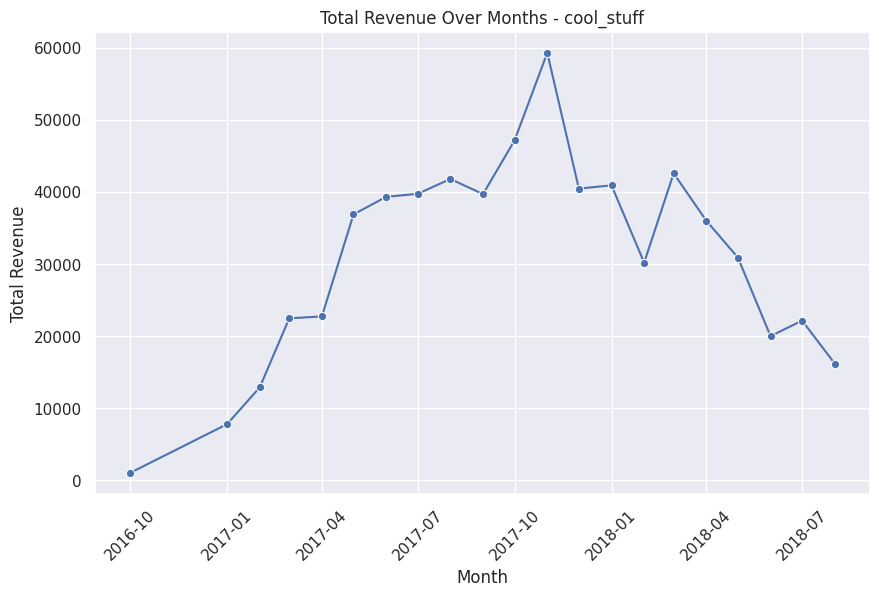

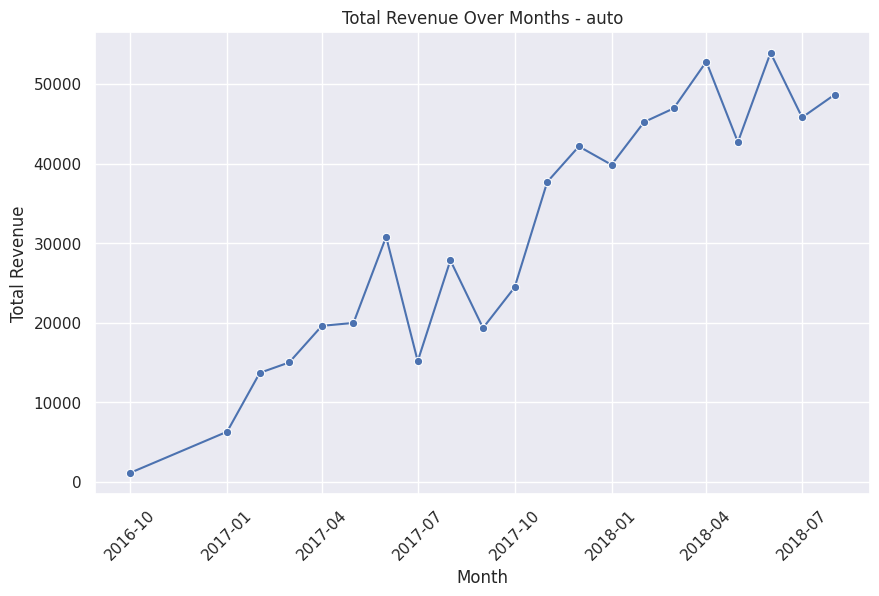

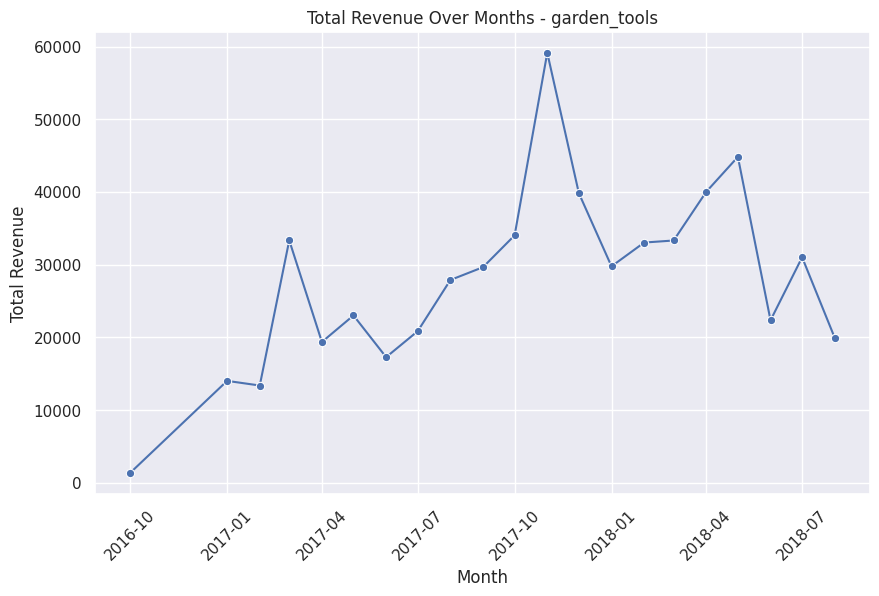

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
from sklearn.inspection import permutation_importance

# Step 1: Load and Clean Data
df = pd.read_csv('final_data.csv')

# Filter for delivered orders
df = df[df['order_status'] == 'delivered']

# Convert timestamp to datetime
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])

# Add year, month, year_month
df['year'] = df['order_purchase_timestamp'].dt.year
df['month'] = df['order_purchase_timestamp'].dt.month
df['year_month'] = df['order_purchase_timestamp'].dt.to_period('M')

# Step 2: EDA - Top Categories by Units and Revenue
category_units = df.groupby('product_category_name_english')['order_item_id'].count().sort_values(ascending=False)
category_revenue = df.groupby('product_category_name_english')['price'].sum().sort_values(ascending=False)

print("Top Categories by Units Sold:\n", category_units.head(10))
print("Top Categories by Revenue:\n", category_revenue.head(10))

# Select category: watches_gifts (top revenue generator with variation)
category = 'watches_gifts'
df_cat = df[df['product_category_name_english'] == category]

# Top product by units sold
top_product = df_cat['product_id'].value_counts().idxmax()
print("Top Product ID:", top_product)

df_prod = df_cat[df_cat['product_id'] == top_product]

# Top seller for this product
top_seller = df_prod['seller_id'].value_counts().idxmax()
print("Top Seller ID:", top_seller)

df_prod_seller = df_prod[df_prod['seller_id'] == top_seller]

# Aggregate units sold per unique price point with more features
price_agg = df_prod_seller.groupby('price').agg(
    units_sold=('order_item_id', 'count'),
    avg_freight=('freight_value', 'mean'),
    avg_review=('review_score', 'mean'),
    avg_name_len=('product_name_lenght', 'mean'),
    avg_desc_len=('product_description_lenght', 'mean'),
    avg_photos=('product_photos_qty', 'mean'),
    avg_weight=('product_weight_g', 'mean'),
    avg_length_cm=('product_length_cm', 'mean'),
    avg_height_cm=('product_height_cm', 'mean'),
    avg_width_cm=('product_width_cm', 'mean'),
    avg_payment_seq=('payment_sequential', 'mean'),
    avg_installments=('payment_installments', 'mean'),
    avg_payment_value=('payment_value', 'mean'),
    avg_zip_code=('zip_code', 'mean'),
    avg_seller_zip=('seller_zip_code_prefix', 'mean')
).reset_index()

# For categoricals, add mode and dummy (as in expanded versions)
price_agg['mode_payment_type'] = df_prod_seller.groupby('price')['payment_type'].apply(lambda x: x.mode()[0] if not x.empty else np.nan)
price_agg['mode_customer_state'] = df_prod_seller.groupby('price')['customer_state'].apply(lambda x: x.mode()[0] if not x.empty else np.nan)
price_agg = pd.get_dummies(price_agg, columns=['mode_payment_type', 'mode_customer_state'], drop_first=True)

print("Aggregated Data:\n", price_agg)

# Step 3: Simple Demand Model (Units ~ Price)
X_simple = price_agg[['price']]
y = price_agg['units_sold']

model_simple = LinearRegression()
model_simple.fit(X_simple, y)

print("Simple Model: units_sold = {:.2f} - {:.2f} * price".format(model_simple.intercept_, -model_simple.coef_[0]))
print("R-squared:", model_simple.score(X_simple, y))

# Optimization
a = model_simple.intercept_
b = -model_simple.coef_[0]
optimal_price = a / (2 * b)
optimal_units = a - b * optimal_price
optimal_revenue = optimal_price * optimal_units

print("Optimal Price: ${:.2f}".format(optimal_price))
print("Predicted Units at Optimal: {:.2f}".format(optimal_units))
print("Max Revenue per Period: ${:.2f}".format(optimal_revenue))

# Current totals
current_units = df_prod_seller['order_item_id'].sum()
current_revenue = (df_prod_seller['price'] * df_prod_seller['order_item_id']).sum()
current_avg_price = df_prod_seller['price'].mean()

# Assuming number of price points as 'periods'
num_periods = len(price_agg)
predicted_total_revenue = optimal_revenue * num_periods
margin_increase = (predicted_total_revenue - current_revenue) / current_revenue * 100

print("Margin Increase: {:.1f}%".format(margin_increase))

# Plot Demand Curve
plt.figure(figsize=(10, 6))
sns.scatterplot(x='price', y='units_sold', data=price_agg)
prices = np.linspace(price_agg['price'].min(), price_agg['price'].max(), 100)
units_pred = model_simple.predict(prices.reshape(-1, 1))
plt.plot(prices, units_pred, color='red', label='Demand Curve')
plt.title('Demand Curve: Units Sold vs Price')
plt.xlabel('Price')
plt.ylabel('Units Sold')
plt.legend()
plt.show()

# Plot Revenue Curve
revenues = prices * (model_simple.predict(prices.reshape(-1, 1)))
plt.figure(figsize=(10, 6))
plt.plot(prices, revenues, color='green')
plt.axvline(optimal_price, color='red', linestyle='--', label='Optimal Price')
plt.title('Revenue vs Price')
plt.xlabel('Price')
plt.ylabel('Revenue')
plt.legend()
plt.show()

# Step 4: Multivariate Model for Feature Importance
# Expanded features
features = [col for col in price_agg.columns if col not in ['units_sold']]
X = price_agg[features]
y = price_agg['units_sold']

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train-test split (small data, but for demo)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Lasso Regression for Feature Importance
lasso = Lasso(alpha=0.1)  # Adjust alpha for regularization
lasso.fit(X_train, y_train)

print("Lasso Coefficients:", dict(zip(features, lasso.coef_)))
print("MSE:", mean_squared_error(y_test, lasso.predict(X_test)))

# Plot Lasso Feature Importance
plt.figure(figsize=(8, 5))
lasso_colors = ['red' if c < 0 else 'blue' for c in lasso.coef_]
sns.barplot(x=abs(lasso.coef_), y=features, palette=lasso_colors)
plt.title('Lasso Feature Importance (Coefficients)')
plt.xlabel('Coefficient Value')
plt.ylabel('Features')
plt.show()

# Other Way 1: Random Forest Feature Importance
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

print("RF Feature Importances:", dict(zip(features, rf.feature_importances_)))

# Plot RF Importance
plt.figure(figsize=(8, 5))
sns.barplot(x=rf.feature_importances_, y=features)
plt.title('Random Forest Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

# New: Plot total revenue per category over months (one plot per category)
df['revenue'] = df['price'] * df['order_item_id']

# Group by category and year_month
monthly_rev = df.groupby(['product_category_name_english', 'year_month'])['revenue'].sum().reset_index()

# Limit to top 5 categories
top_cats = category_revenue.head(10).index
monthly_rev_top = monthly_rev[monthly_rev['product_category_name_english'].isin(top_cats)]

# Convert year_month to datetime for plotting
monthly_rev_top['year_month'] = monthly_rev_top['year_month'].dt.to_timestamp()

for cat in top_cats:
    df_cat_month = monthly_rev_top[monthly_rev_top['product_category_name_english'] == cat]
    plt.figure(figsize=(10, 6))
    sns.lineplot(x='year_month', y='revenue', data=df_cat_month, marker='o')
    plt.title(f'Total Revenue Over Months - {cat}')
    plt.xlabel('Month')
    plt.ylabel('Total Revenue')
    plt.xticks(rotation=45)
    plt.grid(True)
    plt.show()

In [ ]:
price_agg.columns

Index(['price', 'units_sold', 'avg_freight', 'avg_review', 'avg_photos'], dtype='object')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 115609 entries, 0 to 115608
Data columns (total 40 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   order_id                       115609 non-null  object 
 1   customer_id                    115609 non-null  object 
 2   order_status                   115609 non-null  object 
 3   order_purchase_timestamp       115609 non-null  object 
 4   order_approved_at              115595 non-null  object 
 5   order_delivered_carrier_date   114414 non-null  object 
 6   order_delivered_customer_date  113209 non-null  object 
 7   order_estimated_delivery_date  115609 non-null  object 
 8   customer_unique_id             115609 non-null  object 
 9   zip_code                       115609 non-null  int64  
 10  customer_city                  115609 non-null  object 
 11  customer_state                 115609 non-null  object 
 12  order_item_id                 

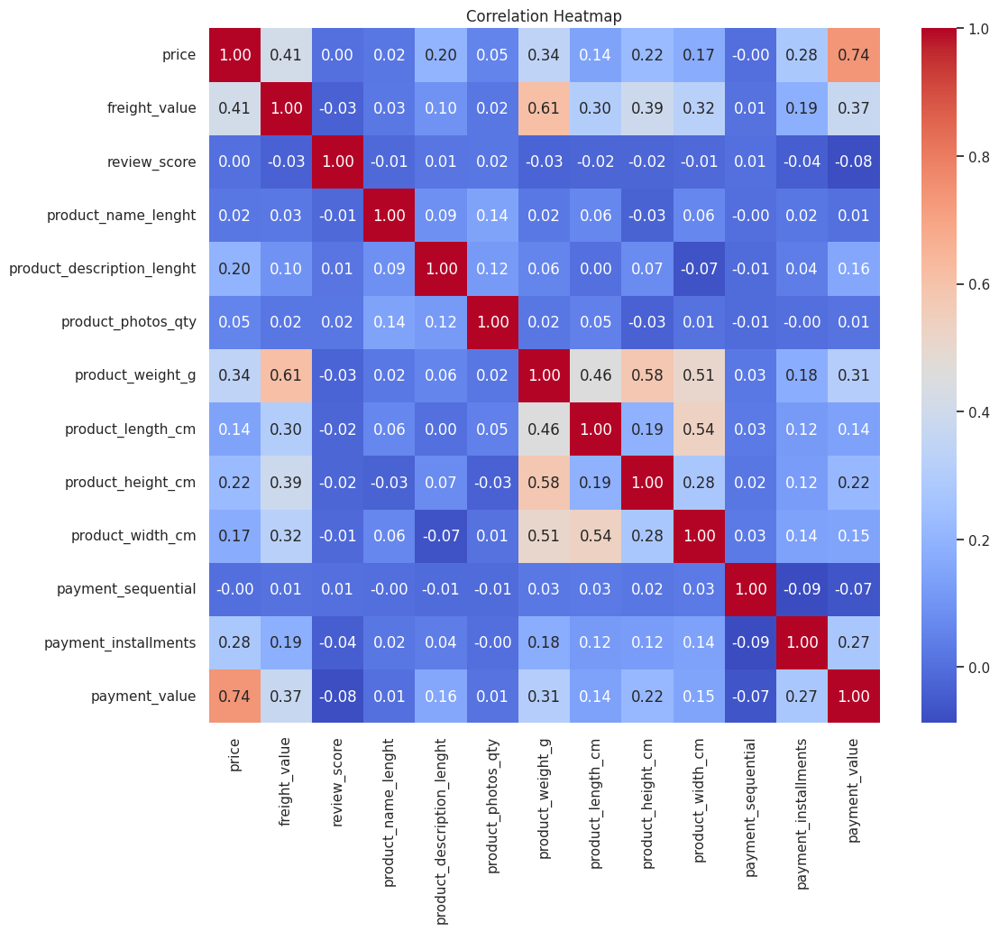

Top Categories by Units:
 product_category_name_english
bed_bath_table           11685
health_beauty             9747
sports_leisure            8736
furniture_decor           8558
computers_accessories     7927
housewares                7154
watches_gifts             6032
telephony                 4580
garden_tools              4452
auto                      4260
Name: order_item_id, dtype: int64
Top Categories by Revenue:
 product_category_name_english
health_beauty            1266992.59
watches_gifts            1207633.40
bed_bath_table           1082024.32
sports_leisure            989781.66
computers_accessories     922593.78
furniture_decor           746811.14
housewares                646232.97
cool_stuff                628528.54
auto                      594994.54
garden_tools              490451.78
Name: price, dtype: float64

Aggregated Data for Product aca2eb7d00ea1a7b8ebd4e68314663af:
    price  units_sold  avg_freight  avg_review  avg_name_len  avg_desc_len  \
0   69.9     

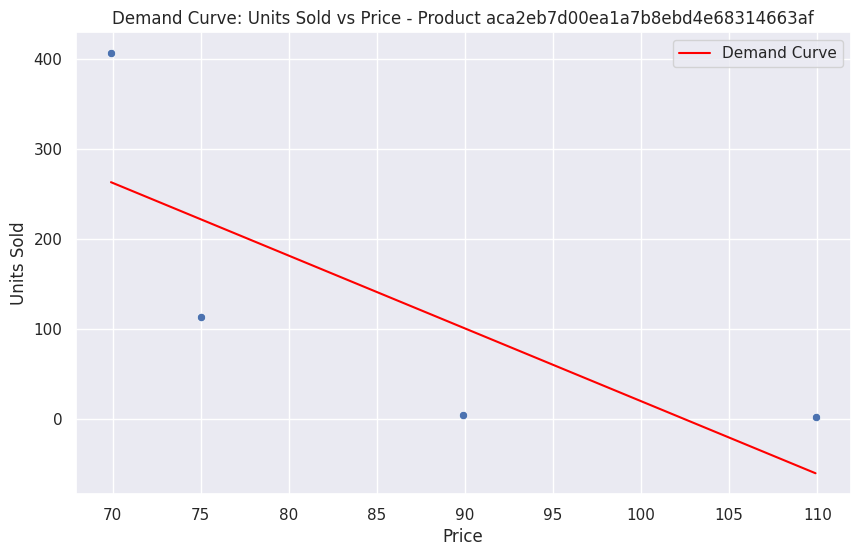

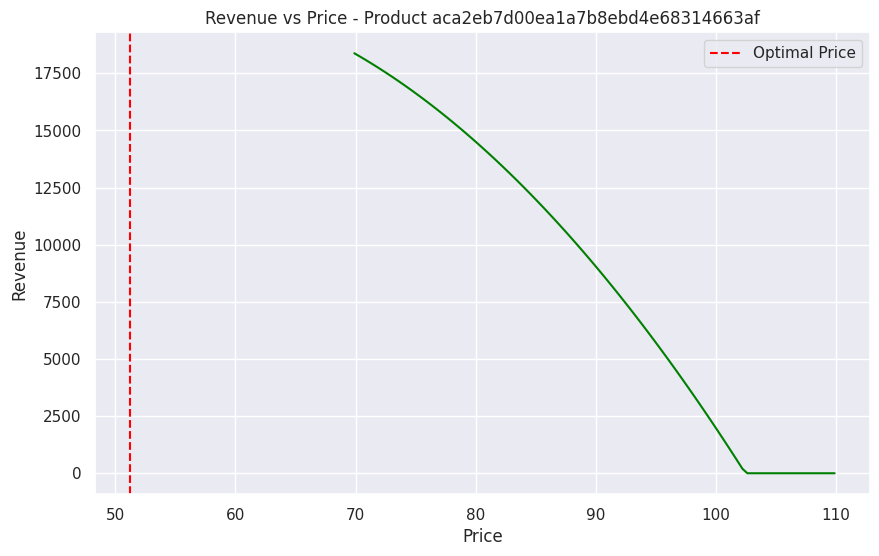

Product aca2eb7d00ea1a7b8ebd4e68314663af Lasso Coefficients: {'price': np.float64(-49.959819171754546), 'avg_freight': np.float64(-82.95979385913134), 'avg_review': np.float64(-0.0), 'avg_name_len': np.float64(0.0), 'avg_desc_len': np.float64(0.0), 'avg_photos': np.float64(0.0), 'avg_weight': np.float64(0.0), 'avg_length_cm': np.float64(0.0), 'avg_height_cm': np.float64(0.0), 'avg_width_cm': np.float64(0.0), 'avg_payment_seq': np.float64(7.6069113701906), 'avg_installments': np.float64(-0.0), 'avg_payment_value': np.float64(-47.58736061596023)}
Lasso MSE: 13086.020809716352


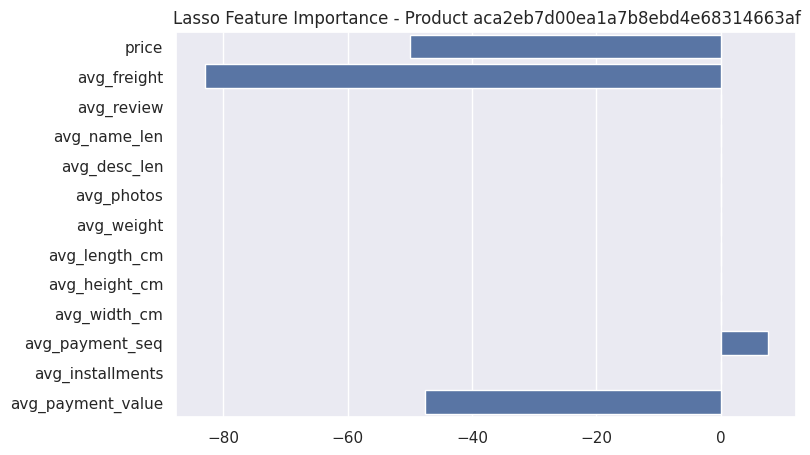

Product aca2eb7d00ea1a7b8ebd4e68314663af RF Importances: {'price': np.float64(0.2823504903927463), 'avg_freight': np.float64(0.211768136979567), 'avg_review': np.float64(0.17647205870552873), 'avg_name_len': np.float64(0.0), 'avg_desc_len': np.float64(0.0), 'avg_photos': np.float64(0.0), 'avg_weight': np.float64(0.0), 'avg_length_cm': np.float64(0.0), 'avg_height_cm': np.float64(0.0), 'avg_width_cm': np.float64(0.0), 'avg_payment_seq': np.float64(0.11764460803980507), 'avg_installments': np.float64(0.07058627466713818), 'avg_payment_value': np.float64(0.14117843121521478)}


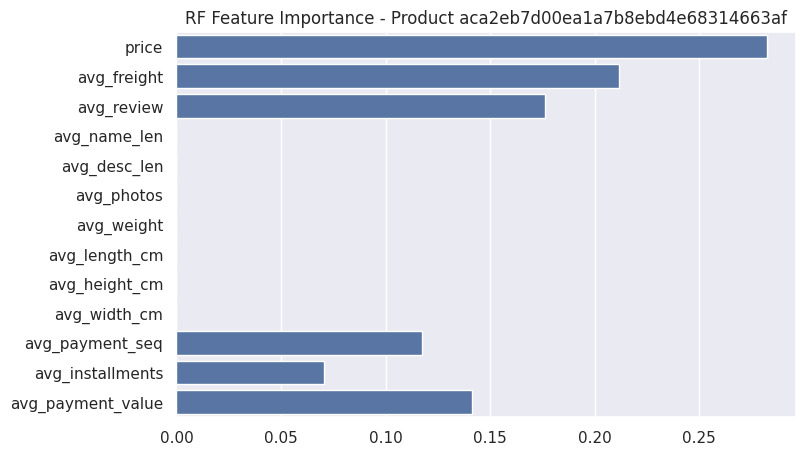


Aggregated Data for Product 99a4788cb24856965c36a24e339b6058:
    price  units_sold  avg_freight  avg_review  avg_name_len  avg_desc_len  \
0  74.00          10    17.377000    4.300000          54.0         245.0   
1  79.90          35    21.498857    4.285714          54.0         245.0   
2  83.79           4     7.990000    5.000000          54.0         245.0   
3  84.00          17    16.795294    3.882353          54.0         245.0   
4  86.00           2    15.065000    4.000000          54.0         245.0   
5  86.90          79    18.576962    3.848101          54.0         245.0   
6  89.90         360    15.624528    3.902778          54.0         245.0   

   avg_photos  avg_weight  avg_length_cm  avg_height_cm  avg_width_cm  \
0         1.0      1383.0           50.0           10.0          40.0   
1         1.0      1383.0           50.0           10.0          40.0   
2         1.0      1383.0           50.0           10.0          40.0   
3         1.0      1383.0  

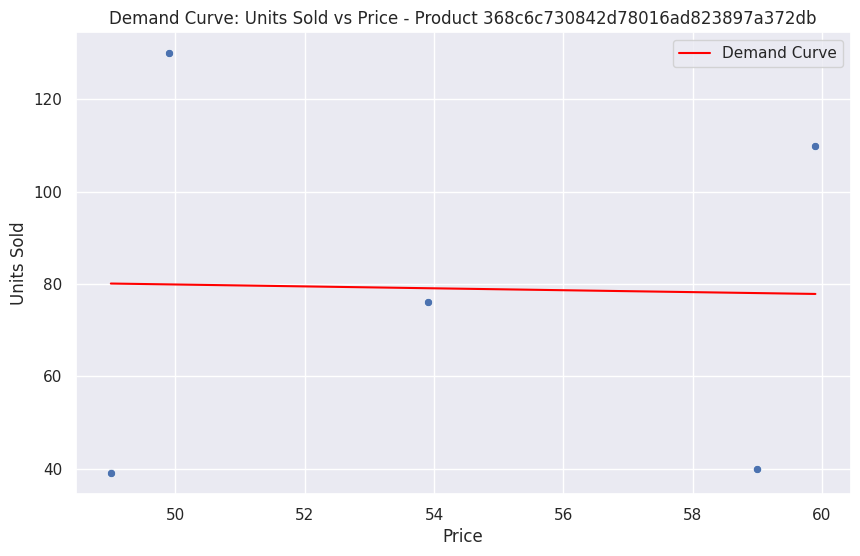

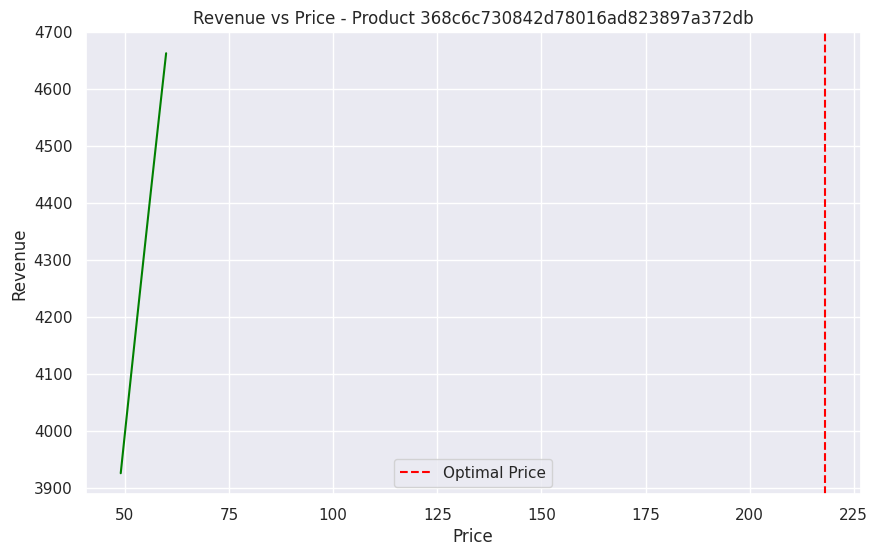

Product 368c6c730842d78016ad823897a372db Lasso Coefficients: {'price': np.float64(16.182846630468994), 'avg_freight': np.float64(-0.0), 'avg_review': np.float64(5.070851678461089), 'avg_name_len': np.float64(0.0), 'avg_desc_len': np.float64(0.0), 'avg_photos': np.float64(0.0), 'avg_weight': np.float64(0.0), 'avg_length_cm': np.float64(0.0), 'avg_height_cm': np.float64(0.0), 'avg_width_cm': np.float64(0.0), 'avg_payment_seq': np.float64(-17.83789692989165), 'avg_installments': np.float64(-0.0), 'avg_payment_value': np.float64(0.0)}
Lasso MSE: 6654.557835851037


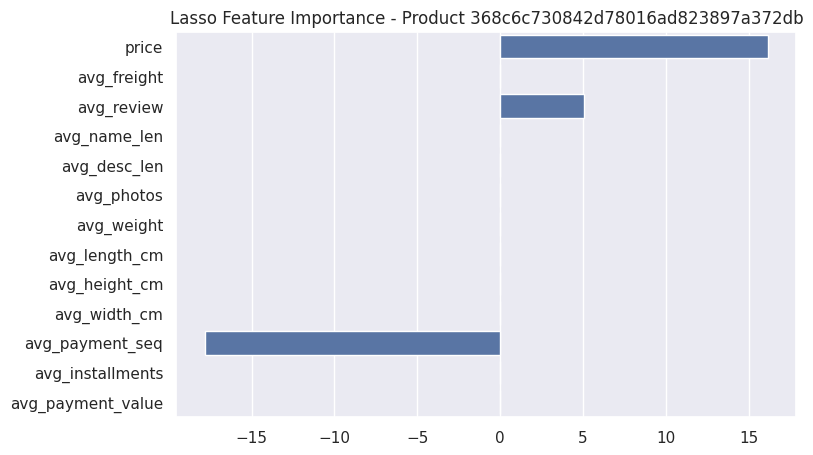

Product 368c6c730842d78016ad823897a372db RF Importances: {'price': np.float64(0.20828676184723857), 'avg_freight': np.float64(0.11449395968105432), 'avg_review': np.float64(0.28191324507757887), 'avg_name_len': np.float64(0.0), 'avg_desc_len': np.float64(0.0), 'avg_photos': np.float64(0.0), 'avg_weight': np.float64(0.0), 'avg_length_cm': np.float64(0.0), 'avg_height_cm': np.float64(0.0), 'avg_width_cm': np.float64(0.0), 'avg_payment_seq': np.float64(0.2535217711486594), 'avg_installments': np.float64(0.035768462682136924), 'avg_payment_value': np.float64(0.10601579956333196)}


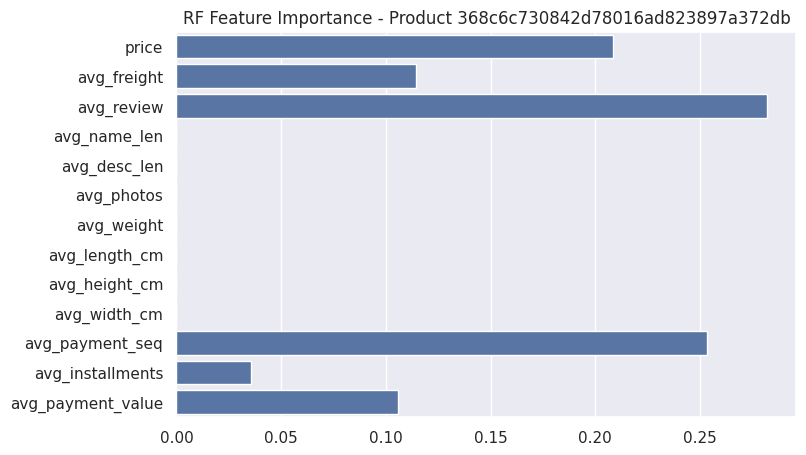


Aggregated Data for Product 53759a2ecddad2bb87a079a1f1519f73:
    price  units_sold  avg_freight  avg_review  avg_name_len  avg_desc_len  \
0   49.0          50    17.026000    3.580000          58.0         340.0   
1   49.9         103    20.432136    3.864078          58.0         340.0   
2   53.9          69    18.670000    3.507246          58.0         340.0   
3   59.0          28    16.332500    3.642857          58.0         340.0   
4   59.9         139    18.218633    4.244604          58.0         340.0   

   avg_photos  avg_weight  avg_length_cm  avg_height_cm  avg_width_cm  \
0         2.0      1500.0           30.0           22.0          30.0   
1         2.0      1500.0           30.0           22.0          30.0   
2         2.0      1500.0           30.0           22.0          30.0   
3         2.0      1500.0           30.0           22.0          30.0   
4         2.0      1500.0           30.0           22.0          30.0   

   avg_payment_seq  avg_installmen

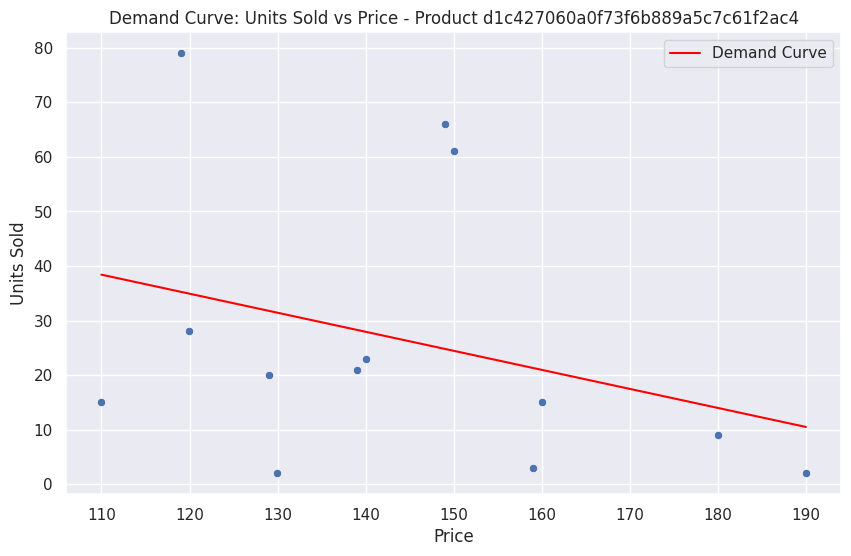

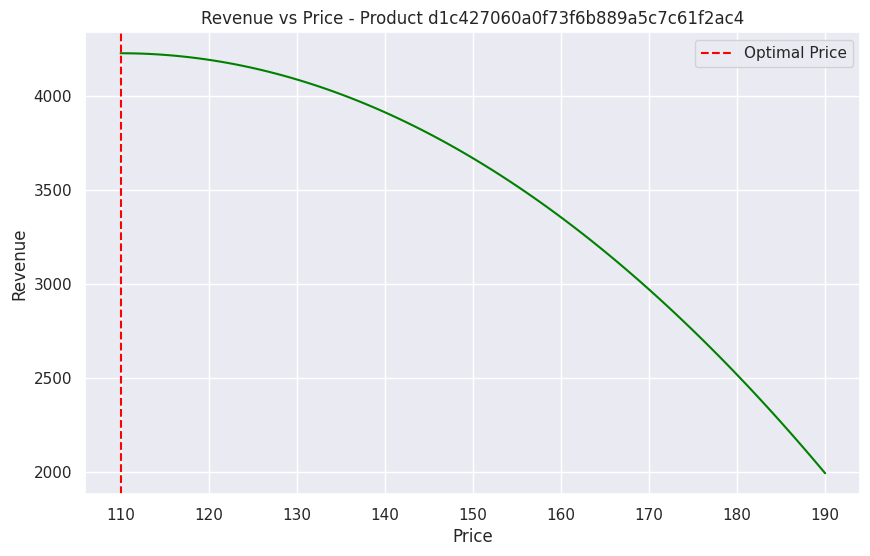

Product d1c427060a0f73f6b889a5c7c61f2ac4 Lasso Coefficients: {'price': np.float64(-35.82153874619905), 'avg_freight': np.float64(-27.94748363235525), 'avg_review': np.float64(-45.805177109679185), 'avg_name_len': np.float64(0.0), 'avg_desc_len': np.float64(0.0), 'avg_photos': np.float64(0.0), 'avg_weight': np.float64(0.0), 'avg_length_cm': np.float64(0.0), 'avg_height_cm': np.float64(0.0), 'avg_width_cm': np.float64(0.0), 'avg_payment_seq': np.float64(-7.402901886355859), 'avg_installments': np.float64(-1.958981747714089), 'avg_payment_value': np.float64(32.447580526942566)}
Lasso MSE: 10264.87605971997


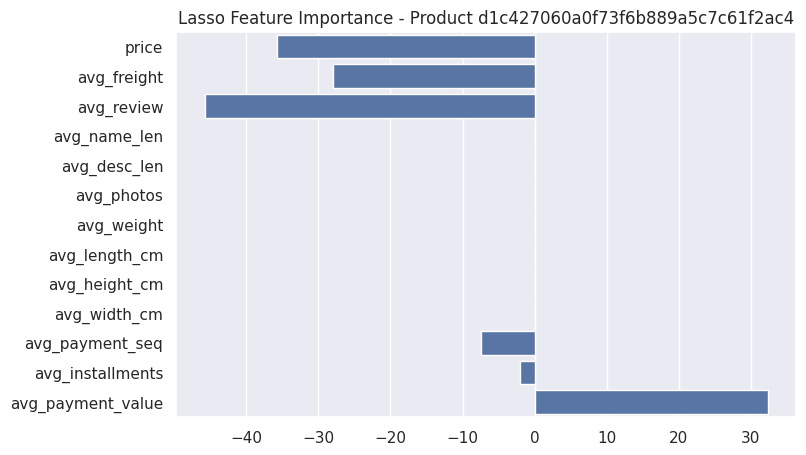

Product d1c427060a0f73f6b889a5c7c61f2ac4 RF Importances: {'price': np.float64(0.12708431245087848), 'avg_freight': np.float64(0.280583175210449), 'avg_review': np.float64(0.18192800089192482), 'avg_name_len': np.float64(0.0), 'avg_desc_len': np.float64(0.0), 'avg_photos': np.float64(0.0), 'avg_weight': np.float64(0.0), 'avg_length_cm': np.float64(0.0), 'avg_height_cm': np.float64(0.0), 'avg_width_cm': np.float64(0.0), 'avg_payment_seq': np.float64(0.23776539242703565), 'avg_installments': np.float64(0.09236045478695303), 'avg_payment_value': np.float64(0.08027866423275908)}


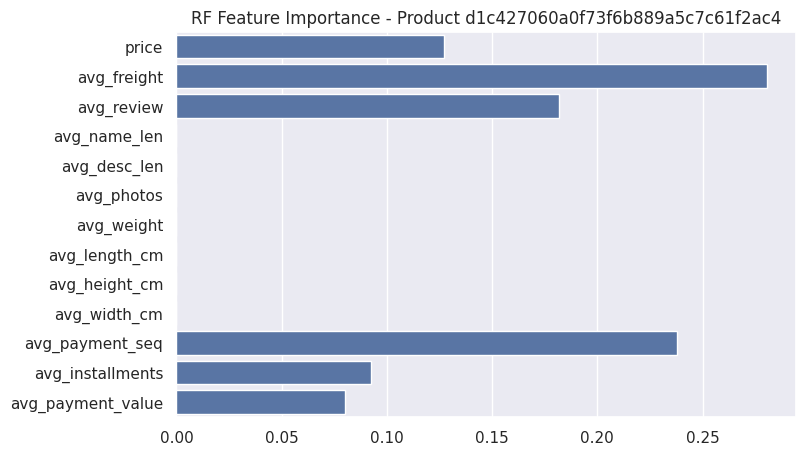


Aggregated Data for Product 53b36df67ebb7c41585e8d54d6772e08:
      price  units_sold  avg_freight  avg_review  avg_name_len  avg_desc_len  \
0    99.90         119     0.000000    4.386555          33.0         523.0   
1   106.90          15     0.000000    4.466667          33.0         523.0   
2   109.99           1     0.000000    5.000000          33.0         523.0   
3   110.00          36     3.343611    4.222222          33.0         523.0   
4   112.00           2    13.440000    5.000000          33.0         523.0   
5   112.90           7    10.858571    4.714286          33.0         523.0   
6   115.00          30    12.043000    4.133333          33.0         523.0   
7   116.90           8     0.346250    4.125000          33.0         523.0   
8   117.90           4     3.717500    3.750000          33.0         523.0   
9   119.00          20    17.431500    4.400000          33.0         523.0   
10  120.00           6    22.386667    2.500000          33.0      

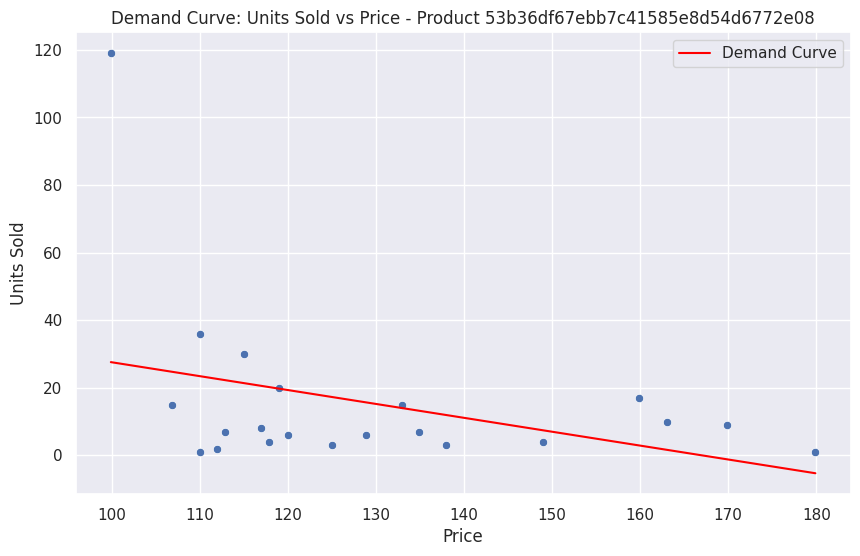

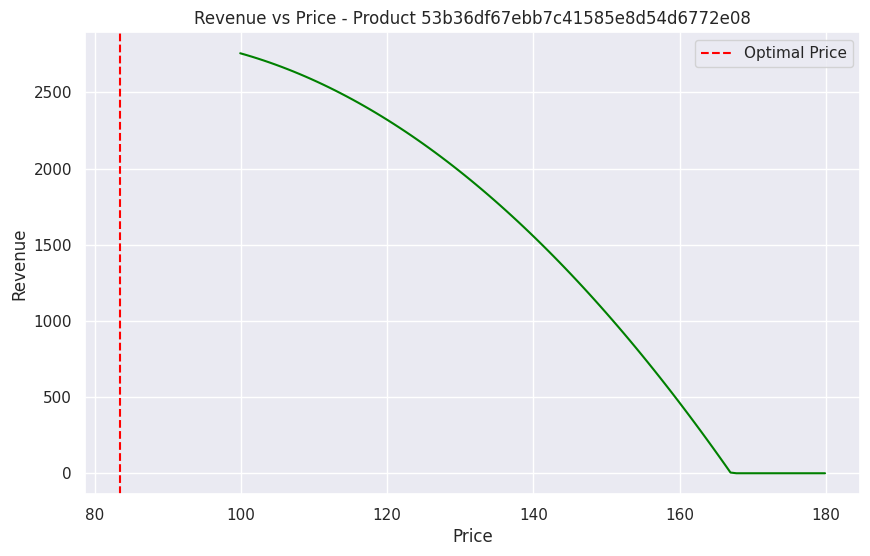

Product 53b36df67ebb7c41585e8d54d6772e08 Lasso Coefficients: {'price': np.float64(-3.5279949910587938), 'avg_freight': np.float64(-1.6609920188135239), 'avg_review': np.float64(-2.003529265983967), 'avg_name_len': np.float64(0.0), 'avg_desc_len': np.float64(0.0), 'avg_photos': np.float64(0.0), 'avg_weight': np.float64(0.0), 'avg_length_cm': np.float64(0.0), 'avg_height_cm': np.float64(0.0), 'avg_width_cm': np.float64(0.0), 'avg_payment_seq': np.float64(-0.04399624235714086), 'avg_installments': np.float64(0.741977637370959), 'avg_payment_value': np.float64(1.5308408205826536)}
Lasso MSE: 2133.043468780753


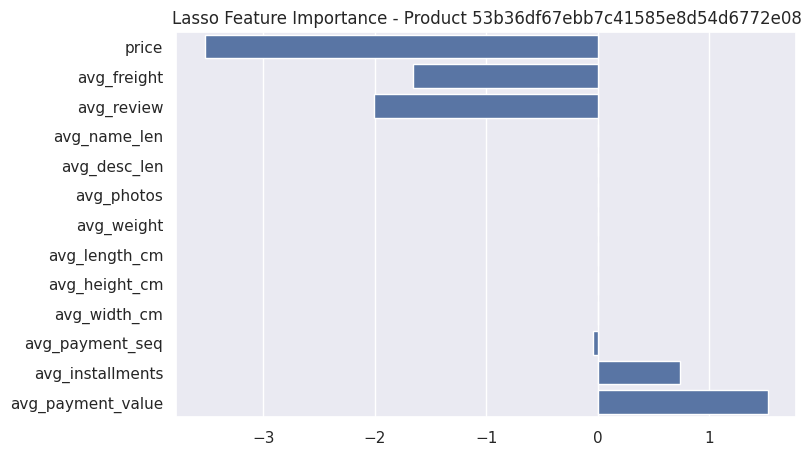

Product 53b36df67ebb7c41585e8d54d6772e08 RF Importances: {'price': np.float64(0.2609275983045702), 'avg_freight': np.float64(0.14699142292447293), 'avg_review': np.float64(0.297642286148629), 'avg_name_len': np.float64(0.0), 'avg_desc_len': np.float64(0.0), 'avg_photos': np.float64(0.0), 'avg_weight': np.float64(0.0), 'avg_length_cm': np.float64(0.0), 'avg_height_cm': np.float64(0.0), 'avg_width_cm': np.float64(0.0), 'avg_payment_seq': np.float64(0.14626710888793465), 'avg_installments': np.float64(0.09351315614237583), 'avg_payment_value': np.float64(0.05465842759201757)}


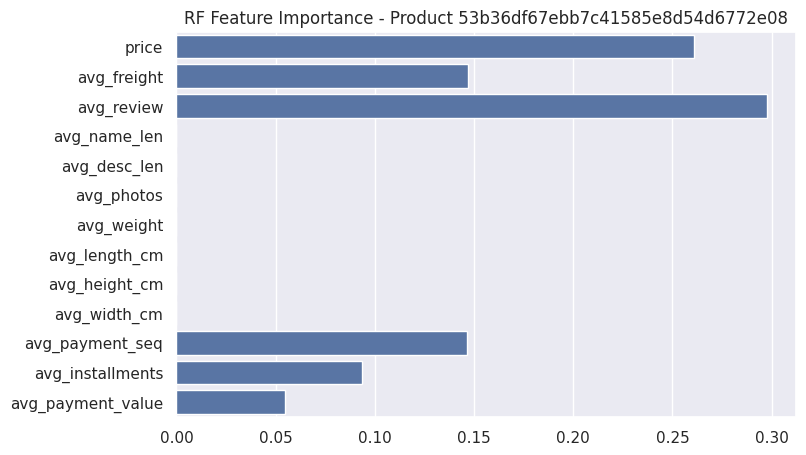


Aggregated Data for Product 154e7e31ebfa092203795c972e5804a6:
    price  units_sold  avg_freight  avg_review  avg_name_len  avg_desc_len  \
0  19.99         104    13.729904    4.317308          48.0         575.0   
1  23.99         182    13.144615    4.412088          48.0         575.0   

   avg_photos  avg_weight  avg_length_cm  avg_height_cm  avg_width_cm  \
0         1.0       100.0           20.0           15.0          15.0   
1         1.0       100.0           20.0           15.0          15.0   

   avg_payment_seq  avg_installments  avg_payment_value  
0         1.000000          1.788462          38.637019  
1         1.010989          1.978022          43.664396  
Product 154e7e31ebfa092203795c972e5804a6 OLS Summary:
                             OLS Regression Results                            
Dep. Variable:             units_sold   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                    nan
Method:           

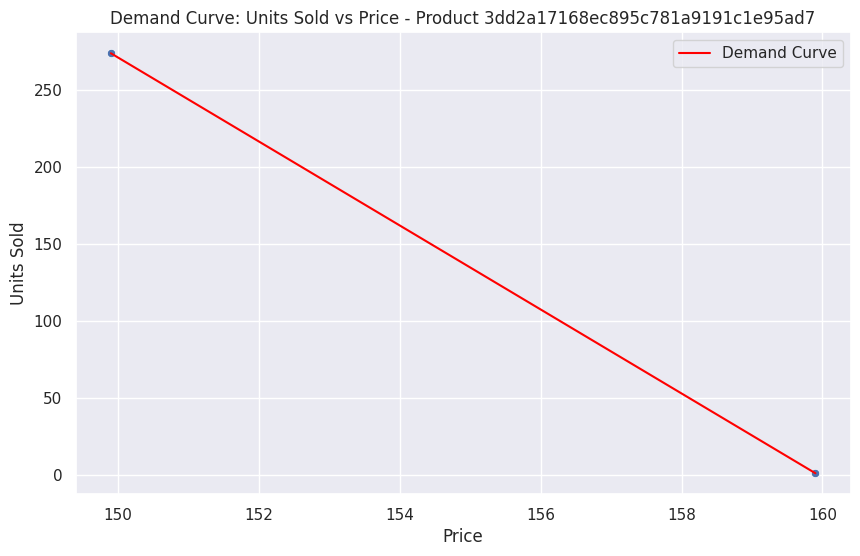

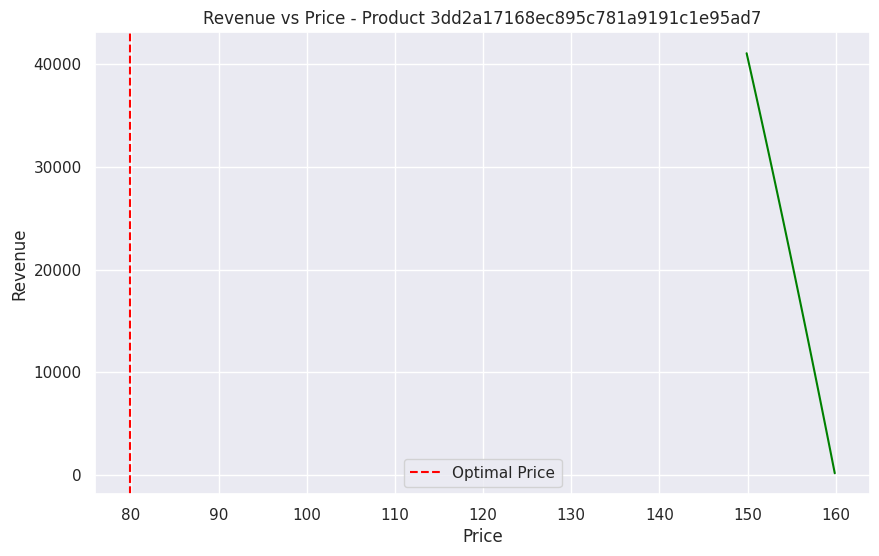

Product 3dd2a17168ec895c781a9191c1e95ad7 Lasso Coefficients: {'price': np.float64(-136.4), 'avg_freight': np.float64(0.0), 'avg_review': np.float64(-0.0), 'avg_name_len': np.float64(0.0), 'avg_desc_len': np.float64(0.0), 'avg_photos': np.float64(0.0), 'avg_weight': np.float64(0.0), 'avg_length_cm': np.float64(0.0), 'avg_height_cm': np.float64(0.0), 'avg_width_cm': np.float64(0.0), 'avg_payment_seq': np.float64(0.0), 'avg_installments': np.float64(0.0), 'avg_payment_value': np.float64(0.0)}
Lasso MSE: 0.010000000000001705


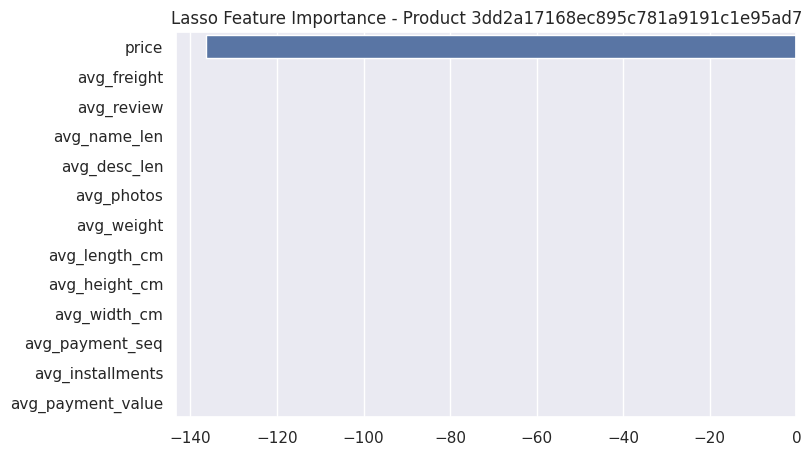

Product 3dd2a17168ec895c781a9191c1e95ad7 RF Importances: {'price': np.float64(0.1730769230769231), 'avg_freight': np.float64(0.2307692307692308), 'avg_review': np.float64(0.19230769230769235), 'avg_name_len': np.float64(0.0), 'avg_desc_len': np.float64(0.0), 'avg_photos': np.float64(0.0), 'avg_weight': np.float64(0.0), 'avg_length_cm': np.float64(0.0), 'avg_height_cm': np.float64(0.0), 'avg_width_cm': np.float64(0.0), 'avg_payment_seq': np.float64(0.1730769230769231), 'avg_installments': np.float64(0.09615384615384617), 'avg_payment_value': np.float64(0.13461538461538464)}


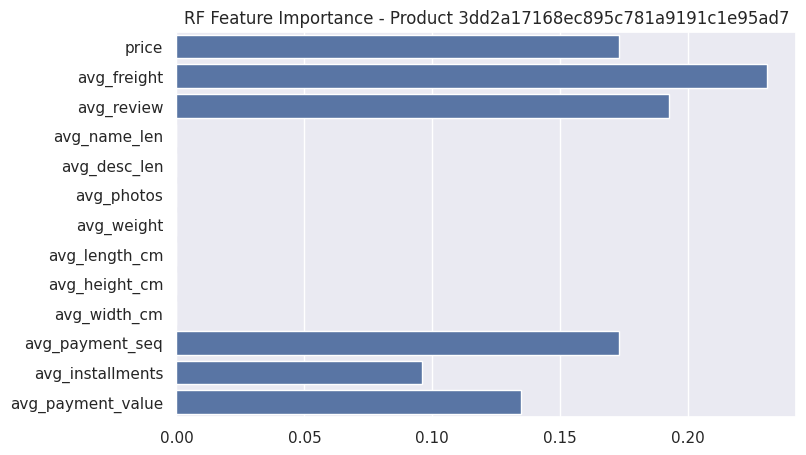

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.formula.api import ols
from sklearn import metrics
import matplotlib.dates as mdates
import matplotlib.ticker as ticker
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline
sns.set()

# Loading dataset
orders = pd.read_csv("final_data.csv")

# Data Cleaning
orders.info()

# Fix: Check NaN and drop ROWS with NaN in key columns (instead of dropping columns)
key_cols = ['price', 'freight_value', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm',
            'review_score', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty']
print("\nNaN Summary:\n", orders[key_cols].isna().sum())
orders = orders.dropna(subset=key_cols)

# Fill review comments (though no NLP, to avoid issues)
orders['review_comment_title'] = orders['review_comment_title'].fillna('')
orders['review_comment_message'] = orders['review_comment_message'].fillna('')

# Filter positive prices (added fix for potential invalid data)
orders = orders[orders['price'] > 0]

# Filter delivered (as per project focus)
orders = orders[orders['order_status'] == 'delivered']

# Convert timestamp (fix: ensure no errors)
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'], errors='coerce')
orders = orders.dropna(subset=['order_purchase_timestamp'])  # Drop invalid dates if any

# Add year (as in original for 2018 focus, but generalized)
orders['year'] = orders['order_purchase_timestamp'].dt.year

print(orders.head(5))

# Correlation Heatmap (added similar to original request)
num_cols = ['price', 'freight_value', 'review_score', 'product_name_lenght', 'product_description_lenght',
            'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm',
            'payment_sequential', 'payment_installments', 'payment_value']
corr = orders[num_cols].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

# Top categories (for reference, as in original)
category_units = orders.groupby('product_category_name_english')['order_item_id'].count().sort_values(ascending=False).head(10)
category_revenue = orders.groupby('product_category_name_english')['price'].sum().sort_values(ascending=False).head(10)
print("Top Categories by Units:\n", category_units)
print("Top Categories by Revenue:\n", category_revenue)

# Top 10 products by units sold for optimization
top_products = orders.groupby('product_id')['order_item_id'].count().sort_values(ascending=False).head(10).index

for prod_id in top_products:
    df_prod = orders[orders['product_id'] == prod_id]

    # Aggregate units sold per unique price point (similar to original)
    price_agg = df_prod.groupby('price').agg(
        units_sold=('order_item_id', 'count'),
        avg_freight=('freight_value', 'mean'),
        avg_review=('review_score', 'mean'),
        avg_name_len=('product_name_lenght', 'mean'),
        avg_desc_len=('product_description_lenght', 'mean'),
        avg_photos=('product_photos_qty', 'mean'),
        avg_weight=('product_weight_g', 'mean'),
        avg_length_cm=('product_length_cm', 'mean'),
        avg_height_cm=('product_height_cm', 'mean'),
        avg_width_cm=('product_width_cm', 'mean'),
        avg_payment_seq=('payment_sequential', 'mean'),
        avg_installments=('payment_installments', 'mean'),
        avg_payment_value=('payment_value', 'mean')
    ).reset_index()

    print(f"\nAggregated Data for Product {prod_id}:\n", price_agg)

    # Simple Demand Model (Units ~ Price) - Using OLS as in original
    model_ols = ols('units_sold ~ price', data=price_agg).fit()
    print(f"Product {prod_id} OLS Summary:\n", model_ols.summary())

    a = model_ols.params['Intercept']
    b = -model_ols.params['price']

    if b <= 0 or len(price_agg) < 2:
        print(f"Skipping Product {prod_id}: Invalid model or data")
        continue

    optimal_price = a / (2 * b)
    optimal_units = max(a - b * optimal_price, 0)
    optimal_revenue = optimal_price * optimal_units
    avg_freight = price_agg['avg_freight'].mean()
    optimal_profit = (optimal_price - avg_freight) * optimal_units if optimal_units > 0 else 0

    print("Optimal Price: ${:.2f}".format(optimal_price))
    print("Predicted Units at Optimal: {:.2f}".format(optimal_units))
    print("Max Revenue: ${:.2f}".format(optimal_revenue))
    print("Max Profit (Price - Freight): ${:.2f}".format(optimal_profit))

    # Current totals
    current_units = price_agg['units_sold'].sum()
    current_revenue = (price_agg['price'] * price_agg['units_sold']).sum()
    current_profit = current_revenue - (price_agg['avg_freight'] * price_agg['units_sold']).sum()
    revenue_in_2018 = current_revenue  # Assume all in 2018 as per original
    revenue_predicted = optimal_revenue * len(price_agg)  # Approx
    margin_percent = ((revenue_predicted - revenue_in_2018) / revenue_in_2018 * 100) if revenue_in_2018 > 0 else 0
    print("Margin Percent: {:.2f}%".format(margin_percent))

    # Plot Demand Curve
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x='price', y='units_sold', data=price_agg)
    prices_plot = np.linspace(price_agg['price'].min(), price_agg['price'].max(), 100)
    units_pred = model_ols.predict(pd.DataFrame({'price': prices_plot}))
    plt.plot(prices_plot, units_pred, color='red', label='Demand Curve')
    plt.title(f'Demand Curve: Units Sold vs Price - Product {prod_id}')
    plt.xlabel('Price')
    plt.ylabel('Units Sold')
    plt.legend()
    plt.show()

    # Plot Revenue Curve
    revenues = prices_plot * np.maximum(units_pred, 0)
    plt.figure(figsize=(10, 6))
    plt.plot(prices_plot, revenues, color='green')
    plt.axvline(optimal_price, color='red', linestyle='--', label='Optimal Price')
    plt.title(f'Revenue vs Price - Product {prod_id}')
    plt.xlabel('Price')
    plt.ylabel('Revenue')
    plt.legend()
    plt.show()

    # Multivariate (with fixes for small data: fit on all if small)
    features = ['price', 'avg_freight', 'avg_review', 'avg_name_len', 'avg_desc_len', 'avg_photos', 'avg_weight',
                'avg_length_cm', 'avg_height_cm', 'avg_width_cm', 'avg_payment_seq', 'avg_installments', 'avg_payment_value']
    X = price_agg[features]
    y = price_agg['units_sold']

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    if len(X) > 3:
        X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)
    else:
        X_train, X_test, y_train, y_test = X_scaled, X_scaled, y, y  # Fit on all for small data

    # Lasso
    lasso = Lasso(alpha=0.1)
    lasso.fit(X_train, y_train)
    print(f"Product {prod_id} Lasso Coefficients:", dict(zip(features, lasso.coef_)))
    print("Lasso MSE:", mean_squared_error(y_test, lasso.predict(X_test)))

    plt.figure(figsize=(8, 5))
    sns.barplot(x=lasso.coef_, y=features)
    plt.title(f'Lasso Feature Importance - Product {prod_id}')
    plt.show()

    # RF
    rf = RandomForestRegressor(n_estimators=100, random_state=42)
    rf.fit(X_train, y_train)
    print(f"Product {prod_id} RF Importances:", dict(zip(features, rf.feature_importances_)))

    plt.figure(figsize=(8, 5))
    sns.barplot(x=rf.feature_importances_, y=features)
    plt.title(f'RF Feature Importance - Product {prod_id}')
    plt.show()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 115609 entries, 0 to 115608
Data columns (total 40 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   order_id                       115609 non-null  object 
 1   customer_id                    115609 non-null  object 
 2   order_status                   115609 non-null  object 
 3   order_purchase_timestamp       115609 non-null  object 
 4   order_approved_at              115595 non-null  object 
 5   order_delivered_carrier_date   114414 non-null  object 
 6   order_delivered_customer_date  113209 non-null  object 
 7   order_estimated_delivery_date  115609 non-null  object 
 8   customer_unique_id             115609 non-null  object 
 9   zip_code                       115609 non-null  int64  
 10  customer_city                  115609 non-null  object 
 11  customer_state                 115609 non-null  object 
 12  order_item_id                 

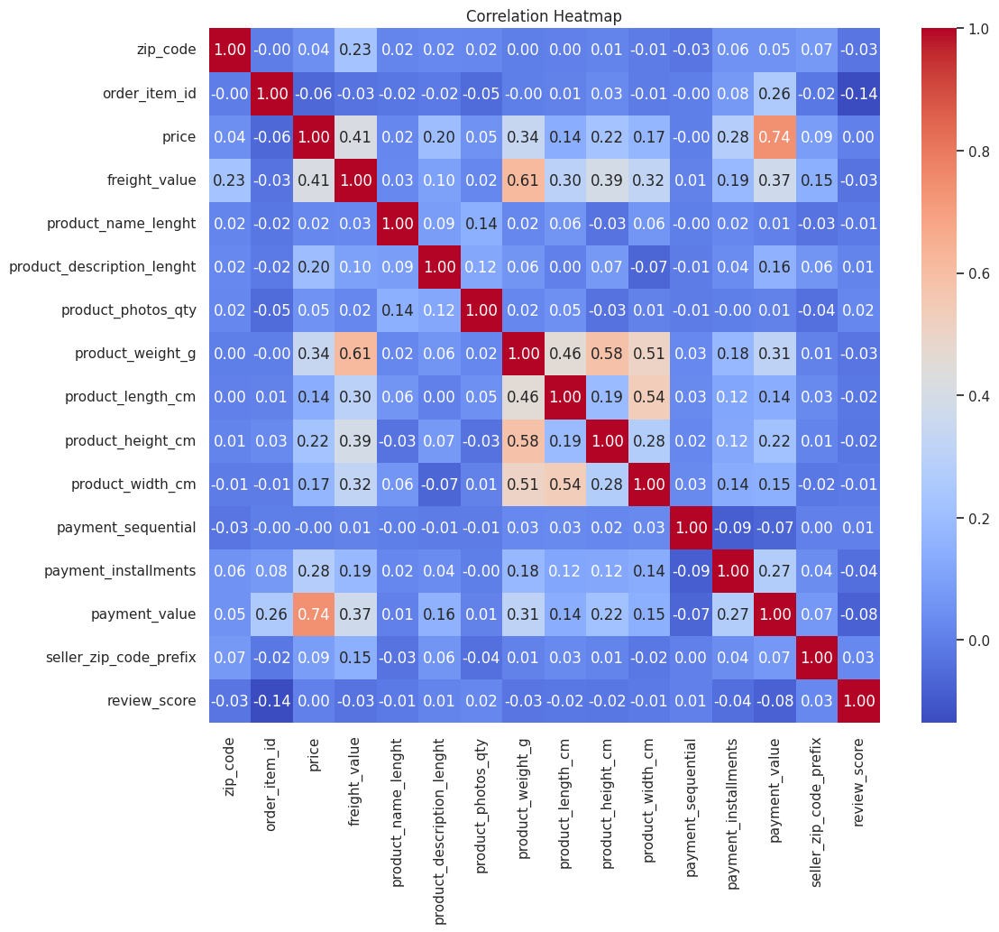

Top Categories by Units:
 product_category_name_english
bed_bath_table           11685
health_beauty             9747
sports_leisure            8736
furniture_decor           8558
computers_accessories     7927
housewares                7154
watches_gifts             6032
telephony                 4580
garden_tools              4452
auto                      4260
Name: order_item_id, dtype: int64
Top Categories by Revenue:
 product_category_name_english
health_beauty            1266992.59
watches_gifts            1207633.40
bed_bath_table           1082024.32
sports_leisure            989781.66
computers_accessories     922593.78
furniture_decor           746811.14
housewares                646232.97
cool_stuff                628528.54
auto                      594994.54
garden_tools              490451.78
Name: price, dtype: float64

health_beauty Model R-squared: 0.01


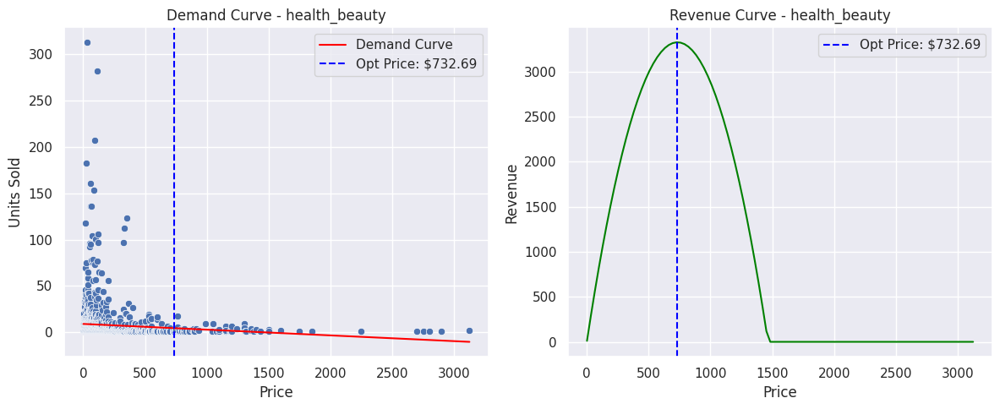

health_beauty Margin Increase: 227.2%

watches_gifts Model R-squared: 0.03


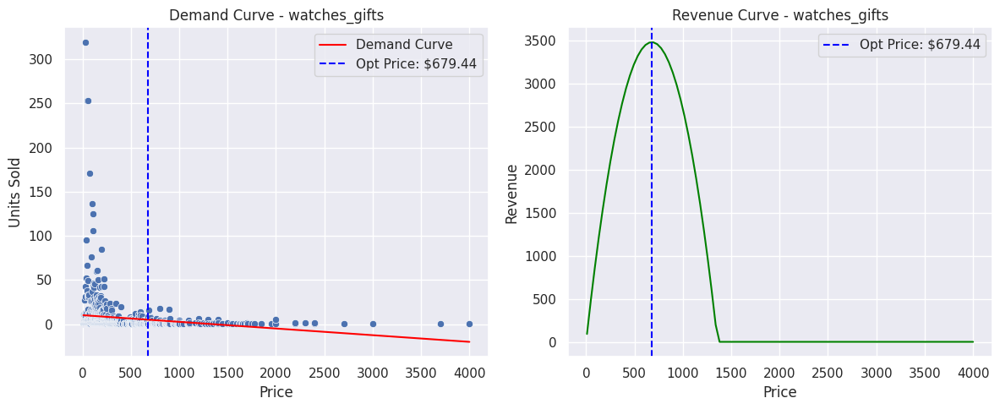

watches_gifts Margin Increase: 143.0%

bed_bath_table Model R-squared: 0.01


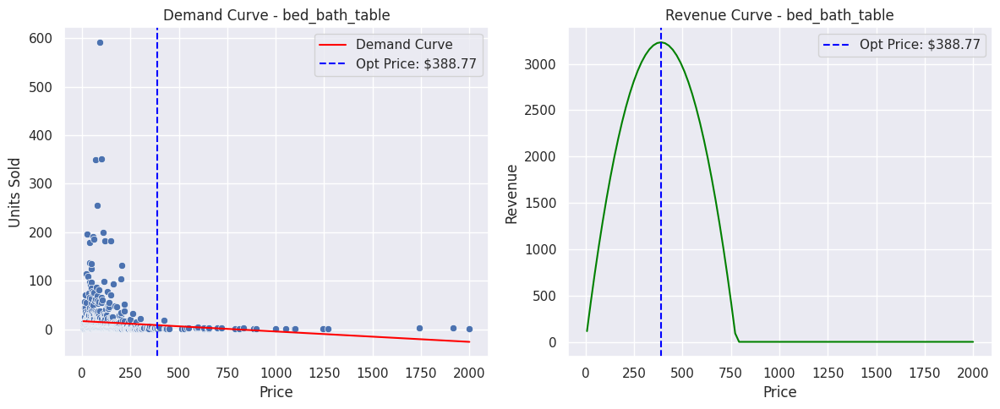

bed_bath_table Margin Increase: 157.9%

sports_leisure Model R-squared: 0.01


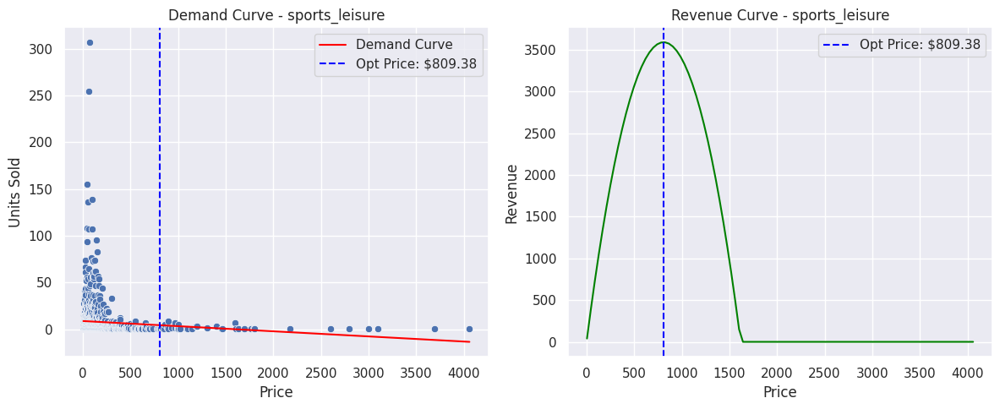

sports_leisure Margin Increase: 305.7%

computers_accessories Model R-squared: 0.02


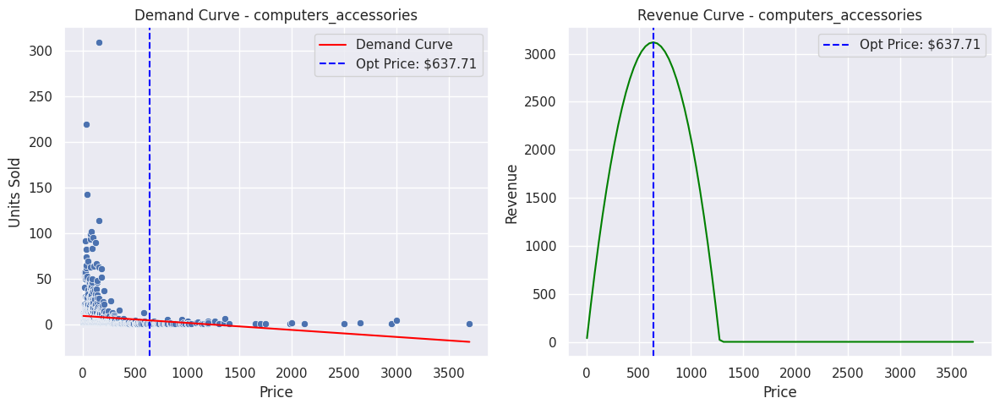

computers_accessories Margin Increase: 230.6%


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.formula.api import ols
from sklearn import metrics
from sklearn.linear_model import LinearRegression

# Importing necessary libraries (fixed imports to match essential ones)
# Removed unused like PCA, warnings, GridSearchCV for simplicity

# Loading dataset (assume final_data.csv is merged as per original)
df = pd.read_csv("final_data.csv")

# Data Cleaning
print(df.info())

# Check NaN and drop rows with NaN in key columns (fix: drop rows, not columns)
key_cols = ['price', 'freight_value', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']
df = df.dropna(subset=key_cols)
print("After dropping NaN rows:\n", df.isna().sum())

# Filter delivered only (as per safety)
df = df[df['order_status'] == 'delivered']

# Convert timestamp
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])
df['year'] = df['order_purchase_timestamp'].dt.year

# EDA
print(df.head(5))

# Correlation heatmap (added as requested)
num_cols = df.select_dtypes(include=['float64', 'int64']).columns
corr = df[num_cols].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

# Top categories by units/revenue
category_units = df.groupby('product_category_name_english')['order_item_id'].count().sort_values(ascending=False).head(10)
category_revenue = df.groupby('product_category_name_english')['price'].sum().sort_values(ascending=False).head(10)
print("Top Categories by Units:\n", category_units)
print("Top Categories by Revenue:\n", category_revenue)

# For price optimization per category (extended from original's single product)
top_categories = category_revenue.index[:5]  # Limit to top 5 for demo

for cat in top_categories:
    df_cat = df[df['product_category_name_english'] == cat]

    # Aggregate per price (similar to original for product)
    price_agg = df_cat.groupby('price').agg(units_sold=('order_item_id', 'count')).reset_index()

    if len(price_agg) < 2:
        print(f"Skipping {cat}: Not enough data")
        continue

    # Demand model (OLS as in original, but using sklearn for consistency)
    X = price_agg[['price']]
    y = price_agg['units_sold']
    model = LinearRegression()
    model.fit(X, y)

    r2 = metrics.r2_score(y, model.predict(X))
    print(f"\n{cat} Model R-squared: {r2:.2f}")

    a = model.intercept_
    b = -model.coef_[0]

    if b <= 0:
        print(f"Skipping {cat}: Invalid slope")
        continue

    opt_price = a / (2 * b)
    opt_units = max(a - b * opt_price, 0)
    opt_revenue = opt_price * opt_units

    # Plots (similar to original)
    plt.figure(figsize=(12, 5))

    # Demand Curve
    plt.subplot(1, 2, 1)
    sns.scatterplot(x='price', y='units_sold', data=price_agg)
    prices_plot = np.linspace(price_agg['price'].min(), price_agg['price'].max(), 100)
    units_pred = model.predict(prices_plot.reshape(-1, 1))
    plt.plot(prices_plot, units_pred, color='red', label='Demand Curve')
    plt.axvline(opt_price, color='blue', linestyle='--', label=f'Opt Price: ${opt_price:.2f}')
    plt.title(f'Demand Curve - {cat}')
    plt.xlabel('Price')
    plt.ylabel('Units Sold')
    plt.legend()

    # Revenue Curve
    plt.subplot(1, 2, 2)
    revenues_plot = prices_plot * np.maximum(units_pred, 0)
    plt.plot(prices_plot, revenues_plot, color='green')
    plt.axvline(opt_price, color='blue', linestyle='--', label=f'Opt Price: ${opt_price:.2f}')
    plt.title(f'Revenue Curve - {cat}')
    plt.xlabel('Price')
    plt.ylabel('Revenue')
    plt.legend()

    plt.tight_layout()
    plt.show()

    # Margin (similar to original)
    current_revenue = (price_agg['price'] * price_agg['units_sold']).sum()
    predicted_revenue = opt_revenue * len(price_agg)  # Approx periods
    margin_percent = ((predicted_revenue - current_revenue) / current_revenue * 100) if current_revenue > 0 else 0
    print(f"{cat} Margin Increase: {margin_percent:.1f}%")

NaN Summary:
 order_id                             0
customer_id                          0
order_status                         0
order_purchase_timestamp             0
order_approved_at                   14
order_delivered_carrier_date         2
order_delivered_customer_date        8
order_estimated_delivery_date        0
customer_unique_id                   0
zip_code                             0
customer_city                        0
customer_state                       0
order_item_id                        0
product_id                           0
seller_id                            0
shipping_limit_date                  0
price                                0
freight_value                        0
product_category_name                0
product_name_lenght                  0
product_description_lenght           0
product_photos_qty                   0
product_weight_g                     1
product_length_cm                    1
product_height_cm                    1
product_wid

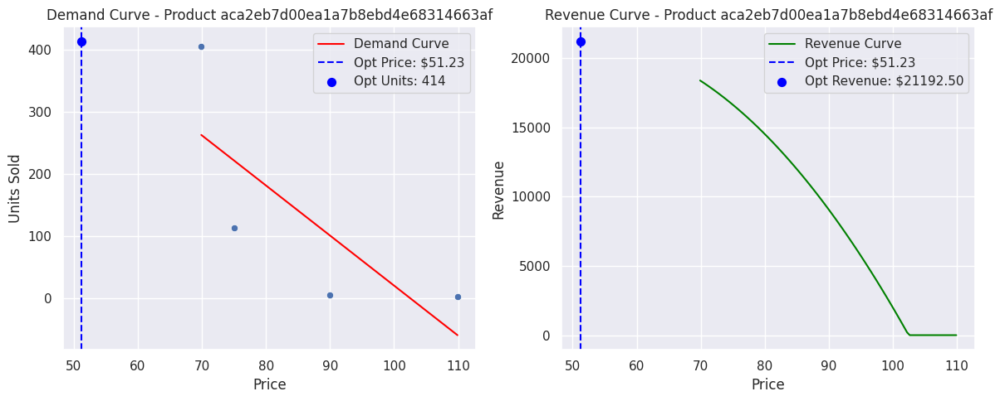


Product 99a4788cb24856965c36a24e339b6058 R-squared: 0.34
Skipping 99a4788cb24856965c36a24e339b6058: Non-negative slope

Product 422879e10f46682990de24d770e7f83d R-squared: 0.21
Skipping 422879e10f46682990de24d770e7f83d: Non-negative slope

Product 389d119b48cf3043d311335e499d9c6b R-squared: 0.02
Skipping 389d119b48cf3043d311335e499d9c6b: Non-negative slope

Product 368c6c730842d78016ad823897a372db R-squared: 0.00


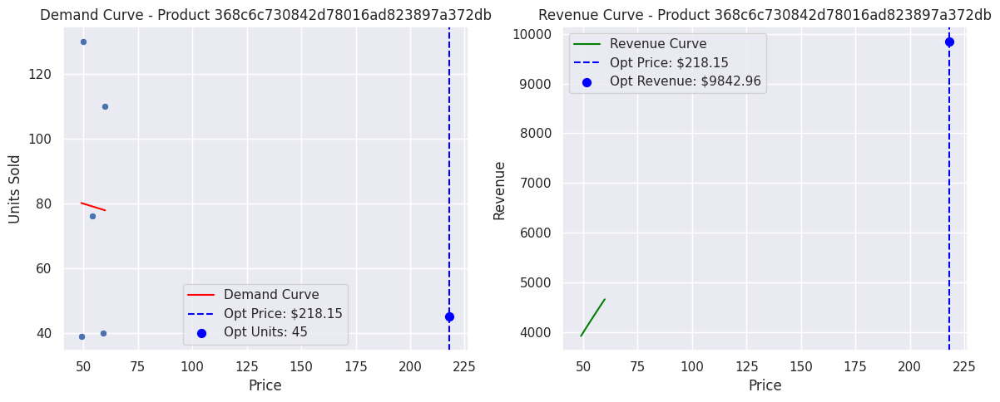


Product 53759a2ecddad2bb87a079a1f1519f73 R-squared: 0.03
Skipping 53759a2ecddad2bb87a079a1f1519f73: Non-negative slope

Product d1c427060a0f73f6b889a5c7c61f2ac4 R-squared: 0.10


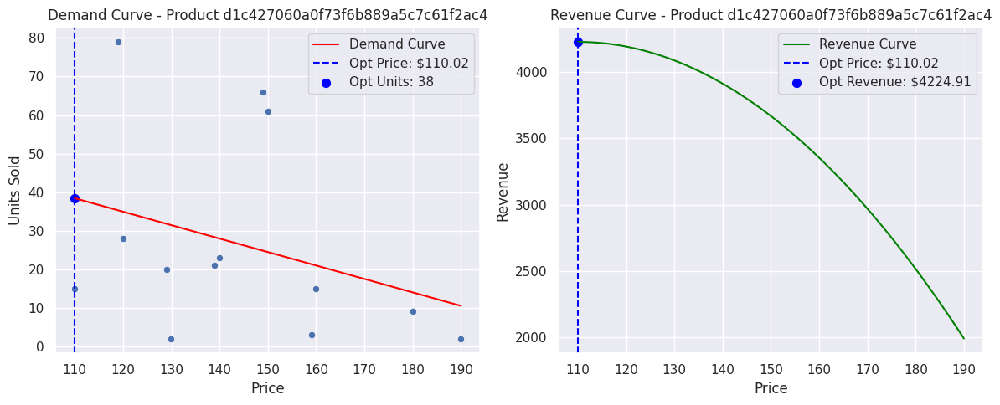


Product 53b36df67ebb7c41585e8d54d6772e08 R-squared: 0.13


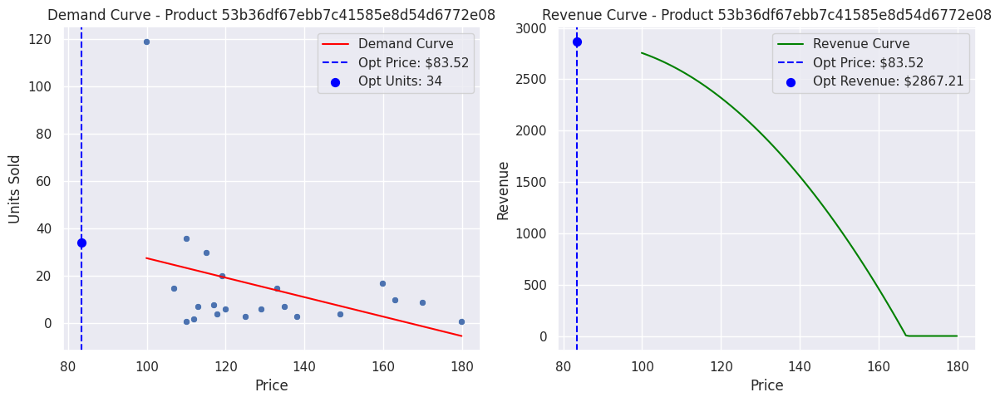


Product 154e7e31ebfa092203795c972e5804a6 R-squared: 1.00
Skipping 154e7e31ebfa092203795c972e5804a6: Non-negative slope

Product 3dd2a17168ec895c781a9191c1e95ad7 R-squared: 1.00


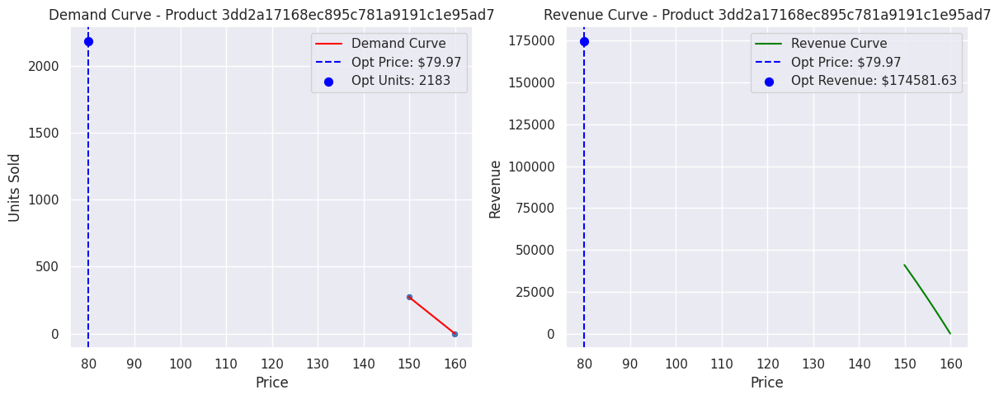


Optimization Results:
Product aca2eb7d00ea1a7b8ebd4e68314663af: Opt Price $51.23, Opt Units 414, Opt Revenue $21192.50, Opt Profit $13166.76
  Current: Units 526, Revenue $37523.70, Profit $30424.21
Product 368c6c730842d78016ad823897a372db: Opt Price $218.15, Opt Units 45, Opt Revenue $9842.96, Opt Profit $9042.38
  Current: Units 395, Revenue $21443.40, Profit $14385.00
Product d1c427060a0f73f6b889a5c7c61f2ac4: Opt Price $110.02, Opt Units 38, Opt Revenue $4224.91, Opt Profit $2581.78
  Current: Units 344, Revenue $47249.45, Profit $33050.35
Product 53b36df67ebb7c41585e8d54d6772e08: Opt Price $83.52, Opt Units 34, Opt Revenue $2867.21, Opt Profit $2475.22
  Current: Units 323, Revenue $37687.63, Profit $35409.84
Product 3dd2a17168ec895c781a9191c1e95ad7: Opt Price $79.97, Opt Units 2183, Opt Revenue $174581.63, Opt Profit $127538.53
  Current: Units 275, Revenue $41232.50, Profit $34064.97


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Load dataset
df = pd.read_csv("final_data.csv")

# Filter delivered orders
df = df[df['order_status'] == 'delivered']

# Convert timestamp
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])

# Add time columns
df['year'] = df['order_purchase_timestamp'].dt.year
df['month'] = df['order_purchase_timestamp'].dt.month
df['year_month'] = df['order_purchase_timestamp'].dt.to_period('M')

# Check NaN
print("NaN Summary:\n", df.isna().sum())

# Drop rows with NaN in product dimensions (1 row)
key_cols = ['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']
df = df.dropna(subset=key_cols)

# Fill review NaN (no NLP)
df['review_comment_title'] = df['review_comment_title'].fillna('')
df['review_comment_message'] = df['review_comment_message'].fillna('')

# Filter positive prices
df = df[df['price'] > 0]

# EDA: Top categories (for reference)
category_units = df.groupby('product_category_name_english')['order_item_id'].count().sort_values(ascending=False).head(10)
category_revenue = df.groupby('product_category_name_english')['price'].sum().sort_values(ascending=False).head(10)
print("Top Categories by Units:\n", category_units)
print("Top Categories by Revenue:\n", category_revenue)

# Top 10 products by units sold
top_products = df.groupby('product_id').agg(
    units_sold=('order_item_id', 'count'),
    total_revenue=('price', 'sum')
).sort_values('units_sold', ascending=False).head(10).index

results = {}

for prod_id in top_products:
    df_prod = df[df['product_id'] == prod_id]

    # Aggregate per price
    price_agg = df_prod.groupby('price').agg(
        units_sold=('order_item_id', 'count'),
        avg_freight=('freight_value', 'mean')
    ).reset_index()

    if len(price_agg) < 2:
        print(f"Skipping {prod_id}: Insufficient price variation")
        continue

    X = price_agg[['price']]
    y = price_agg['units_sold']

    model = LinearRegression()
    model.fit(X, y)

    r2 = r2_score(y, model.predict(X))
    print(f"\nProduct {prod_id} R-squared: {r2:.2f}")

    a = model.intercept_
    b = -model.coef_[0]

    if b <= 0:
        print(f"Skipping {prod_id}: Non-negative slope")
        continue

    opt_price = a / (2 * b)
    opt_units = max(a - b * opt_price, 0)
    opt_revenue = opt_price * opt_units
    opt_profit = (opt_price - price_agg['avg_freight'].mean()) * opt_units  # Approx profit

    current_units = y.sum()
    current_revenue = (price_agg['price'] * price_agg['units_sold']).sum()
    current_profit = current_revenue - (price_agg['avg_freight'] * price_agg['units_sold']).sum()

    results[prod_id] = {
        'opt_price': opt_price,
        'opt_units': opt_units,
        'opt_revenue': opt_revenue,
        'opt_profit': opt_profit,
        'current_units': current_units,
        'current_revenue': current_revenue,
        'current_profit': current_profit
    }

    # Plots
    plt.figure(figsize=(12, 5))

    # Demand Curve
    plt.subplot(1, 2, 1)
    sns.scatterplot(x='price', y='units_sold', data=price_agg)
    prices_plot = np.linspace(price_agg['price'].min(), price_agg['price'].max(), 100)
    units_pred = model.predict(prices_plot.reshape(-1, 1))
    plt.plot(prices_plot, units_pred, color='red', label='Demand Curve')
    plt.axvline(opt_price, color='blue', linestyle='--', label=f'Opt Price: ${opt_price:.2f}')
    plt.scatter(opt_price, opt_units, color='blue', s=50, label=f'Opt Units: {opt_units:.0f}')
    plt.title(f'Demand Curve - Product {prod_id}')
    plt.xlabel('Price')
    plt.ylabel('Units Sold')
    plt.legend()
    plt.grid(True)

    # Revenue Curve
    plt.subplot(1, 2, 2)
    revenues_plot = prices_plot * np.maximum(units_pred, 0)
    plt.plot(prices_plot, revenues_plot, color='green', label='Revenue Curve')
    plt.axvline(opt_price, color='blue', linestyle='--', label=f'Opt Price: ${opt_price:.2f}')
    plt.scatter(opt_price, opt_revenue, color='blue', s=50, label=f'Opt Revenue: ${opt_revenue:.2f}')
    plt.title(f'Revenue Curve - Product {prod_id}')
    plt.xlabel('Price')
    plt.ylabel('Revenue')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

print("\nOptimization Results:")
for prod, res in results.items():
    print(f"Product {prod}: Opt Price ${res['opt_price']:.2f}, Opt Units {res['opt_units']:.0f}, Opt Revenue ${res['opt_revenue']:.2f}, Opt Profit ${res['opt_profit']:.2f}")
    print(f"  Current: Units {res['current_units']}, Revenue ${res['current_revenue']:.2f}, Profit ${res['current_profit']:.2f}")

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
from sklearn.inspection import permutation_importance

# Step 1: Load and Clean Data
df = pd.read_csv('final_data.csv')

# Filter for delivered orders
df = df[df['order_status'] == 'delivered']

# Convert timestamp to datetime
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])

# Add year, month, year_month
df['year'] = df['order_purchase_timestamp'].dt.year
df['month'] = df['order_purchase_timestamp'].dt.month
df['year_month'] = df['order_purchase_timestamp'].dt.to_period('M')

# Step 2: EDA - Top Categories by Units and Revenue
category_units = df.groupby('product_category_name_english')['order_item_id'].count().sort_values(ascending=False)
category_revenue = df.groupby('product_category_name_english')['price'].sum().sort_values(ascending=False)

print("Top Categories by Units Sold:\n", category_units.head(10))
print("Top Categories by Revenue:\n", category_revenue.head(10))

Top Categories by Units Sold:
 product_category_name_english
bed_bath_table           11685
health_beauty             9747
sports_leisure            8736
furniture_decor           8558
computers_accessories     7927
housewares                7154
watches_gifts             6032
telephony                 4580
garden_tools              4452
auto                      4260
Name: order_item_id, dtype: int64
Top Categories by Revenue:
 product_category_name_english
health_beauty            1266992.59
watches_gifts            1207633.40
bed_bath_table           1082024.32
sports_leisure            989781.66
computers_accessories     922593.78
furniture_decor           746811.14
housewares                646232.97
cool_stuff                628528.54
auto                      594994.54
garden_tools              490451.78
Name: price, dtype: float64


In [ ]:
display(category_units)

,order_item_id
product_category_name_english,
bed_bath_table,11685
health_beauty,9747
sports_leisure,8736
furniture_decor,8558
computers_accessories,7927
...,...
arts_and_craftmanship,24
la_cuisine,15
cds_dvds_musicals,14


In [ ]:
category_units.values

array([11685,  9747,  8736,  8558,  7927,  7154,  6032,  4580,  4452,
        4260,  4161,  3888,  3495,  3096,  2789,  2557,  2114,  1998,
        1748,  1144,  1130,   937,   806,   682,   679,   623,   545,
         514,   503,   471,   375,   371,   323,   302,   289,   289,
         281,   268,   267,   266,   262,   259,   246,   241,   213,
         205,   198,   186,   145,   139,   137,   119,   101,    85,
          75,    72,    67,    59,    46,    45,    40,    40,    37,
          31,    30,    28,    24,    15,    14,     7,     2])

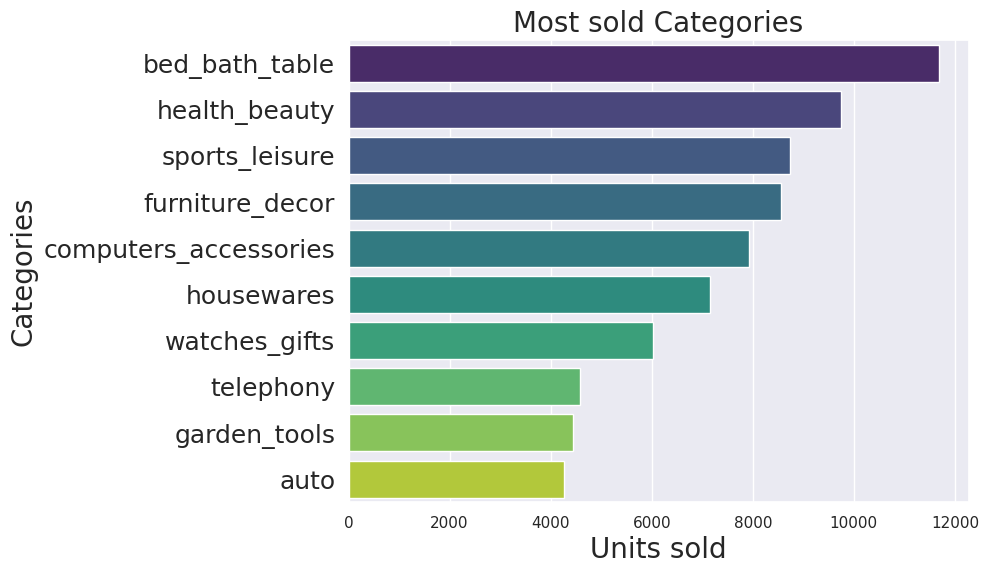

In [ ]:
plt.figure(figsize=(8, 6))
sns.barplot(x=category_units.values[0:10], y=category_units.index[0:10], palette='viridis')
plt.title('Most sold Categories', fontsize=20)
plt.xlabel('Units sold', fontsize=20)
plt.ylabel('Categories', fontsize=20)
plt.yticks(fontsize=18)
plt.show()

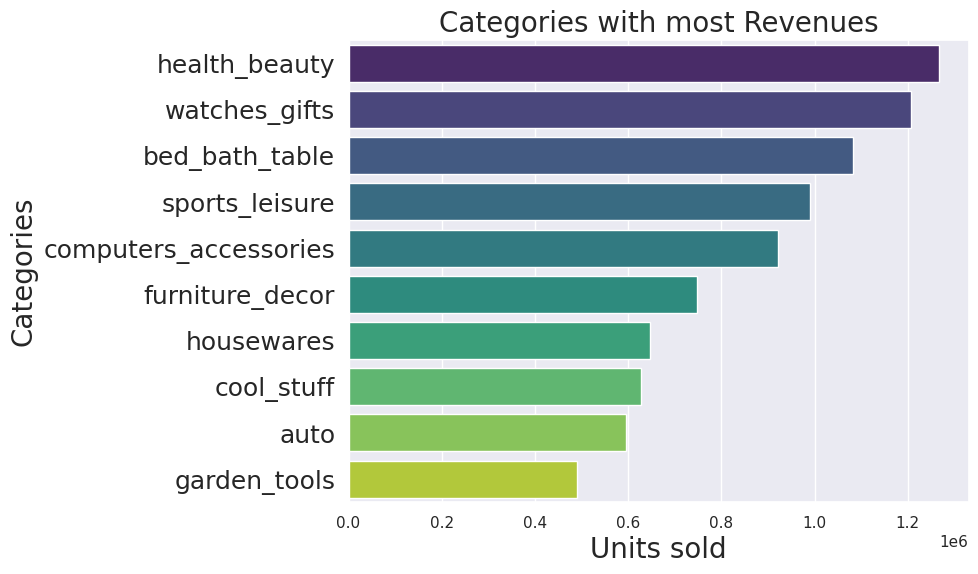

In [ ]:
plt.figure(figsize=(8, 6))
sns.barplot(x=category_revenue.values[0:10], y=category_revenue.index[0:10], palette='viridis')
plt.title('Categories with most Revenues', fontsize=20)
plt.xlabel('Units sold', fontsize=20)
plt.ylabel('Categories', fontsize=20)
plt.yticks(fontsize=18)
plt.show()

In [ ]:
len(set(df['product_category_name_english'].values))

71

Optimal Price for Max Revenue: 88.89
Optimal Demand for Max Revenue: 49220
Max Revenue: 4375165.8
Optimal Price for Max Profit: 98.9
Optimal Demand for Max Profit: 43825
Max Profit: 3181927.0700000306


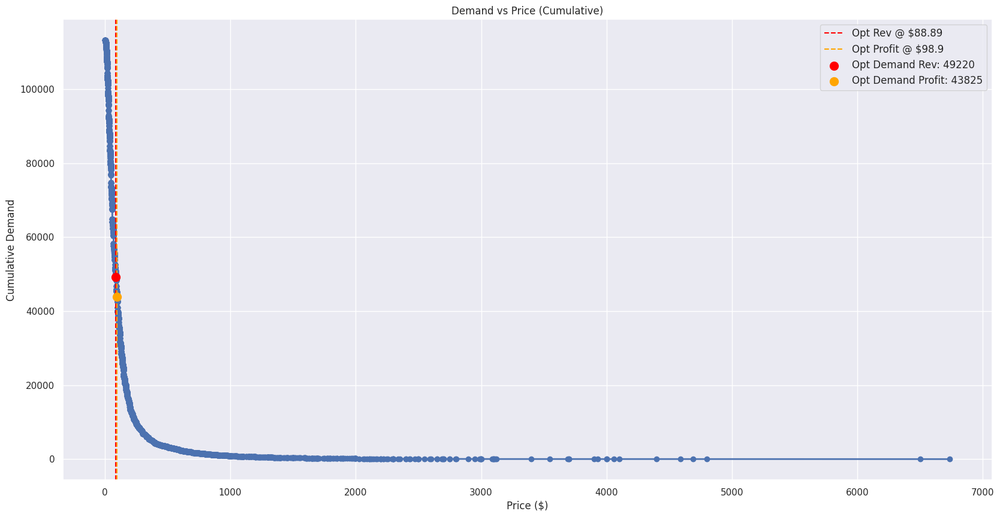

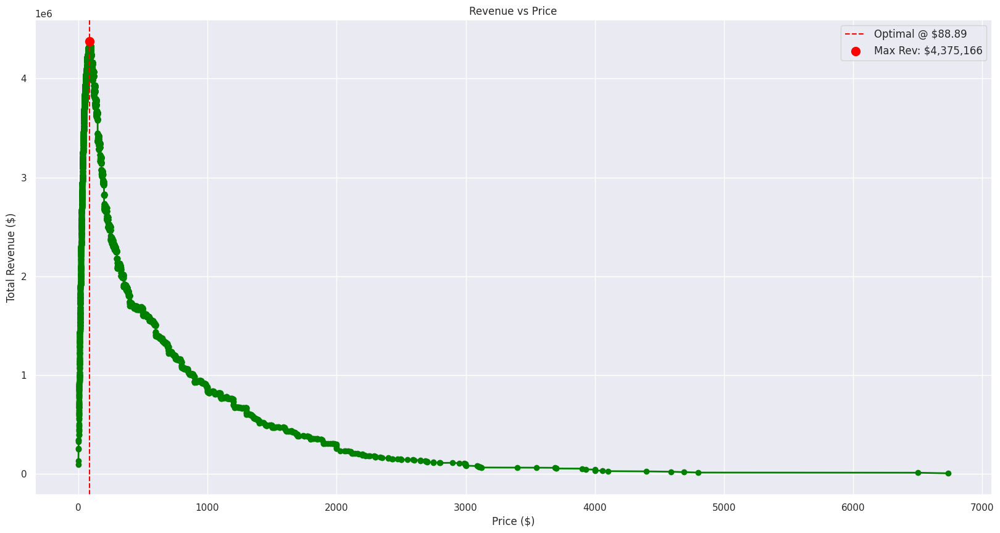

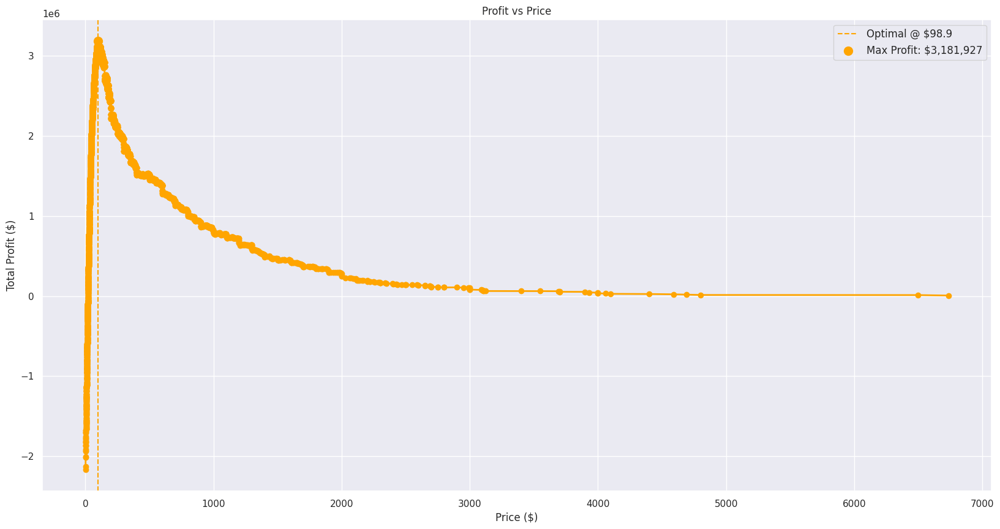

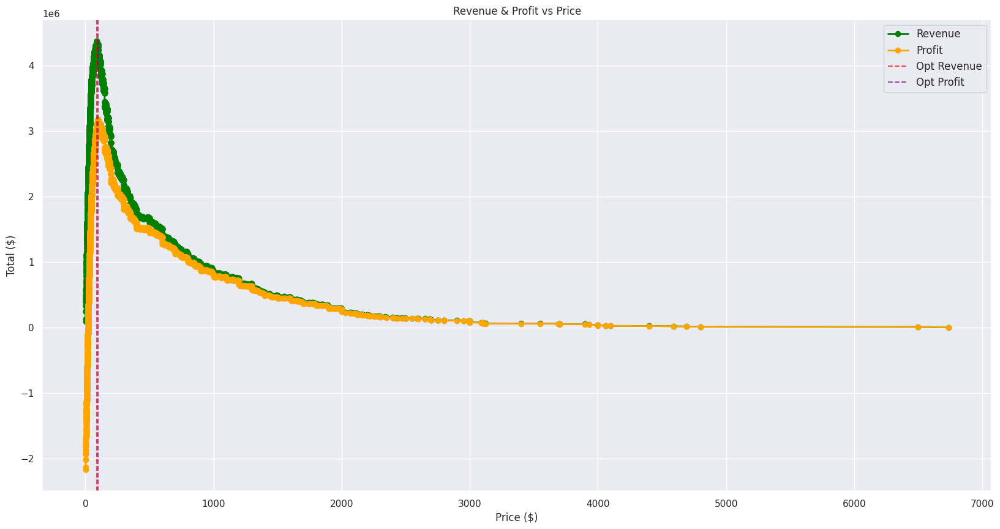

Average Price Elasticity: 25.49
Price Range with Highest Elasticity: $2999.89 (Elasticity: 47617.38)


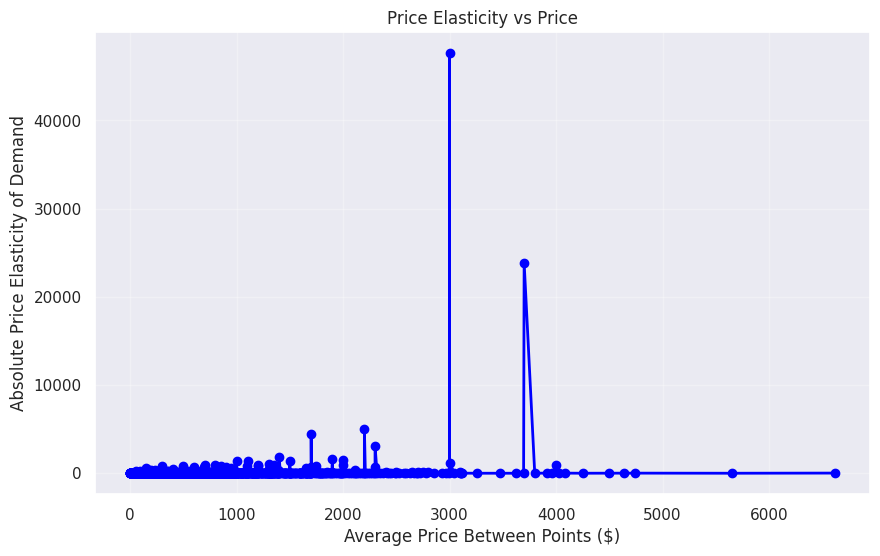

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('final_data.csv')
df = df[df['order_status'] == 'delivered']

# Sort by price descending
df = df.sort_values('price', ascending=False).reset_index(drop=True)

prices = df['price'].values
freights = df['freight_value'].values
n = len(df)

# Unique prices descending
unique_prices = np.sort(df['price'].unique())[::-1]

# Precompute cumulative demand and cumulative freight
cum_demand = np.cumsum(np.ones(n, dtype=int))
cum_freight = np.cumsum(freights)

# Map to unique prices
emp_prices = []
emp_demands = []
emp_revenues = []
emp_profits = []
j = 0  # Index in sorted df
for p in unique_prices:
    while j < n and prices[j] >= p:
        j += 1
    demand = j
    revenue = p * demand
    freight_sum = cum_freight[j-1] if j > 0 else 0
    profit = revenue - freight_sum
    emp_prices.append(p)
    emp_demands.append(demand)
    emp_revenues.append(revenue)
    emp_profits.append(profit)

# Optimal for revenue
max_rev_idx = np.argmax(emp_revenues)
opt_price_rev = emp_prices[max_rev_idx]
opt_demand_rev = emp_demands[max_rev_idx]
opt_rev = emp_revenues[max_rev_idx]

print(f"Optimal Price for Max Revenue: {opt_price_rev}")
print(f"Optimal Demand for Max Revenue: {opt_demand_rev}")
print(f"Max Revenue: {opt_rev}")

# Optimal for profit
max_profit_idx = np.argmax(emp_profits)
opt_price_profit = emp_prices[max_profit_idx]
opt_demand_profit = emp_demands[max_profit_idx]
opt_profit = emp_profits[max_profit_idx]

print(f"Optimal Price for Max Profit: {opt_price_profit}")
print(f"Optimal Demand for Max Profit: {opt_demand_profit}")
print(f"Max Profit: {opt_profit}")

# Plots: Reverse arrays to plot price ascending (standard)
plt.figure(figsize=(20, 10))

# Demand vs Price
plt.plot(emp_prices[::-1], emp_demands[::-1], 'o-', linewidth=2, markersize=6)
plt.axvline(opt_price_rev, color='red', linestyle='--', label=f'Opt Rev @ ${opt_price_rev}')
plt.axvline(opt_price_profit, color='orange', linestyle='--', label=f'Opt Profit @ ${opt_price_profit}')
plt.scatter(opt_price_rev, opt_demand_rev, color='red', s=100, zorder=5, label=f'Opt Demand Rev: {opt_demand_rev}')
plt.scatter(opt_price_profit, opt_demand_profit, color='orange', s=100, zorder=5, label=f'Opt Demand Profit: {opt_demand_profit}')
plt.xlabel('Price ($)')
plt.ylabel('Cumulative Demand')
plt.title('Demand vs Price (Cumulative)')
plt.legend(fontsize=12)
plt.show()

# Revenue vs Price
plt.figure(figsize=(20, 10))
plt.plot(emp_prices[::-1], emp_revenues[::-1], 'o-', color='green', linewidth=2, markersize=6)
plt.axvline(opt_price_rev, color='red', linestyle='--', label=f'Optimal @ ${opt_price_rev}')
plt.scatter(opt_price_rev, opt_rev, color='red', s=100, zorder=5, label=f'Max Rev: ${opt_rev:,.0f}')
plt.xlabel('Price ($)')
plt.ylabel('Total Revenue ($)')
plt.title('Revenue vs Price')
plt.legend(fontsize=12)
plt.show()

# Profit vs Price
plt.figure(figsize=(20, 10))
plt.plot(emp_prices[::-1], emp_profits[::-1], 'o-', color='orange', linewidth=2, markersize=6)
plt.axvline(opt_price_profit, color='orange', linestyle='--', label=f'Optimal @ ${opt_price_profit}')
plt.scatter(opt_price_profit, opt_profit, color='orange', s=100, zorder=5, label=f'Max Profit: ${opt_profit:,.0f}')
plt.xlabel('Price ($)')
plt.ylabel('Total Profit ($)')
plt.title('Profit vs Price')
plt.legend(fontsize=12)
plt.show()

# Combined Revenue & Profit
plt.figure(figsize=(20, 10))
plt.plot(emp_prices[::-1], emp_revenues[::-1], 'o-', color='green', label='Revenue', linewidth=2)
plt.plot(emp_prices[::-1], emp_profits[::-1], 'o-', color='orange', label='Profit', linewidth=2)
plt.axvline(opt_price_rev, color='red', linestyle='--', alpha=0.7, label='Opt Revenue')
plt.axvline(opt_price_profit, color='purple', linestyle='--', alpha=0.7, label='Opt Profit')
plt.xlabel('Price ($)')
plt.ylabel('Total ($)')
plt.title('Revenue & Profit vs Price')
plt.legend(fontsize=12)
plt.show()

# Price Sensitivity / Elasticity Analysis
# Compute point elasticity between consecutive points (ascending order)
asc_prices = emp_prices[::-1]
asc_demands = emp_demands[::-1]

deltas_p = np.diff(asc_prices)
deltas_q = np.diff(asc_demands)

p_avg = (np.array(asc_prices[:-1]) + np.array(asc_prices[1:])) / 2
q_avg = (np.array(asc_demands[:-1]) + np.array(asc_demands[1:])) / 2

elasticities = (deltas_q / q_avg) / (deltas_p / p_avg)
elasticities = np.abs(elasticities)  # Absolute for magnitude

# Filter valid (non-zero, non-inf)
valid_mask = (deltas_p != 0) & (q_avg != 0) & np.isfinite(elasticities)
elasticities = elasticities[valid_mask]
p_avg_valid = p_avg[valid_mask]

print(f"Average Price Elasticity: {np.mean(elasticities):.2f}")
print(f"Price Range with Highest Elasticity: ${p_avg_valid[np.argmax(elasticities)]:.2f} (Elasticity: {np.max(elasticities):.2f})")

# Plot Elasticity vs Price Avg
plt.figure(figsize=(10, 6))
plt.plot(p_avg_valid, elasticities, 'o-', color='blue', linewidth=2)
plt.xlabel('Average Price Between Points ($)')
plt.ylabel('Absolute Price Elasticity of Demand')
plt.title('Price Elasticity vs Price')
plt.grid(True, alpha=0.3)
plt.show()

Optimal Price for Max Revenue: 88.89
Optimal Demand for Max Revenue: 49220
Max Revenue: 4375165.8
Optimal Price for Max Profit: 98.9
Optimal Demand for Max Profit: 43825
Max Profit: 3181927.0700000306


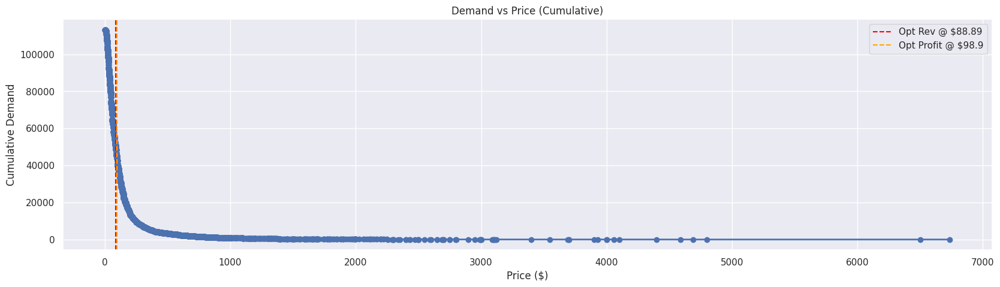

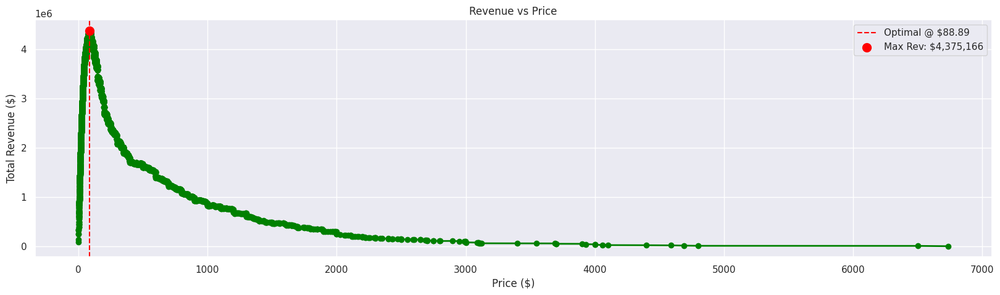

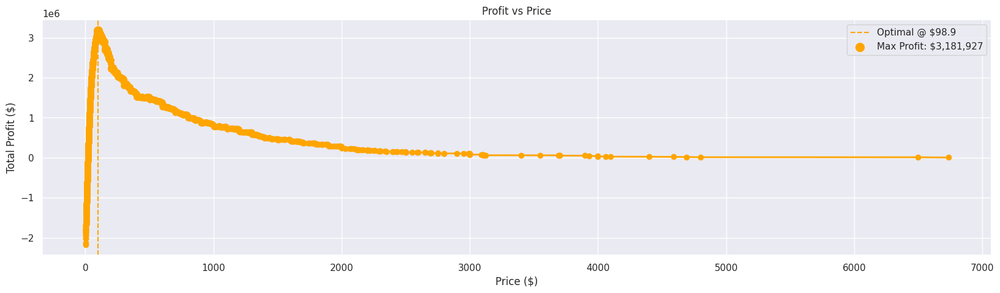

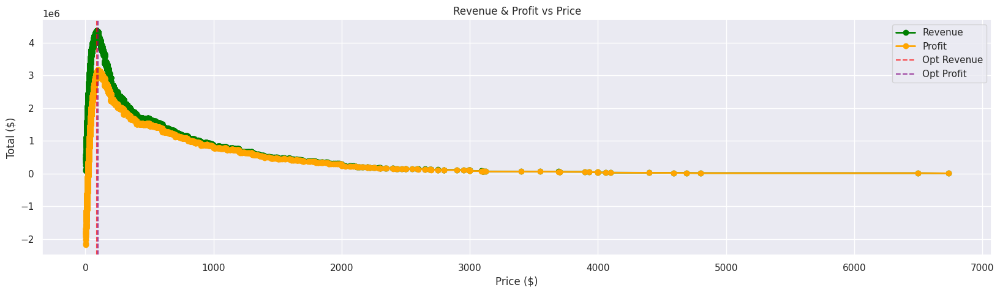

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('final_data.csv')
df = df[df['order_status'] == 'delivered']

# Sort by price descending
df = df.sort_values('price', ascending=False).reset_index(drop=True)

prices = df['price'].values
freights = df['freight_value'].values
n = len(df)

# Unique prices descending
unique_prices = np.sort(df['price'].unique())[::-1]

# Precompute cumulative demand and cumulative freight
cum_demand = np.cumsum(np.ones(n, dtype=int))
cum_freight = np.cumsum(freights)

# Map to unique prices
emp_prices = []
emp_demands = []
emp_revenues = []
emp_profits = []
j = 0  # Index in sorted df
for p in unique_prices:
    while j < n and prices[j] >= p:
        j += 1
    demand = j
    revenue = p * demand
    freight_sum = cum_freight[j-1] if j > 0 else 0
    profit = revenue - freight_sum
    emp_prices.append(p)
    emp_demands.append(demand)
    emp_revenues.append(revenue)
    emp_profits.append(profit)

# Optimal for revenue
max_rev_idx = np.argmax(emp_revenues)
opt_price_rev = emp_prices[max_rev_idx]
opt_demand_rev = emp_demands[max_rev_idx]
opt_rev = emp_revenues[max_rev_idx]

print(f"Optimal Price for Max Revenue: {opt_price_rev}")
print(f"Optimal Demand for Max Revenue: {opt_demand_rev}")
print(f"Max Revenue: {opt_rev}")

# Optimal for profit
max_profit_idx = np.argmax(emp_profits)
opt_price_profit = emp_prices[max_profit_idx]
opt_demand_profit = emp_demands[max_profit_idx]
opt_profit = emp_profits[max_profit_idx]

print(f"Optimal Price for Max Profit: {opt_price_profit}")
print(f"Optimal Demand for Max Profit: {opt_demand_profit}")
print(f"Max Profit: {opt_profit}")

# Plots: Reverse arrays to plot price ascending (standard)
plt.figure(figsize=(20, 5))

# Demand vs Price
plt.plot(emp_prices[::-1], emp_demands[::-1], 'o-', linewidth=2, markersize=6)
plt.axvline(opt_price_rev, color='red', linestyle='--', label=f'Opt Rev @ ${opt_price_rev}')
plt.axvline(opt_price_profit, color='orange', linestyle='--', label=f'Opt Profit @ ${opt_price_profit}')
plt.xlabel('Price ($)')
plt.ylabel('Cumulative Demand')
plt.title('Demand vs Price (Cumulative)')
plt.legend()
plt.show()

# Revenue vs Price
plt.figure(figsize=(20, 5))
plt.plot(emp_prices[::-1], emp_revenues[::-1], 'o-', color='green', linewidth=2, markersize=6)
plt.axvline(opt_price_rev, color='red', linestyle='--', label=f'Optimal @ ${opt_price_rev}')
plt.scatter(opt_price_rev, opt_rev, color='red', s=100, zorder=5, label=f'Max Rev: ${opt_rev:,.0f}')
plt.xlabel('Price ($)')
plt.ylabel('Total Revenue ($)')
plt.title('Revenue vs Price')
plt.legend()
plt.show()

# Profit vs Price
plt.figure(figsize=(20, 5))
plt.plot(emp_prices[::-1], emp_profits[::-1], 'o-', color='orange', linewidth=2, markersize=6)
plt.axvline(opt_price_profit, color='orange', linestyle='--', label=f'Optimal @ ${opt_price_profit}')
plt.scatter(opt_price_profit, opt_profit, color='orange', s=100, zorder=5, label=f'Max Profit: ${opt_profit:,.0f}')
plt.xlabel('Price ($)')
plt.ylabel('Total Profit ($)')
plt.title('Profit vs Price')
plt.legend()
plt.show()

# Combined Revenue & Profit
plt.figure(figsize=(20, 5))
plt.plot(emp_prices[::-1], emp_revenues[::-1], 'o-', color='green', label='Revenue', linewidth=2)
plt.plot(emp_prices[::-1], emp_profits[::-1], 'o-', color='orange', label='Profit', linewidth=2)
plt.axvline(opt_price_rev, color='red', linestyle='--', alpha=0.7, label='Opt Revenue')
plt.axvline(opt_price_profit, color='purple', linestyle='--', alpha=0.7, label='Opt Profit')
plt.xlabel('Price ($)')
plt.ylabel('Total ($)')
plt.title('Revenue & Profit vs Price')
plt.legend()
plt.show()


Category: health_beauty
Optimal Price: 84.9
Optimal Demand: 4650
Optimal Revenue: 394785.0


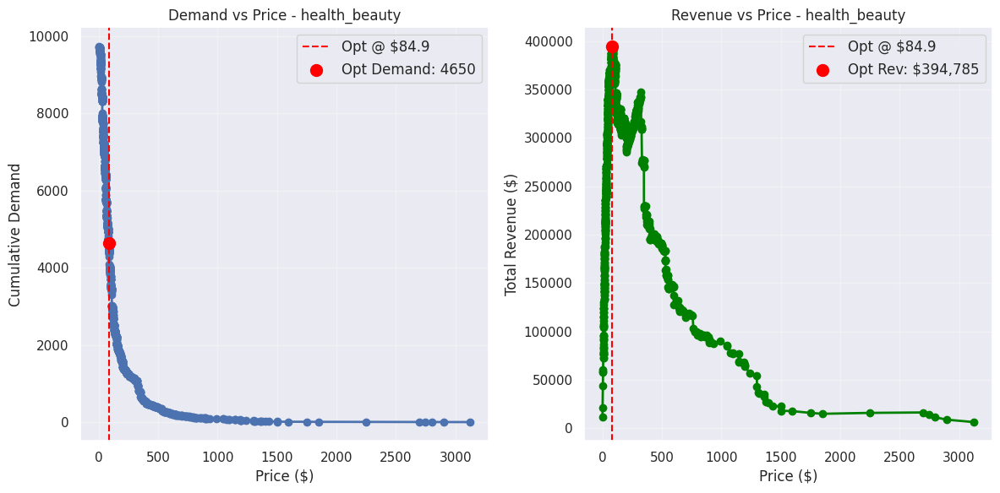


Category: watches_gifts
Optimal Price: 144.0
Optimal Demand: 2773
Optimal Revenue: 399312.0


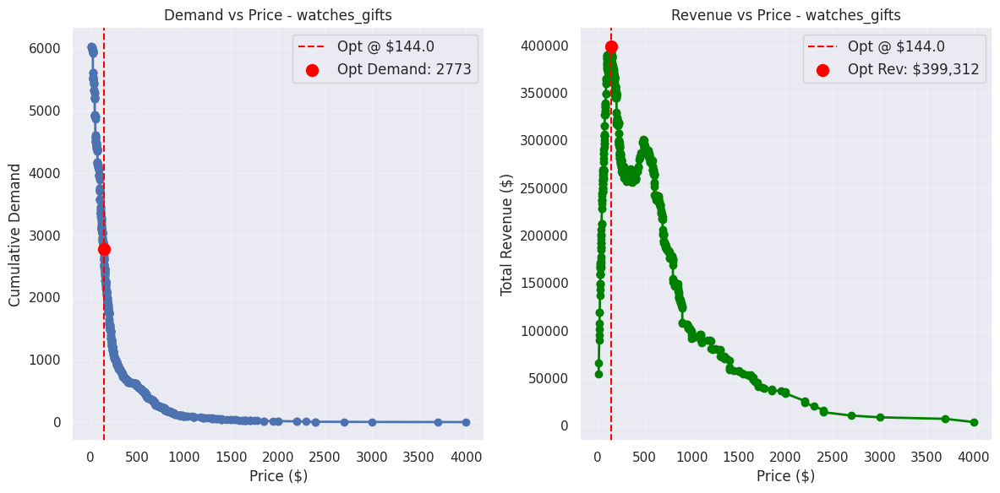


Category: bed_bath_table
Optimal Price: 68.9
Optimal Demand: 6794
Optimal Revenue: 468106.60000000003


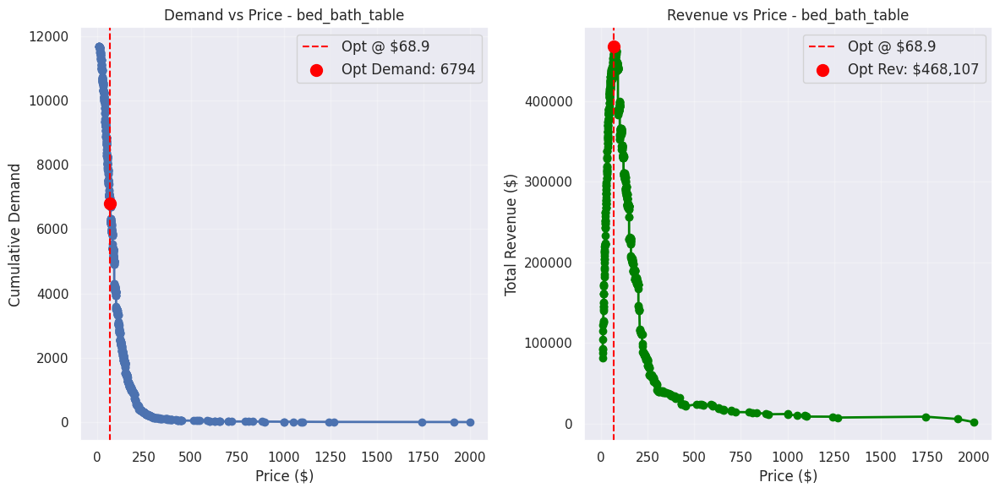


Category: sports_leisure
Optimal Price: 98.89
Optimal Demand: 3700
Optimal Revenue: 365893.0


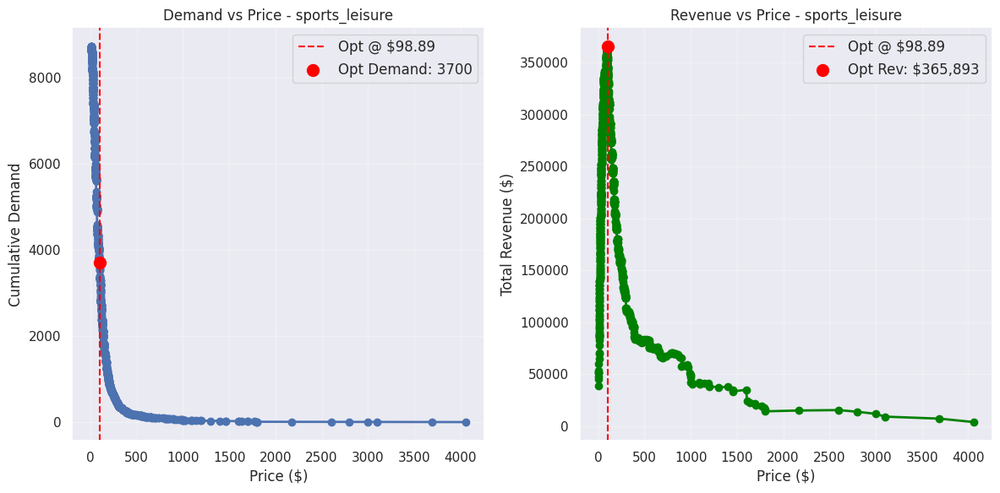


Category: computers_accessories
Optimal Price: 74.89
Optimal Demand: 4449
Optimal Revenue: 333185.61


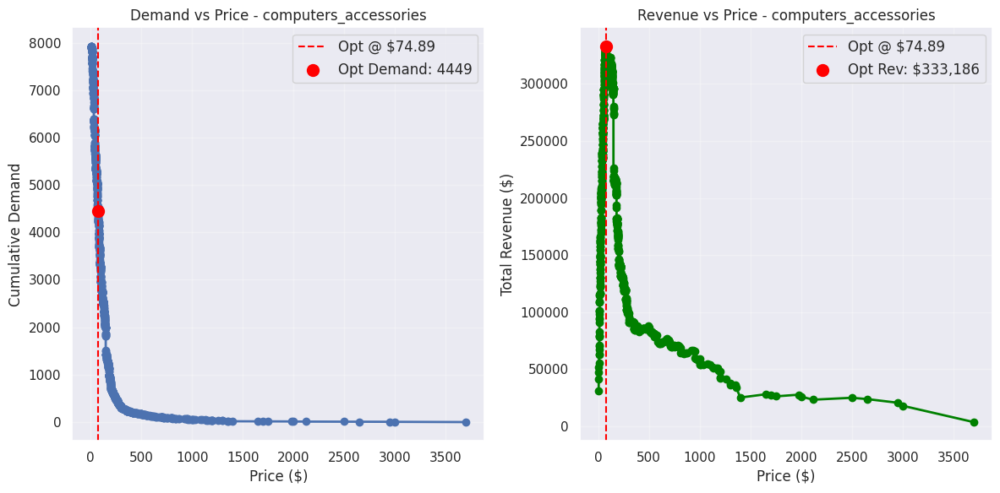


Category: furniture_decor
Optimal Price: 59.0
Optimal Demand: 4884
Optimal Revenue: 288156.0


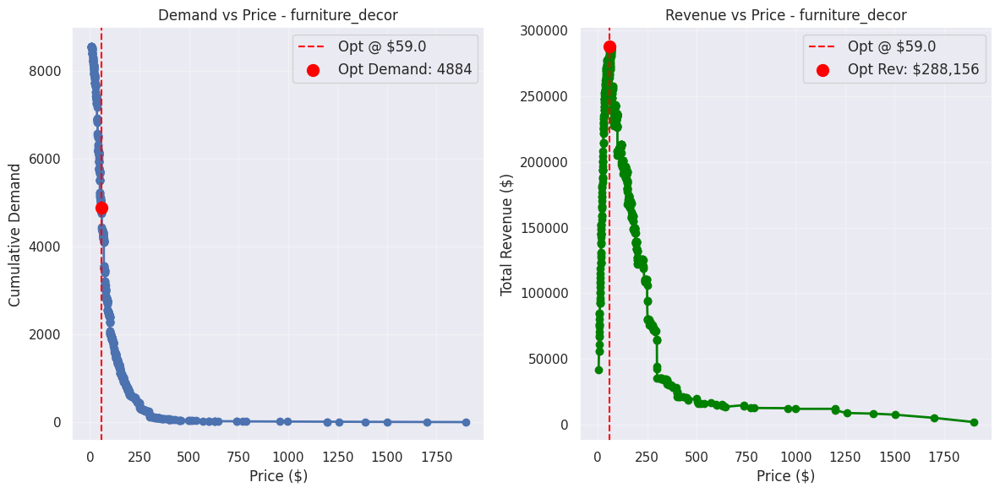


Category: housewares
Optimal Price: 58.9
Optimal Demand: 3702
Optimal Revenue: 218047.8


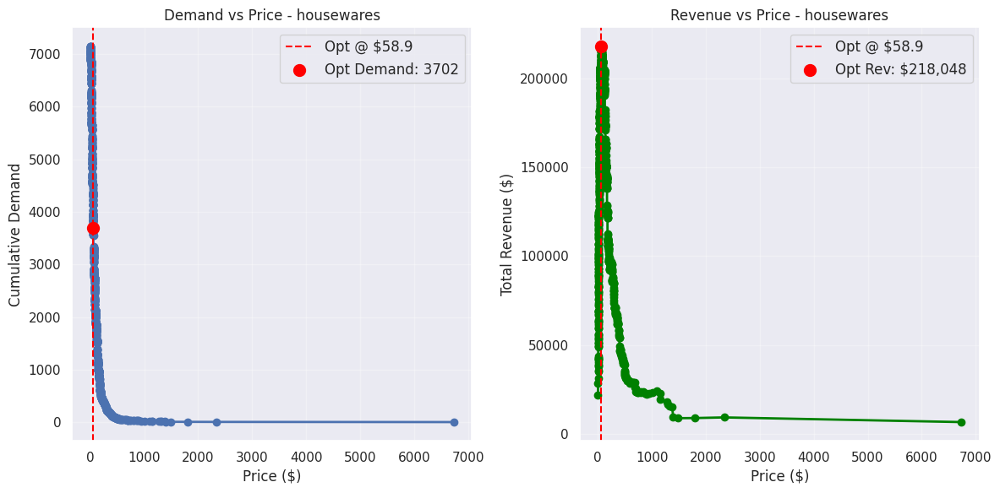


Category: cool_stuff
Optimal Price: 129.8
Optimal Demand: 1942
Optimal Revenue: 252071.60000000003


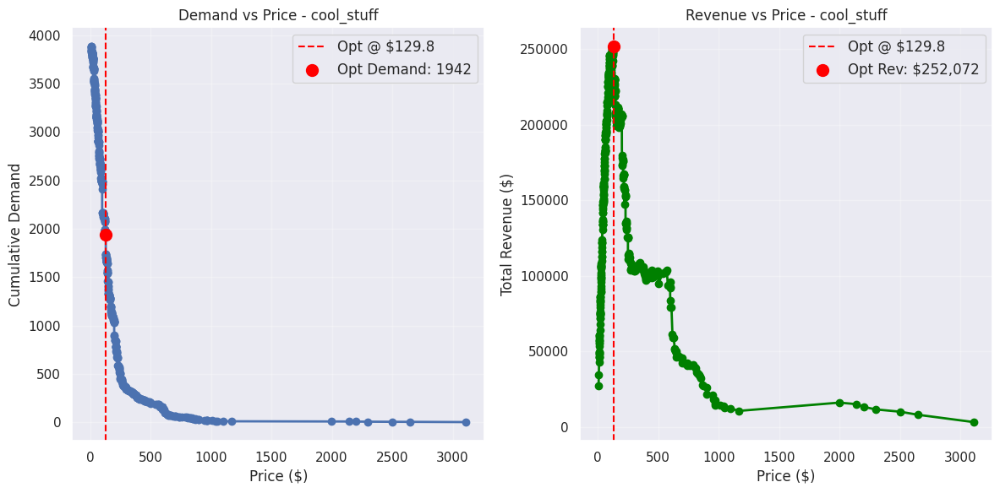


Category: auto
Optimal Price: 108.9
Optimal Demand: 1810
Optimal Revenue: 197109.0


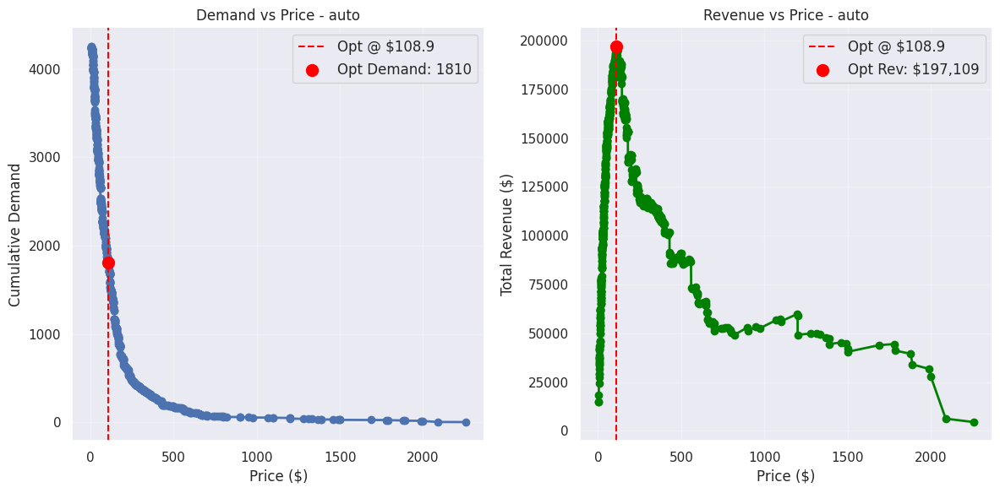


Category: garden_tools
Optimal Price: 49.0
Optimal Demand: 3804
Optimal Revenue: 186396.0


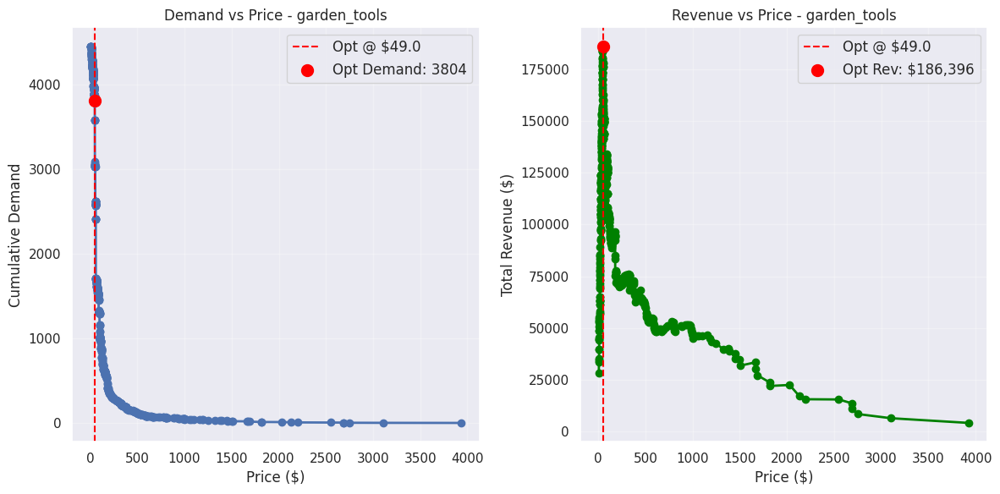

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('final_data.csv')
df = df[df['order_status'] == 'delivered']

# Get all unique categories, but limit to top 10 by revenue for practicality
category_revenue = df.groupby('product_category_name_english')['price'].sum().sort_values(ascending=False)
top_categories = category_revenue.head(10).index.tolist()

results = {}

for cat in top_categories:
    df_cat = df[df['product_category_name_english'] == cat].copy()

    # Sort by price descending
    df_cat = df_cat.sort_values('price', ascending=False).reset_index(drop=True)

    prices = df_cat['price'].values
    n = len(df_cat)

    # Unique prices descending
    unique_prices = np.sort(df_cat['price'].unique())[::-1]

    # Map to unique prices
    emp_prices = []
    emp_demands = []
    emp_revenues = []
    j = 0  # Index in sorted df
    for p in unique_prices:
        while j < n and prices[j] >= p:
            j += 1
        demand = j
        revenue = p * demand
        emp_prices.append(p)
        emp_demands.append(demand)
        emp_revenues.append(revenue)

    # Optimal for revenue
    max_rev_idx = np.argmax(emp_revenues)
    opt_price_rev = emp_prices[max_rev_idx]
    opt_demand_rev = emp_demands[max_rev_idx]
    opt_rev = emp_revenues[max_rev_idx]

    results[cat] = {
        'optimal_price': opt_price_rev,
        'optimal_demand': opt_demand_rev,
        'optimal_revenue': opt_rev
    }

    print(f"\nCategory: {cat}")
    print(f"Optimal Price: {opt_price_rev}")
    print(f"Optimal Demand: {opt_demand_rev}")
    print(f"Optimal Revenue: {opt_rev}")

    # Plots: Reverse arrays to plot price ascending
    asc_prices = emp_prices[::-1]
    asc_demands = emp_demands[::-1]
    asc_revenues = emp_revenues[::-1]

    plt.figure(figsize=(12, 6))

    # Demand vs Price
    plt.subplot(1, 2, 1)
    plt.plot(asc_prices, asc_demands, 'o-', linewidth=2, markersize=6)
    plt.axvline(opt_price_rev, color='red', linestyle='--', label=f'Opt @ ${opt_price_rev}')
    plt.scatter(opt_price_rev, opt_demand_rev, color='red', s=100, zorder=5, label=f'Opt Demand: {opt_demand_rev}')
    plt.xlabel('Price ($)')
    plt.ylabel('Cumulative Demand')
    plt.title(f'Demand vs Price - {cat}')
    plt.legend(fontsize=12)
    plt.grid(True, alpha=0.3)

    # Revenue vs Price
    plt.subplot(1, 2, 2)
    plt.plot(asc_prices, asc_revenues, 'o-', color='green', linewidth=2, markersize=6)
    plt.axvline(opt_price_rev, color='red', linestyle='--', label=f'Opt @ ${opt_price_rev}')
    plt.scatter(opt_price_rev, opt_rev, color='red', s=100, zorder=5, label=f'Opt Rev: ${opt_rev:,.0f}')
    plt.xlabel('Price ($)')
    plt.ylabel('Total Revenue ($)')
    plt.title(f'Revenue vs Price - {cat}')
    plt.legend(fontsize=12)
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv('final_data.csv')
df = df[df['order_status'] == 'delivered']

# Get all unique categories
unique_categories = df['product_category_name_english'].unique()

total_opt_revenue = 0.0

for cat in unique_categories:
    df_cat = df[df['product_category_name_english'] == cat].copy()

    # Sort by price descending
    df_cat = df_cat.sort_values('price', ascending=False).reset_index(drop=True)

    prices = df_cat['price'].values
    n = len(df_cat)

    # Unique prices descending
    unique_prices = np.sort(df_cat['price'].unique())[::-1]

    # Map to unique prices
    emp_prices = []
    emp_demands = []
    emp_revenues = []
    j = 0  # Index in sorted df
    for p in unique_prices:
        while j < n and prices[j] >= p:
            j += 1
        demand = j
        revenue = p * demand
        emp_prices.append(p)
        emp_demands.append(demand)
        emp_revenues.append(revenue)

    # Optimal for revenue
    if emp_revenues:
        max_rev_idx = np.argmax(emp_revenues)
        opt_rev = emp_revenues[max_rev_idx]
        total_opt_revenue += opt_rev

print(f"Sum of Optimal Revenues for All Categories: {total_opt_revenue}")

Sum of Optimal Revenues for All Categories: 5064744.399999999


Top Categories by Units Sold:
 product_category_name_english
bed_bath_table           11685
health_beauty             9747
sports_leisure            8736
furniture_decor           8558
computers_accessories     7927
housewares                7154
watches_gifts             6032
telephony                 4580
garden_tools              4452
auto                      4260
Name: order_item_id, dtype: int64
Top Categories by Revenue:
 product_category_name_english
health_beauty            1266992.59
watches_gifts            1207633.40
bed_bath_table           1082024.32
sports_leisure            989781.66
computers_accessories     922593.78
furniture_decor           746811.14
housewares                646232.97
cool_stuff                628528.54
auto                      594994.54
garden_tools              490451.78
Name: price, dtype: float64
Top Product ID: 53b36df67ebb7c41585e8d54d6772e08
Top Seller ID: 7d13fca15225358621be4086e1eb0964
Aggregated Data:
     price  units_sold  avg_freight

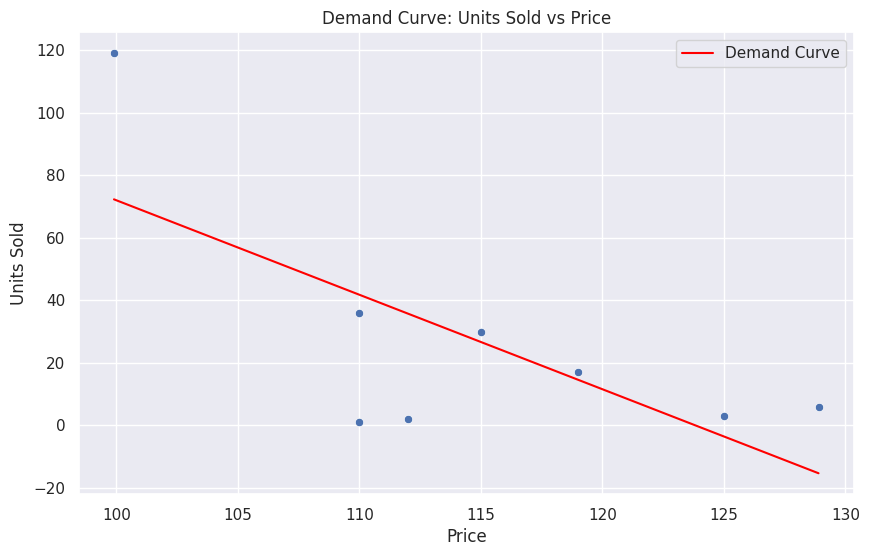

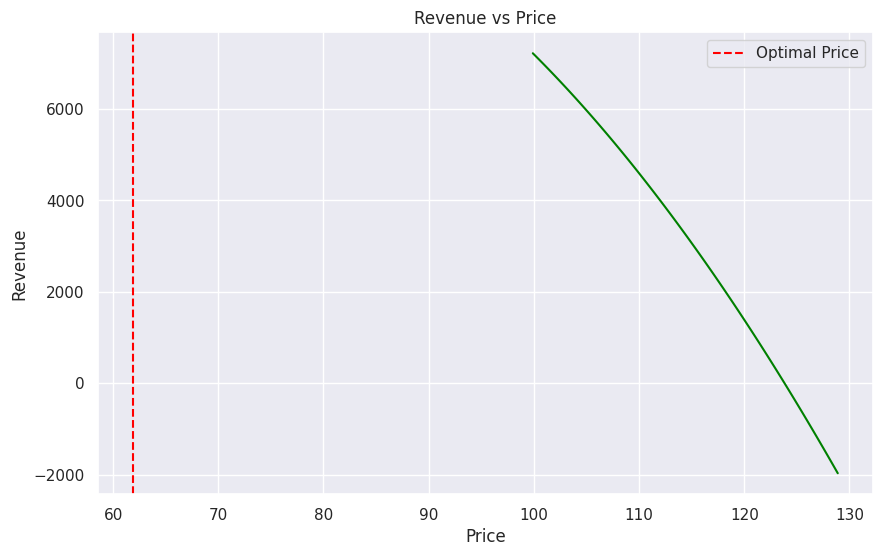

Lasso Coefficients: {'price': np.float64(-9.858824522976217), 'avg_freight': np.float64(-30.38905906529353), 'avg_review': np.float64(-2.8217616157490446), 'avg_photos': np.float64(0.0)}
MSE: 3302.6403176487706


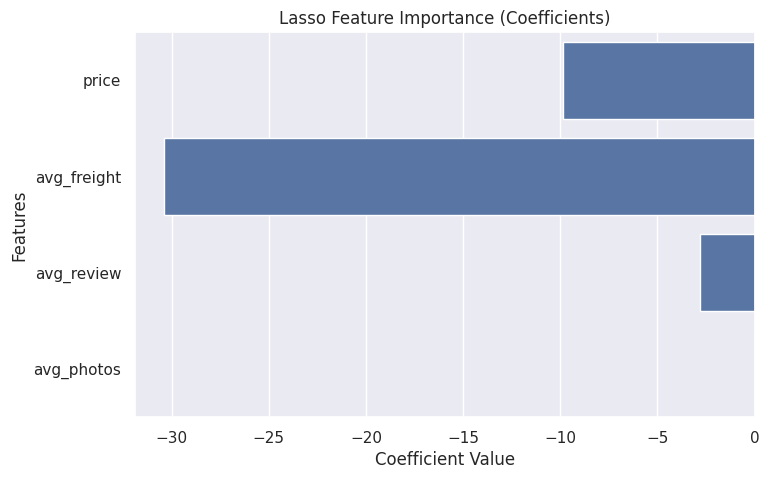

RF Feature Importances: {'price': np.float64(0.3847155306930907), 'avg_freight': np.float64(0.5393396934088277), 'avg_review': np.float64(0.07594477589808152), 'avg_photos': np.float64(0.0)}


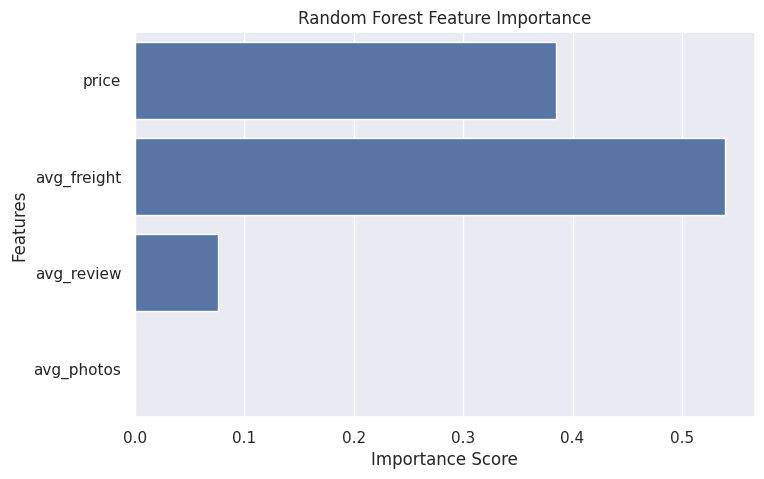

Permutation Importances: {'price': np.float64(-1.0206255468750007), 'avg_freight': np.float64(-4.235799609375001), 'avg_review': np.float64(0.25426874999999854), 'avg_photos': np.float64(0.0)}


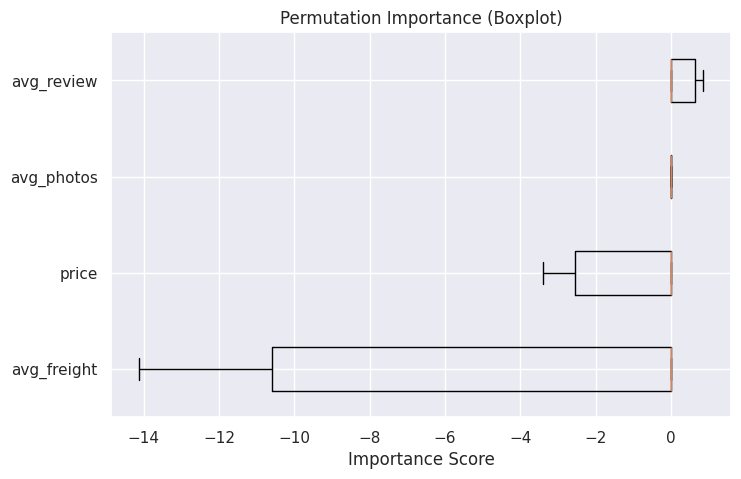

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
from sklearn.inspection import permutation_importance

# Step 1: Load and Clean Data
df = pd.read_csv('final_data.csv')

# Filter for delivered orders
df = df[df['order_status'] == 'delivered']

# Convert timestamp to datetime
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])

# Add year, month, year_month
df['year'] = df['order_purchase_timestamp'].dt.year
df['month'] = df['order_purchase_timestamp'].dt.month
df['year_month'] = df['order_purchase_timestamp'].dt.to_period('M')

# Step 2: EDA - Top Categories by Units and Revenue
category_units = df.groupby('product_category_name_english')['order_item_id'].count().sort_values(ascending=False)
category_revenue = df.groupby('product_category_name_english')['price'].sum().sort_values(ascending=False)

print("Top Categories by Units Sold:\n", category_units.head(10))
print("Top Categories by Revenue:\n", category_revenue.head(10))

# Select category: watches_gifts (top revenue generator with variation)
category = 'watches_gifts'
df_cat = df[df['product_category_name_english'] == category]

# Top product by units sold
top_product = df_cat['product_id'].value_counts().idxmax()
print("Top Product ID:", top_product)

df_prod = df_cat[df_cat['product_id'] == top_product]

# Top seller for this product
top_seller = df_prod['seller_id'].value_counts().idxmax()
print("Top Seller ID:", top_seller)

df_prod_seller = df_prod[df_prod['seller_id'] == top_seller]

# Aggregate units sold per unique price point
price_agg = df_prod_seller.groupby('price').agg(
    units_sold=('order_item_id', 'count'),
    avg_freight=('freight_value', 'mean'),
    avg_review=('review_score', 'mean'),
    avg_photos=('product_photos_qty', 'mean')
).reset_index()

print("Aggregated Data:\n", price_agg)

# Step 3: Simple Demand Model (Units ~ Price)
X_simple = price_agg[['price']]
y = price_agg['units_sold']

model_simple = LinearRegression()
model_simple.fit(X_simple, y)

print("Simple Model: units_sold = {:.2f} - {:.2f} * price".format(model_simple.intercept_, -model_simple.coef_[0]))
print("R-squared:", model_simple.score(X_simple, y))

# Optimization
a = model_simple.intercept_
b = -model_simple.coef_[0]
optimal_price = a / (2 * b)
optimal_units = a - b * optimal_price
optimal_revenue = optimal_price * optimal_units

print("Optimal Price: ${:.2f}".format(optimal_price))
print("Predicted Units at Optimal: {:.2f}".format(optimal_units))
print("Max Revenue per Period: ${:.2f}".format(optimal_revenue))

# Current totals
current_units = df_prod_seller['order_item_id'].sum()
current_revenue = (df_prod_seller['price'] * df_prod_seller['order_item_id']).sum()
current_avg_price = df_prod_seller['price'].mean()

# Assuming number of price points as 'periods'
num_periods = len(price_agg)
predicted_total_revenue = optimal_revenue * num_periods
margin_increase = (predicted_total_revenue - current_revenue) / current_revenue * 100

print("Margin Increase: {:.1f}%".format(margin_increase))

# Plot Demand Curve
plt.figure(figsize=(10, 6))
sns.scatterplot(x='price', y='units_sold', data=price_agg)
prices = np.linspace(price_agg['price'].min(), price_agg['price'].max(), 100)
units_pred = model_simple.predict(prices.reshape(-1, 1))
plt.plot(prices, units_pred, color='red', label='Demand Curve')
plt.title('Demand Curve: Units Sold vs Price')
plt.xlabel('Price')
plt.ylabel('Units Sold')
plt.legend()
plt.show()

# Plot Revenue Curve
revenues = prices * (model_simple.predict(prices.reshape(-1, 1)))
plt.figure(figsize=(10, 6))
plt.plot(prices, revenues, color='green')
plt.axvline(optimal_price, color='red', linestyle='--', label='Optimal Price')
plt.title('Revenue vs Price')
plt.xlabel('Price')
plt.ylabel('Revenue')
plt.legend()
plt.show()

# Step 4: Multivariate Model for Feature Importance
# Features: price, freight, review, photos (others are constant for product)
features = ['price', 'avg_freight', 'avg_review', 'avg_photos']
X = price_agg[features]
y = price_agg['units_sold']

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train-test split (small data, but for demo)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Lasso Regression for Feature Importance
lasso = Lasso(alpha=0.1)  # Adjust alpha for regularization
lasso.fit(X_train, y_train)

print("Lasso Coefficients:", dict(zip(features, lasso.coef_)))
print("MSE:", mean_squared_error(y_test, lasso.predict(X_test)))

# Plot Lasso Feature Importance
plt.figure(figsize=(8, 5))
sns.barplot(x=lasso.coef_, y=features)
plt.title('Lasso Feature Importance (Coefficients)')
plt.xlabel('Coefficient Value')
plt.ylabel('Features')
plt.show()

# Other Way 1: Random Forest Feature Importance
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

print("RF Feature Importances:", dict(zip(features, rf.feature_importances_)))

# Plot RF Importance
plt.figure(figsize=(8, 5))
sns.barplot(x=rf.feature_importances_, y=features)
plt.title('Random Forest Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

# Other Way 2: Permutation Importance (using RF model)
perm_importance = permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=42)

print("Permutation Importances:", dict(zip(features, perm_importance.importances_mean)))

# Plot Permutation Importance
sorted_idx = perm_importance.importances_mean.argsort()
plt.figure(figsize=(8, 5))
plt.boxplot(perm_importance.importances[sorted_idx].T, vert=False, labels=np.array(features)[sorted_idx])
plt.title('Permutation Importance (Boxplot)')
plt.xlabel('Importance Score')
plt.show()

Top Categories by Units Sold:
 product_category_name_english
bed_bath_table           11685
health_beauty             9747
sports_leisure            8736
furniture_decor           8558
computers_accessories     7927
housewares                7154
watches_gifts             6032
telephony                 4580
garden_tools              4452
auto                      4260
Name: order_item_id, dtype: int64
Top Categories by Revenue:
 product_category_name_english
health_beauty            1266992.59
watches_gifts            1207633.40
bed_bath_table           1082024.32
sports_leisure            989781.66
computers_accessories     922593.78
furniture_decor           746811.14
housewares                646232.97
cool_stuff                628528.54
auto                      594994.54
garden_tools              490451.78
Name: price, dtype: float64
Top Product ID: 53b36df67ebb7c41585e8d54d6772e08
Top Seller ID: 7d13fca15225358621be4086e1eb0964
Aggregated Data:
     price  units_sold  avg_freight

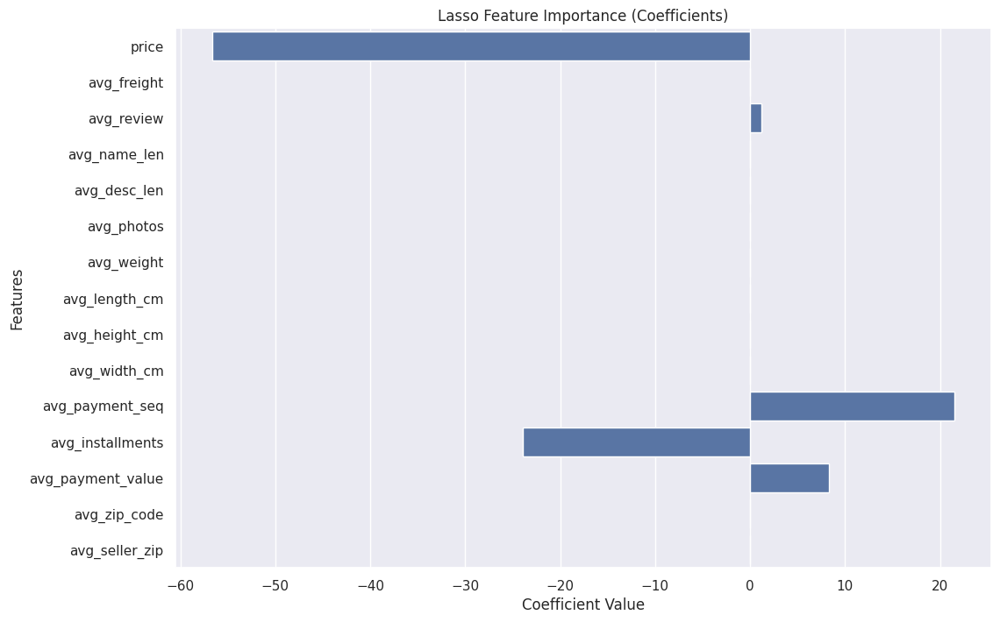

RF Feature Importances: {'price': np.float64(0.32723140357635383), 'avg_freight': np.float64(0.379240793162096), 'avg_review': np.float64(0.049018995430238396), 'avg_name_len': np.float64(0.0), 'avg_desc_len': np.float64(0.0), 'avg_photos': np.float64(0.0), 'avg_weight': np.float64(0.0), 'avg_length_cm': np.float64(0.0), 'avg_height_cm': np.float64(0.0), 'avg_width_cm': np.float64(0.0), 'avg_payment_seq': np.float64(0.012325591307343944), 'avg_installments': np.float64(0.09504654604196347), 'avg_payment_value': np.float64(0.05388699813589221), 'avg_zip_code': np.float64(0.08324967234611218), 'avg_seller_zip': np.float64(0.0)}


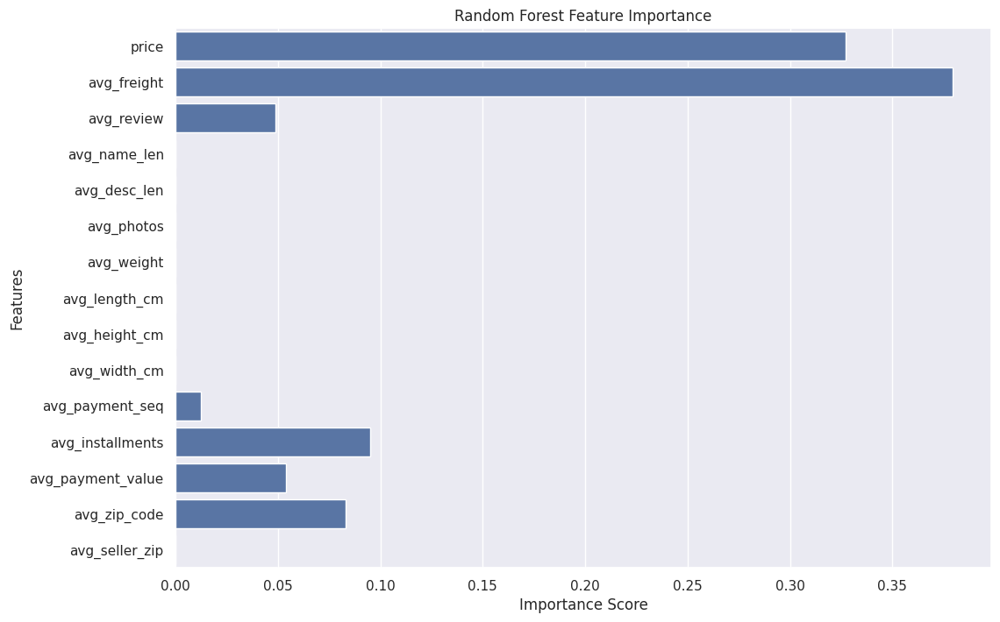

Permutation Importances: {'price': np.float64(-0.5009983593749983), 'avg_freight': np.float64(-1.3354181250000003), 'avg_review': np.float64(0.042912187500001406), 'avg_name_len': np.float64(0.0), 'avg_desc_len': np.float64(0.0), 'avg_photos': np.float64(0.0), 'avg_weight': np.float64(0.0), 'avg_length_cm': np.float64(0.0), 'avg_height_cm': np.float64(0.0), 'avg_width_cm': np.float64(0.0), 'avg_payment_seq': np.float64(0.04683562500000029), 'avg_installments': np.float64(1.576420078125001), 'avg_payment_value': np.float64(0.43405570312500075), 'avg_zip_code': np.float64(0.015852421875001), 'avg_seller_zip': np.float64(0.0)}


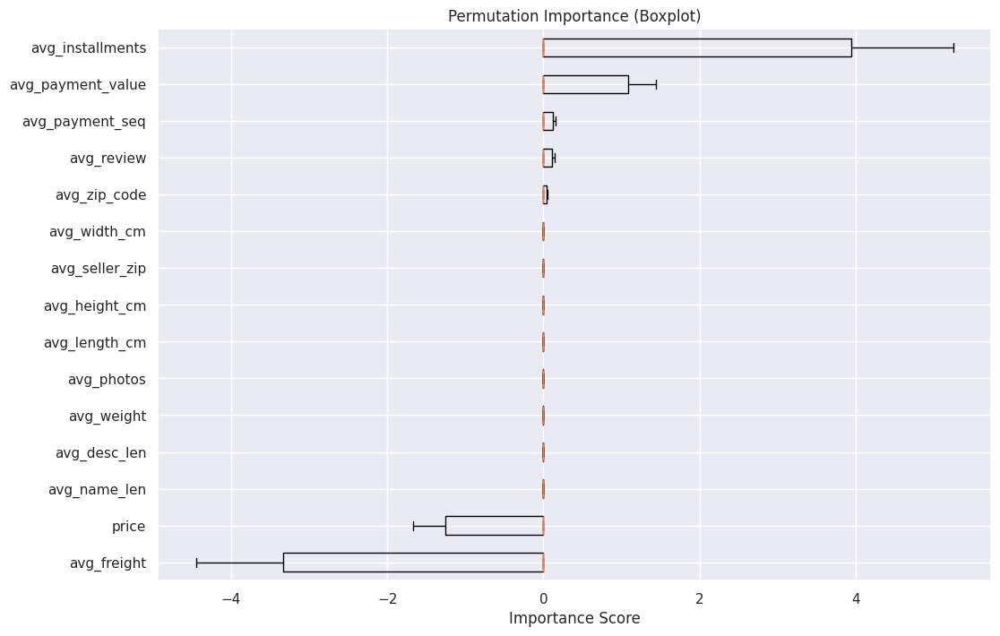

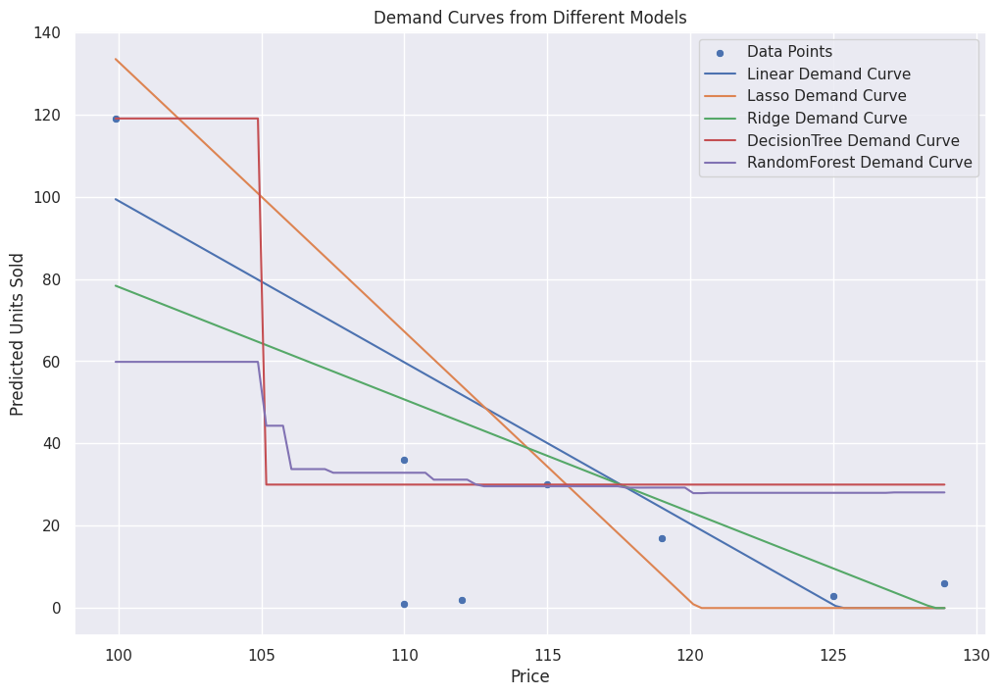

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
from sklearn.inspection import permutation_importance

# Step 1: Load and Clean Data
df = pd.read_csv('final_data.csv')

# Filter for delivered orders
df = df[df['order_status'] == 'delivered']

# Convert timestamp to datetime
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])

# Add year, month, year_month
df['year'] = df['order_purchase_timestamp'].dt.year
df['month'] = df['order_purchase_timestamp'].dt.month
df['year_month'] = df['order_purchase_timestamp'].dt.to_period('M')

# Step 2: EDA - Top Categories by Units and Revenue
category_units = df.groupby('product_category_name_english')['order_item_id'].count().sort_values(ascending=False)
category_revenue = df.groupby('product_category_name_english')['price'].sum().sort_values(ascending=False)

print("Top Categories by Units Sold:\n", category_units.head(10))
print("Top Categories by Revenue:\n", category_revenue.head(10))

# Select category: watches_gifts (top revenue generator with variation)
category = 'watches_gifts'
df_cat = df[df['product_category_name_english'] == category]

# Top product by units sold
top_product = df_cat['product_id'].value_counts().idxmax()
print("Top Product ID:", top_product)

df_prod = df_cat[df_cat['product_id'] == top_product]

# Top seller for this product
top_seller = df_prod['seller_id'].value_counts().idxmax()
print("Top Seller ID:", top_seller)

df_prod_seller = df_prod[df_prod['seller_id'] == top_seller]

# Aggregate units sold per unique price point, including more features (all numeric except NLP text)
# Exclude review_comment_title and review_comment_message as NLP
price_agg = df_prod_seller.groupby('price').agg(
    units_sold=('order_item_id', 'count'),
    avg_freight=('freight_value', 'mean'),
    avg_review=('review_score', 'mean'),
    avg_name_len=('product_name_lenght', 'mean'),
    avg_desc_len=('product_description_lenght', 'mean'),
    avg_photos=('product_photos_qty', 'mean'),
    avg_weight=('product_weight_g', 'mean'),
    avg_length_cm=('product_length_cm', 'mean'),
    avg_height_cm=('product_height_cm', 'mean'),
    avg_width_cm=('product_width_cm', 'mean'),
    avg_payment_seq=('payment_sequential', 'mean'),
    avg_installments=('payment_installments', 'mean'),
    avg_payment_value=('payment_value', 'mean'),
    avg_zip_code=('zip_code', 'mean'),
    avg_seller_zip=('seller_zip_code_prefix', 'mean')
).reset_index()

# For categoricals, add mode for payment_type and customer_state
price_agg['mode_payment_type'] = df_prod_seller.groupby('price')['payment_type'].apply(lambda x: x.mode()[0] if not x.empty else np.nan)
price_agg['mode_customer_state'] = df_prod_seller.groupby('price')['customer_state'].apply(lambda x: x.mode()[0] if not x.empty else np.nan)

# One-hot encode categoricals
price_agg = pd.get_dummies(price_agg, columns=['mode_payment_type', 'mode_customer_state'], drop_first=True)

print("Aggregated Data:\n", price_agg)

# Step 3: Simple Demand Model (Units ~ Price)
X_simple = price_agg[['price']]
y = price_agg['units_sold']

model_simple = LinearRegression()
model_simple.fit(X_simple, y)

print("Simple Model: units_sold = {:.2f} - {:.2f} * price".format(model_simple.intercept_, -model_simple.coef_[0]))
print("R-squared:", model_simple.score(X_simple, y))

# Optimization for simple model
a = model_simple.intercept_
b = -model_simple.coef_[0]
optimal_price_simple = a / (2 * b)
optimal_units_simple = a - b * optimal_price_simple
optimal_revenue_simple = optimal_price_simple * optimal_units_simple

print("Simple Model Optimal Price: ${:.2f}".format(optimal_price_simple))

# Step 4: Multivariate Model with All Features (except NLP)
features = [col for col in price_agg.columns if col not in ['units_sold']]
X = price_agg[features]
y = price_agg['units_sold']

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train-test split (small data, but for demo; use all for fitting models)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Multiple Models
models = {
    'Linear': LinearRegression(),
    'Lasso': Lasso(alpha=0.1),
    'Ridge': Ridge(alpha=1.0),
    'DecisionTree': DecisionTreeRegressor(max_depth=3, random_state=42),
    'RandomForest': RandomForestRegressor(n_estimators=100, random_state=42)
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    results[name] = {'model': model, 'mse': mse}
    print(f"{name} MSE: {mse}")

# Feature Importance for Lasso
lasso_model = models['Lasso']
if hasattr(lasso_model, 'coef_'):
    print("Lasso Coefficients:", dict(zip(features, lasso_model.coef_)))

    plt.figure(figsize=(12, 8))
    sns.barplot(x=lasso_model.coef_, y=features)
    plt.title('Lasso Feature Importance (Coefficients)')
    plt.xlabel('Coefficient Value')
    plt.ylabel('Features')
    plt.show()

# Feature Importance for Random Forest
rf_model = models['RandomForest']
if hasattr(rf_model, 'feature_importances_'):
    print("RF Feature Importances:", dict(zip(features, rf_model.feature_importances_)))

    plt.figure(figsize=(12, 8))
    sns.barplot(x=rf_model.feature_importances_, y=features)
    plt.title('Random Forest Feature Importance')
    plt.xlabel('Importance Score')
    plt.ylabel('Features')
    plt.show()

# Permutation Importance for Random Forest
perm_importance = permutation_importance(rf_model, X_test, y_test, n_repeats=10, random_state=42)
print("Permutation Importances:", dict(zip(features, perm_importance.importances_mean)))

sorted_idx = perm_importance.importances_mean.argsort()
plt.figure(figsize=(12, 8))
plt.boxplot(perm_importance.importances[sorted_idx].T, vert=False, labels=np.array(features)[sorted_idx])
plt.title('Permutation Importance (Boxplot)')
plt.xlabel('Importance Score')
plt.show()

# Step 5: Demand Curves from Different Models
# To plot demand curves, vary price while holding other features at mean
mean_features = price_agg[features].mean().values
price_range = np.linspace(price_agg['price'].min(), price_agg['price'].max(), 100)

plt.figure(figsize=(12, 8))
sns.scatterplot(x='price', y='units_sold', data=price_agg, label='Data Points')

for name, res in results.items():
    model = res['model']
    units_preds = []
    for p in price_range:
        input_features = mean_features.copy()
        input_features[features.index('price')] = p  # Replace price
        input_scaled = scaler.transform([input_features])
        pred = model.predict(input_scaled)[0]
        units_preds.append(max(pred, 0))  # Clip negative
    plt.plot(price_range, units_preds, label=f'{name} Demand Curve')

plt.title('Demand Curves from Different Models')
plt.xlabel('Price')
plt.ylabel('Predicted Units Sold')
plt.legend()
plt.show()

Top Categories by Units Sold:
 product_category_name_english
bed_bath_table           11685
health_beauty             9747
sports_leisure            8736
furniture_decor           8558
computers_accessories     7927
housewares                7154
watches_gifts             6032
telephony                 4580
garden_tools              4452
auto                      4260
Name: order_item_id, dtype: int64
Top Categories by Revenue:
 product_category_name_english
health_beauty            1266992.59
watches_gifts            1207633.40
bed_bath_table           1082024.32
sports_leisure            989781.66
computers_accessories     922593.78
furniture_decor           746811.14
housewares                646232.97
cool_stuff                628528.54
auto                      594994.54
garden_tools              490451.78
Name: price, dtype: float64
Top Product ID: 53b36df67ebb7c41585e8d54d6772e08
Top Seller ID: 7d13fca15225358621be4086e1eb0964
Aggregated Data:
     price  units_sold  avg_freight

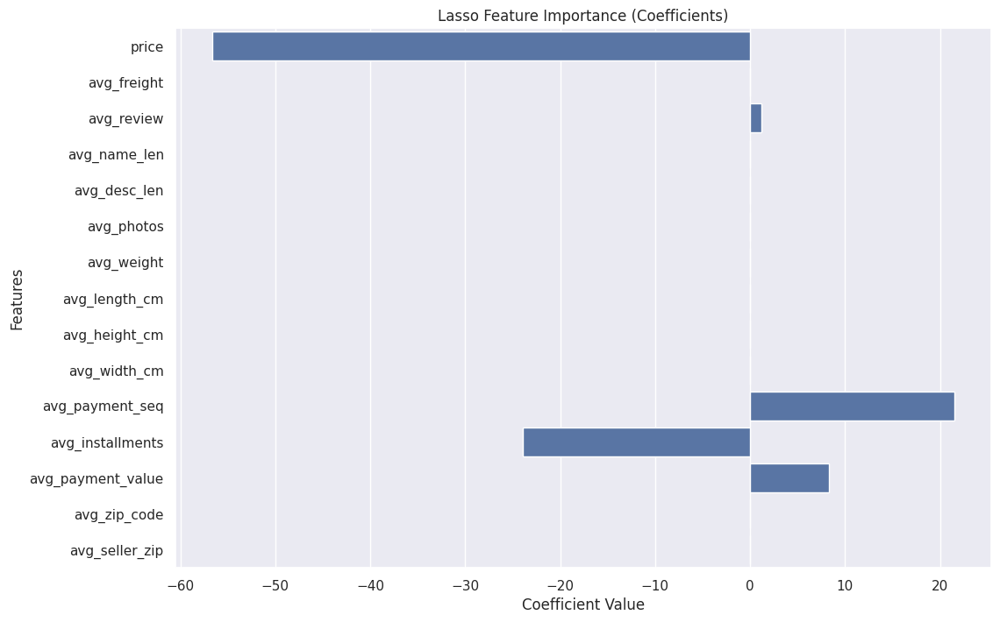

RF Feature Importances: {'price': np.float64(0.32723140357635383), 'avg_freight': np.float64(0.379240793162096), 'avg_review': np.float64(0.049018995430238396), 'avg_name_len': np.float64(0.0), 'avg_desc_len': np.float64(0.0), 'avg_photos': np.float64(0.0), 'avg_weight': np.float64(0.0), 'avg_length_cm': np.float64(0.0), 'avg_height_cm': np.float64(0.0), 'avg_width_cm': np.float64(0.0), 'avg_payment_seq': np.float64(0.012325591307343944), 'avg_installments': np.float64(0.09504654604196347), 'avg_payment_value': np.float64(0.05388699813589221), 'avg_zip_code': np.float64(0.08324967234611218), 'avg_seller_zip': np.float64(0.0)}


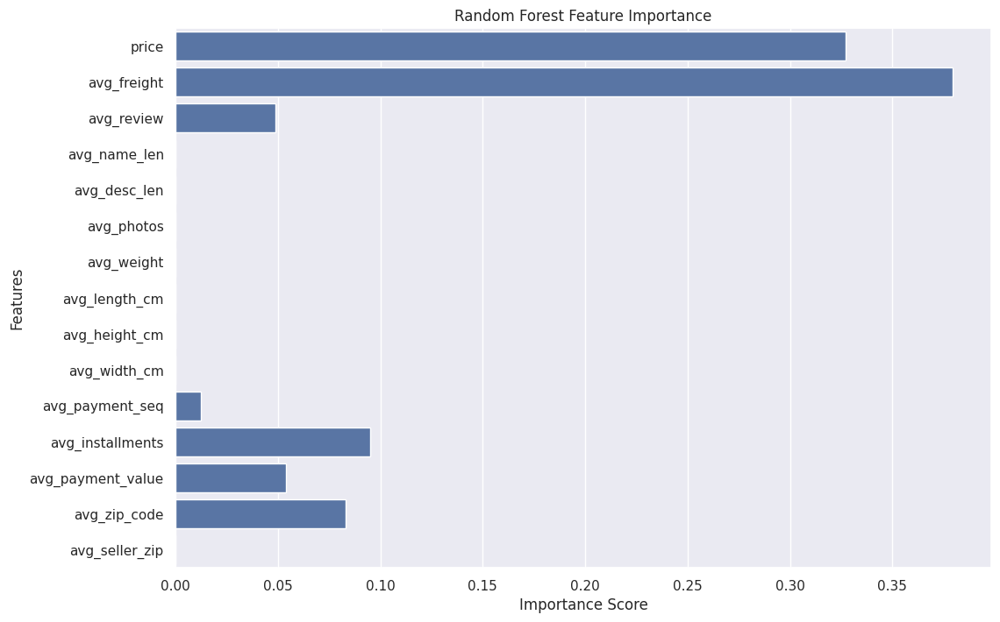

Permutation Importances: {'price': np.float64(-0.5009983593749983), 'avg_freight': np.float64(-1.3354181250000003), 'avg_review': np.float64(0.042912187500001406), 'avg_name_len': np.float64(0.0), 'avg_desc_len': np.float64(0.0), 'avg_photos': np.float64(0.0), 'avg_weight': np.float64(0.0), 'avg_length_cm': np.float64(0.0), 'avg_height_cm': np.float64(0.0), 'avg_width_cm': np.float64(0.0), 'avg_payment_seq': np.float64(0.04683562500000029), 'avg_installments': np.float64(1.576420078125001), 'avg_payment_value': np.float64(0.43405570312500075), 'avg_zip_code': np.float64(0.015852421875001), 'avg_seller_zip': np.float64(0.0)}


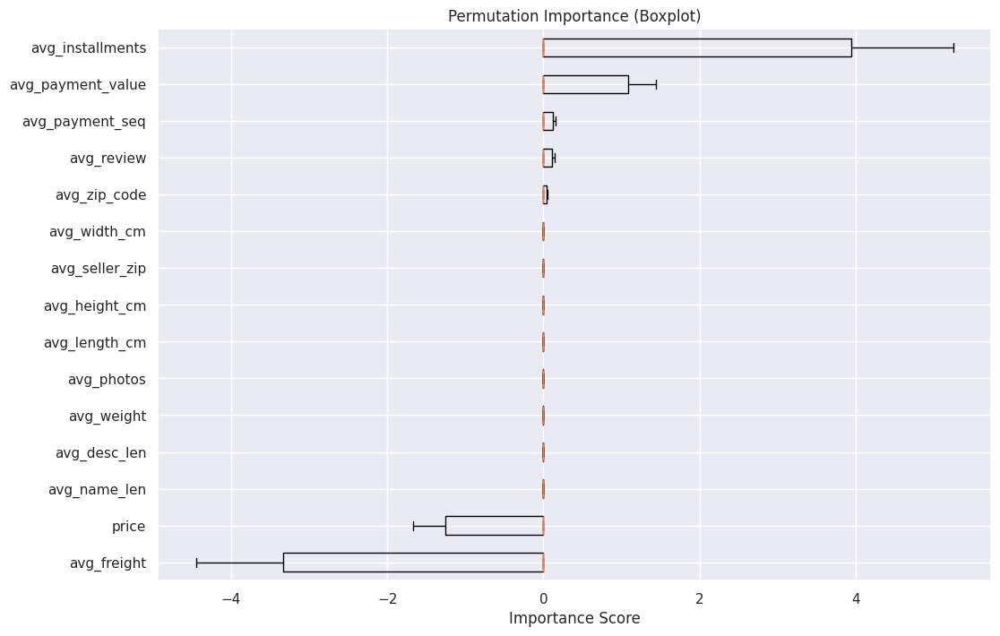

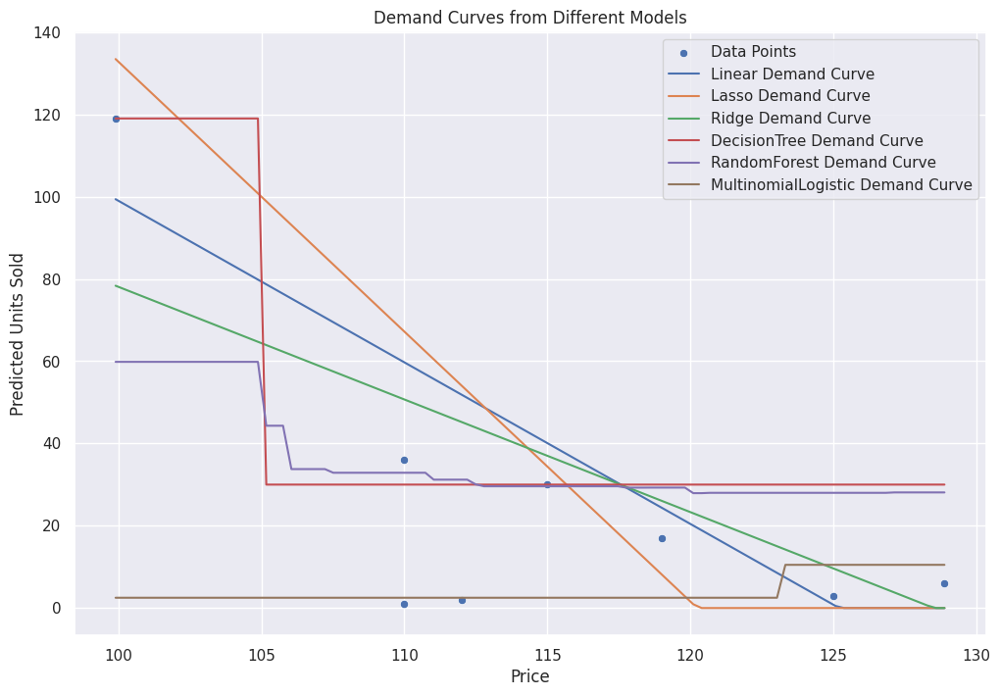

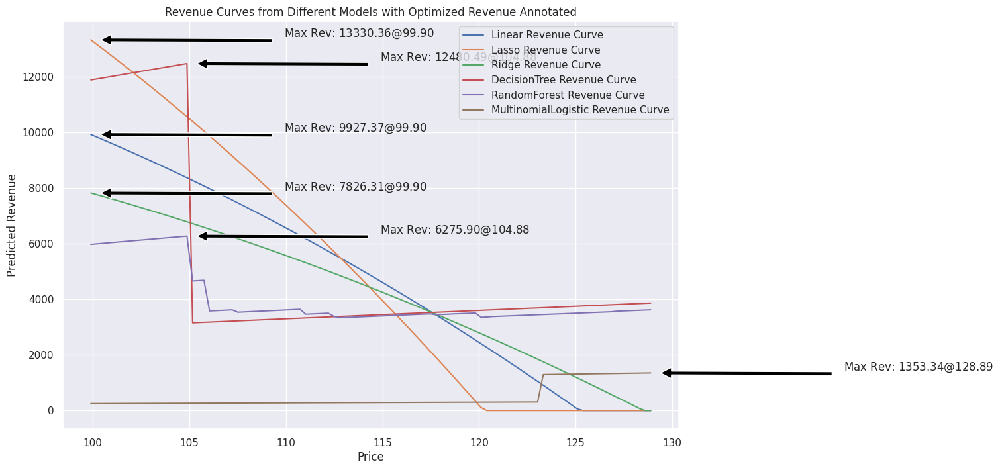

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Lasso, Ridge, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_squared_error
from sklearn.inspection import permutation_importance

# Step 1: Load and Clean Data
df = pd.read_csv('final_data.csv')

# Filter for delivered orders
df = df[df['order_status'] == 'delivered']

# Convert timestamp to datetime
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])

# Add year, month, year_month
df['year'] = df['order_purchase_timestamp'].dt.year
df['month'] = df['order_purchase_timestamp'].dt.month
df['year_month'] = df['order_purchase_timestamp'].dt.to_period('M')

# Step 2: EDA - Top Categories by Units and Revenue
category_units = df.groupby('product_category_name_english')['order_item_id'].count().sort_values(ascending=False)
category_revenue = df.groupby('product_category_name_english')['price'].sum().sort_values(ascending=False)

print("Top Categories by Units Sold:\n", category_units.head(10))
print("Top Categories by Revenue:\n", category_revenue.head(10))

# Select category: watches_gifts (top revenue generator with variation)
category = 'watches_gifts'
df_cat = df[df['product_category_name_english'] == category]

# Top product by units sold
top_product = df_cat['product_id'].value_counts().idxmax()
print("Top Product ID:", top_product)

df_prod = df_cat[df_cat['product_id'] == top_product]

# Top seller for this product
top_seller = df_prod['seller_id'].value_counts().idxmax()
print("Top Seller ID:", top_seller)

df_prod_seller = df_prod[df_prod['seller_id'] == top_seller]

# Aggregate units sold per unique price point, including more features (all numeric except NLP)
# Exclude review_comment_title and review_comment_message as NLP
price_agg = df_prod_seller.groupby('price').agg(
    units_sold=('order_item_id', 'count'),
    avg_freight=('freight_value', 'mean'),
    avg_review=('review_score', 'mean'),
    avg_name_len=('product_name_lenght', 'mean'),
    avg_desc_len=('product_description_lenght', 'mean'),
    avg_photos=('product_photos_qty', 'mean'),
    avg_weight=('product_weight_g', 'mean'),
    avg_length_cm=('product_length_cm', 'mean'),
    avg_height_cm=('product_height_cm', 'mean'),
    avg_width_cm=('product_width_cm', 'mean'),
    avg_payment_seq=('payment_sequential', 'mean'),
    avg_installments=('payment_installments', 'mean'),
    avg_payment_value=('payment_value', 'mean'),
    avg_zip_code=('zip_code', 'mean'),
    avg_seller_zip=('seller_zip_code_prefix', 'mean')
).reset_index()

# For categoricals, add mode for payment_type and customer_state
price_agg['mode_payment_type'] = df_prod_seller.groupby('price')['payment_type'].apply(lambda x: x.mode()[0] if not x.empty else np.nan)
price_agg['mode_customer_state'] = df_prod_seller.groupby('price')['customer_state'].apply(lambda x: x.mode()[0] if not x.empty else np.nan)

# One-hot encode categoricals
price_agg = pd.get_dummies(price_agg, columns=['mode_payment_type', 'mode_customer_state'], drop_first=True)

print("Aggregated Data:\n", price_agg)

# Step 3: Simple Demand Model (Units ~ Price)
X_simple = price_agg[['price']]
y = price_agg['units_sold']

model_simple = LinearRegression()
model_simple.fit(X_simple, y)

print("Simple Model: units_sold = {:.2f} - {:.2f} * price".format(model_simple.intercept_, -model_simple.coef_[0]))
print("R-squared:", model_simple.score(X_simple, y))

# Optimization for simple model
a = model_simple.intercept_
b = -model_simple.coef_[0]
optimal_price_simple = a / (2 * b)
optimal_units_simple = a - b * optimal_price_simple
optimal_revenue_simple = optimal_price_simple * optimal_units_simple

print("Simple Model Optimal Price: ${:.2f}".format(optimal_price_simple))

# Step 4: Multivariate Model with All Features (except NLP)
features = [col for col in price_agg.columns if col not in ['units_sold']]
X = price_agg[features]
y = price_agg['units_sold']

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train-test split (small data, but for demo; use all for fitting models)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Regression Models
reg_models = {
    'Linear': LinearRegression(),
    'Lasso': Lasso(alpha=0.1),
    'Ridge': Ridge(alpha=1.0),
    'DecisionTree': DecisionTreeRegressor(max_depth=3, random_state=42),
    'RandomForest': RandomForestRegressor(n_estimators=100, random_state=42)
}

reg_results = {}
for name, model in reg_models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    reg_results[name] = {'model': model, 'mse': mse}
    print(f"{name} MSE: {mse}")

# Add Multinomial Logistic Regression (Classification: bin units_sold)
# Bin y into categories: low (0-5), med (6-15), high (16+)
bins = [0, 5, 15, np.inf]
labels = ['low', 'med', 'high']
y_binned = pd.cut(y, bins=bins, labels=labels)
le = LabelEncoder()
y_encoded = le.fit_transform(y_binned)

# Split for classification
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(X_scaled, y_encoded, test_size=0.2, random_state=42)

log_model = LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=1000)
log_model.fit(X_train_clf, y_train_clf)

# For MSE, predict and map back to midpoints for approximation
midpoints = [2.5, 10.5, 20]  # Approx mid for bins
y_pred_clf = log_model.predict(X_test_clf)
y_pred_reg_approx = [midpoints[p] for p in y_pred_clf]
mse_clf = mean_squared_error(y_test, y_pred_reg_approx)  # Approx regression MSE
print(f"Multinomial Logistic (Approx) MSE: {mse_clf}")

# Feature Importance for Lasso
lasso_model = reg_models['Lasso']
if hasattr(lasso_model, 'coef_'):
    print("Lasso Coefficients:", dict(zip(features, lasso_model.coef_)))

    plt.figure(figsize=(12, 8))
    sns.barplot(x=lasso_model.coef_, y=features)
    plt.title('Lasso Feature Importance (Coefficients)')
    plt.xlabel('Coefficient Value')
    plt.ylabel('Features')
    plt.show()

# Feature Importance for Random Forest
rf_model = reg_models['RandomForest']
if hasattr(rf_model, 'feature_importances_'):
    print("RF Feature Importances:", dict(zip(features, rf_model.feature_importances_)))

    plt.figure(figsize=(12, 8))
    sns.barplot(x=rf_model.feature_importances_, y=features)
    plt.title('Random Forest Feature Importance')
    plt.xlabel('Importance Score')
    plt.ylabel('Features')
    plt.show()

# Permutation Importance for Random Forest
perm_importance = permutation_importance(rf_model, X_test, y_test, n_repeats=10, random_state=42)
print("Permutation Importances:", dict(zip(features, perm_importance.importances_mean)))

sorted_idx = perm_importance.importances_mean.argsort()
plt.figure(figsize=(12, 8))
plt.boxplot(perm_importance.importances[sorted_idx].T, vert=False, labels=np.array(features)[sorted_idx])
plt.title('Permutation Importance (Boxplot)')
plt.xlabel('Importance Score')
plt.show()

# Step 5: Demand Curves from Different Models
# To plot demand curves, vary price while holding other features at mean
mean_features = price_agg[features].mean().values
price_range = np.linspace(price_agg['price'].min(), price_agg['price'].max(), 100)

plt.figure(figsize=(12, 8))
sns.scatterplot(x='price', y='units_sold', data=price_agg, label='Data Points')

models_for_plot = {**reg_models, 'MultinomialLogistic': log_model}

for name, model in models_for_plot.items():
    units_preds = []
    for p in price_range:
        input_features = mean_features.copy()
        input_features[features.index('price')] = p  # Replace price
        input_scaled = scaler.transform([input_features])
        if name == 'MultinomialLogistic':
            pred_clf = model.predict(input_scaled)[0]
            pred = midpoints[pred_clf]  # Map to midpoint
        else:
            pred = model.predict(input_scaled)[0]
        units_preds.append(max(pred, 0))  # Clip negative
    plt.plot(price_range, units_preds, label=f'{name} Demand Curve')

plt.title('Demand Curves from Different Models')
plt.xlabel('Price')
plt.ylabel('Predicted Units Sold')
plt.legend()
plt.show()

# Step 6: Revenue Curves with Optimized Revenue Annotated
plt.figure(figsize=(12, 8))

for name, model in models_for_plot.items():
    revenues = []
    for p in price_range:
        input_features = mean_features.copy()
        input_features[features.index('price')] = p
        input_scaled = scaler.transform([input_features])
        if name == 'MultinomialLogistic':
            pred_clf = model.predict(input_scaled)[0]
            pred = midpoints[pred_clf]
        else:
            pred = model.predict(input_scaled)[0]
        rev = p * max(pred, 0)
        revenues.append(rev)

    plt.plot(price_range, revenues, label=f'{name} Revenue Curve')

    # Find and annotate max revenue
    max_idx = np.argmax(revenues)
    max_price = price_range[max_idx]
    max_rev = revenues[max_idx]
    plt.annotate(f'Max Rev: ${max_rev:.2f} @ ${max_price:.2f}',
                 xy=(max_price, max_rev), xytext=(max_price + 10, max_rev + 100),
                 arrowprops=dict(facecolor='black', shrink=0.05))

plt.title('Revenue Curves from Different Models with Optimized Revenue Annotated')
plt.xlabel('Price')
plt.ylabel('Predicted Revenue')
plt.legend()
plt.show()

'Top Categories by Units Sold:\n'

,order_item_id
product_category_name_english,
bed_bath_table,11685
health_beauty,9747
sports_leisure,8736
furniture_decor,8558
computers_accessories,7927
housewares,7154
watches_gifts,6032
telephony,4580
garden_tools,4452


'Top Categories by Revenue:\n'

,price
product_category_name_english,
health_beauty,1266992.59
watches_gifts,1207633.40
bed_bath_table,1082024.32
sports_leisure,989781.66
computers_accessories,922593.78
furniture_decor,746811.14
housewares,646232.97
cool_stuff,628528.54
auto,594994.54


'Top Product ID:'

'53b36df67ebb7c41585e8d54d6772e08'

'Top Seller ID:'

'7d13fca15225358621be4086e1eb0964'

'Aggregated Data:\n'

,price,units_sold,avg_freight,avg_review,avg_name_len,avg_desc_len,avg_photos,avg_weight,avg_length_cm,avg_height_cm,avg_width_cm,avg_payment_seq,avg_installments,avg_payment_value,avg_zip_code,avg_seller_zip
0,99.90,119,0.000000,4.386555,33.0,523.0,3.0,584.0,16.0,11.0,13.0,1.000000,2.974790,130.121849,33145.731092,14050.0
1,109.99,1,0.000000,5.000000,33.0,523.0,3.0,584.0,16.0,11.0,13.0,1.000000,2.000000,109.990000,80710.000000,14050.0
2,110.00,36,3.343611,4.222222,33.0,523.0,3.0,584.0,16.0,11.0,13.0,1.027778,3.444444,119.568611,37524.555556,14050.0
3,112.00,2,13.440000,5.000000,33.0,523.0,3.0,584.0,16.0,11.0,13.0,1.000000,4.000000,125.440000,21287.000000,14050.0
4,115.00,30,12.043000,4.133333,33.0,523.0,3.0,584.0,16.0,11.0,13.0,1.000000,2.766667,134.709667,30296.833333,14050.0
5,119.00,17,17.447059,4.588235,33.0,523.0,3.0,584.0,16.0,11.0,13.0,1.058824,3.117647,131.441765,35549.117647,14050.0
6,125.00,3,14.016667,3.666667,33.0,523.0,3.0,584.0,16.0,11.0,13.0,1.000000,1.666667,139.016667,22005.333333,14050.0
7,128.89,6,15.108333,4.500000,33.0,523.0,3.0,584.0,16.0,11.0,13.0,1.166667,2.333333,119.908333,53701.333333,14050.0


Simple Model: units_sold = 374.09 - 3.02 * price
R-squared: 0.495834664280701
Simple Model Optimal Price: $61.91
Linear MSE: 6469.947726619406
Lasso MSE: 2219.3993510563428
Ridge MSE: 4522.773774727376
DecisionTree MSE: 717.625
RandomForest MSE: 1439.20465
Multinomial Logistic (Approx) MSE: 22.25
Lasso Coefficients: {'price': np.float64(-56.6133634105971), 'avg_freight': np.float64(-0.0), 'avg_review': np.float64(1.2293263741927238), 'avg_name_len': np.float64(0.0), 'avg_desc_len': np.float64(0.0), 'avg_photos': np.float64(0.0), 'avg_weight': np.float64(0.0), 'avg_length_cm': np.float64(0.0), 'avg_height_cm': np.float64(0.0), 'avg_width_cm': np.float64(0.0), 'avg_payment_seq': np.float64(21.491957085931666), 'avg_installments': np.float64(-23.91904793293613), 'avg_payment_value': np.float64(8.266683606807838), 'avg_zip_code': np.float64(0.0), 'avg_seller_zip': np.float64(0.0)}


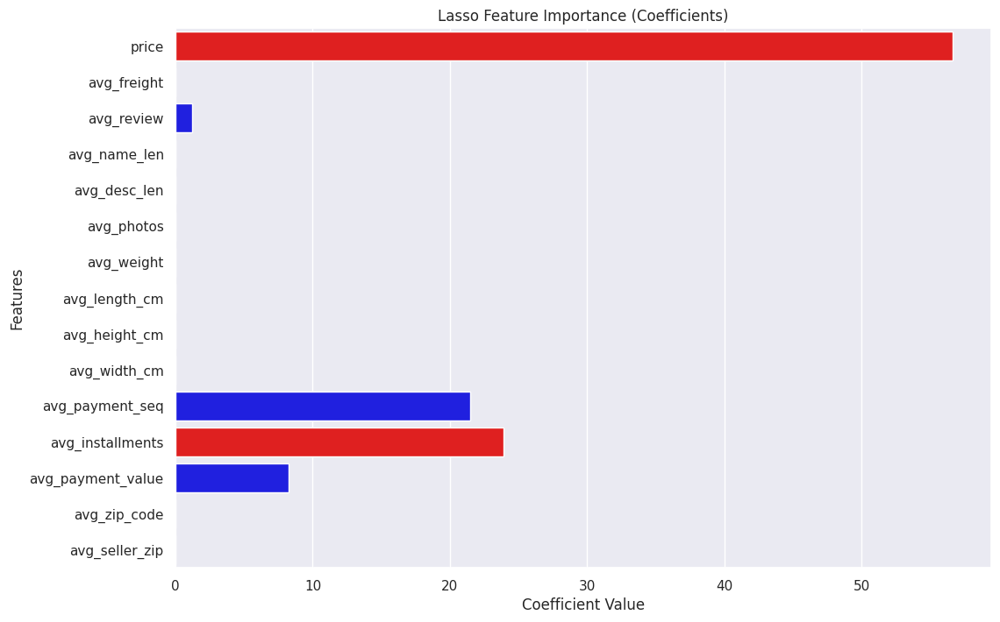

RF Feature Importances: {'price': np.float64(0.32723140357635383), 'avg_freight': np.float64(0.379240793162096), 'avg_review': np.float64(0.049018995430238396), 'avg_name_len': np.float64(0.0), 'avg_desc_len': np.float64(0.0), 'avg_photos': np.float64(0.0), 'avg_weight': np.float64(0.0), 'avg_length_cm': np.float64(0.0), 'avg_height_cm': np.float64(0.0), 'avg_width_cm': np.float64(0.0), 'avg_payment_seq': np.float64(0.012325591307343944), 'avg_installments': np.float64(0.09504654604196347), 'avg_payment_value': np.float64(0.05388699813589221), 'avg_zip_code': np.float64(0.08324967234611218), 'avg_seller_zip': np.float64(0.0)}


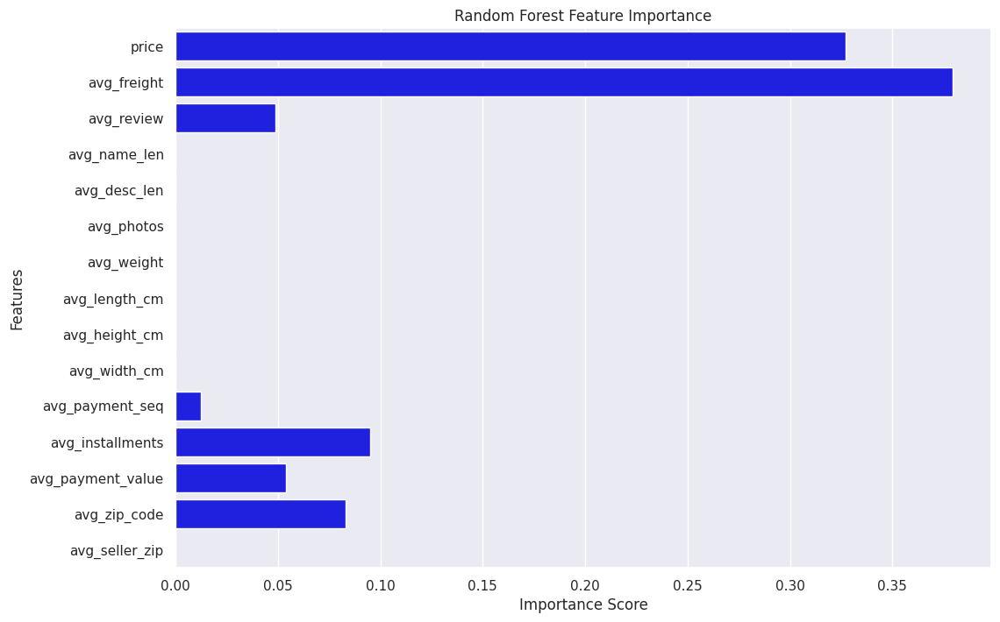

Permutation Importances: {'price': np.float64(-0.5009983593749983), 'avg_freight': np.float64(-1.3354181250000003), 'avg_review': np.float64(0.042912187500001406), 'avg_name_len': np.float64(0.0), 'avg_desc_len': np.float64(0.0), 'avg_photos': np.float64(0.0), 'avg_weight': np.float64(0.0), 'avg_length_cm': np.float64(0.0), 'avg_height_cm': np.float64(0.0), 'avg_width_cm': np.float64(0.0), 'avg_payment_seq': np.float64(0.04683562500000029), 'avg_installments': np.float64(1.576420078125001), 'avg_payment_value': np.float64(0.43405570312500075), 'avg_zip_code': np.float64(0.015852421875001), 'avg_seller_zip': np.float64(0.0)}


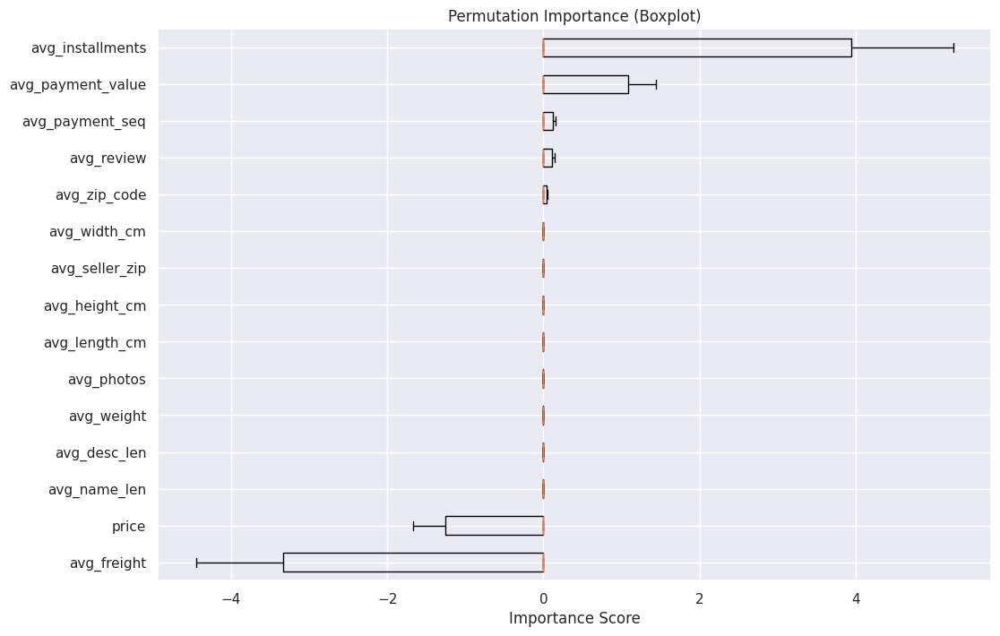

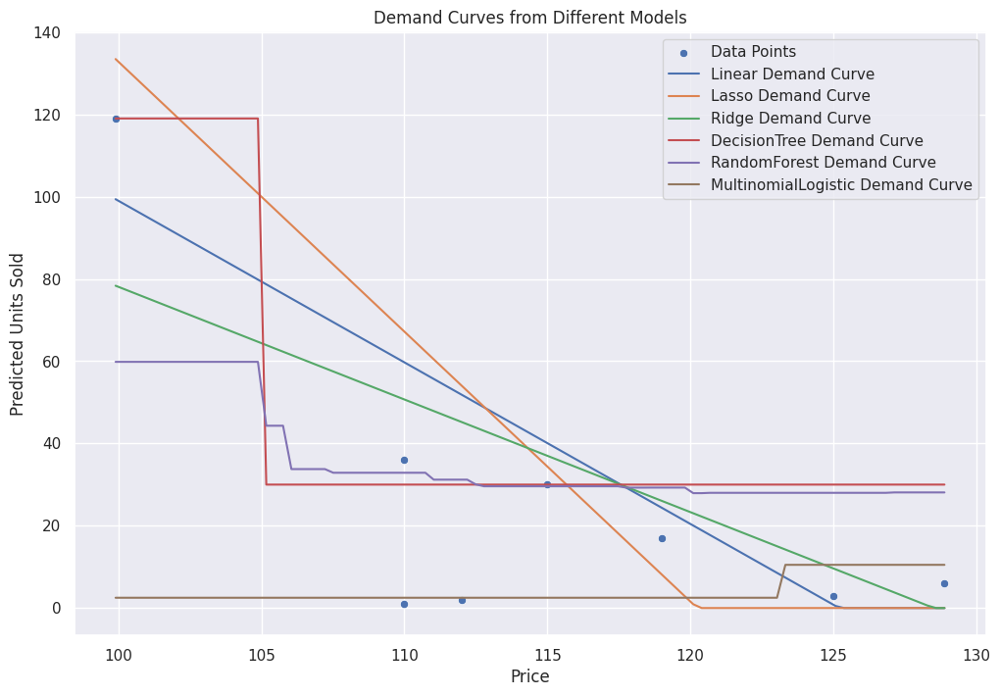

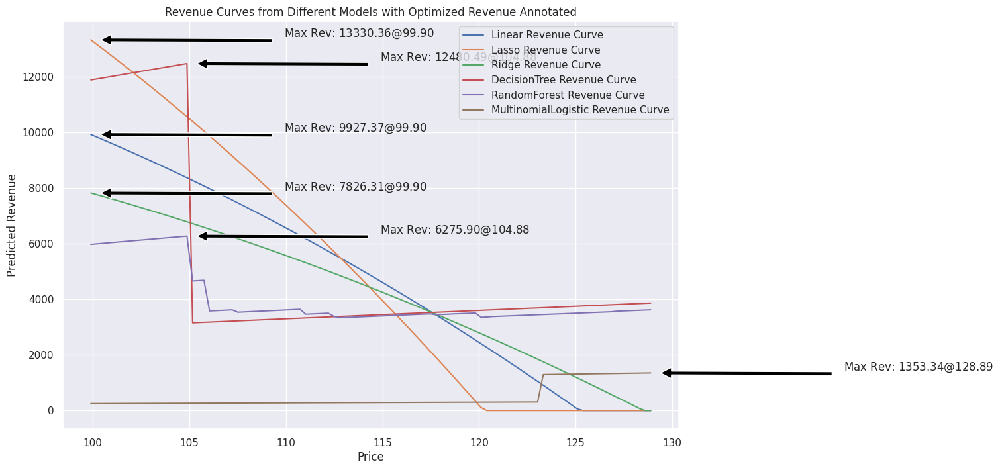

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Lasso, Ridge, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_squared_error
from sklearn.inspection import permutation_importance

# Step 1: Load and Clean Data
df = pd.read_csv('final_data.csv')

# Filter for delivered orders
df = df[df['order_status'] == 'delivered']

# Convert timestamp to datetime
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])

# Add year, month, year_month
df['year'] = df['order_purchase_timestamp'].dt.year
df['month'] = df['order_purchase_timestamp'].dt.month
df['year_month'] = df['order_purchase_timestamp'].dt.to_period('M')

# Step 2: EDA - Top Categories by Units and Revenue
category_units = df.groupby('product_category_name_english')['order_item_id'].count().sort_values(ascending=False)
category_revenue = df.groupby('product_category_name_english')['price'].sum().sort_values(ascending=False)

display("Top Categories by Units Sold:\n", category_units.head(10))
display("Top Categories by Revenue:\n", category_revenue.head(10))

# Select category: watches_gifts (top revenue generator with variation)
category = 'watches_gifts'
df_cat = df[df['product_category_name_english'] == category]

# Top product by units sold
top_product = df_cat['product_id'].value_counts().idxmax()
display("Top Product ID:", top_product)

df_prod = df_cat[df_cat['product_id'] == top_product]

# Top seller for this product
top_seller = df_prod['seller_id'].value_counts().idxmax()
display("Top Seller ID:", top_seller)

df_prod_seller = df_prod[df_prod['seller_id'] == top_seller]

# Aggregate units sold per unique price point, including more features (all numeric except NLP)
# Exclude review_comment_title and review_comment_message as NLP
price_agg = df_prod_seller.groupby('price').agg(
    units_sold=('order_item_id', 'count'),
    avg_freight=('freight_value', 'mean'),
    avg_review=('review_score', 'mean'),
    avg_name_len=('product_name_lenght', 'mean'),
    avg_desc_len=('product_description_lenght', 'mean'),
    avg_photos=('product_photos_qty', 'mean'),
    avg_weight=('product_weight_g', 'mean'),
    avg_length_cm=('product_length_cm', 'mean'),
    avg_height_cm=('product_height_cm', 'mean'),
    avg_width_cm=('product_width_cm', 'mean'),
    avg_payment_seq=('payment_sequential', 'mean'),
    avg_installments=('payment_installments', 'mean'),
    avg_payment_value=('payment_value', 'mean'),
    avg_zip_code=('zip_code', 'mean'),
    avg_seller_zip=('seller_zip_code_prefix', 'mean')
).reset_index()

# For categoricals, add mode for payment_type and customer_state
price_agg['mode_payment_type'] = df_prod_seller.groupby('price')['payment_type'].apply(lambda x: x.mode()[0] if not x.empty else np.nan)
price_agg['mode_customer_state'] = df_prod_seller.groupby('price')['customer_state'].apply(lambda x: x.mode()[0] if not x.empty else np.nan)

# One-hot encode categoricals
price_agg = pd.get_dummies(price_agg, columns=['mode_payment_type', 'mode_customer_state'], drop_first=True)

display("Aggregated Data:\n", price_agg)

# Step 3: Simple Demand Model (Units ~ Price)
X_simple = price_agg[['price']]
y = price_agg['units_sold']

model_simple = LinearRegression()
model_simple.fit(X_simple, y)

print("Simple Model: units_sold = {:.2f} - {:.2f} * price".format(model_simple.intercept_, -model_simple.coef_[0]))
print("R-squared:", model_simple.score(X_simple, y))

# Optimization for simple model
a = model_simple.intercept_
b = -model_simple.coef_[0]
optimal_price_simple = a / (2 * b)
optimal_units_simple = a - b * optimal_price_simple
optimal_revenue_simple = optimal_price_simple * optimal_units_simple

print("Simple Model Optimal Price: ${:.2f}".format(optimal_price_simple))

# Step 4: Multivariate Model with All Features (except NLP)
features = [col for col in price_agg.columns if col not in ['units_sold']]
X = price_agg[features]
y = price_agg['units_sold']

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train-test split (small data, but for demo; use all for fitting models)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Regression Models
reg_models = {
    'Linear': LinearRegression(),
    'Lasso': Lasso(alpha=0.1),
    'Ridge': Ridge(alpha=1.0),
    'DecisionTree': DecisionTreeRegressor(max_depth=3, random_state=42),
    'RandomForest': RandomForestRegressor(n_estimators=100, random_state=42)
}

reg_results = {}
for name, model in reg_models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    reg_results[name] = {'model': model, 'mse': mse}
    print(f"{name} MSE: {mse}")

# Add Multinomial Logistic Regression (Classification: bin units_sold)
# Bin y into categories: low (0-5), med (6-15), high (16+)
bins = [0, 5, 15, np.inf]
labels = ['low', 'med', 'high']
y_binned = pd.cut(y, bins=bins, labels=labels)
le = LabelEncoder()
y_encoded = le.fit_transform(y_binned)

# Split for classification
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(X_scaled, y_encoded, test_size=0.2, random_state=42)

log_model = LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=1000)
log_model.fit(X_train_clf, y_train_clf)

# For MSE, predict and map back to midpoints for approximation
midpoints = [2.5, 10.5, 20]  # Approx mid for bins
y_pred_clf = log_model.predict(X_test_clf)
y_pred_reg_approx = [midpoints[p] for p in y_pred_clf]
mse_clf = mean_squared_error(y_test, y_pred_reg_approx)  # Approx regression MSE
print(f"Multinomial Logistic (Approx) MSE: {mse_clf}")

# Feature Importance for Lasso (with colored bars: positive blue, negative red)
lasso_model = reg_models['Lasso']
if hasattr(lasso_model, 'coef_'):
    print("Lasso Coefficients:", dict(zip(features, lasso_model.coef_)))

    # Create colors based on sign
    lasso_colors = ['blue' if c > 0 else 'red' for c in lasso_model.coef_]

    plt.figure(figsize=(12, 8))
    sns.barplot(x=abs(lasso_model.coef_), y=features, palette=lasso_colors)
    plt.title('Lasso Feature Importance (Coefficients)')
    plt.xlabel('Coefficient Value')
    plt.ylabel('Features')
    plt.show()

# Feature Importance for Random Forest (all positive, so blue; but check for any negatives though unlikely)
rf_model = reg_models['RandomForest']
if hasattr(rf_model, 'feature_importances_'):
    print("RF Feature Importances:", dict(zip(features, rf_model.feature_importances_)))

    # Colors: positive blue, negative red (though RF importances >=0)
    rf_colors = ['blue' if i > 0 else 'red' for i in rf_model.feature_importances_]

    plt.figure(figsize=(12, 8))
    sns.barplot(x=rf_model.feature_importances_, y=features, palette=rf_colors)
    plt.title('Random Forest Feature Importance')
    plt.xlabel('Importance Score')
    plt.ylabel('Features')
    plt.show()

# Permutation Importance for Random Forest
perm_importance = permutation_importance(rf_model, X_test, y_test, n_repeats=10, random_state=42)
print("Permutation Importances:", dict(zip(features, perm_importance.importances_mean)))

sorted_idx = perm_importance.importances_mean.argsort()
plt.figure(figsize=(12, 8))
plt.boxplot(perm_importance.importances[sorted_idx].T, vert=False, labels=np.array(features)[sorted_idx])
plt.title('Permutation Importance (Boxplot)')
plt.xlabel('Importance Score')
plt.show()

# Step 5: Demand Curves from Different Models
# To plot demand curves, vary price while holding other features at mean
mean_features = price_agg[features].mean().values
price_range = np.linspace(price_agg['price'].min(), price_agg['price'].max(), 100)

plt.figure(figsize=(12, 8))
sns.scatterplot(x='price', y='units_sold', data=price_agg, label='Data Points')

models_for_plot = {**reg_models, 'MultinomialLogistic': log_model}

for name, model in models_for_plot.items():
    units_preds = []
    for p in price_range:
        input_features = mean_features.copy()
        input_features[features.index('price')] = p  # Replace price
        input_scaled = scaler.transform([input_features])
        if name == 'MultinomialLogistic':
            pred_clf = model.predict(input_scaled)[0]
            pred = midpoints[pred_clf]  # Map to midpoint
        else:
            pred = model.predict(input_scaled)[0]
        units_preds.append(max(pred, 0))  # Clip negative
    plt.plot(price_range, units_preds, label=f'{name} Demand Curve')

plt.title('Demand Curves from Different Models')
plt.xlabel('Price')
plt.ylabel('Predicted Units Sold')
plt.legend()
plt.show()

# Step 6: Revenue Curves with Optimized Revenue Annotated
plt.figure(figsize=(12, 8))

for name, model in models_for_plot.items():
    revenues = []
    for p in price_range:
        input_features = mean_features.copy()
        input_features[features.index('price')] = p
        input_scaled = scaler.transform([input_features])
        if name == 'MultinomialLogistic':
            pred_clf = model.predict(input_scaled)[0]
            pred = midpoints[pred_clf]
        else:
            pred = model.predict(input_scaled)[0]
        rev = p * max(pred, 0)
        revenues.append(rev)

    plt.plot(price_range, revenues, label=f'{name} Revenue Curve')

    # Find and annotate max revenue
    max_idx = np.argmax(revenues)
    max_price = price_range[max_idx]
    max_rev = revenues[max_idx]
    plt.annotate(f'Max Rev: ${max_rev:.2f} @ ${max_price:.2f}',
                 xy=(max_price, max_rev), xytext=(max_price + 10, max_rev + 100),
                 arrowprops=dict(facecolor='black', shrink=0.05))

plt.title('Revenue Curves from Different Models with Optimized Revenue Annotated')
plt.xlabel('Price')
plt.ylabel('Predicted Revenue')
plt.legend()
plt.show()

Top Categories by Units Sold:
 product_category_name_english
bed_bath_table           11685
health_beauty             9747
sports_leisure            8736
furniture_decor           8558
computers_accessories     7927
housewares                7154
watches_gifts             6032
telephony                 4580
garden_tools              4452
auto                      4260
Name: order_item_id, dtype: int64
Top Categories by Revenue:
 product_category_name_english
health_beauty            1266992.59
watches_gifts            1207633.40
bed_bath_table           1082024.32
sports_leisure            989781.66
computers_accessories     922593.78
furniture_decor           746811.14
housewares                646232.97
cool_stuff                628528.54
auto                      594994.54
garden_tools              490451.78
Name: price, dtype: float64
Top Product ID: 53b36df67ebb7c41585e8d54d6772e08
Top Seller ID: 7d13fca15225358621be4086e1eb0964
Aggregated Data:
     price  units_sold  rep_freight

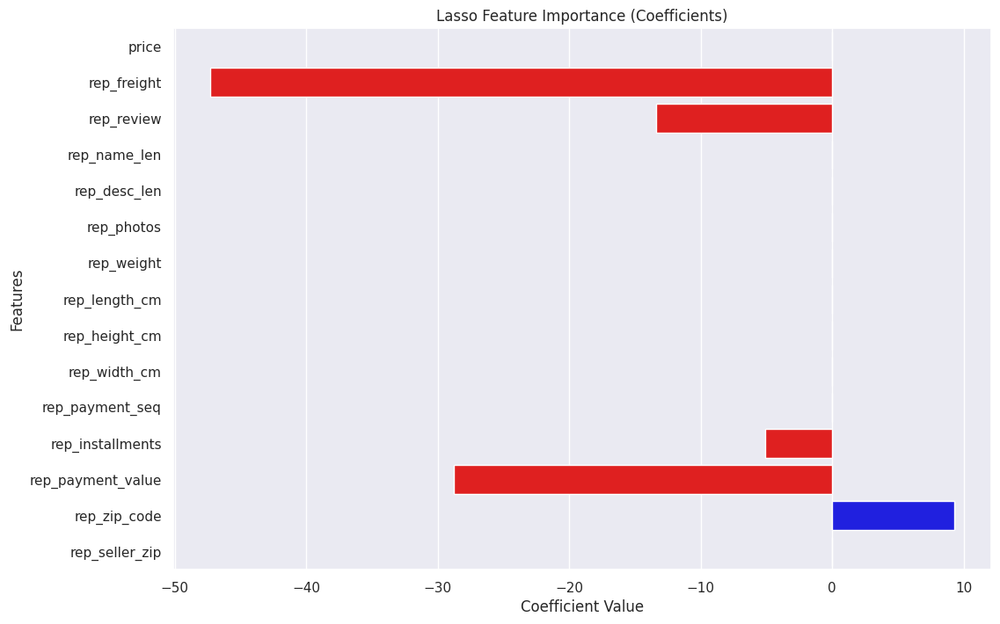

RF Feature Importances: {'price': np.float64(0.2731813039410963), 'rep_freight': np.float64(0.32463134894206264), 'rep_review': np.float64(0.038658223702555734), 'rep_name_len': np.float64(0.0), 'rep_desc_len': np.float64(0.0), 'rep_photos': np.float64(0.0), 'rep_weight': np.float64(0.0), 'rep_length_cm': np.float64(0.0), 'rep_height_cm': np.float64(0.0), 'rep_width_cm': np.float64(0.0), 'rep_payment_seq': np.float64(0.010658579693615135), 'rep_installments': np.float64(0.029303565774385212), 'rep_payment_value': np.float64(0.2050921931085365), 'rep_zip_code': np.float64(0.11847478483774831), 'rep_seller_zip': np.float64(0.0)}


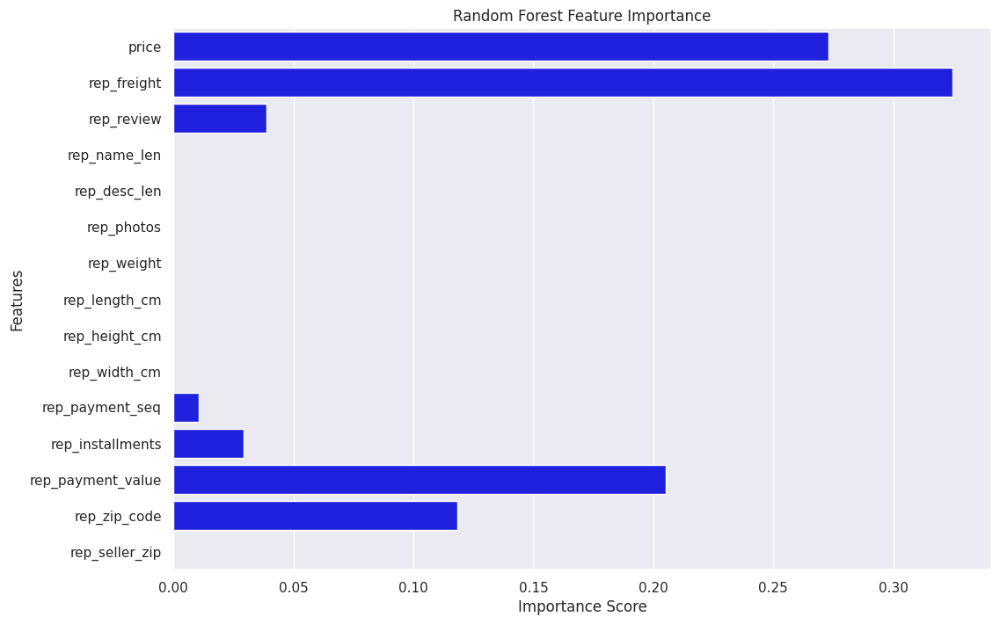

Permutation Importances: {'price': np.float64(-0.19623164062500215), 'rep_freight': np.float64(-1.3539485156250006), 'rep_review': np.float64(0.06612117187499855), 'rep_name_len': np.float64(0.0), 'rep_desc_len': np.float64(0.0), 'rep_photos': np.float64(0.0), 'rep_weight': np.float64(0.0), 'rep_length_cm': np.float64(0.0), 'rep_height_cm': np.float64(0.0), 'rep_width_cm': np.float64(0.0), 'rep_payment_seq': np.float64(0.0), 'rep_installments': np.float64(-0.09341437500000112), 'rep_payment_value': np.float64(-1.462566328125001), 'rep_zip_code': np.float64(2.410023046874999), 'rep_seller_zip': np.float64(0.0)}


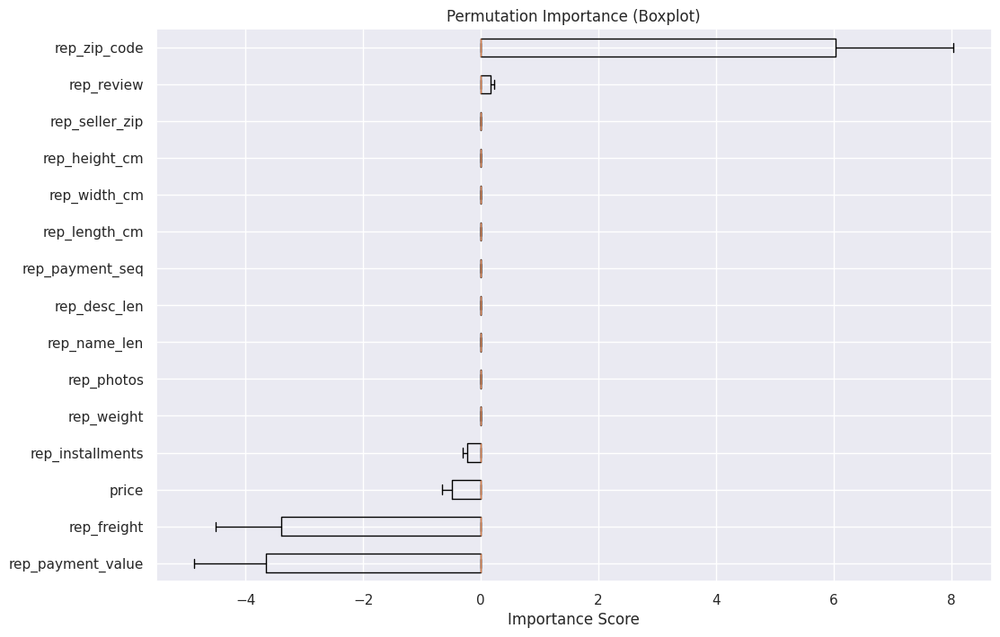

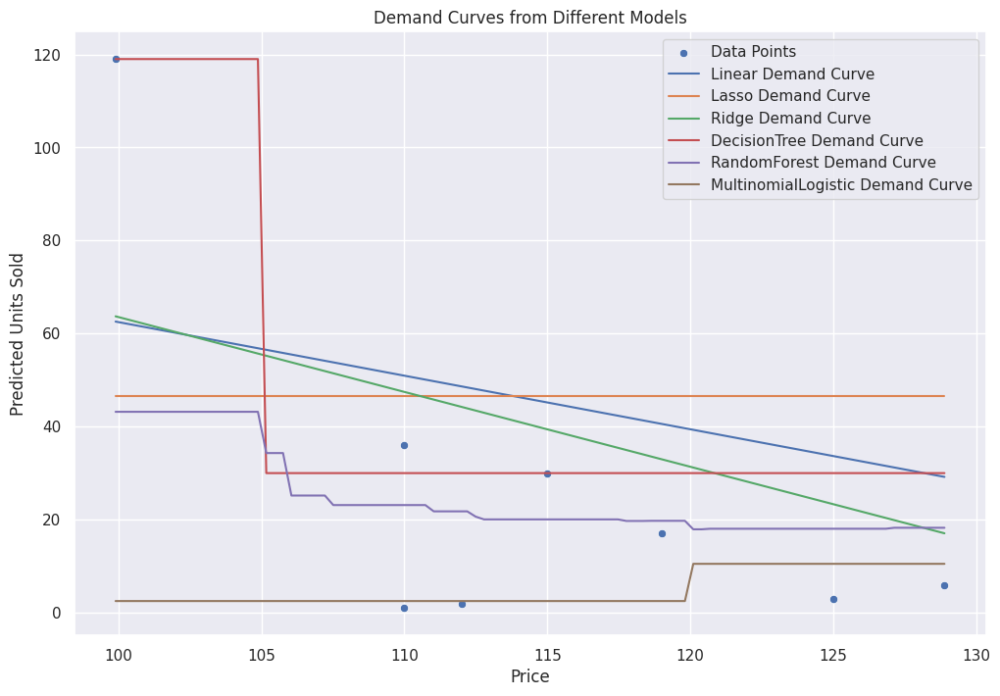

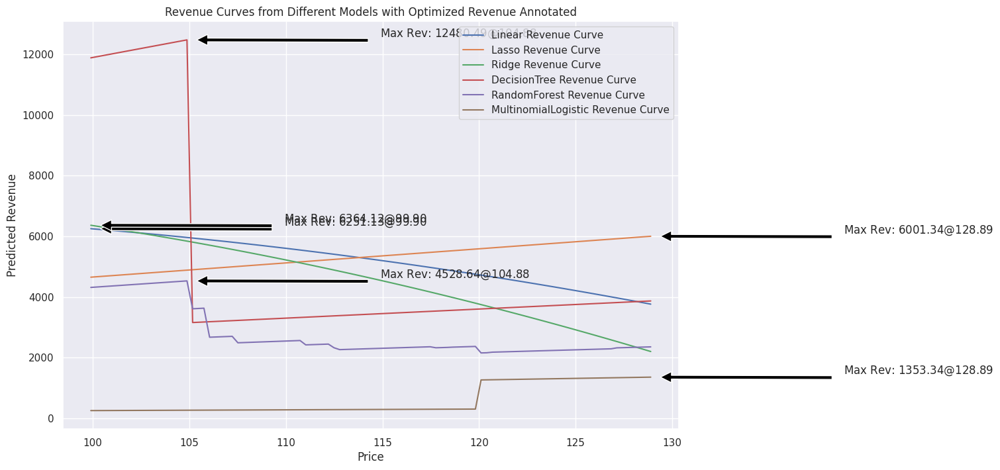

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Lasso, Ridge, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_squared_error
from sklearn.inspection import permutation_importance

# Step 1: Load and Clean Data
df = pd.read_csv('final_data.csv')

# Filter for delivered orders
df = df[df['order_status'] == 'delivered']

# Convert timestamp to datetime
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])

# Add year, month, year_month
df['year'] = df['order_purchase_timestamp'].dt.year
df['month'] = df['order_purchase_timestamp'].dt.month
df['year_month'] = df['order_purchase_timestamp'].dt.to_period('M')

# Step 2: EDA - Top Categories by Units and Revenue
category_units = df.groupby('product_category_name_english')['order_item_id'].count().sort_values(ascending=False)
category_revenue = df.groupby('product_category_name_english')['price'].sum().sort_values(ascending=False)

print("Top Categories by Units Sold:\n", category_units.head(10))
print("Top Categories by Revenue:\n", category_revenue.head(10))

# Select category: watches_gifts (top revenue generator with variation)
category = 'watches_gifts'
df_cat = df[df['product_category_name_english'] == category]

# Top product by units sold
top_product = df_cat['product_id'].value_counts().idxmax()
print("Top Product ID:", top_product)

df_prod = df_cat[df_cat['product_id'] == top_product]

# Top seller for this product
top_seller = df_prod['seller_id'].value_counts().idxmax()
print("Top Seller ID:", top_seller)

df_prod_seller = df_prod[df_prod['seller_id'] == top_seller]

# Aggregate units sold per unique price point, including more features (all numeric except NLP)
# Exclude review_comment_title and review_comment_message as NLP
# Use 'first' instead of 'mean' for other features
price_agg = df_prod_seller.groupby('price').agg(
    units_sold=('order_item_id', 'count'),
    rep_freight=('freight_value', 'first'),
    rep_review=('review_score', 'first'),
    rep_name_len=('product_name_lenght', 'first'),
    rep_desc_len=('product_description_lenght', 'first'),
    rep_photos=('product_photos_qty', 'first'),
    rep_weight=('product_weight_g', 'first'),
    rep_length_cm=('product_length_cm', 'first'),
    rep_height_cm=('product_height_cm', 'first'),
    rep_width_cm=('product_width_cm', 'first'),
    rep_payment_seq=('payment_sequential', 'first'),
    rep_installments=('payment_installments', 'first'),
    rep_payment_value=('payment_value', 'first'),
    rep_zip_code=('zip_code', 'first'),
    rep_seller_zip=('seller_zip_code_prefix', 'first')
).reset_index()

# For categoricals, add mode for payment_type and customer_state
price_agg['mode_payment_type'] = df_prod_seller.groupby('price')['payment_type'].apply(lambda x: x.mode()[0] if not x.empty else np.nan)
price_agg['mode_customer_state'] = df_prod_seller.groupby('price')['customer_state'].apply(lambda x: x.mode()[0] if not x.empty else np.nan)

# One-hot encode categoricals
price_agg = pd.get_dummies(price_agg, columns=['mode_payment_type', 'mode_customer_state'], drop_first=True)

print("Aggregated Data:\n", price_agg)

# Step 3: Simple Demand Model (Units ~ Price)
X_simple = price_agg[['price']]
y = price_agg['units_sold']

model_simple = LinearRegression()
model_simple.fit(X_simple, y)

print("Simple Model: units_sold = {:.2f} - {:.2f} * price".format(model_simple.intercept_, -model_simple.coef_[0]))
print("R-squared:", model_simple.score(X_simple, y))

# Optimization for simple model
a = model_simple.intercept_
b = -model_simple.coef_[0]
optimal_price_simple = a / (2 * b)
optimal_units_simple = a - b * optimal_price_simple
optimal_revenue_simple = optimal_price_simple * optimal_units_simple

print("Simple Model Optimal Price: ${:.2f}".format(optimal_price_simple))

# Step 4: Multivariate Model with All Features (except NLP)
features = [col for col in price_agg.columns if col not in ['units_sold']]
X = price_agg[features]
y = price_agg['units_sold']

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train-test split (small data, but for demo; use all for fitting models)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Regression Models
reg_models = {
    'Linear': LinearRegression(),
    'Lasso': Lasso(alpha=0.1),
    'Ridge': Ridge(alpha=1.0),
    'DecisionTree': DecisionTreeRegressor(max_depth=3, random_state=42),
    'RandomForest': RandomForestRegressor(n_estimators=100, random_state=42)
}

reg_results = {}
for name, model in reg_models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    reg_results[name] = {'model': model, 'mse': mse}
    print(f"{name} MSE: {mse}")

# Add Multinomial Logistic Regression (Classification: bin units_sold)
# Bin y into categories: low (0-5), med (6-15), high (16+)
bins = [0, 5, 15, np.inf]
labels = ['low', 'med', 'high']
y_binned = pd.cut(y, bins=bins, labels=labels)
le = LabelEncoder()
y_encoded = le.fit_transform(y_binned)

# Split for classification
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(X_scaled, y_encoded, test_size=0.2, random_state=42)

log_model = LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=1000)
log_model.fit(X_train_clf, y_train_clf)

# For MSE, predict and map back to midpoints for approximation
midpoints = [2.5, 10.5, 20]  # Approx mid for bins
y_pred_clf = log_model.predict(X_test_clf)
y_pred_reg_approx = [midpoints[p] for p in y_pred_clf]
mse_clf = mean_squared_error(y_test, y_pred_reg_approx)  # Approx regression MSE
print(f"Multinomial Logistic (Approx) MSE: {mse_clf}")

# Feature Importance for Lasso (with colored bars: positive blue, negative red)
lasso_model = reg_models['Lasso']
if hasattr(lasso_model, 'coef_'):
    print("Lasso Coefficients:", dict(zip(features, lasso_model.coef_)))

    # Create colors based on sign
    lasso_colors = ['blue' if c > 0 else 'red' for c in lasso_model.coef_]

    plt.figure(figsize=(12, 8))
    sns.barplot(x=lasso_model.coef_, y=features, palette=lasso_colors)
    plt.title('Lasso Feature Importance (Coefficients)')
    plt.xlabel('Coefficient Value')
    plt.ylabel('Features')
    plt.show()

# Feature Importance for Random Forest (all positive, so blue; but check for any negatives though unlikely)
rf_model = reg_models['RandomForest']
if hasattr(rf_model, 'feature_importances_'):
    print("RF Feature Importances:", dict(zip(features, rf_model.feature_importances_)))

    # Colors: positive blue, negative red (though RF importances >=0)
    rf_colors = ['blue' if i > 0 else 'red' for i in rf_model.feature_importances_]

    plt.figure(figsize=(12, 8))
    sns.barplot(x=rf_model.feature_importances_, y=features, palette=rf_colors)
    plt.title('Random Forest Feature Importance')
    plt.xlabel('Importance Score')
    plt.ylabel('Features')
    plt.show()

# Permutation Importance for Random Forest
perm_importance = permutation_importance(rf_model, X_test, y_test, n_repeats=10, random_state=42)
print("Permutation Importances:", dict(zip(features, perm_importance.importances_mean)))

sorted_idx = perm_importance.importances_mean.argsort()
plt.figure(figsize=(12, 8))
plt.boxplot(perm_importance.importances[sorted_idx].T, vert=False, labels=np.array(features)[sorted_idx])
plt.title('Permutation Importance (Boxplot)')
plt.xlabel('Importance Score')
plt.show()

# Step 5: Demand Curves from Different Models
# To plot demand curves, vary price while holding other features at mean
mean_features = price_agg[features].mean().values
price_range = np.linspace(price_agg['price'].min(), price_agg['price'].max(), 100)

plt.figure(figsize=(12, 8))
sns.scatterplot(x='price', y='units_sold', data=price_agg, label='Data Points')

models_for_plot = {**reg_models, 'MultinomialLogistic': log_model}

for name, model in models_for_plot.items():
    units_preds = []
    for p in price_range:
        input_features = mean_features.copy()
        input_features[features.index('price')] = p  # Replace price
        input_scaled = scaler.transform([input_features])
        if name == 'MultinomialLogistic':
            pred_clf = model.predict(input_scaled)[0]
            pred = midpoints[pred_clf]  # Map to midpoint
        else:
            pred = model.predict(input_scaled)[0]
        units_preds.append(max(pred, 0))  # Clip negative
    plt.plot(price_range, units_preds, label=f'{name} Demand Curve')

plt.title('Demand Curves from Different Models')
plt.xlabel('Price')
plt.ylabel('Predicted Units Sold')
plt.legend()
plt.show()

# Step 6: Revenue Curves with Optimized Revenue Annotated
plt.figure(figsize=(12, 8))

for name, model in models_for_plot.items():
    revenues = []
    for p in price_range:
        input_features = mean_features.copy()
        input_features[features.index('price')] = p
        input_scaled = scaler.transform([input_features])
        if name == 'MultinomialLogistic':
            pred_clf = model.predict(input_scaled)[0]
            pred = midpoints[pred_clf]
        else:
            pred = model.predict(input_scaled)[0]
        rev = p * max(pred, 0)
        revenues.append(rev)

    plt.plot(price_range, revenues, label=f'{name} Revenue Curve')

    # Find and annotate max revenue
    max_idx = np.argmax(revenues)
    max_price = price_range[max_idx]
    max_rev = revenues[max_idx]
    plt.annotate(f'Max Rev: ${max_rev:.2f} @ ${max_price:.2f}',
                 xy=(max_price, max_rev), xytext=(max_price + 10, max_rev + 100),
                 arrowprops=dict(facecolor='black', shrink=0.05))

plt.title('Revenue Curves from Different Models with Optimized Revenue Annotated')
plt.xlabel('Price')
plt.ylabel('Predicted Revenue')
plt.legend()
plt.show()

Top Categories by Units Sold:
 product_category_name_english
bed_bath_table           11685
health_beauty             9747
sports_leisure            8736
furniture_decor           8558
computers_accessories     7927
housewares                7154
watches_gifts             6032
telephony                 4580
garden_tools              4452
auto                      4260
Name: order_item_id, dtype: int64
Top Categories by Revenue:
 product_category_name_english
health_beauty            1266992.59
watches_gifts            1207633.40
bed_bath_table           1082024.32
sports_leisure            989781.66
computers_accessories     922593.78
furniture_decor           746811.14
housewares                646232.97
cool_stuff                628528.54
auto                      594994.54
garden_tools              490451.78
Name: price, dtype: float64
Top Product ID: 53b36df67ebb7c41585e8d54d6772e08
Top Seller ID: 7d13fca15225358621be4086e1eb0964
Expanded Data (with original features):
      price 

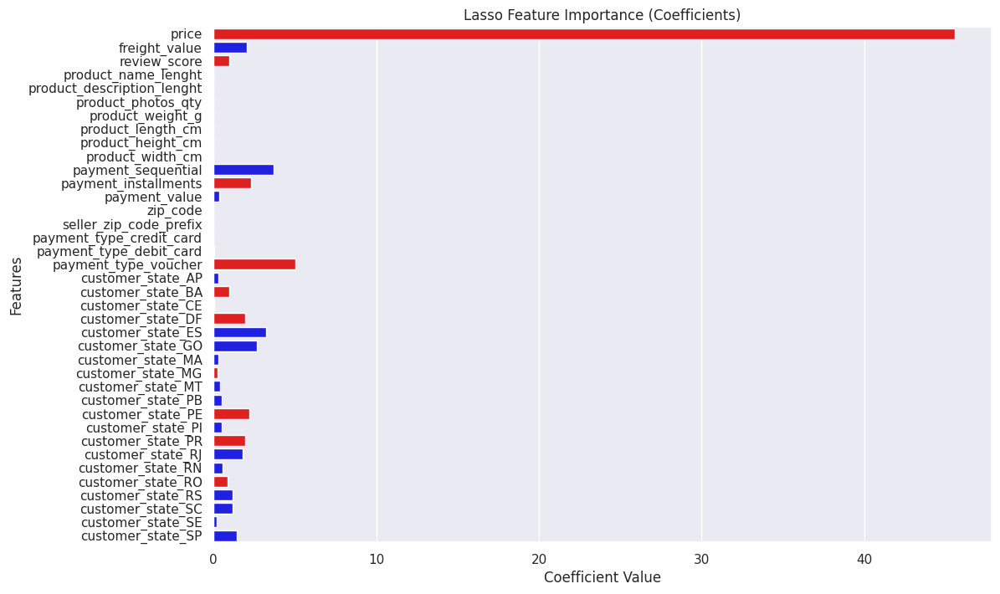

RF Feature Importances: {'price': np.float64(0.9994581682209313), 'freight_value': np.float64(0.0001000660463627257), 'review_score': np.float64(8.631720047149808e-07), 'product_name_lenght': np.float64(0.0), 'product_description_lenght': np.float64(0.0), 'product_photos_qty': np.float64(0.0), 'product_weight_g': np.float64(0.0), 'product_length_cm': np.float64(0.0), 'product_height_cm': np.float64(0.0), 'product_width_cm': np.float64(0.0), 'payment_sequential': np.float64(0.0), 'payment_installments': np.float64(2.0239728985721516e-05), 'payment_value': np.float64(0.00018937397866868264), 'zip_code': np.float64(6.0358665323876925e-05), 'seller_zip_code_prefix': np.float64(0.0), 'payment_type_credit_card': np.float64(1.8030528531729793e-07), 'payment_type_debit_card': np.float64(0.0), 'payment_type_voucher': np.float64(0.0), 'customer_state_AP': np.float64(0.0), 'customer_state_BA': np.float64(2.1773817302081804e-07), 'customer_state_CE': np.float64(0.0), 'customer_state_DF': np.float6

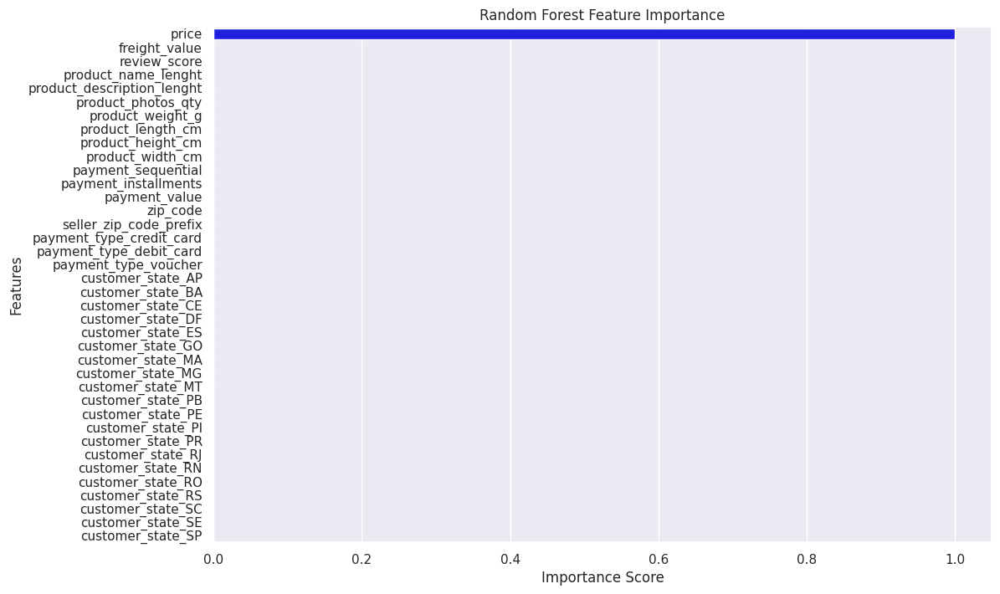

Permutation Importances: {'price': np.float64(1.9990547139951853), 'freight_value': np.float64(0.00010085595555962002), 'review_score': np.float64(4.42660296640085e-08), 'product_name_lenght': np.float64(0.0), 'product_description_lenght': np.float64(0.0), 'product_photos_qty': np.float64(0.0), 'product_weight_g': np.float64(0.0), 'product_length_cm': np.float64(0.0), 'product_height_cm': np.float64(0.0), 'product_width_cm': np.float64(0.0), 'payment_sequential': np.float64(0.0), 'payment_installments': np.float64(-1.5788854173703904e-05), 'payment_value': np.float64(0.0001158448365926379), 'zip_code': np.float64(4.69188068533688e-06), 'seller_zip_code_prefix': np.float64(0.0), 'payment_type_credit_card': np.float64(-3.248298583446996e-08), 'payment_type_debit_card': np.float64(0.0), 'payment_type_voucher': np.float64(0.0), 'customer_state_AP': np.float64(0.0), 'customer_state_BA': np.float64(7.3245948306599475e-09), 'customer_state_CE': np.float64(0.0), 'customer_state_DF': np.float64

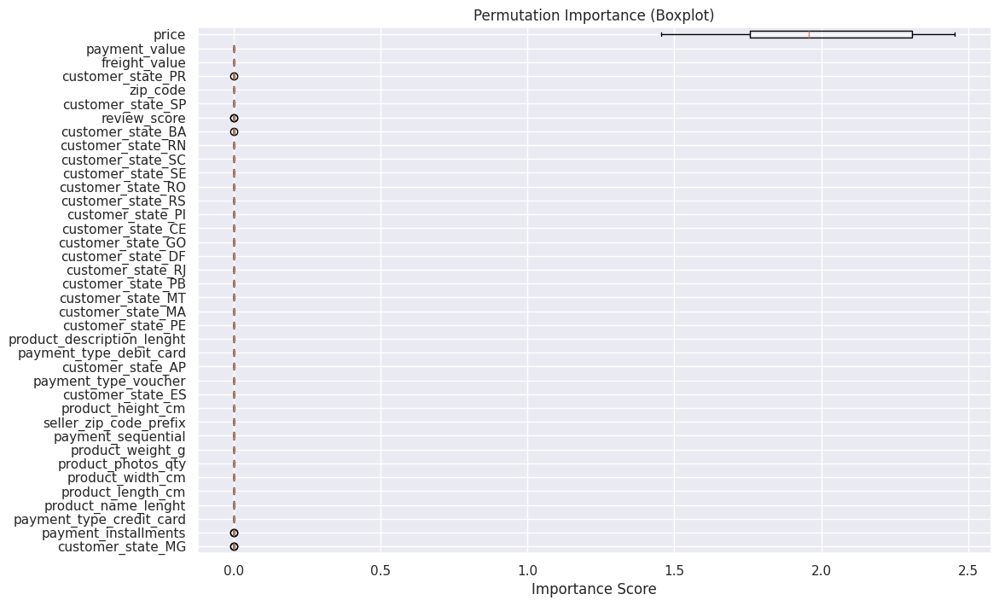

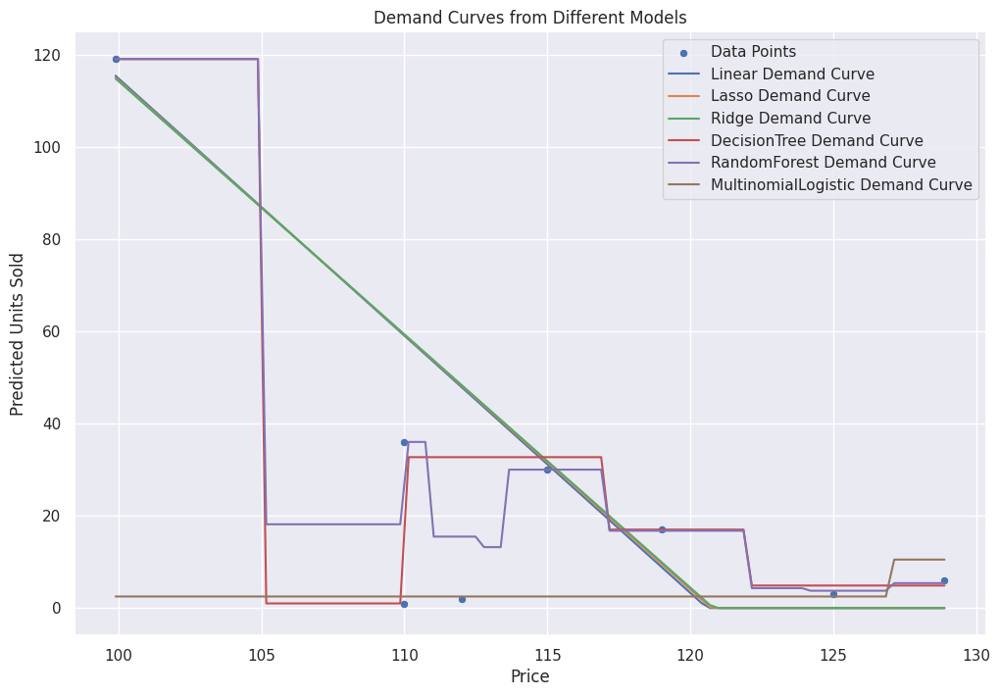

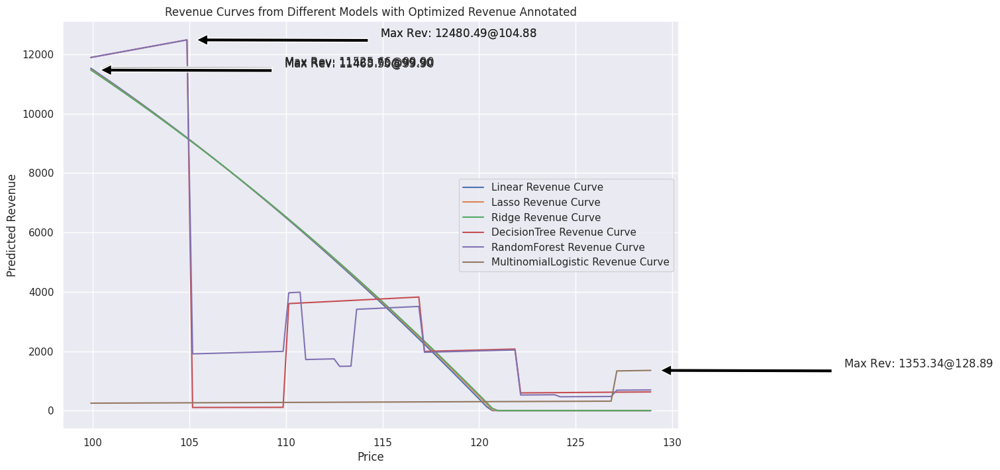

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Lasso, Ridge, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_squared_error
from sklearn.inspection import permutation_importance

# Step 1: Load and Clean Data
df = pd.read_csv('final_data.csv')

# Filter for delivered orders
df = df[df['order_status'] == 'delivered']

# Convert timestamp to datetime
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])

# Add year, month, year_month
df['year'] = df['order_purchase_timestamp'].dt.year
df['month'] = df['order_purchase_timestamp'].dt.month
df['year_month'] = df['order_purchase_timestamp'].dt.to_period('M')

# Step 2: EDA - Top Categories by Units and Revenue
category_units = df.groupby('product_category_name_english')['order_item_id'].count().sort_values(ascending=False)
category_revenue = df.groupby('product_category_name_english')['price'].sum().sort_values(ascending=False)

print("Top Categories by Units Sold:\n", category_units.head(10))
print("Top Categories by Revenue:\n", category_revenue.head(10))

# Select category: watches_gifts (top revenue generator with variation)
category = 'watches_gifts'
df_cat = df[df['product_category_name_english'] == category]

# Top product by units sold
top_product = df_cat['product_id'].value_counts().idxmax()
print("Top Product ID:", top_product)

df_prod = df_cat[df_cat['product_id'] == top_product]

# Top seller for this product
top_seller = df_prod['seller_id'].value_counts().idxmax()
print("Top Seller ID:", top_seller)

df_prod_seller = df_prod[df_prod['seller_id'] == top_seller]

# Compute units_sold per price (aggregate only count)
units_per_price = df_prod_seller.groupby('price')['order_item_id'].count().reset_index(name='units_sold')

# Merge back to keep original data points (larger dataset, 57 rows)
df_expanded = df_prod_seller.merge(units_per_price, on='price')

# Select original features (numeric + categoricals to encode; exclude NLP/text, IDs, dates)
selected_columns = [
    'price', 'freight_value', 'review_score', 'product_name_lenght', 'product_description_lenght',
    'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm',
    'payment_sequential', 'payment_installments', 'payment_value', 'zip_code', 'seller_zip_code_prefix',
    'payment_type', 'customer_state', 'units_sold'
]
df_expanded = df_expanded[selected_columns]

# One-hot encode categoricals
df_expanded = pd.get_dummies(df_expanded, columns=['payment_type', 'customer_state'], drop_first=True)

print("Expanded Data (with original features):\n", df_expanded)

# Step 3: Simple Demand Model (Units ~ Price) - Using aggregated for simple model
price_agg_simple = units_per_price.copy()  # For simple model, use aggregated prices
X_simple = price_agg_simple[['price']]
y_simple = price_agg_simple['units_sold']

model_simple = LinearRegression()
model_simple.fit(X_simple, y_simple)

print("Simple Model: units_sold = {:.2f} - {:.2f} * price".format(model_simple.intercept_, -model_simple.coef_[0]))
print("R-squared:", model_simple.score(X_simple, y_simple))

# Optimization for simple model
a = model_simple.intercept_
b = -model_simple.coef_[0]
optimal_price_simple = a / (2 * b)
optimal_units_simple = a - b * optimal_price_simple
optimal_revenue_simple = optimal_price_simple * optimal_units_simple

print("Simple Model Optimal Price: ${:.2f}".format(optimal_price_simple))

# Step 4: Multivariate Model with Original Features (no averaging, larger data)
features = [col for col in df_expanded.columns if col != 'units_sold']
X = df_expanded[features]
y = df_expanded['units_sold']

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Regression Models
reg_models = {
    'Linear': LinearRegression(),
    'Lasso': Lasso(alpha=0.1),
    'Ridge': Ridge(alpha=1.0),
    'DecisionTree': DecisionTreeRegressor(max_depth=3, random_state=42),
    'RandomForest': RandomForestRegressor(n_estimators=100, random_state=42)
}

reg_results = {}
for name, model in reg_models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    reg_results[name] = {'model': model, 'mse': mse}
    print(f"{name} MSE: {mse}")

# Add Multinomial Logistic Regression (Classification: bin units_sold)
# Bin y into categories: low (0-5), med (6-15), high (16+)
bins = [0, 5, 15, np.inf]
labels = ['low', 'med', 'high']
y_binned = pd.cut(y, bins=bins, labels=labels)
le = LabelEncoder()
y_encoded = le.fit_transform(y_binned)

# Split for classification
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(X_scaled, y_encoded, test_size=0.2, random_state=42)

log_model = LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=1000)
log_model.fit(X_train_clf, y_train_clf)

# For MSE, predict and map back to midpoints for approximation
midpoints = [2.5, 10.5, 20]  # Approx mid for bins
y_pred_clf = log_model.predict(X_test_clf)
y_pred_reg_approx = [midpoints[p] for p in y_pred_clf]
mse_clf = mean_squared_error(y_test, y_pred_reg_approx)  # Approx regression MSE
print(f"Multinomial Logistic (Approx) MSE: {mse_clf}")

# Feature Importance for Lasso (with colored bars: positive blue, negative red)
lasso_model = reg_models['Lasso']
if hasattr(lasso_model, 'coef_'):
    print("Lasso Coefficients:", dict(zip(features, lasso_model.coef_)))

    # Create colors based on sign
    lasso_colors = ['blue' if c > 0 else 'red' for c in lasso_model.coef_]

    plt.figure(figsize=(12, 8))
    sns.barplot(x=abs(lasso_model.coef_), y=features, palette=lasso_colors)
    plt.title('Lasso Feature Importance (Coefficients)')
    plt.xlabel('Coefficient Value')
    plt.ylabel('Features')
    plt.show()

# Feature Importance for Random Forest (all positive, so blue; but check for any negatives though unlikely)
rf_model = reg_models['RandomForest']
if hasattr(rf_model, 'feature_importances_'):
    print("RF Feature Importances:", dict(zip(features, rf_model.feature_importances_)))

    # Colors: positive blue, negative red (though RF importances >=0)
    rf_colors = ['blue' if i > 0 else 'red' for i in rf_model.feature_importances_]

    plt.figure(figsize=(12, 8))
    sns.barplot(x=rf_model.feature_importances_, y=features, palette=rf_colors)
    plt.title('Random Forest Feature Importance')
    plt.xlabel('Importance Score')
    plt.ylabel('Features')
    plt.show()

# Permutation Importance for Random Forest (can be negative)
perm_importance = permutation_importance(rf_model, X_test, y_test, n_repeats=10, random_state=42)
print("Permutation Importances:", dict(zip(features, perm_importance.importances_mean)))

sorted_idx = perm_importance.importances_mean.argsort()
plt.figure(figsize=(12, 8))
plt.boxplot(perm_importance.importances[sorted_idx].T, vert=False, labels=np.array(features)[sorted_idx])
plt.title('Permutation Importance (Boxplot)')
plt.xlabel('Importance Score')
plt.show()

# Step 5: Demand Curves from Different Models
# To plot demand curves, vary price while holding other features at mean
mean_features = df_expanded[features].mean().values
price_range = np.linspace(df_expanded['price'].min(), df_expanded['price'].max(), 100)

plt.figure(figsize=(12, 8))
sns.scatterplot(x='price', y='units_sold', data=df_expanded, label='Data Points')

models_for_plot = {**reg_models, 'MultinomialLogistic': log_model}

for name, model in models_for_plot.items():
    units_preds = []
    for p in price_range:
        input_features = mean_features.copy()
        input_features[features.index('price')] = p  # Replace price
        input_scaled = scaler.transform([input_features])
        if name == 'MultinomialLogistic':
            pred_clf = model.predict(input_scaled)[0]
            pred = midpoints[pred_clf]
        else:
            pred = model.predict(input_scaled)[0]
        units_preds.append(max(pred, 0))  # Clip negative
    plt.plot(price_range, units_preds, label=f'{name} Demand Curve')

plt.title('Demand Curves from Different Models')
plt.xlabel('Price')
plt.ylabel('Predicted Units Sold')
plt.legend()
plt.show()

# Step 6: Revenue Curves with Optimized Revenue Annotated
plt.figure(figsize=(12, 8))

for name, model in models_for_plot.items():
    revenues = []
    for p in price_range:
        input_features = mean_features.copy()
        input_features[features.index('price')] = p
        input_scaled = scaler.transform([input_features])
        if name == 'MultinomialLogistic':
            pred_clf = model.predict(input_scaled)[0]
            pred = midpoints[pred_clf]
        else:
            pred = model.predict(input_scaled)[0]
        rev = p * max(pred, 0)
        revenues.append(rev)

    plt.plot(price_range, revenues, label=f'{name} Revenue Curve')

    # Find and annotate max revenue
    max_idx = np.argmax(revenues)
    max_price = price_range[max_idx]
    max_rev = revenues[max_idx]
    plt.annotate(f'Max Rev: ${max_rev:.2f} @ ${max_price:.2f}',
                 xy=(max_price, max_rev), xytext=(max_price + 10, max_rev + 100),
                 arrowprops=dict(facecolor='black', shrink=0.05))

plt.title('Revenue Curves from Different Models with Optimized Revenue Annotated')
plt.xlabel('Price')
plt.ylabel('Predicted Revenue')
plt.legend()
plt.show()

In [ ]:
X

,price,freight_value,review_score,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,...,customer_state_PE,customer_state_PI,customer_state_PR,customer_state_RJ,customer_state_RN,customer_state_RO,customer_state_RS,customer_state_SC,customer_state_SE,customer_state_SP
0,110.0,1.97,1,33,523,3,584.0,16.0,11.0,13.0,...,True,False,False,False,False,False,False,False,False,False
1,119.0,2.11,3,33,523,3,584.0,16.0,11.0,13.0,...,False,False,False,True,False,False,False,False,False,False
2,99.9,0.00,4,33,523,3,584.0,16.0,11.0,13.0,...,False,False,False,True,False,False,False,False,False,False
3,110.0,0.00,4,33,523,3,584.0,16.0,11.0,13.0,...,False,False,False,False,False,False,False,False,False,False
4,99.9,0.00,5,33,523,3,584.0,16.0,11.0,13.0,...,False,True,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
209,99.9,0.00,5,33,523,3,584.0,16.0,11.0,13.0,...,False,False,False,False,False,False,False,False,False,False
210,119.0,13.49,4,33,523,3,584.0,16.0,11.0,13.0,...,False,False,False,False,False,False,False,False,False,True
211,110.0,13.21,3,33,523,3,584.0,16.0,11.0,13.0,...,False,False,False,False,False,False,False,False,False,True
212,99.9,0.00,5,33,523,3,584.0,16.0,11.0,13.0,...,False,False,False,True,False,False,False,False,False,False


Top Categories by Units Sold:
 product_category_name_english
bed_bath_table           1203
health_beauty            1107
watches_gifts             935
housewares                932
sports_leisure            738
furniture_decor           722
computers_accessories     706
auto                      555
telephony                 440
garden_tools              380
Name: order_item_id, dtype: int64
Top Categories by Revenue:
 product_category_name_english
watches_gifts            179990.73
health_beauty            144658.38
bed_bath_table           109841.17
housewares                95829.70
auto                      91948.03
computers_accessories     84899.97
sports_leisure            81542.78
furniture_decor           73498.01
baby                      53187.69
garden_tools              47094.61
Name: price, dtype: float64
Expanded Data (with original features, all categories/sellers):
         price  freight_value  review_score  product_name_lenght  \
0       17.37           7.39         

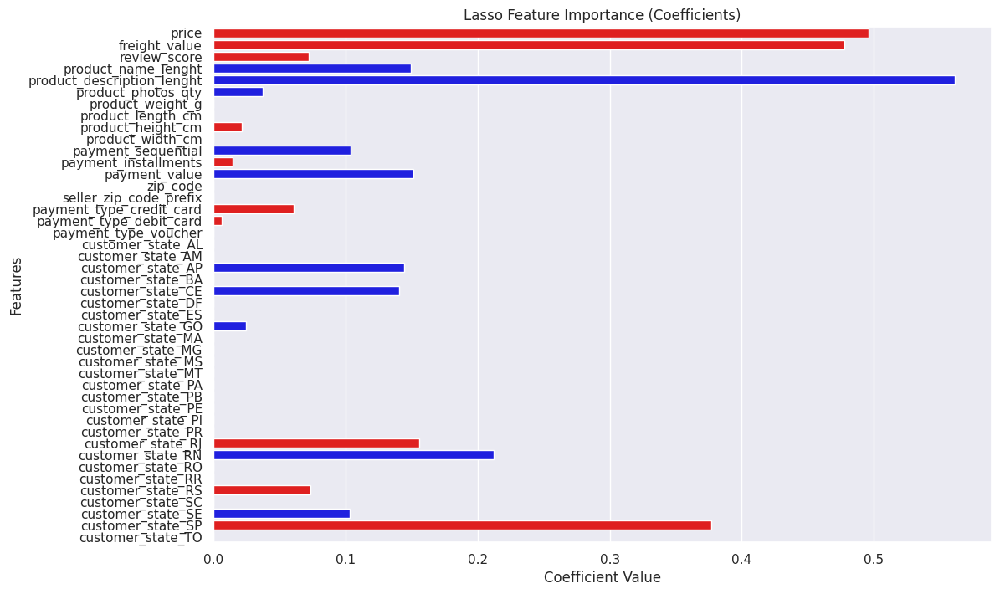

RF Feature Importances: {'price': np.float64(0.22008347725084323), 'freight_value': np.float64(0.15319884704593192), 'review_score': np.float64(0.001732031678067501), 'product_name_lenght': np.float64(0.05759271381226944), 'product_description_lenght': np.float64(0.1651675673256949), 'product_photos_qty': np.float64(0.02309741456890215), 'product_weight_g': np.float64(0.054664786386791765), 'product_length_cm': np.float64(0.03122695026347176), 'product_height_cm': np.float64(0.07609163287062133), 'product_width_cm': np.float64(0.0317127776383104), 'payment_sequential': np.float64(0.0008579099448611452), 'payment_installments': np.float64(0.0020271733325847503), 'payment_value': np.float64(0.01975925909660147), 'zip_code': np.float64(0.005106584753530137), 'seller_zip_code_prefix': np.float64(0.15095146157526285), 'payment_type_credit_card': np.float64(0.00046744816899798057), 'payment_type_debit_card': np.float64(0.00021791834329412834), 'payment_type_voucher': np.float64(0.00033964451

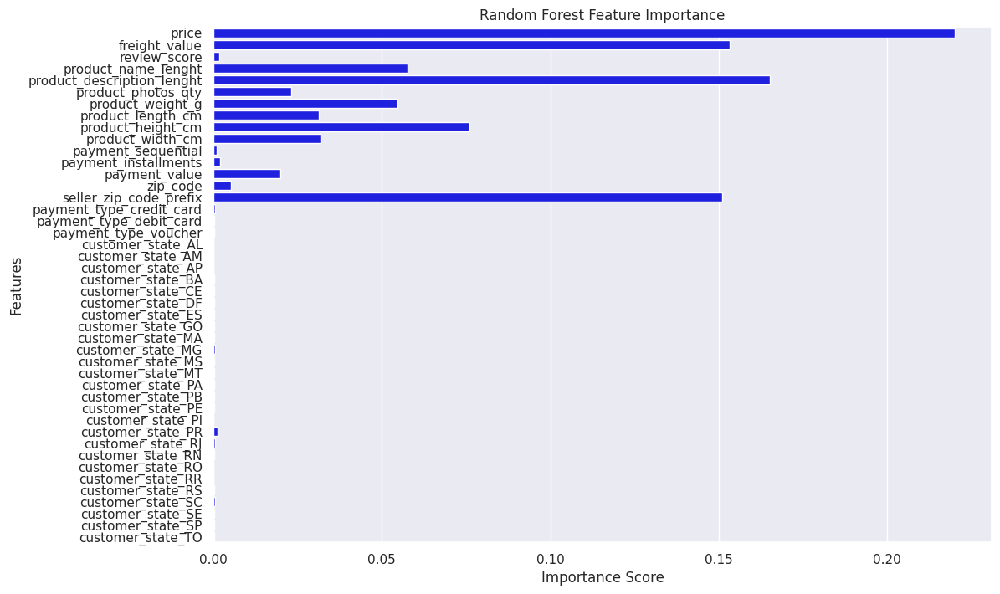

Permutation Importances: {'price': np.float64(0.4244085622180598), 'freight_value': np.float64(0.11542347764220337), 'review_score': np.float64(0.0004542661369775436), 'product_name_lenght': np.float64(0.1254953062002482), 'product_description_lenght': np.float64(0.5122962391220349), 'product_photos_qty': np.float64(0.03382930373538938), 'product_weight_g': np.float64(0.1333579906197476), 'product_length_cm': np.float64(0.03509048823062062), 'product_height_cm': np.float64(0.2585964564199112), 'product_width_cm': np.float64(0.03929077941351129), 'payment_sequential': np.float64(0.0003115014958290918), 'payment_installments': np.float64(0.0010867588157447484), 'payment_value': np.float64(0.02189354154077274), 'zip_code': np.float64(0.0012839240497519167), 'seller_zip_code_prefix': np.float64(0.26618333687710705), 'payment_type_credit_card': np.float64(-6.8601510515908796e-06), 'payment_type_debit_card': np.float64(1.6566830992936764e-06), 'payment_type_voucher': np.float64(0.00020225534

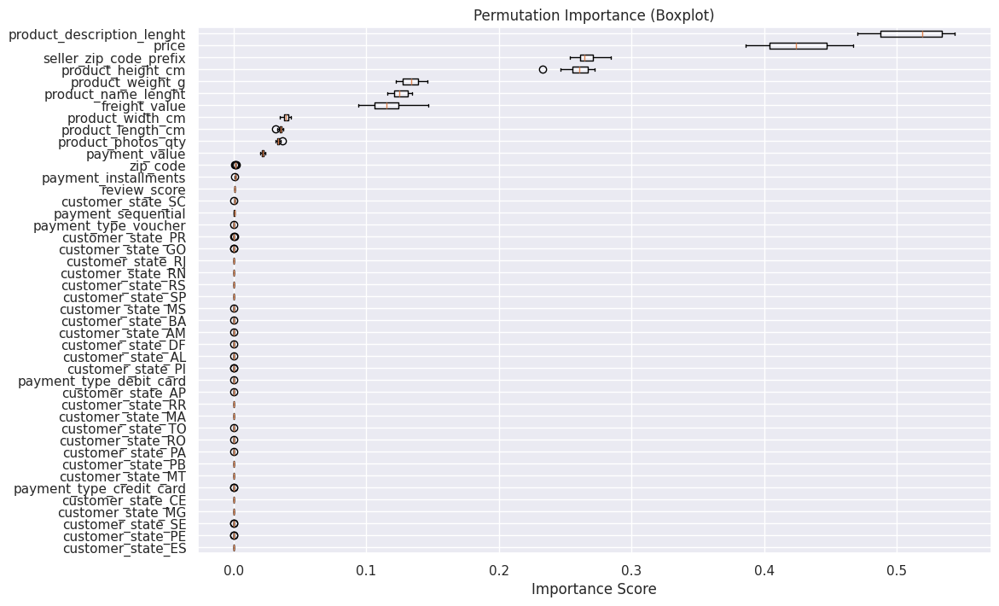

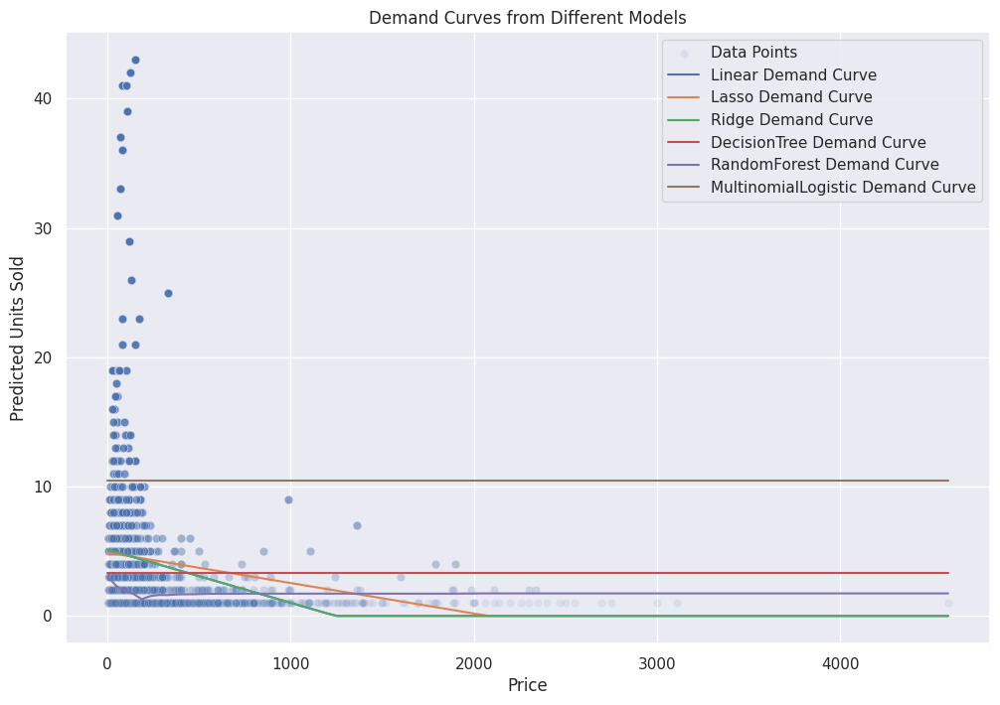

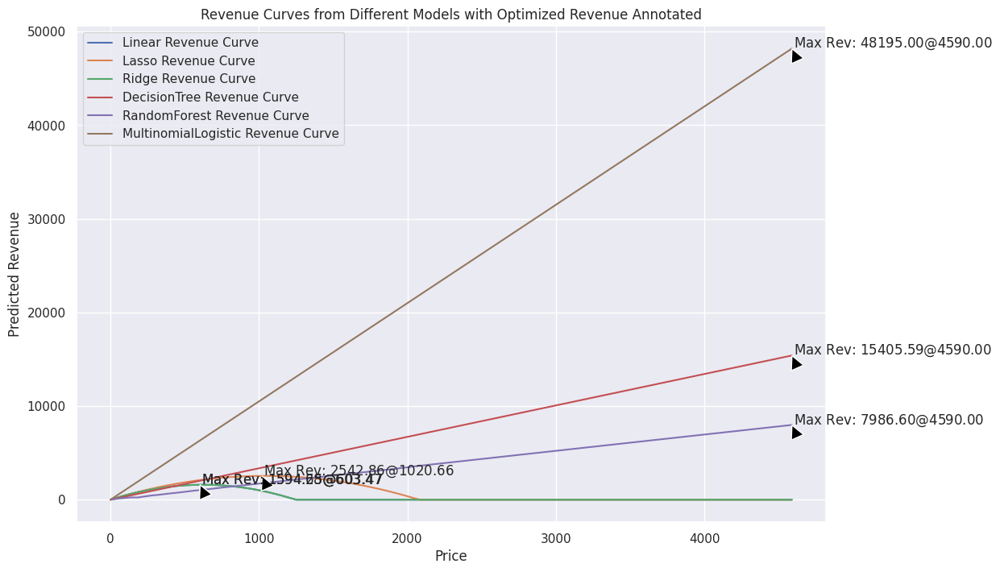

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Lasso, Ridge, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_squared_error
from sklearn.inspection import permutation_importance

# Step 1: Load and Clean Data
df = pd.read_csv('final_data.csv')
df=df.dropna()
# Filter for delivered orders
df = df[df['order_status'] == 'delivered']

# Convert timestamp to datetime
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])

# Add year, month, year_month
df['year'] = df['order_purchase_timestamp'].dt.year
df['month'] = df['order_purchase_timestamp'].dt.month
df['year_month'] = df['order_purchase_timestamp'].dt.to_period('M')

# Step 2: EDA - Top Categories by Units and Revenue (still show for info)
category_units = df.groupby('product_category_name_english')['order_item_id'].count().sort_values(ascending=False)
category_revenue = df.groupby('product_category_name_english')['price'].sum().sort_values(ascending=False)

print("Top Categories by Units Sold:\n", category_units.head(10))
print("Top Categories by Revenue:\n", category_revenue.head(10))

# No filtering to specific category/product/seller - use all

# Compute units_sold per product-seller-price group
units_per_group = df.groupby(['product_id', 'seller_id', 'price'])['order_item_id'].count().reset_index(name='units_sold')

# Merge back to keep original data points (larger dataset, ~113k rows)
df_expanded = df.merge(units_per_group, on=['product_id', 'seller_id', 'price'])

# Select original features (numeric + categoricals to encode; exclude NLP/text, IDs, dates)
selected_columns = [
    'price', 'freight_value', 'review_score', 'product_name_lenght', 'product_description_lenght',
    'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm',
    'payment_sequential', 'payment_installments', 'payment_value', 'zip_code', 'seller_zip_code_prefix',
    'payment_type', 'customer_state', 'units_sold'
]
df_expanded = df_expanded[selected_columns]

# One-hot encode categoricals
df_expanded = pd.get_dummies(df_expanded, columns=['payment_type', 'customer_state'], drop_first=True)

print("Expanded Data (with original features, all categories/sellers):\n", df_expanded)

# Step 3: Simple Demand Model (Units ~ Price) - Aggregate total units per price across all
price_agg_simple = units_per_group.groupby('price')['units_sold'].sum().reset_index()
X_simple = price_agg_simple[['price']]
y_simple = price_agg_simple['units_sold']

model_simple = LinearRegression()
model_simple.fit(X_simple, y_simple)

print("Simple Model: units_sold = {:.2f} - {:.2f} * price".format(model_simple.intercept_, -model_simple.coef_[0]))
print("R-squared:", model_simple.score(X_simple, y_simple))

# Optimization for simple model
a = model_simple.intercept_
b = -model_simple.coef_[0]
optimal_price_simple = a / (2 * b)
optimal_units_simple = a - b * optimal_price_simple
optimal_revenue_simple = optimal_price_simple * optimal_units_simple

print("Simple Model Optimal Price: ${:.2f}".format(optimal_price_simple))

# Step 4: Multivariate Model with Original Features (no averaging, larger data)
features = [col for col in df_expanded.columns if col != 'units_sold']
X = df_expanded[features]
y = df_expanded['units_sold']

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Regression Models
reg_models = {
    'Linear': LinearRegression(),
    'Lasso': Lasso(alpha=0.1),
    'Ridge': Ridge(alpha=1.0),
    'DecisionTree': DecisionTreeRegressor(max_depth=3, random_state=42),
    'RandomForest': RandomForestRegressor(n_estimators=100, random_state=42)
}

reg_results = {}
for name, model in reg_models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    reg_results[name] = {'model': model, 'mse': mse}
    print(f"{name} MSE: {mse}")

# Add Multinomial Logistic Regression (Classification: bin units_sold)
# Bin y into categories: low (0-5), med (6-15), high (16+)
bins = [0, 5, 15, np.inf]
labels = ['low', 'med', 'high']
y_binned = pd.cut(y, bins=bins, labels=labels)
le = LabelEncoder()
y_encoded = le.fit_transform(y_binned)

# Split for classification
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(X_scaled, y_encoded, test_size=0.2, random_state=42)

log_model = LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=1000)
log_model.fit(X_train_clf, y_train_clf)

# For MSE, predict and map back to midpoints for approximation
midpoints = [2.5, 10.5, 20]  # Approx mid for bins
y_pred_clf = log_model.predict(X_test_clf)
y_pred_reg_approx = [midpoints[p] for p in y_pred_clf]
mse_clf = mean_squared_error(y_test, y_pred_reg_approx)  # Approx regression MSE
print(f"Multinomial Logistic (Approx) MSE: {mse_clf}")

# Feature Importance for Lasso (with colored bars: positive blue, negative red)
lasso_model = reg_models['Lasso']
if hasattr(lasso_model, 'coef_'):
    print("Lasso Coefficients:", dict(zip(features, lasso_model.coef_)))

    # Create colors based on sign
    lasso_colors = ['blue' if c > 0 else 'red' for c in lasso_model.coef_]

    plt.figure(figsize=(12, 8))
    sns.barplot(x=abs(lasso_model.coef_), y=features, palette=lasso_colors)
    plt.title('Lasso Feature Importance (Coefficients)')
    plt.xlabel('Coefficient Value')
    plt.ylabel('Features')
    plt.show()

# Feature Importance for Random Forest (all positive, so blue; but check for any negatives though unlikely)
rf_model = reg_models['RandomForest']
if hasattr(rf_model, 'feature_importances_'):
    print("RF Feature Importances:", dict(zip(features, rf_model.feature_importances_)))

    # Colors: positive blue, negative red (though RF importances >=0)
    rf_colors = ['blue' if i > 0 else 'red' for i in rf_model.feature_importances_]

    plt.figure(figsize=(12, 8))
    sns.barplot(x=rf_model.feature_importances_, y=features, palette=rf_colors)
    plt.title('Random Forest Feature Importance')
    plt.xlabel('Importance Score')
    plt.ylabel('Features')
    plt.show()

# Permutation Importance for Random Forest (can be negative)
perm_importance = permutation_importance(rf_model, X_test, y_test, n_repeats=10, random_state=42)
print("Permutation Importances:", dict(zip(features, perm_importance.importances_mean)))

sorted_idx = perm_importance.importances_mean.argsort()
plt.figure(figsize=(12, 8))
plt.boxplot(perm_importance.importances[sorted_idx].T, vert=False, labels=np.array(features)[sorted_idx])
plt.title('Permutation Importance (Boxplot)')
plt.xlabel('Importance Score')
plt.show()

# Step 5: Demand Curves from Different Models
# To plot demand curves, vary price while holding other features at mean
mean_features = df_expanded[features].mean().values
price_range = np.linspace(df_expanded['price'].min(), df_expanded['price'].max(), 100)

plt.figure(figsize=(12, 8))
sns.scatterplot(x='price', y='units_sold', data=df_expanded, label='Data Points', alpha=0.1)  # Alpha for large data

models_for_plot = {**reg_models, 'MultinomialLogistic': log_model}

for name, model in models_for_plot.items():
    units_preds = []
    for p in price_range:
        input_features = mean_features.copy()
        input_features[features.index('price')] = p  # Replace price
        input_scaled = scaler.transform([input_features])
        if name == 'MultinomialLogistic':
            pred_clf = model.predict(input_scaled)[0]
            pred = midpoints[pred_clf]
        else:
            pred = model.predict(input_scaled)[0]
        units_preds.append(max(pred, 0))  # Clip negative
    plt.plot(price_range, units_preds, label=f'{name} Demand Curve')

plt.title('Demand Curves from Different Models')
plt.xlabel('Price')
plt.ylabel('Predicted Units Sold')
plt.legend()
plt.show()

# Step 6: Revenue Curves with Optimized Revenue Annotated
plt.figure(figsize=(12, 8))

for name, model in models_for_plot.items():
    revenues = []
    for p in price_range:
        input_features = mean_features.copy()
        input_features[features.index('price')] = p
        input_scaled = scaler.transform([input_features])
        if name == 'MultinomialLogistic':
            pred_clf = model.predict(input_scaled)[0]
            pred = midpoints[pred_clf]
        else:
            pred = model.predict(input_scaled)[0]
        rev = p * max(pred, 0)
        revenues.append(rev)

    plt.plot(price_range, revenues, label=f'{name} Revenue Curve')

    # Find and annotate max revenue
    max_idx = np.argmax(revenues)
    max_price = price_range[max_idx]
    max_rev = revenues[max_idx]
    plt.annotate(f'Max Rev: ${max_rev:.2f} @ ${max_price:.2f}',
                 xy=(max_price, max_rev), xytext=(max_price + 10, max_rev + 100),
                 arrowprops=dict(facecolor='black', shrink=0.05))

plt.title('Revenue Curves from Different Models with Optimized Revenue Annotated')
plt.xlabel('Price')
plt.ylabel('Predicted Revenue')
plt.legend()
plt.show()

'Top Categories by Units Sold:\n'

,order_item_id
product_category_name_english,
bed_bath_table,11685
health_beauty,9747
sports_leisure,8736
furniture_decor,8558
computers_accessories,7927
housewares,7154
watches_gifts,6032
telephony,4580
garden_tools,4452


'Top Categories by Revenue:\n'

,price
product_category_name_english,
health_beauty,1266992.59
watches_gifts,1207633.40
bed_bath_table,1082024.32
sports_leisure,989781.66
computers_accessories,922593.78
furniture_decor,746811.14
housewares,646232.97
cool_stuff,628528.54
auto,594994.54


'Top Product ID:'

'53b36df67ebb7c41585e8d54d6772e08'

'Top Seller ID:'

'7d13fca15225358621be4086e1eb0964'

'Aggregated Data:\n'

,price,units_sold,avg_freight,avg_review,avg_name_len,avg_desc_len,avg_photos,avg_weight,avg_length_cm,avg_height_cm,avg_width_cm,avg_payment_seq,avg_installments,avg_payment_value,avg_zip_code,avg_seller_zip
0,99.90,119,0.000000,4.386555,33.0,523.0,3.0,584.0,16.0,11.0,13.0,1.000000,2.974790,130.121849,33145.731092,14050.0
1,109.99,1,0.000000,5.000000,33.0,523.0,3.0,584.0,16.0,11.0,13.0,1.000000,2.000000,109.990000,80710.000000,14050.0
2,110.00,36,3.343611,4.222222,33.0,523.0,3.0,584.0,16.0,11.0,13.0,1.027778,3.444444,119.568611,37524.555556,14050.0
3,112.00,2,13.440000,5.000000,33.0,523.0,3.0,584.0,16.0,11.0,13.0,1.000000,4.000000,125.440000,21287.000000,14050.0
4,115.00,30,12.043000,4.133333,33.0,523.0,3.0,584.0,16.0,11.0,13.0,1.000000,2.766667,134.709667,30296.833333,14050.0
5,119.00,17,17.447059,4.588235,33.0,523.0,3.0,584.0,16.0,11.0,13.0,1.058824,3.117647,131.441765,35549.117647,14050.0
6,125.00,3,14.016667,3.666667,33.0,523.0,3.0,584.0,16.0,11.0,13.0,1.000000,1.666667,139.016667,22005.333333,14050.0
7,128.89,6,15.108333,4.500000,33.0,523.0,3.0,584.0,16.0,11.0,13.0,1.166667,2.333333,119.908333,53701.333333,14050.0


Simple Model: units_sold = 374.09 - 3.02 * price
R-squared: 0.495834664280701
Simple Model Optimal Price: $61.91
Linear MSE: 6469.947726619406
Lasso MSE: 2219.3993510563428
Ridge MSE: 4522.773774727376
DecisionTree MSE: 717.625
RandomForest MSE: 1439.20465
Multinomial Logistic (Approx) MSE: 22.25
Lasso Coefficients: {'price': np.float64(-56.6133634105971), 'avg_freight': np.float64(-0.0), 'avg_review': np.float64(1.2293263741927238), 'avg_name_len': np.float64(0.0), 'avg_desc_len': np.float64(0.0), 'avg_photos': np.float64(0.0), 'avg_weight': np.float64(0.0), 'avg_length_cm': np.float64(0.0), 'avg_height_cm': np.float64(0.0), 'avg_width_cm': np.float64(0.0), 'avg_payment_seq': np.float64(21.491957085931666), 'avg_installments': np.float64(-23.91904793293613), 'avg_payment_value': np.float64(8.266683606807838), 'avg_zip_code': np.float64(0.0), 'avg_seller_zip': np.float64(0.0)}


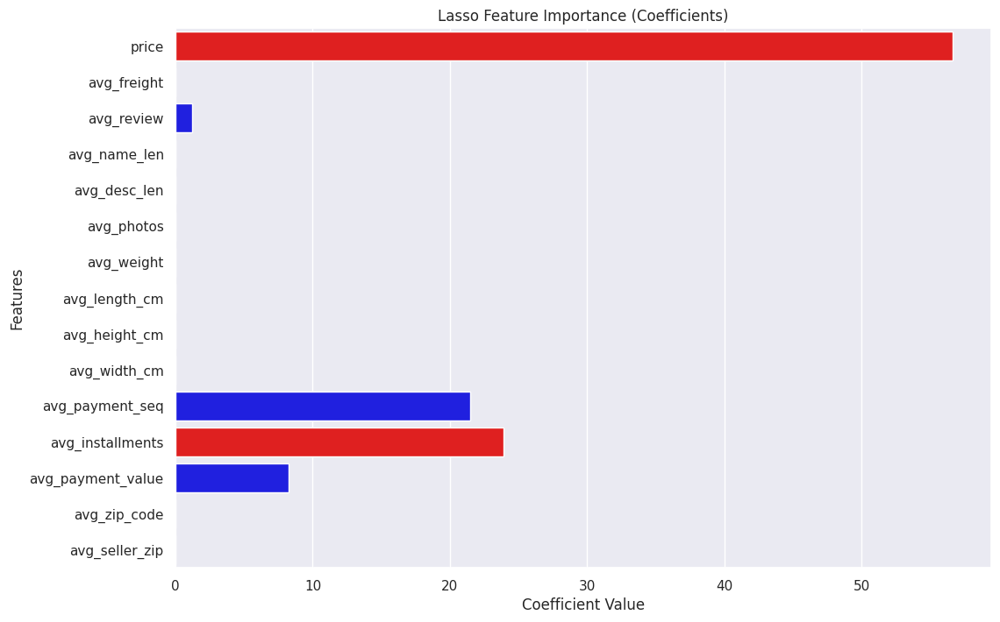

RF Feature Importances: {'price': np.float64(0.32723140357635383), 'avg_freight': np.float64(0.379240793162096), 'avg_review': np.float64(0.049018995430238396), 'avg_name_len': np.float64(0.0), 'avg_desc_len': np.float64(0.0), 'avg_photos': np.float64(0.0), 'avg_weight': np.float64(0.0), 'avg_length_cm': np.float64(0.0), 'avg_height_cm': np.float64(0.0), 'avg_width_cm': np.float64(0.0), 'avg_payment_seq': np.float64(0.012325591307343944), 'avg_installments': np.float64(0.09504654604196347), 'avg_payment_value': np.float64(0.05388699813589221), 'avg_zip_code': np.float64(0.08324967234611218), 'avg_seller_zip': np.float64(0.0)}


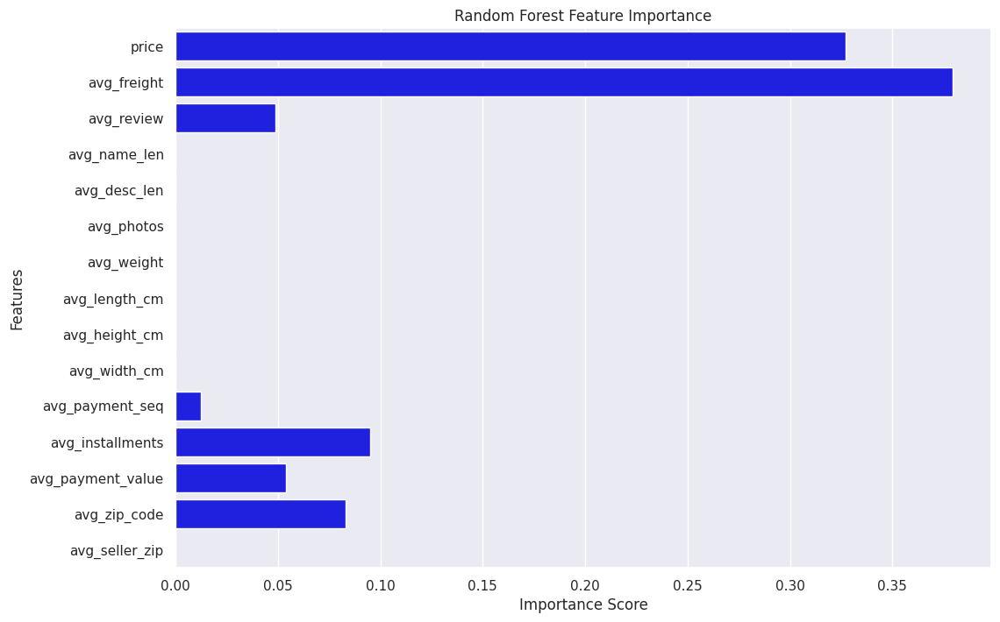

Permutation Importances: {'price': np.float64(-0.5009983593749983), 'avg_freight': np.float64(-1.3354181250000003), 'avg_review': np.float64(0.042912187500001406), 'avg_name_len': np.float64(0.0), 'avg_desc_len': np.float64(0.0), 'avg_photos': np.float64(0.0), 'avg_weight': np.float64(0.0), 'avg_length_cm': np.float64(0.0), 'avg_height_cm': np.float64(0.0), 'avg_width_cm': np.float64(0.0), 'avg_payment_seq': np.float64(0.04683562500000029), 'avg_installments': np.float64(1.576420078125001), 'avg_payment_value': np.float64(0.43405570312500075), 'avg_zip_code': np.float64(0.015852421875001), 'avg_seller_zip': np.float64(0.0)}


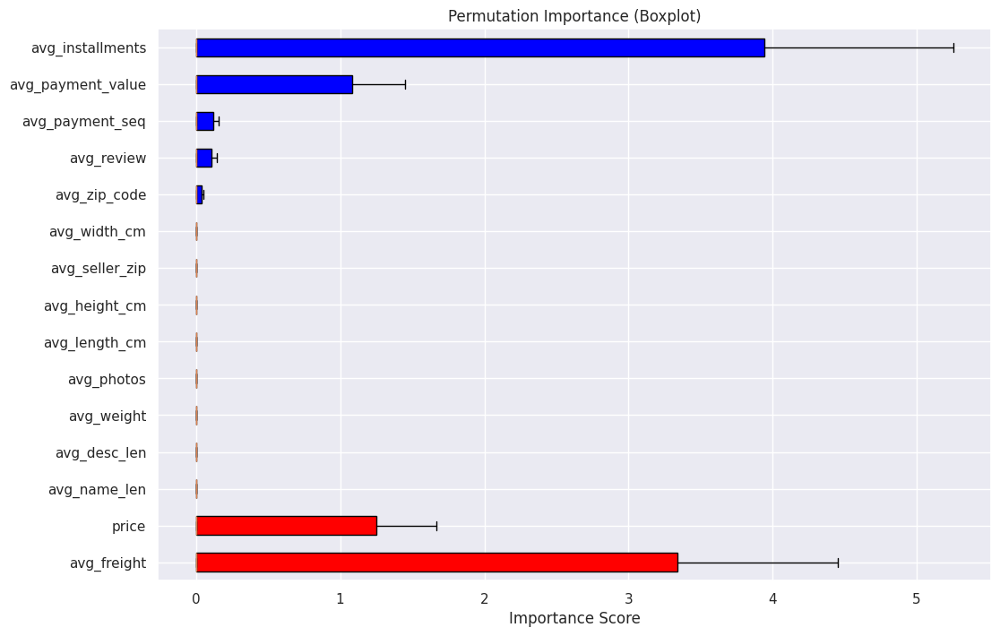

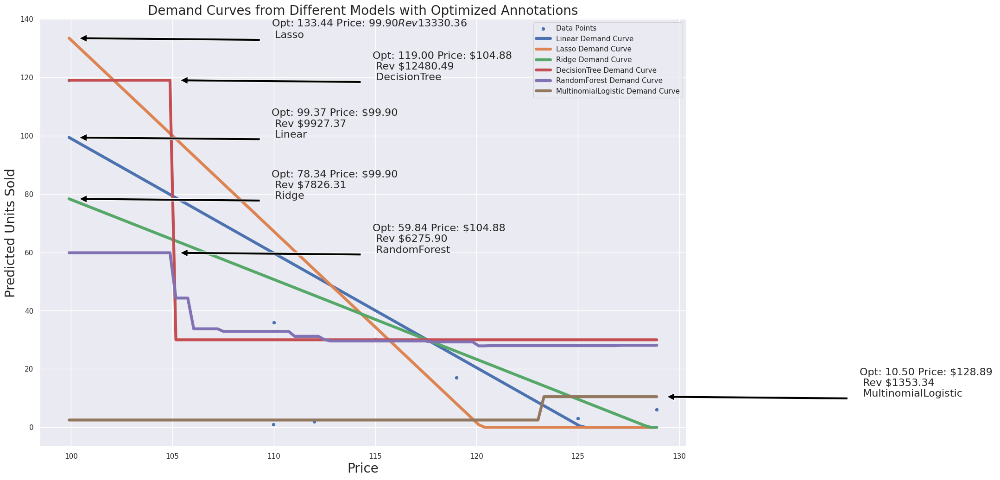

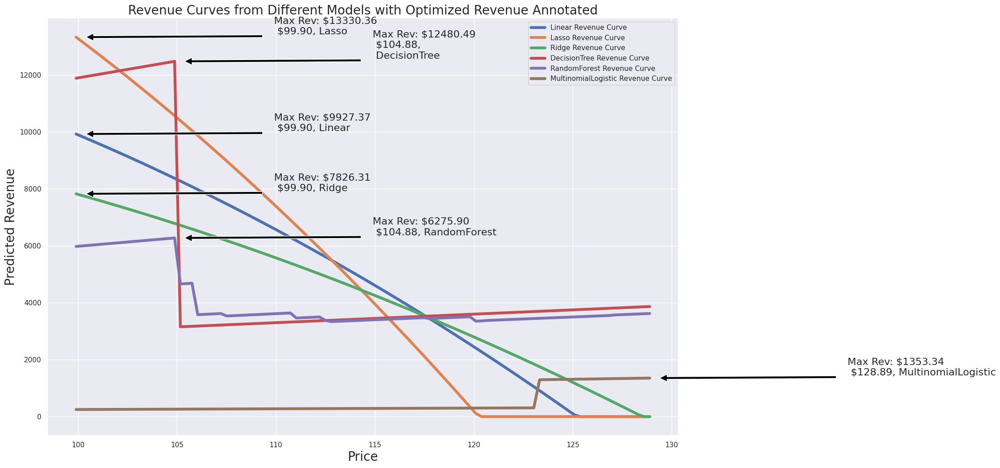

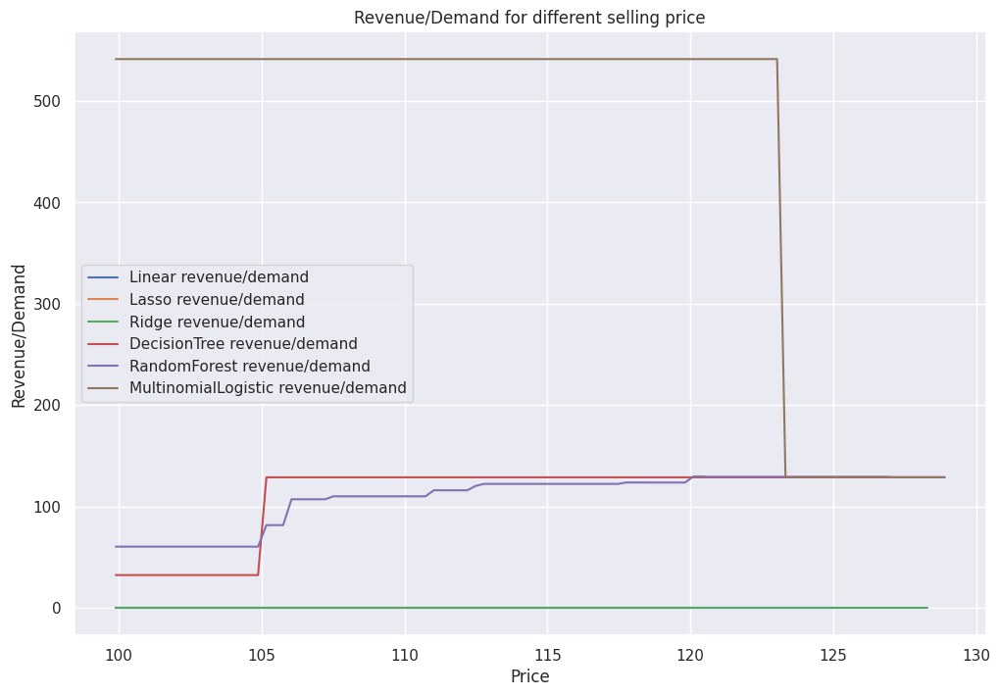

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Lasso, Ridge, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_squared_error
from sklearn.inspection import permutation_importance

# Step 1: Load and Clean Data
df = pd.read_csv('final_data.csv')

# Filter for delivered orders
df = df[df['order_status'] == 'delivered']

# Convert timestamp to datetime
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])

# Add year, month, year_month
df['year'] = df['order_purchase_timestamp'].dt.year
df['month'] = df['order_purchase_timestamp'].dt.month
df['year_month'] = df['order_purchase_timestamp'].dt.to_period('M')

# Step 2: EDA - Top Categories by Units and Revenue
category_units = df.groupby('product_category_name_english')['order_item_id'].count().sort_values(ascending=False)
category_revenue = df.groupby('product_category_name_english')['price'].sum().sort_values(ascending=False)

display("Top Categories by Units Sold:\n", category_units.head(10))
display("Top Categories by Revenue:\n", category_revenue.head(10))

# Select category: watches_gifts (top revenue generator with variation)
category = 'watches_gifts'
df_cat = df[df['product_category_name_english'] == category]

# Top product by units sold
top_product = df_cat['product_id'].value_counts().idxmax()
display("Top Product ID:", top_product)

df_prod = df_cat[df_cat['product_id'] == top_product]

# Top seller for this product
top_seller = df_prod['seller_id'].value_counts().idxmax()
display("Top Seller ID:", top_seller)

df_prod_seller = df_prod[df_prod['seller_id'] == top_seller]

# Aggregate units sold per unique price point, including more features (all numeric except NLP)
# Exclude review_comment_title and review_comment_message as NLP
price_agg = df_prod_seller.groupby('price').agg(
    units_sold=('order_item_id', 'count'),
    avg_freight=('freight_value', 'mean'),
    avg_review=('review_score', 'mean'),
    avg_name_len=('product_name_lenght', 'mean'),
    avg_desc_len=('product_description_lenght', 'mean'),
    avg_photos=('product_photos_qty', 'mean'),
    avg_weight=('product_weight_g', 'mean'),
    avg_length_cm=('product_length_cm', 'mean'),
    avg_height_cm=('product_height_cm', 'mean'),
    avg_width_cm=('product_width_cm', 'mean'),
    avg_payment_seq=('payment_sequential', 'mean'),
    avg_installments=('payment_installments', 'mean'),
    avg_payment_value=('payment_value', 'mean'),
    avg_zip_code=('zip_code', 'mean'),
    avg_seller_zip=('seller_zip_code_prefix', 'mean')
).reset_index()

# For categoricals, add mode for payment_type and customer_state
price_agg['mode_payment_type'] = df_prod_seller.groupby('price')['payment_type'].apply(lambda x: x.mode()[0] if not x.empty else np.nan)
price_agg['mode_customer_state'] = df_prod_seller.groupby('price')['customer_state'].apply(lambda x: x.mode()[0] if not x.empty else np.nan)

# One-hot encode categoricals
price_agg = pd.get_dummies(price_agg, columns=['mode_payment_type', 'mode_customer_state'], drop_first=True)

display("Aggregated Data:\n", price_agg)

# Step 3: Simple Demand Model (Units ~ Price)
X_simple = price_agg[['price']]
y = price_agg['units_sold']

model_simple = LinearRegression()
model_simple.fit(X_simple, y)

print("Simple Model: units_sold = {:.2f} - {:.2f} * price".format(model_simple.intercept_, -model_simple.coef_[0]))
print("R-squared:", model_simple.score(X_simple, y))

# Optimization for simple model
a = model_simple.intercept_
b = -model_simple.coef_[0]
optimal_price_simple = a / (2 * b)
optimal_units_simple = a - b * optimal_price_simple
optimal_revenue_simple = optimal_price_simple * optimal_units_simple

print("Simple Model Optimal Price: ${:.2f}".format(optimal_price_simple))

# Step 4: Multivariate Model with All Features (except NLP)
features = [col for col in price_agg.columns if col not in ['units_sold']]
X = price_agg[features]
y = price_agg['units_sold']

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train-test split (small data, but for demo; use all for fitting models)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Regression Models
reg_models = {
    'Linear': LinearRegression(),
    'Lasso': Lasso(alpha=0.1),
    'Ridge': Ridge(alpha=1.0),
    'DecisionTree': DecisionTreeRegressor(max_depth=3, random_state=42),
    'RandomForest': RandomForestRegressor(n_estimators=100, random_state=42)
}

reg_results = {}
for name, model in reg_models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    reg_results[name] = {'model': model, 'mse': mse}
    print(f"{name} MSE: {mse}")

# Add Multinomial Logistic Regression (Classification: bin units_sold)
# Bin y into categories: low (0-5), med (6-15), high (16+)
bins = [0, 5, 15, np.inf]
labels = ['low', 'med', 'high']
y_binned = pd.cut(y, bins=bins, labels=labels)
le = LabelEncoder()
y_encoded = le.fit_transform(y_binned)

# Split for classification
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(X_scaled, y_encoded, test_size=0.2, random_state=42)

log_model = LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=1000)
log_model.fit(X_train_clf, y_train_clf)

# For MSE, predict and map back to midpoints for approximation
midpoints = [2.5, 10.5, 20]  # Approx mid for bins
y_pred_clf = log_model.predict(X_test_clf)
y_pred_reg_approx = [midpoints[p] for p in y_pred_clf]
mse_clf = mean_squared_error(y_test, y_pred_reg_approx)  # Approx regression MSE
print(f"Multinomial Logistic (Approx) MSE: {mse_clf}")

# Feature Importance for Lasso (with colored bars: positive blue, negative red)
lasso_model = reg_models['Lasso']
if hasattr(lasso_model, 'coef_'):
    print("Lasso Coefficients:", dict(zip(features, lasso_model.coef_)))

    # Create colors based on sign
    lasso_colors = ['blue' if c > 0 else 'red' for c in lasso_model.coef_]

    plt.figure(figsize=(12, 8))
    sns.barplot(x=abs(lasso_model.coef_), y=features, palette=lasso_colors)
    plt.title('Lasso Feature Importance (Coefficients)')
    plt.xlabel('Coefficient Value')
    plt.ylabel('Features')
    plt.show()

# Feature Importance for Random Forest (all positive, so blue; but check for any negatives though unlikely)
rf_model = reg_models['RandomForest']
if hasattr(rf_model, 'feature_importances_'):
    print("RF Feature Importances:", dict(zip(features, rf_model.feature_importances_)))

    # Colors: positive blue, negative red (though RF importances >=0)
    rf_colors = ['blue' if i > 0 else 'red' for i in rf_model.feature_importances_]

    plt.figure(figsize=(12, 8))
    sns.barplot(x=rf_model.feature_importances_, y=features, palette=rf_colors)
    plt.title('Random Forest Feature Importance')
    plt.xlabel('Importance Score')
    plt.ylabel('Features')
    plt.show()

# Permutation Importance for Random Forest (can be negative)
perm_importance = permutation_importance(rf_model, X_test, y_test, n_repeats=10, random_state=42)
print("Permutation Importances:", dict(zip(features, perm_importance.importances_mean)))

# For boxplot, customize colors based on mean importance sign
sorted_idx = perm_importance.importances_mean.argsort()
fig, ax = plt.subplots(figsize=(12, 8))
bp = ax.boxplot(abs(perm_importance.importances[sorted_idx].T), vert=False, labels=np.array(features)[sorted_idx], patch_artist=True)

# Color boxes based on mean importance
for i, mean in enumerate(perm_importance.importances_mean[sorted_idx]):
    color = 'blue' if mean > 0 else 'red'
    bp['boxes'][i].set_facecolor(color)

plt.title('Permutation Importance (Boxplot)')
plt.xlabel('Importance Score')
plt.show()

# Step 5: Demand Curves from Different Models with Optimized Annotations
# To plot demand curves, vary price while holding other features at mean
mean_features = price_agg[features].mean().values
price_range = np.linspace(price_agg['price'].min(), price_agg['price'].max(), 100)

fig, ax = plt.subplots(figsize=(18, 12))
sns.scatterplot(x='price', y='units_sold', data=price_agg, label='Data Points', ax=ax)

models_for_plot = {**reg_models, 'MultinomialLogistic': log_model}

for name, model in models_for_plot.items():
    units_preds = []
    revenues = []
    for p in price_range:
        input_features = mean_features.copy()
        input_features[features.index('price')] = p  # Replace price
        input_scaled = scaler.transform([input_features])
        if name == 'MultinomialLogistic':
            pred_clf = model.predict(input_scaled)[0]
            pred = midpoints[pred_clf]
        else:
            pred = model.predict(input_scaled)[0]
        pred = max(pred, 0)  # Clip negative
        units_preds.append(pred)
        rev = p * pred
        revenues.append(rev)
    ax.plot(price_range, units_preds, label=f'{name} Demand Curve', linewidth=4.5)

    # Find optimal from revenue
    max_idx = np.argmax(revenues)
    opt_price = price_range[max_idx]
    opt_units = units_preds[max_idx]
    opt_rev = revenues[max_idx]
    if name=='Lasso':
      ax.annotate(f'Opt: {opt_units:.2f} Price: ${opt_price:.2f} Rev ${opt_rev:.2f} \n {name}',
                  xy=(opt_price, opt_units), xytext=(opt_price + 10, opt_units),
                  arrowprops=dict(facecolor='black', shrink=0.05), fontsize=16)
    else:
      ax.annotate(f'Opt: {opt_units:.2f} Price: ${opt_price:.2f} \n Rev ${opt_rev:.2f} \n {name}',
                  xy=(opt_price, opt_units), xytext=(opt_price + 10, opt_units),
                  arrowprops=dict(facecolor='black', shrink=0.05), fontsize=16)

ax.set_title('Demand Curves from Different Models with Optimized Annotations', fontsize=20)
ax.set_xlabel('Price', fontsize=20)
ax.set_ylabel('Predicted Units Sold', fontsize=20)
ax.legend()
plt.show()

# Step 6: Revenue Curves with Optimized Revenue Annotated
plt.figure(figsize=(18, 12))

for name, model in models_for_plot.items():
    revenues = []
    for p in price_range:
        input_features = mean_features.copy()
        input_features[features.index('price')] = p
        input_scaled = scaler.transform([input_features])
        if name == 'MultinomialLogistic':
            pred_clf = model.predict(input_scaled)[0]
            pred = midpoints[pred_clf]
        else:
            pred = model.predict(input_scaled)[0]
        rev = p * max(pred, 0)
        revenues.append(rev)

    plt.plot(price_range, revenues, label=f'{name} Revenue Curve', linewidth=4.5)

    # Find and annotate max revenue
    max_idx = np.argmax(revenues)
    max_price = price_range[max_idx]
    max_rev = revenues[max_idx]
    if name=='DecisionTree':
      plt.annotate(f'Max Rev: ${max_rev:.2f} \n ${max_price:.2f},\n {name}',
                 xy=(max_price, max_rev), xytext=(max_price + 10, max_rev + 100),
                 arrowprops=dict(facecolor='black', shrink=0.05), fontsize=16)
    else:
      plt.annotate(f'Max Rev: ${max_rev:.2f} \n ${max_price:.2f}, {name}',
                   xy=(max_price, max_rev), xytext=(max_price + 10, max_rev + 100),
                   arrowprops=dict(facecolor='black', shrink=0.05), fontsize=16)

plt.title('Revenue Curves from Different Models with Optimized Revenue Annotated', fontsize=20)
plt.xlabel('Price', fontsize=20)
plt.ylabel('Predicted Revenue', fontsize=20)
plt.legend()
plt.show()

fig, ax = plt.subplots(figsize=(12, 8))

models_for_plot = {**reg_models, 'MultinomialLogistic': log_model}

for name, model in models_for_plot.items():
    units_preds = []
    revenues = []
    for p in price_range:
        input_features = mean_features.copy()
        input_features[features.index('price')] = p  # Replace price
        input_scaled = scaler.transform([input_features])
        if name == 'MultinomialLogistic':
            pred_clf = model.predict(input_scaled)[0]
            pred = midpoints[pred_clf]
        else:
            pred = model.predict(input_scaled)[0]
        pred = max(pred, 0)  # Clip negative
        units_preds.append(pred)
        rev = p * pred
        revenues.append(rev)
    ax.plot(price_range, np.array(rev)/np.array(units_preds), label=f'{name} revenue/demand')
plt.title('Revenue/Demand for different selling price',)
plt.xlabel('Price')
plt.ylabel('Revenue/Demand')
plt.legend()
plt.show()

'Top Categories by Units Sold:\n'

,order_item_id
product_category_name_english,
bed_bath_table,11685
health_beauty,9747
sports_leisure,8736
furniture_decor,8558
computers_accessories,7927
housewares,7154
watches_gifts,6032
telephony,4580
garden_tools,4452


'Top Categories by Revenue:\n'

,price
product_category_name_english,
health_beauty,1266992.59
watches_gifts,1207633.40
bed_bath_table,1082024.32
sports_leisure,989781.66
computers_accessories,922593.78
furniture_decor,746811.14
housewares,646232.97
cool_stuff,628528.54
auto,594994.54


'Top Product ID:'

'53b36df67ebb7c41585e8d54d6772e08'

'Top Seller ID:'

'7d13fca15225358621be4086e1eb0964'

'Aggregated Data:\n'

,price,units_sold,avg_freight,avg_review,avg_name_len,avg_desc_len,avg_photos,avg_weight,avg_length_cm,avg_height_cm,avg_width_cm,avg_payment_seq,avg_installments,avg_payment_value,avg_zip_code,avg_seller_zip
0,99.90,119,0.000000,4.386555,33.0,523.0,3.0,584.0,16.0,11.0,13.0,1.000000,2.974790,130.121849,33145.731092,14050.0
1,109.99,1,0.000000,5.000000,33.0,523.0,3.0,584.0,16.0,11.0,13.0,1.000000,2.000000,109.990000,80710.000000,14050.0
2,110.00,36,3.343611,4.222222,33.0,523.0,3.0,584.0,16.0,11.0,13.0,1.027778,3.444444,119.568611,37524.555556,14050.0
3,112.00,2,13.440000,5.000000,33.0,523.0,3.0,584.0,16.0,11.0,13.0,1.000000,4.000000,125.440000,21287.000000,14050.0
4,115.00,30,12.043000,4.133333,33.0,523.0,3.0,584.0,16.0,11.0,13.0,1.000000,2.766667,134.709667,30296.833333,14050.0
5,119.00,17,17.447059,4.588235,33.0,523.0,3.0,584.0,16.0,11.0,13.0,1.058824,3.117647,131.441765,35549.117647,14050.0
6,125.00,3,14.016667,3.666667,33.0,523.0,3.0,584.0,16.0,11.0,13.0,1.000000,1.666667,139.016667,22005.333333,14050.0
7,128.89,6,15.108333,4.500000,33.0,523.0,3.0,584.0,16.0,11.0,13.0,1.166667,2.333333,119.908333,53701.333333,14050.0


Simple Model: units_sold = 374.09 - 3.02 * price
R-squared: 0.495834664280701
Simple Model Optimal Price: $61.91
Linear MSE: 6469.947726619406
Lasso MSE: 2219.3993510563428
Ridge MSE: 4522.773774727376
DecisionTree MSE: 717.625
RandomForest MSE: 1439.20465
Multinomial Logistic (Approx) MSE: 22.25
Lasso Coefficients: {'price': np.float64(-56.6133634105971), 'avg_freight': np.float64(-0.0), 'avg_review': np.float64(1.2293263741927238), 'avg_name_len': np.float64(0.0), 'avg_desc_len': np.float64(0.0), 'avg_photos': np.float64(0.0), 'avg_weight': np.float64(0.0), 'avg_length_cm': np.float64(0.0), 'avg_height_cm': np.float64(0.0), 'avg_width_cm': np.float64(0.0), 'avg_payment_seq': np.float64(21.491957085931666), 'avg_installments': np.float64(-23.91904793293613), 'avg_payment_value': np.float64(8.266683606807838), 'avg_zip_code': np.float64(0.0), 'avg_seller_zip': np.float64(0.0)}


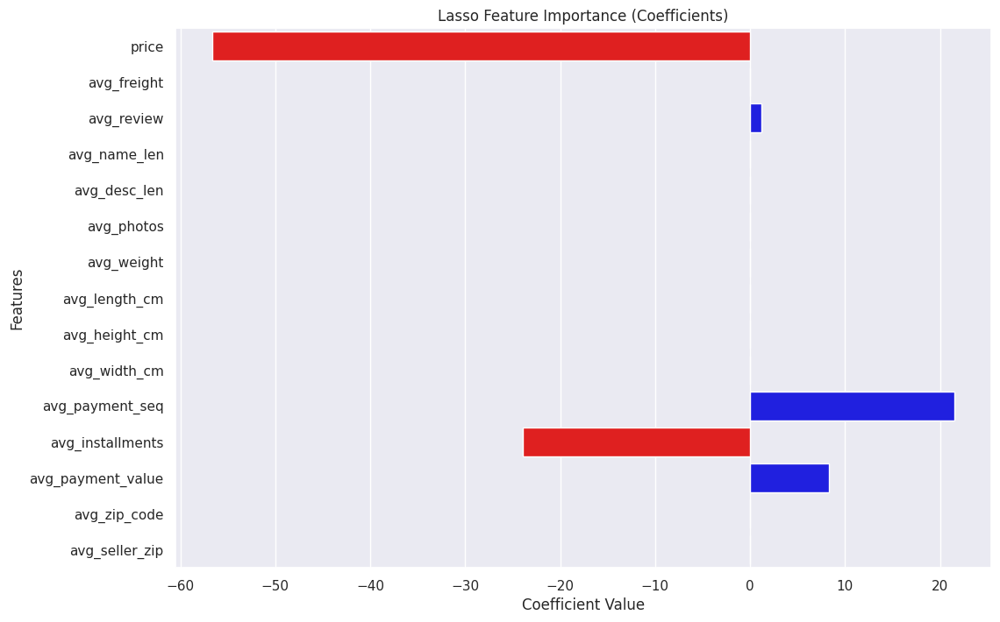

RF Feature Importances: {'price': np.float64(0.32723140357635383), 'avg_freight': np.float64(0.379240793162096), 'avg_review': np.float64(0.049018995430238396), 'avg_name_len': np.float64(0.0), 'avg_desc_len': np.float64(0.0), 'avg_photos': np.float64(0.0), 'avg_weight': np.float64(0.0), 'avg_length_cm': np.float64(0.0), 'avg_height_cm': np.float64(0.0), 'avg_width_cm': np.float64(0.0), 'avg_payment_seq': np.float64(0.012325591307343944), 'avg_installments': np.float64(0.09504654604196347), 'avg_payment_value': np.float64(0.05388699813589221), 'avg_zip_code': np.float64(0.08324967234611218), 'avg_seller_zip': np.float64(0.0)}


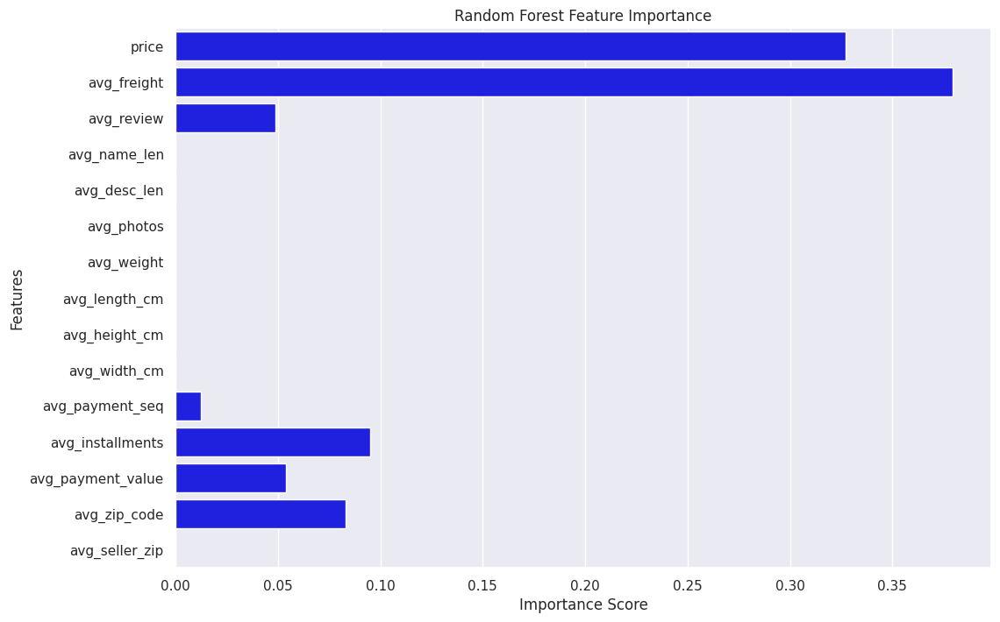

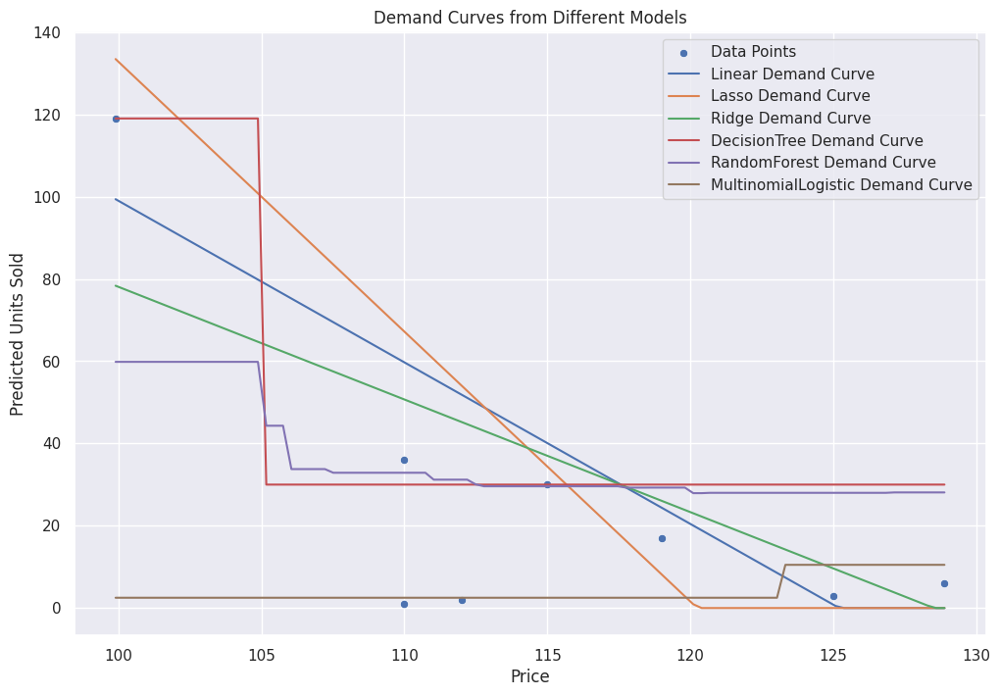

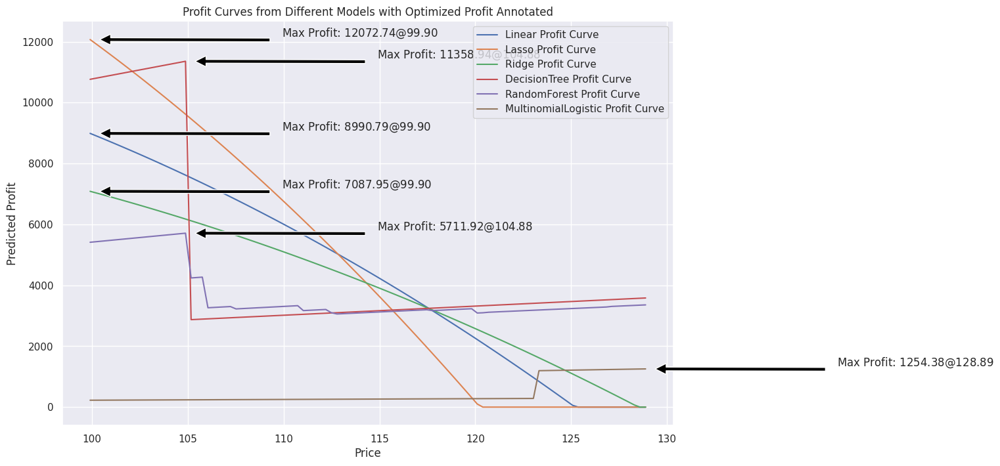

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Lasso, Ridge, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_squared_error
from sklearn.inspection import permutation_importance

# Step 1: Load and Clean Data
df = pd.read_csv('final_data.csv')

# Filter for delivered orders
df = df[df['order_status'] == 'delivered']

# Convert timestamp to datetime
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])

# Add year, month, year_month
df['year'] = df['order_purchase_timestamp'].dt.year
df['month'] = df['order_purchase_timestamp'].dt.month
df['year_month'] = df['order_purchase_timestamp'].dt.to_period('M')

# Step 2: EDA - Top Categories by Units and Revenue
category_units = df.groupby('product_category_name_english')['order_item_id'].count().sort_values(ascending=False)
category_revenue = df.groupby('product_category_name_english')['price'].sum().sort_values(ascending=False)

display("Top Categories by Units Sold:\n", category_units.head(10))
display("Top Categories by Revenue:\n", category_revenue.head(10))

# Select category: watches_gifts (top revenue generator with variation)
category = 'watches_gifts'
df_cat = df[df['product_category_name_english'] == category]

# Top product by units sold
top_product = df_cat['product_id'].value_counts().idxmax()
display("Top Product ID:", top_product)

df_prod = df_cat[df_cat['product_id'] == top_product]

# Top seller for this product
top_seller = df_prod['seller_id'].value_counts().idxmax()
display("Top Seller ID:", top_seller)

df_prod_seller = df_prod[df_prod['seller_id'] == top_seller]

# Aggregate units sold per unique price point, including more features (all numeric except NLP)
# Exclude review_comment_title and review_comment_message as NLP
price_agg = df_prod_seller.groupby('price').agg(
    units_sold=('order_item_id', 'count'),
    avg_freight=('freight_value', 'mean'),
    avg_review=('review_score', 'mean'),
    avg_name_len=('product_name_lenght', 'mean'),
    avg_desc_len=('product_description_lenght', 'mean'),
    avg_photos=('product_photos_qty', 'mean'),
    avg_weight=('product_weight_g', 'mean'),
    avg_length_cm=('product_length_cm', 'mean'),
    avg_height_cm=('product_height_cm', 'mean'),
    avg_width_cm=('product_width_cm', 'mean'),
    avg_payment_seq=('payment_sequential', 'mean'),
    avg_installments=('payment_installments', 'mean'),
    avg_payment_value=('payment_value', 'mean'),
    avg_zip_code=('zip_code', 'mean'),
    avg_seller_zip=('seller_zip_code_prefix', 'mean')
).reset_index()

# For categoricals, add mode for payment_type and customer_state
price_agg['mode_payment_type'] = df_prod_seller.groupby('price')['payment_type'].apply(lambda x: x.mode()[0] if not x.empty else np.nan)
price_agg['mode_customer_state'] = df_prod_seller.groupby('price')['customer_state'].apply(lambda x: x.mode()[0] if not x.empty else np.nan)

# One-hot encode categoricals
price_agg = pd.get_dummies(price_agg, columns=['mode_payment_type', 'mode_customer_state'], drop_first=True)

display("Aggregated Data:\n", price_agg)

# Step 3: Simple Demand Model (Units ~ Price)
X_simple = price_agg[['price']]
y = price_agg['units_sold']

model_simple = LinearRegression()
model_simple.fit(X_simple, y)

print("Simple Model: units_sold = {:.2f} - {:.2f} * price".format(model_simple.intercept_, -model_simple.coef_[0]))
print("R-squared:", model_simple.score(X_simple, y))

# Optimization for simple model
a = model_simple.intercept_
b = -model_simple.coef_[0]
optimal_price_simple = a / (2 * b)
optimal_units_simple = a - b * optimal_price_simple
optimal_revenue_simple = optimal_price_simple * optimal_units_simple

print("Simple Model Optimal Price: ${:.2f}".format(optimal_price_simple))

# Step 4: Multivariate Model with All Features (except NLP)
features = [col for col in price_agg.columns if col not in ['units_sold']]
X = price_agg[features]
y = price_agg['units_sold']

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train-test split (small data, but for demo; use all for fitting models)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Regression Models
reg_models = {
    'Linear': LinearRegression(),
    'Lasso': Lasso(alpha=0.1),
    'Ridge': Ridge(alpha=1.0),
    'DecisionTree': DecisionTreeRegressor(max_depth=3, random_state=42),
    'RandomForest': RandomForestRegressor(n_estimators=100, random_state=42)
}

reg_results = {}
for name, model in reg_models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    reg_results[name] = {'model': model, 'mse': mse}
    print(f"{name} MSE: {mse}")

# Add Multinomial Logistic Regression (Classification: bin units_sold)
# Bin y into categories: low (0-5), med (6-15), high (16+)
bins = [0, 5, 15, np.inf]
labels = ['low', 'med', 'high']
y_binned = pd.cut(y, bins=bins, labels=labels)
le = LabelEncoder()
y_encoded = le.fit_transform(y_binned)

# Split for classification
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(X_scaled, y_encoded, test_size=0.2, random_state=42)

log_model = LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=1000)
log_model.fit(X_train_clf, y_train_clf)

# For MSE, predict and map back to midpoints for approximation
midpoints = [2.5, 10.5, 20]  # Approx mid for bins
y_pred_clf = log_model.predict(X_test_clf)
y_pred_reg_approx = [midpoints[p] for p in y_pred_clf]
mse_clf = mean_squared_error(y_test, y_pred_reg_approx)  # Approx regression MSE
print(f"Multinomial Logistic (Approx) MSE: {mse_clf}")

# Feature Importance for Lasso (with colored bars: positive blue, negative red)
lasso_model = reg_models['Lasso']
if hasattr(lasso_model, 'coef_'):
    print("Lasso Coefficients:", dict(zip(features, lasso_model.coef_)))

    # Create colors based on sign
    lasso_colors = ['blue' if c > 0 else 'red' for c in lasso_model.coef_]

    plt.figure(figsize=(12, 8))
    sns.barplot(x=lasso_model.coef_, y=features, palette=lasso_colors)
    plt.title('Lasso Feature Importance (Coefficients)')
    plt.xlabel('Coefficient Value')
    plt.ylabel('Features')
    plt.show()

# Feature Importance for Random Forest (all positive, so blue; but check for any negatives though unlikely)
rf_model = reg_models['RandomForest']
if hasattr(rf_model, 'feature_importances_'):
    print("RF Feature Importances:", dict(zip(features, rf_model.feature_importances_)))

    # Colors: positive blue, negative red (though RF importances >=0)
    rf_colors = ['blue' if i > 0 else 'red' for i in rf_model.feature_importances_]

    plt.figure(figsize=(12, 8))
    sns.barplot(x=rf_model.feature_importances_, y=features, palette=rf_colors)
    plt.title('Random Forest Feature Importance')
    plt.xlabel('Importance Score')
    plt.ylabel('Features')
    plt.show()

# Step 5: Demand Curves from Different Models
# To plot demand curves, vary price while holding other features at mean
mean_features = price_agg[features].mean().values
price_range = np.linspace(price_agg['price'].min(), price_agg['price'].max(), 100)

plt.figure(figsize=(12, 8))
sns.scatterplot(x='price', y='units_sold', data=price_agg, label='Data Points')

models_for_plot = {**reg_models, 'MultinomialLogistic': log_model}

for name, model in models_for_plot.items():
    units_preds = []
    for p in price_range:
        input_features = mean_features.copy()
        input_features[features.index('price')] = p  # Replace price
        input_scaled = scaler.transform([input_features])
        if name == 'MultinomialLogistic':
            pred_clf = model.predict(input_scaled)[0]
            pred = midpoints[pred_clf]
        else:
            pred = model.predict(input_scaled)[0]
        units_preds.append(max(pred, 0))  # Clip negative
    plt.plot(price_range, units_preds, label=f'{name} Demand Curve')

plt.title('Demand Curves from Different Models')
plt.xlabel('Price')
plt.ylabel('Predicted Units Sold')
plt.legend()
plt.show()

# Step 6: Profit Curves with Optimized Profit Annotated (changed from revenue)
avg_freight = price_agg['avg_freight'].mean()  # Use mean freight for approximation

plt.figure(figsize=(12, 8))

for name, model in models_for_plot.items():
    profits = []
    for p in price_range:
        input_features = mean_features.copy()
        input_features[features.index('price')] = p
        input_scaled = scaler.transform([input_features])
        if name == 'MultinomialLogistic':
            pred_clf = model.predict(input_scaled)[0]
            pred = midpoints[pred_clf]
        else:
            pred = model.predict(input_scaled)[0]
        profit = (p - avg_freight) * max(pred, 0)
        profits.append(profit)

    plt.plot(price_range, profits, label=f'{name} Profit Curve')

    # Find and annotate max profit
    max_idx = np.argmax(profits)
    max_price = price_range[max_idx]
    max_profit = profits[max_idx]
    plt.annotate(f'Max Profit: ${max_profit:.2f} @ ${max_price:.2f}',
                 xy=(max_price, max_profit), xytext=(max_price + 10, max_profit + 100),
                 arrowprops=dict(facecolor='black', shrink=0.05))

plt.title('Profit Curves from Different Models with Optimized Profit Annotated')
plt.xlabel('Price')
plt.ylabel('Predicted Profit')
plt.legend()
plt.show()

Top Categories by Units Sold:
 product_category_name_english
bed_bath_table           11685
health_beauty             9747
sports_leisure            8736
furniture_decor           8558
computers_accessories     7927
housewares                7154
watches_gifts             6032
telephony                 4580
garden_tools              4452
auto                      4260
Name: order_item_id, dtype: int64
Top Categories by Revenue:
 product_category_name_english
health_beauty            1266992.59
watches_gifts            1207633.40
bed_bath_table           1082024.32
sports_leisure            989781.66
computers_accessories     922593.78
furniture_decor           746811.14
housewares                646232.97
cool_stuff                628528.54
auto                      594994.54
garden_tools              490451.78
Name: price, dtype: float64
Top Product ID: 53b36df67ebb7c41585e8d54d6772e08
Top Seller ID: 7d13fca15225358621be4086e1eb0964
Expanded Data Shape: (214, 39)
Expanded Data:
      

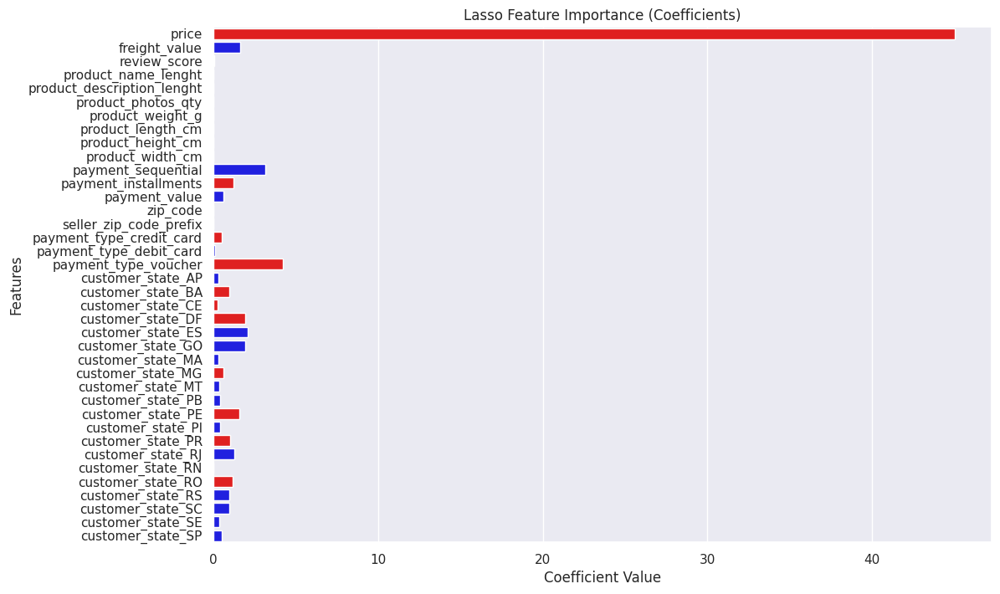

RF Feature Importances: {'price': np.float64(0.9987829763957249), 'freight_value': np.float64(0.00025408438028621914), 'review_score': np.float64(3.3652461435029945e-05), 'product_name_lenght': np.float64(0.0), 'product_description_lenght': np.float64(0.0), 'product_photos_qty': np.float64(0.0), 'product_weight_g': np.float64(0.0), 'product_length_cm': np.float64(0.0), 'product_height_cm': np.float64(0.0), 'product_width_cm': np.float64(0.0), 'payment_sequential': np.float64(1.4297027834977023e-07), 'payment_installments': np.float64(1.1901574307887164e-06), 'payment_value': np.float64(0.00013306253061201755), 'zip_code': np.float64(0.0005274007664543792), 'seller_zip_code_prefix': np.float64(0.0), 'payment_type_credit_card': np.float64(6.381910080146628e-07), 'payment_type_debit_card': np.float64(0.0), 'payment_type_voucher': np.float64(1.5492788436787612e-07), 'customer_state_AP': np.float64(0.0), 'customer_state_BA': np.float64(8.114258181914532e-07), 'customer_state_CE': np.float64

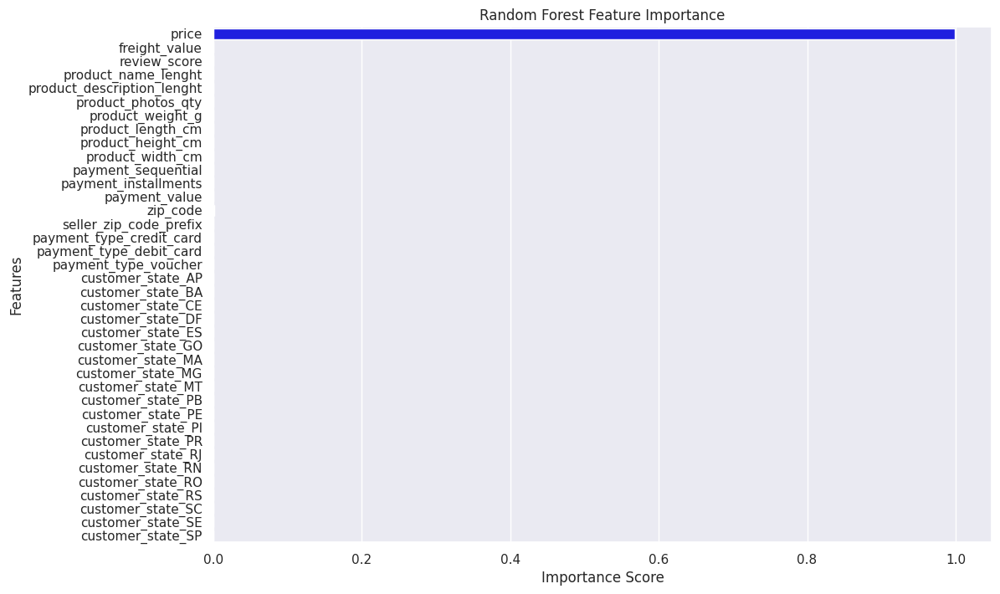

Permutation Importances: {'price': np.float64(1.9876618152070509), 'freight_value': np.float64(3.3398592260380775e-05), 'review_score': np.float64(5.437601123703395e-07), 'product_name_lenght': np.float64(0.0), 'product_description_lenght': np.float64(0.0), 'product_photos_qty': np.float64(0.0), 'product_weight_g': np.float64(0.0), 'product_length_cm': np.float64(0.0), 'product_height_cm': np.float64(0.0), 'product_width_cm': np.float64(0.0), 'payment_sequential': np.float64(2.1652437465213836e-08), 'payment_installments': np.float64(2.1307819134674943e-07), 'payment_value': np.float64(0.00012041382158501923), 'zip_code': np.float64(9.841147721588728e-05), 'seller_zip_code_prefix': np.float64(0.0), 'payment_type_credit_card': np.float64(2.1333828070790872e-07), 'payment_type_debit_card': np.float64(0.0), 'payment_type_voucher': np.float64(3.628246283415848e-08), 'customer_state_AP': np.float64(0.0), 'customer_state_BA': np.float64(3.339547118730302e-07), 'customer_state_CE': np.float64

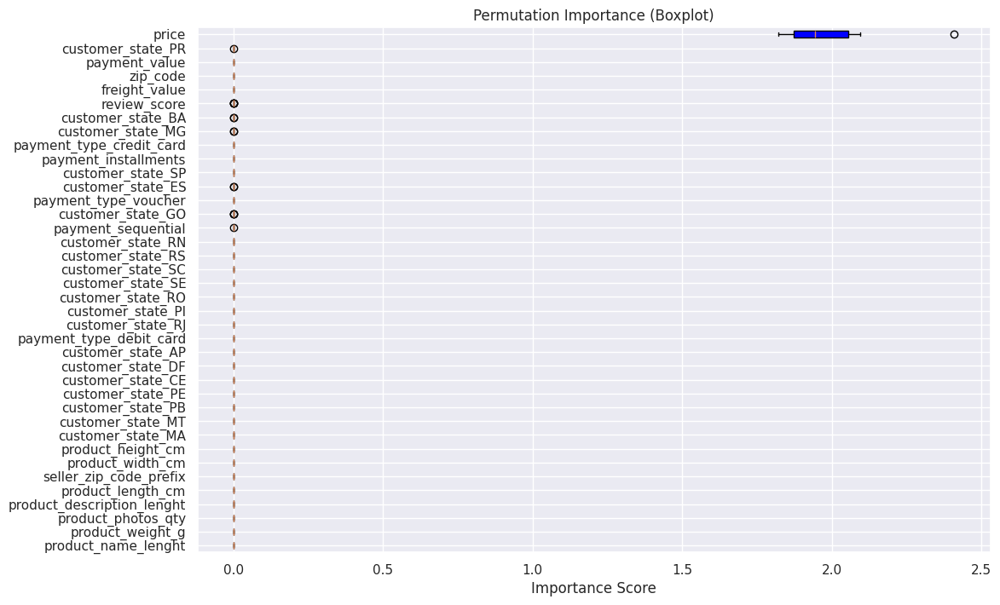

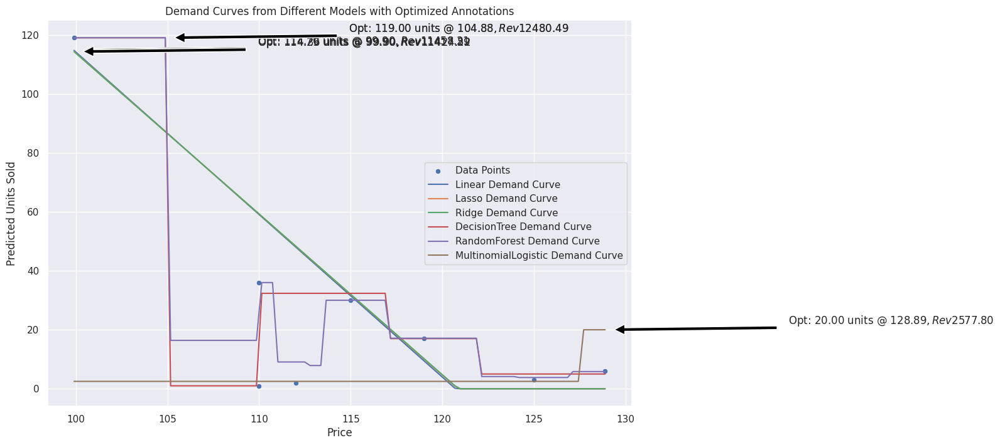

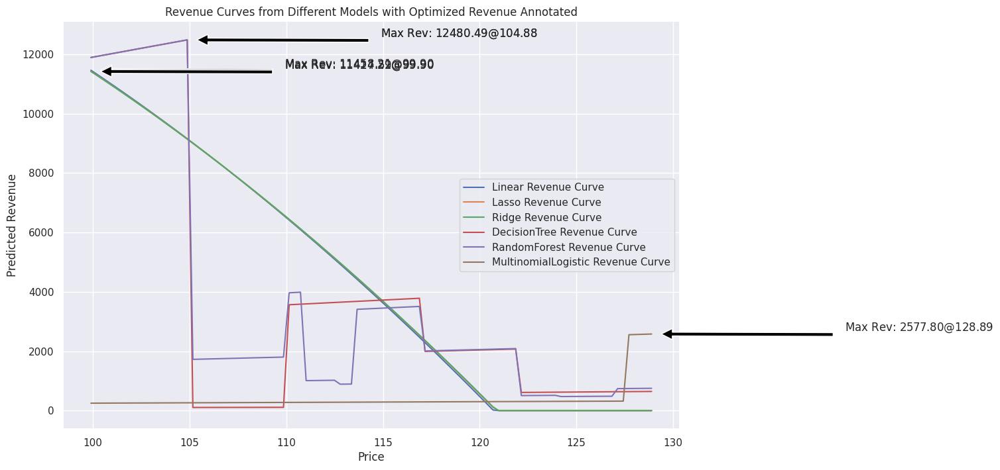

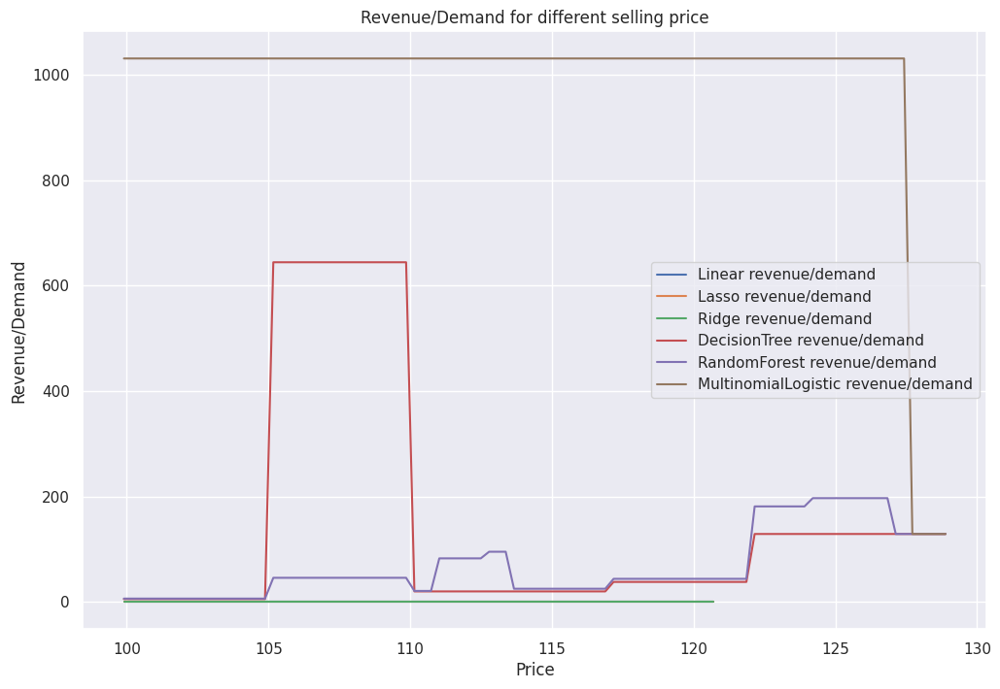

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Lasso, Ridge, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_squared_error
from sklearn.inspection import permutation_importance

# Step 1: Load and Clean Data
df = pd.read_csv('final_data.csv')

# Filter for delivered orders
df = df[df['order_status'] == 'delivered']

# Convert timestamp to datetime
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])

# Add year, month, year_month
df['year'] = df['order_purchase_timestamp'].dt.year
df['month'] = df['order_purchase_timestamp'].dt.month
df['year_month'] = df['order_purchase_timestamp'].dt.to_period('M')

# Step 2: EDA - Top Categories by Units and Revenue
category_units = df.groupby('product_category_name_english')['order_item_id'].count().sort_values(ascending=False)
category_revenue = df.groupby('product_category_name_english')['price'].sum().sort_values(ascending=False)

print("Top Categories by Units Sold:\n", category_units.head(10))
print("Top Categories by Revenue:\n", category_revenue.head(10))

# Select category: watches_gifts (top revenue generator with variation)
category = 'watches_gifts'
df_cat = df[df['product_category_name_english'] == category]

# Top product by units sold
top_product = df_cat['product_id'].value_counts().idxmax()
print("Top Product ID:", top_product)

df_prod = df_cat[df_cat['product_id'] == top_product]

# Top seller for this product
top_seller = df_prod['seller_id'].value_counts().idxmax()
print("Top Seller ID:", top_seller)

df_prod_seller = df_prod[df_prod['seller_id'] == top_seller]

# Compute units_sold per price (aggregate only count)
units_per_price = df_prod_seller.groupby('price')['order_item_id'].count().reset_index(name='units_sold')

# Merge back to keep original data points (larger dataset, ~57 rows)
df_expanded = df_prod_seller.merge(units_per_price, on='price')

# Select original features (numeric + categoricals to encode; exclude NLP/text, IDs, dates)
selected_columns = [
    'price', 'freight_value', 'review_score', 'product_name_lenght', 'product_description_lenght',
    'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm',
    'payment_sequential', 'payment_installments', 'payment_value', 'zip_code', 'seller_zip_code_prefix',
    'payment_type', 'customer_state', 'units_sold'
]
df_expanded = df_expanded[selected_columns]

# One-hot encode categoricals
df_expanded = pd.get_dummies(df_expanded, columns=['payment_type', 'customer_state'], drop_first=True)

print("Expanded Data Shape:", df_expanded.shape)
print("Expanded Data:\n", df_expanded)

# Step 3: Simple Demand Model (Units ~ Price) - Use aggregated prices for this
X_simple = units_per_price[['price']]
y_simple = units_per_price['units_sold']

model_simple = LinearRegression()
model_simple.fit(X_simple, y_simple)

print("Simple Model: units_sold = {:.2f} - {:.2f} * price".format(model_simple.intercept_, -model_simple.coef_[0]))
print("R-squared:", model_simple.score(X_simple, y_simple))

# Optimization for simple model
a = model_simple.intercept_
b = -model_simple.coef_[0]
optimal_price_simple = a / (2 * b)
optimal_units_simple = a - b * optimal_price_simple
optimal_revenue_simple = optimal_price_simple * optimal_units_simple

print("Simple Model Optimal Price: ${:.2f}".format(optimal_price_simple))

# Step 4: Multivariate Model with Original Features - Fit on all data (no split)
features = [col for col in df_expanded.columns if col != 'units_sold']
X = df_expanded[features]
y = df_expanded['units_sold']

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Regression Models - Fit on all
reg_models = {
    'Linear': LinearRegression(),
    'Lasso': Lasso(alpha=0.1),
    'Ridge': Ridge(alpha=1.0),
    'DecisionTree': DecisionTreeRegressor(max_depth=3, random_state=42),
    'RandomForest': RandomForestRegressor(n_estimators=100, random_state=42)
}

reg_results = {}
for name, model in reg_models.items():
    model.fit(X_scaled, y)
    y_pred = model.predict(X_scaled)  # Predict on all for training MSE
    mse = mean_squared_error(y, y_pred)
    reg_results[name] = {'model': model, 'mse': mse}
    print(f"{name} Training MSE: {mse}")

# Add Multinomial Logistic Regression (Classification: bin units_sold)
# Bin y into categories: low (0-5), med (6-15), high (16+)
bins = [0, 5, 15, np.inf]
labels = ['low', 'med', 'high']
y_binned = pd.cut(y, bins=bins, labels=labels)
le = LabelEncoder()
y_encoded = le.fit_transform(y_binned)

log_model = LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=1000)
log_model.fit(X_scaled, y_encoded)

# For MSE, predict and map back to midpoints for approximation
midpoints = [2.5, 10.5, 20]  # Approx mid for bins
y_pred_clf = log_model.predict(X_scaled)
y_pred_reg_approx = [midpoints[p] for p in y_pred_clf]
mse_clf = mean_squared_error(y, y_pred_reg_approx)  # Approx regression MSE on all
print(f"Multinomial Logistic (Approx) Training MSE: {mse_clf}")

# Feature Importance for Lasso (with colored bars: positive blue, negative red)
lasso_model = reg_models['Lasso']
if hasattr(lasso_model, 'coef_'):
    print("Lasso Coefficients:", dict(zip(features, lasso_model.coef_)))

    # Create colors based on sign
    lasso_colors = ['blue' if c > 0 else 'red' for c in lasso_model.coef_]

    plt.figure(figsize=(12, 8))
    sns.barplot(x=abs(lasso_model.coef_), y=features, palette=lasso_colors)
    plt.title('Lasso Feature Importance (Coefficients)')
    plt.xlabel('Coefficient Value')
    plt.ylabel('Features')
    plt.show()

# Feature Importance for Random Forest (all positive, so blue; but check for any negatives though unlikely)
rf_model = reg_models['RandomForest']
if hasattr(rf_model, 'feature_importances_'):
    print("RF Feature Importances:", dict(zip(features, rf_model.feature_importances_)))

    # Colors: positive blue, negative red (though RF importances >=0)
    rf_colors = ['blue' if i > 0 else 'red' for i in rf_model.feature_importances_]

    plt.figure(figsize=(12, 8))
    sns.barplot(x=abs(rf_model.feature_importances_), y=features, palette=rf_colors)
    plt.title('Random Forest Feature Importance')
    plt.xlabel('Importance Score')
    plt.ylabel('Features')
    plt.show()

# Permutation Importance for Random Forest (can be negative) - Use all data
perm_importance = permutation_importance(rf_model, X_scaled, y, n_repeats=10, random_state=42)
print("Permutation Importances:", dict(zip(features, perm_importance.importances_mean)))

# For boxplot, customize colors based on mean importance sign
sorted_idx = perm_importance.importances_mean.argsort()
fig, ax = plt.subplots(figsize=(12, 8))
bp = ax.boxplot(abs(perm_importance.importances[sorted_idx].T), vert=False, labels=np.array(features)[sorted_idx], patch_artist=True)

# Color boxes based on mean importance
for i, mean in enumerate(perm_importance.importances_mean[sorted_idx]):
    color = 'blue' if mean > 0 else 'red'
    bp['boxes'][i].set_facecolor(color)

plt.title('Permutation Importance (Boxplot)')
plt.xlabel('Importance Score')
plt.show()

# Step 5: Demand Curves from Different Models with Optimized Annotations
# To plot demand curves, vary price while holding other features at mean
mean_features = df_expanded[features].mean().values
price_range = np.linspace(df_expanded['price'].min(), df_expanded['price'].max(), 100)

fig, ax = plt.subplots(figsize=(12, 8))
sns.scatterplot(x='price', y='units_sold', data=df_expanded, label='Data Points', ax=ax)

models_for_plot = {**reg_models, 'MultinomialLogistic': log_model}

for name, model in models_for_plot.items():
    units_preds = []
    revenues = []
    for p in price_range:
        input_features = mean_features.copy()
        input_features[features.index('price')] = p  # Replace price
        input_scaled = scaler.transform([input_features])
        if name == 'MultinomialLogistic':
            pred_clf = model.predict(input_scaled)[0]
            pred = midpoints[pred_clf]
        else:
            pred = model.predict(input_scaled)[0]
        pred = max(pred, 0)  # Clip negative
        units_preds.append(pred)
        rev = p * pred
        revenues.append(rev)
    ax.plot(price_range, units_preds, label=f'{name} Demand Curve')

    # Find optimal from revenue
    max_idx = np.argmax(revenues)
    opt_price = price_range[max_idx]
    opt_units = units_preds[max_idx]
    opt_rev = revenues[max_idx]
    ax.annotate(f'Opt: {opt_units:.2f} units @ ${opt_price:.2f}, Rev ${opt_rev:.2f}',
                xy=(opt_price, opt_units), xytext=(opt_price + 10, opt_units + 2),
                arrowprops=dict(facecolor='black', shrink=0.05))

ax.set_title('Demand Curves from Different Models with Optimized Annotations')
ax.set_xlabel('Price')
ax.set_ylabel('Predicted Units Sold')
ax.legend()
plt.show()

# Step 6: Revenue Curves with Optimized Revenue Annotated
plt.figure(figsize=(12, 8))

for name, model in models_for_plot.items():
    revenues = []
    for p in price_range:
        input_features = mean_features.copy()
        input_features[features.index('price')] = p
        input_scaled = scaler.transform([input_features])
        if name == 'MultinomialLogistic':
            pred_clf = model.predict(input_scaled)[0]
            pred = midpoints[pred_clf]
        else:
            pred = model.predict(input_scaled)[0]
        rev = p * max(pred, 0)
        revenues.append(rev)

    plt.plot(price_range, revenues, label=f'{name} Revenue Curve')

    # Find and annotate max revenue
    max_idx = np.argmax(revenues)
    max_price = price_range[max_idx]
    max_rev = revenues[max_idx]
    plt.annotate(f'Max Rev: ${max_rev:.2f} @ ${max_price:.2f}',
                 xy=(max_price, max_rev), xytext=(max_price + 10, max_rev + 100),
                 arrowprops=dict(facecolor='black', shrink=0.05))

plt.title('Revenue Curves from Different Models with Optimized Revenue Annotated')
plt.xlabel('Price')
plt.ylabel('Predicted Revenue')
plt.legend()
plt.show()



fig, ax = plt.subplots(figsize=(12, 8))

models_for_plot = {**reg_models, 'MultinomialLogistic': log_model}

for name, model in models_for_plot.items():
    units_preds = []
    revenues = []
    for p in price_range:
        input_features = mean_features.copy()
        input_features[features.index('price')] = p  # Replace price
        input_scaled = scaler.transform([input_features])
        if name == 'MultinomialLogistic':
            pred_clf = model.predict(input_scaled)[0]
            pred = midpoints[pred_clf]
        else:
            pred = model.predict(input_scaled)[0]
        pred = max(pred, 0)  # Clip negative
        units_preds.append(pred)
        rev = p * pred
        revenues.append(rev)
    ax.plot(price_range, np.array(rev)/np.array(units_preds), label=f'{name} revenue/demand')
plt.title('Revenue/Demand for different selling price')
plt.xlabel('Price')
plt.ylabel('Revenue/Demand')
plt.legend()
plt.show()

Total unique categories: 71

Top 1 categories by net revenue (cumulative: $1105917.30):
        category  net_revenue
0  watches_gifts    1105917.3

Top 2 categories by net revenue (cumulative: $2187741.35):
        category  net_revenue
0  watches_gifts   1105917.30
1  health_beauty   1081824.05

Top 3 categories by net revenue (cumulative: $3054568.98):
         category  net_revenue
0   watches_gifts   1105917.30
1   health_beauty   1081824.05
2  bed_bath_table    866827.63

Top 4 categories by net revenue (cumulative: $3874052.18):
         category  net_revenue
0   watches_gifts   1105917.30
1   health_beauty   1081824.05
2  bed_bath_table    866827.63
3  sports_leisure    819483.20

Top 5 categories by net revenue (cumulative: $4645729.87):
                category  net_revenue
0          watches_gifts   1105917.30
1          health_beauty   1081824.05
2         bed_bath_table    866827.63
3         sports_leisure    819483.20
4  computers_accessories    771677.69

Top 6 categori

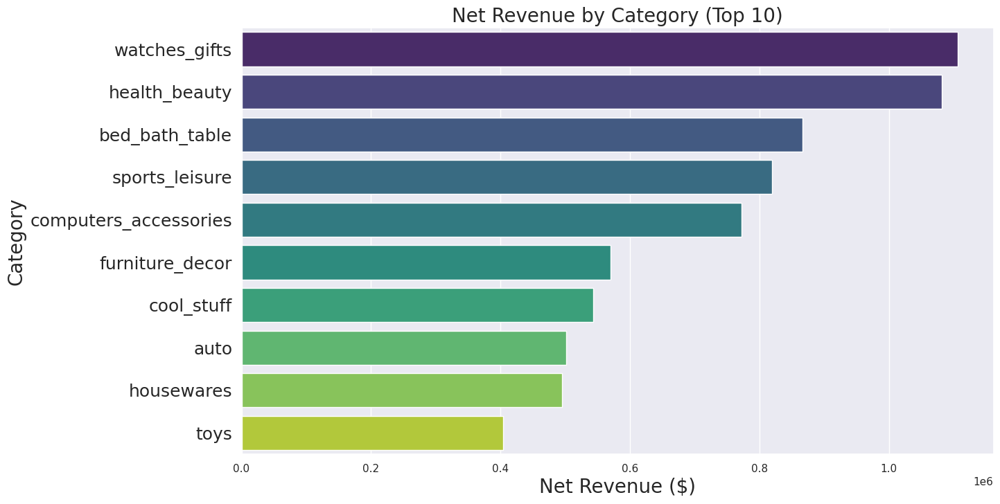

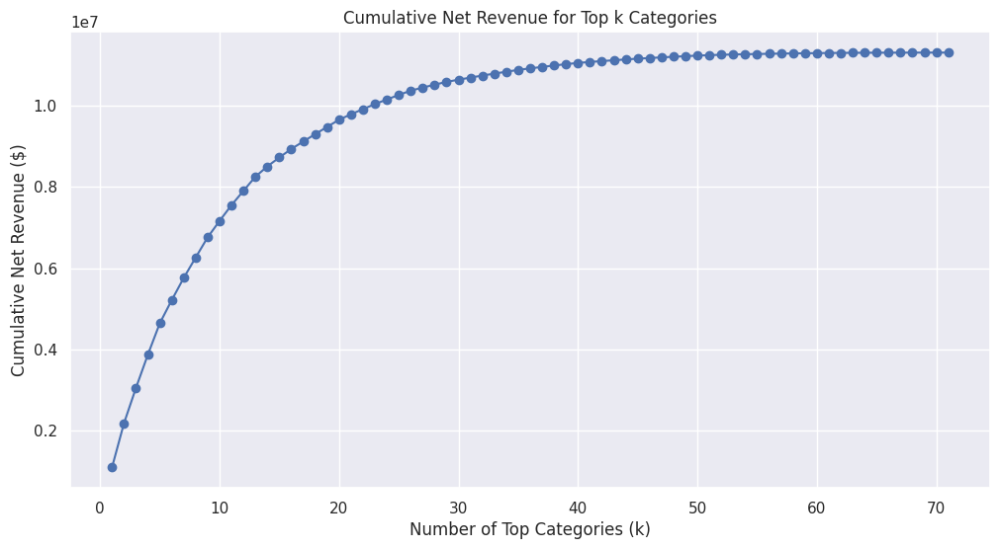

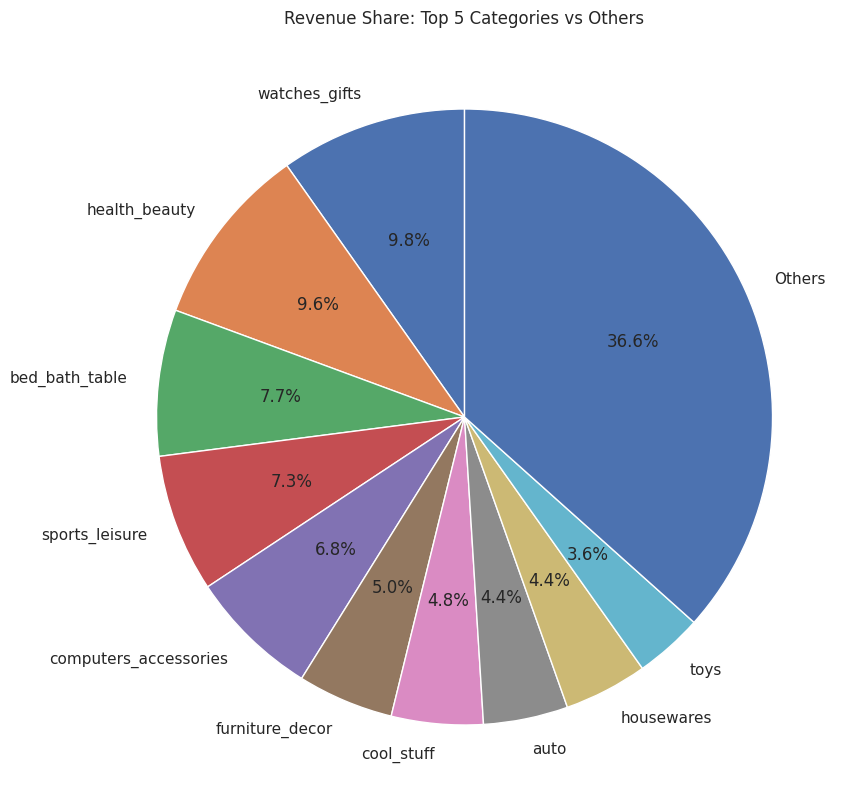

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the data (includes all statuses)
df = pd.read_csv('final_data.csv')

# Keep only relevant columns
df = df[['product_category_name_english', 'order_status', 'price', 'freight_value', 'order_item_id']]

# Compute net contribution per row
# For delivered: price - freight (assuming freight is a cost)
# For canceled: -freight (loss of shipment cost, 0 from price)
# Assuming one row per item, and order_item_id=1 typically, but sum accordingly
df['net_contrib'] = 0.0
delivered_mask = df['order_status'] == 'delivered'
canceled_mask = df['order_status'] == 'canceled'
df.loc[delivered_mask, 'net_contrib'] = df.loc[delivered_mask, 'price'] - df.loc[delivered_mask, 'freight_value']
df.loc[canceled_mask, 'net_contrib'] = -df.loc[canceled_mask, 'freight_value']

# Group by category to get total net revenue
category_revenue = df.groupby('product_category_name_english')['net_contrib'].sum().reset_index()
category_revenue = category_revenue.sort_values(by='net_contrib', ascending=False).reset_index(drop=True)
category_revenue.columns = ['category', 'net_revenue']

# Get unique categories count
n_categories = len(category_revenue)
print(f"Total unique categories: {n_categories}")

# Compute cumulative revenue for top k
category_revenue['cumulative_revenue'] = category_revenue['net_revenue'].cumsum()

# Print top k for each k from 1 to n_categories
for k in range(1, n_categories + 1):
    top_k = category_revenue.head(k)
    cum_rev = top_k['net_revenue'].sum()
    print(f"\nTop {k} categories by net revenue (cumulative: ${cum_rev:.2f}):")
    print(top_k[['category', 'net_revenue']])

# Plot 1: Bar plot of net revenue per category (top 20 for visibility)
plt.figure(figsize=(14, 8))
sns.barplot(x='net_revenue', y='category', data=category_revenue.head(10), palette='viridis')
plt.title('Net Revenue by Category (Top 10)', fontsize=20)
plt.xlabel('Net Revenue ($)', fontsize=20)
plt.ylabel('Category', fontsize=20)
plt.yticks(fontsize=18)
plt.show()

# Plot 2: Cumulative revenue curve for top k categories
plt.figure(figsize=(12, 6))
plt.plot(range(1, n_categories + 1), category_revenue['cumulative_revenue'], marker='o')
plt.title('Cumulative Net Revenue for Top k Categories')
plt.xlabel('Number of Top Categories (k)')
plt.ylabel('Cumulative Net Revenue ($)')
plt.grid(True)
plt.show()

# Plot 3: Pie chart for revenue share of top 5 categories vs others
top_10_revenue = category_revenue.head(10)['net_revenue'].sum()
other_revenue = category_revenue['net_revenue'].sum() - top_10_revenue
pie_data = pd.DataFrame({
    'Category Group': list(category_revenue.head(10)['category']) + ['Others'],
    'Revenue': list(category_revenue.head(10)['net_revenue']) + [other_revenue]
})
plt.figure(figsize=(10, 10))
plt.pie(pie_data['Revenue'], labels=pie_data['Category Group'], autopct='%1.1f%%', startangle=90)
plt.title('Revenue Share: Top 5 Categories vs Others')
plt.show()

Top Categories by Units Sold:
 product_category_name_english
bed_bath_table           11685
health_beauty             9747
sports_leisure            8736
furniture_decor           8558
computers_accessories     7927
housewares                7154
watches_gifts             6032
telephony                 4580
garden_tools              4452
auto                      4260
Name: order_item_id, dtype: int64
Top Categories by Revenue:
 product_category_name_english
health_beauty            1266992.59
watches_gifts            1207633.40
bed_bath_table           1082024.32
sports_leisure            989781.66
computers_accessories     922593.78
furniture_decor           746811.14
housewares                646232.97
cool_stuff                628528.54
auto                      594994.54
garden_tools              490451.78
Name: price, dtype: float64

Aggregated Data for Category health_beauty:
         price  units_sold  avg_freight  avg_review  avg_name_len  \
0        1.20          20     7.890

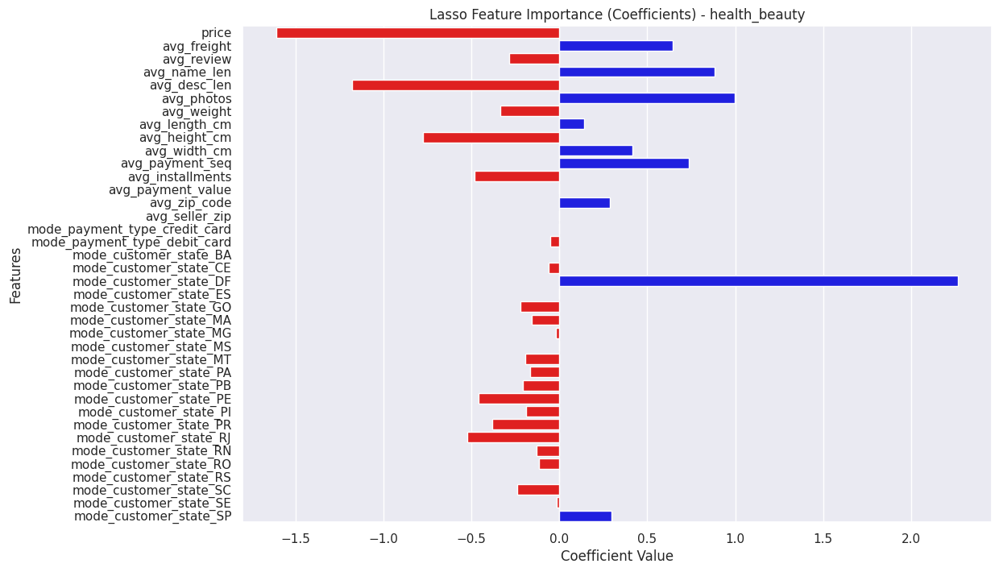

RF Feature Importances for health_beauty: {'price': np.float64(0.016408326500413396), 'avg_freight': np.float64(0.024308085062074932), 'avg_review': np.float64(0.07109845138990203), 'avg_name_len': np.float64(0.09843826480554636), 'avg_desc_len': np.float64(0.021113675853875725), 'avg_photos': np.float64(0.03882551398765985), 'avg_weight': np.float64(0.0410922754220271), 'avg_length_cm': np.float64(0.019104879889301117), 'avg_height_cm': np.float64(0.06191235617024263), 'avg_width_cm': np.float64(0.018840070855299942), 'avg_payment_seq': np.float64(0.4884584451731096), 'avg_installments': np.float64(0.010842625135633395), 'avg_payment_value': np.float64(0.013144787905841268), 'avg_zip_code': np.float64(0.0219768424805438), 'avg_seller_zip': np.float64(0.04321646112522309), 'mode_payment_type_credit_card': np.float64(0.0013630335717240913), 'mode_payment_type_debit_card': np.float64(7.004259505152866e-07), 'mode_customer_state_BA': np.float64(0.00012742828354256618), 'mode_customer_stat

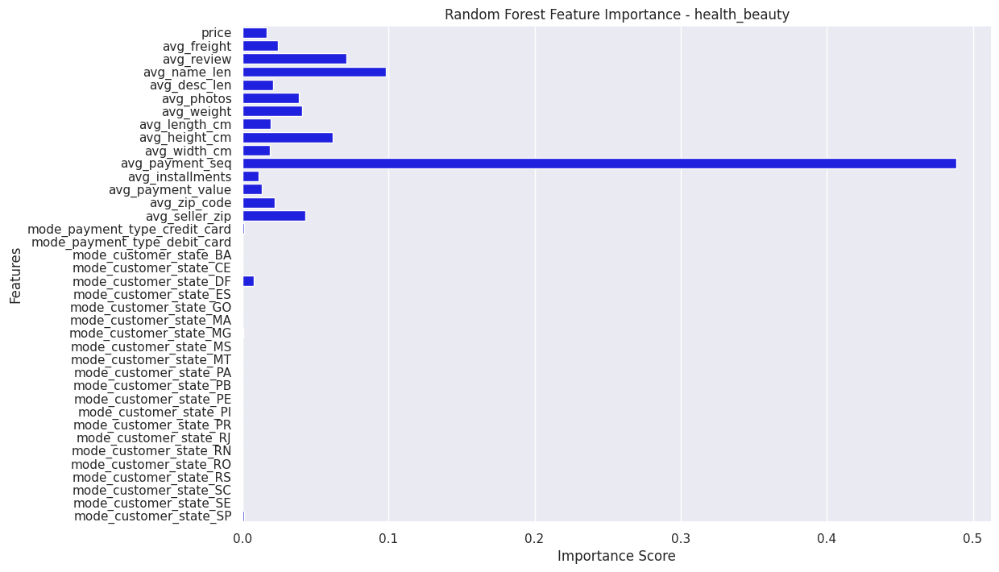

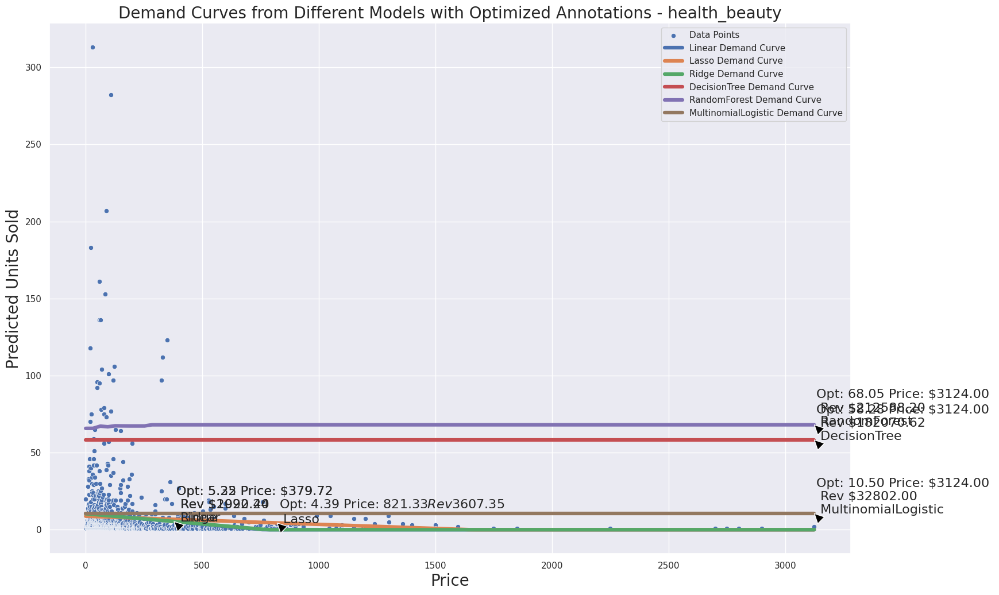

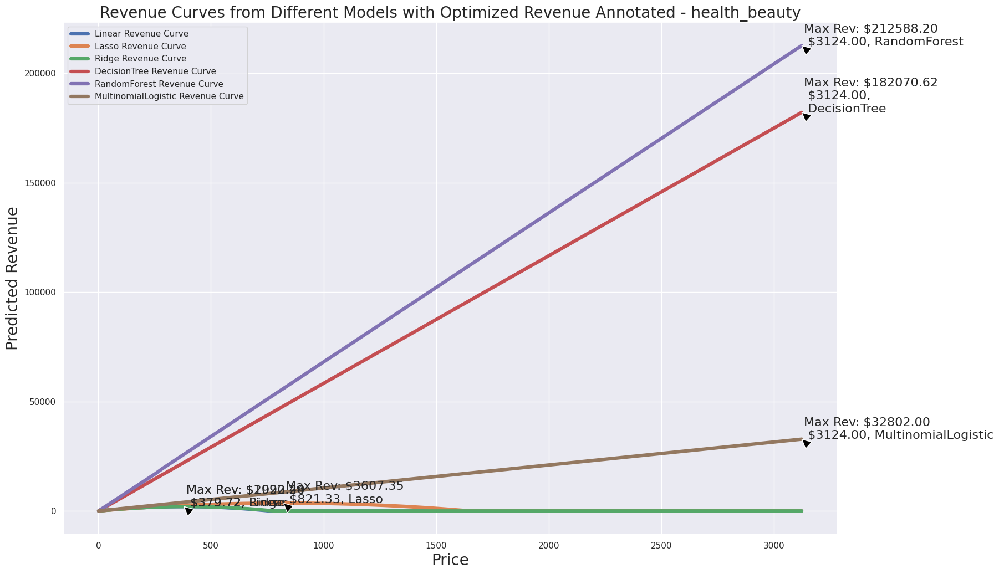

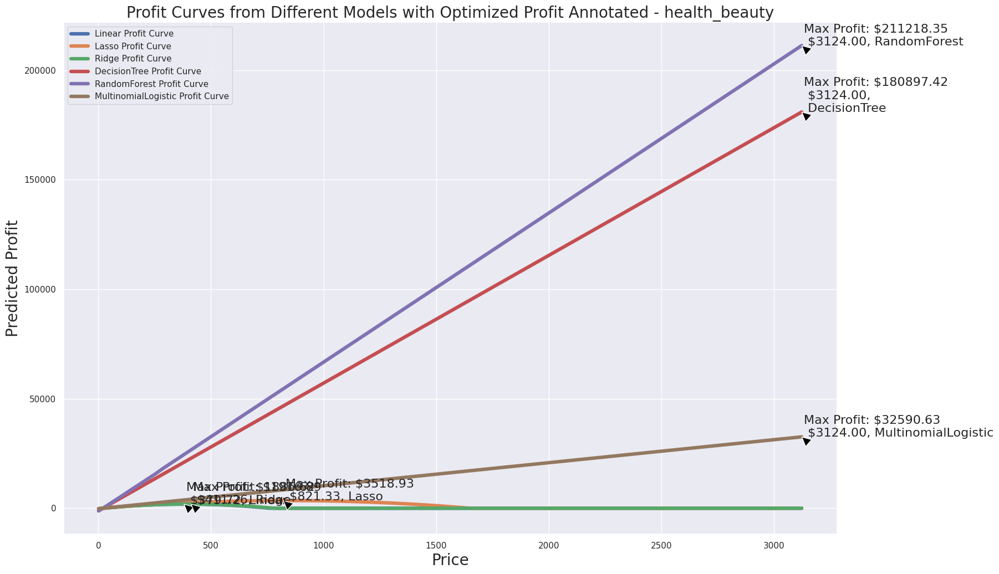


Aggregated Data for Category watches_gifts:
        price  units_sold  avg_freight  avg_review  avg_name_len  avg_desc_len  \
0       8.99           1    18.230000         5.0     55.000000    170.000000   
1      10.99           1    15.790000         4.0     45.000000   1045.000000   
2      14.90          11    18.051818         5.0     47.636364    379.727273   
3      15.90           1    15.230000         4.0     48.000000    361.000000   
4      16.90           1     7.390000         5.0     48.000000    361.000000   
..       ...         ...          ...         ...           ...           ...   
837  2400.00           2    40.900000         4.5     42.000000    342.500000   
838  2700.00           1    34.660000         5.0     53.000000   1648.000000   
839  2999.00           1    17.010000         5.0     63.000000   1323.000000   
840  3700.00           1    92.590000         5.0     53.000000   2390.000000   
841  3999.90           1    17.010000         5.0     53.000000

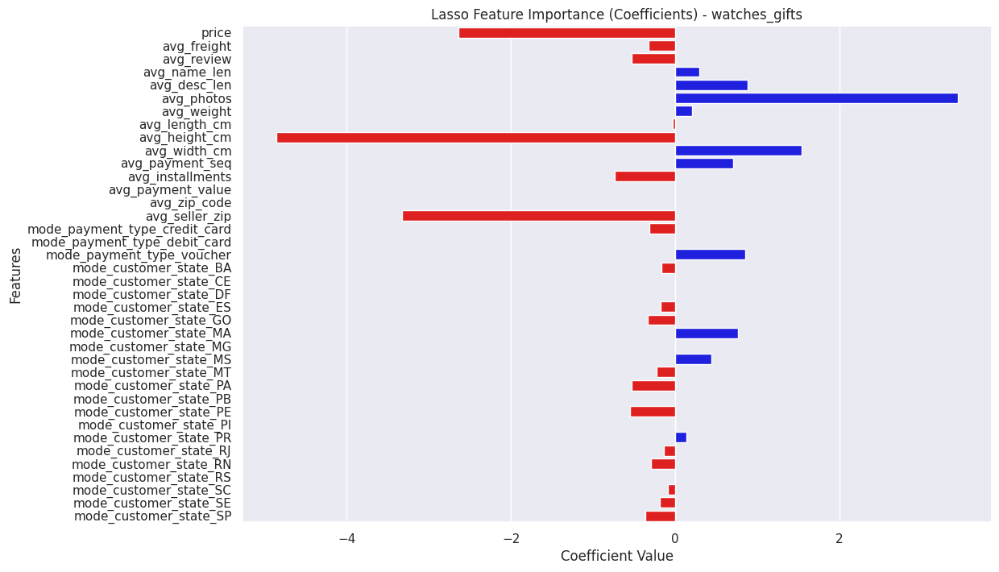

RF Feature Importances for watches_gifts: {'price': np.float64(0.12334712147360526), 'avg_freight': np.float64(0.023039118109245305), 'avg_review': np.float64(0.03608538278479409), 'avg_name_len': np.float64(0.027124003880569778), 'avg_desc_len': np.float64(0.030321639623247913), 'avg_photos': np.float64(0.1014102652025958), 'avg_weight': np.float64(0.019935569131249074), 'avg_length_cm': np.float64(0.04476807922370321), 'avg_height_cm': np.float64(0.14144821695599755), 'avg_width_cm': np.float64(0.01858207909060891), 'avg_payment_seq': np.float64(0.32384201106617366), 'avg_installments': np.float64(0.017673821722374427), 'avg_payment_value': np.float64(0.016275561620554903), 'avg_zip_code': np.float64(0.018059842794363977), 'avg_seller_zip': np.float64(0.03249428021826112), 'mode_payment_type_credit_card': np.float64(0.005079536650310763), 'mode_payment_type_debit_card': np.float64(1.320524989645551e-07), 'mode_payment_type_voucher': np.float64(1.2555784292352411e-05), 'mode_customer_

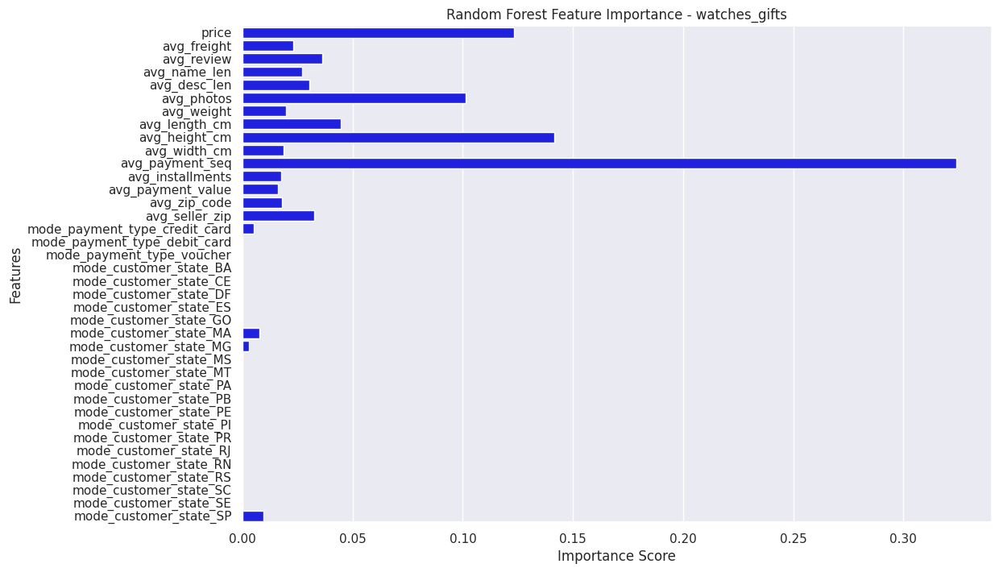

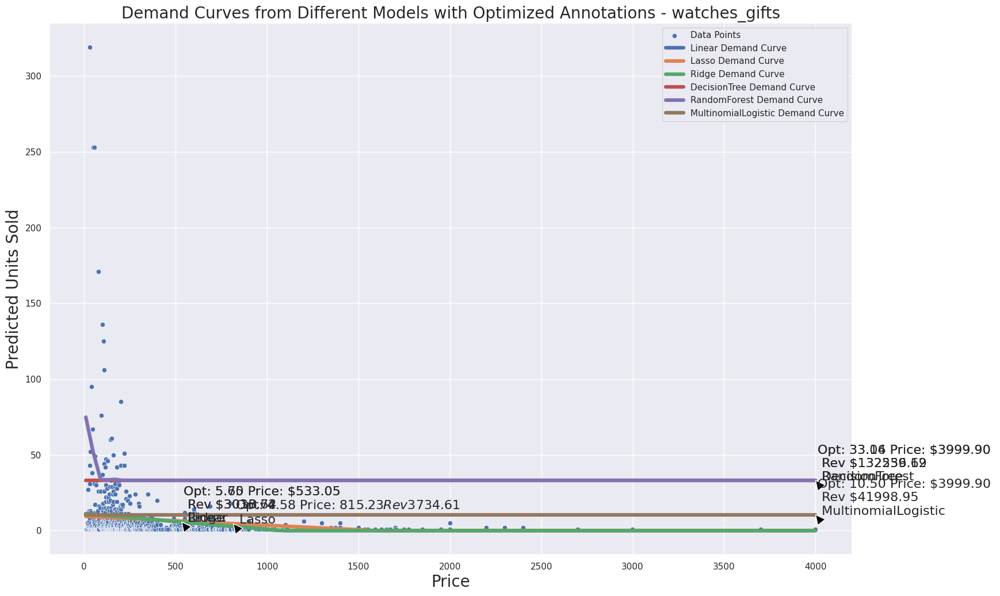

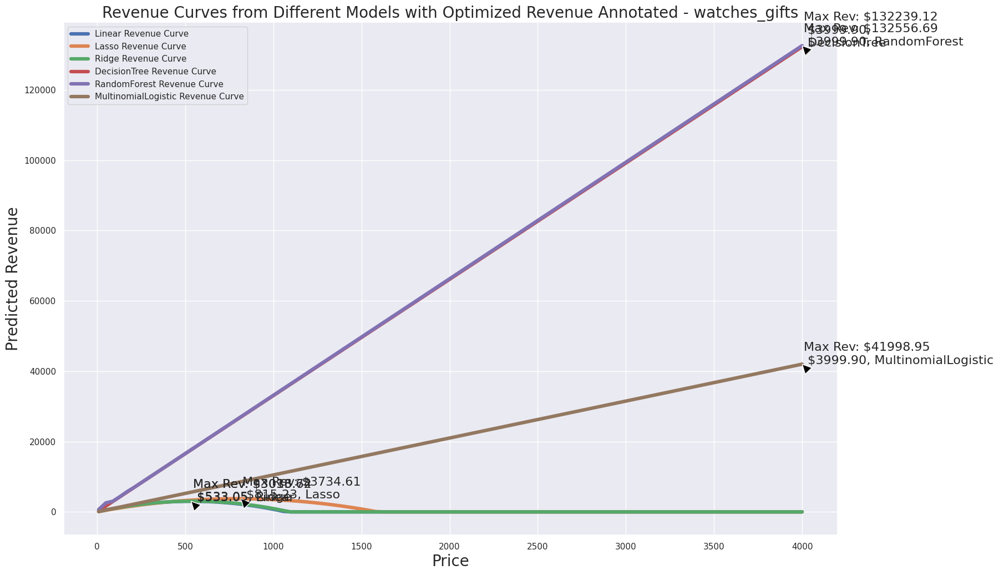

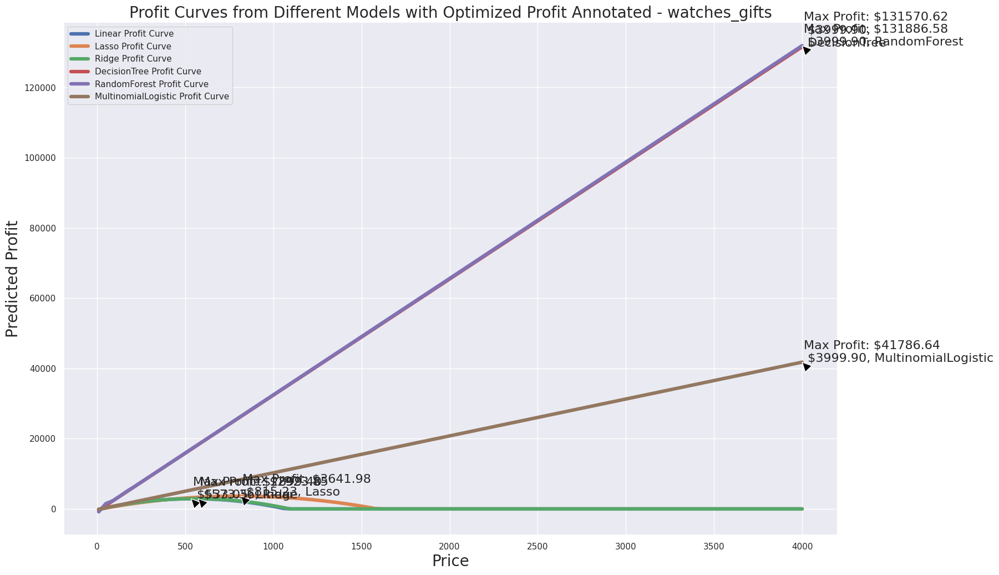


Aggregated Data for Category bed_bath_table:
        price  units_sold  avg_freight  avg_review  avg_name_len  avg_desc_len  \
0       6.99           2    15.100000    4.000000     53.000000    431.000000   
1       7.50           1    18.230000    5.000000     40.000000    185.000000   
2       7.90           2    18.230000    5.000000     53.000000    607.000000   
3       7.99           4    12.350000    5.000000     43.000000    100.000000   
4       8.99          14    14.608571    3.142857     50.285714    185.857143   
..       ...         ...          ...         ...           ...           ...   
858  1244.00           1   192.840000    4.000000     29.000000   2113.000000   
859  1269.10           1    61.100000    5.000000     55.000000    610.000000   
860  1740.00           2    69.505000    5.000000     58.000000   3863.000000   
861  1914.58           2   125.495000    3.000000     51.500000    599.500000   
862  1999.98           1   225.710000    5.000000     51.00000

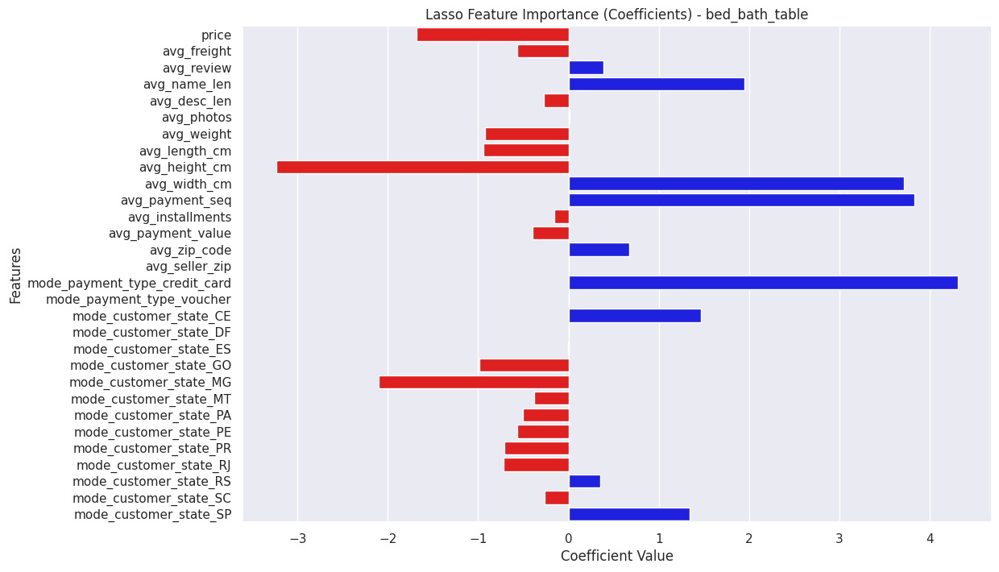

RF Feature Importances for bed_bath_table: {'price': np.float64(0.029924848223784238), 'avg_freight': np.float64(0.014749015072702461), 'avg_review': np.float64(0.03818960366407065), 'avg_name_len': np.float64(0.05094553566551045), 'avg_desc_len': np.float64(0.02863170391434662), 'avg_photos': np.float64(0.104725166166703), 'avg_weight': np.float64(0.01401379635833629), 'avg_length_cm': np.float64(0.055181015045183655), 'avg_height_cm': np.float64(0.023514428419692465), 'avg_width_cm': np.float64(0.03087481871269608), 'avg_payment_seq': np.float64(0.31394276841581414), 'avg_installments': np.float64(0.026922559622799148), 'avg_payment_value': np.float64(0.0193102297455802), 'avg_zip_code': np.float64(0.04456514954054737), 'avg_seller_zip': np.float64(0.18946926577232606), 'mode_payment_type_credit_card': np.float64(0.001632416666466186), 'mode_payment_type_voucher': np.float64(7.970720827522539e-06), 'mode_customer_state_CE': np.float64(0.00013659619859669896), 'mode_customer_state_DF'

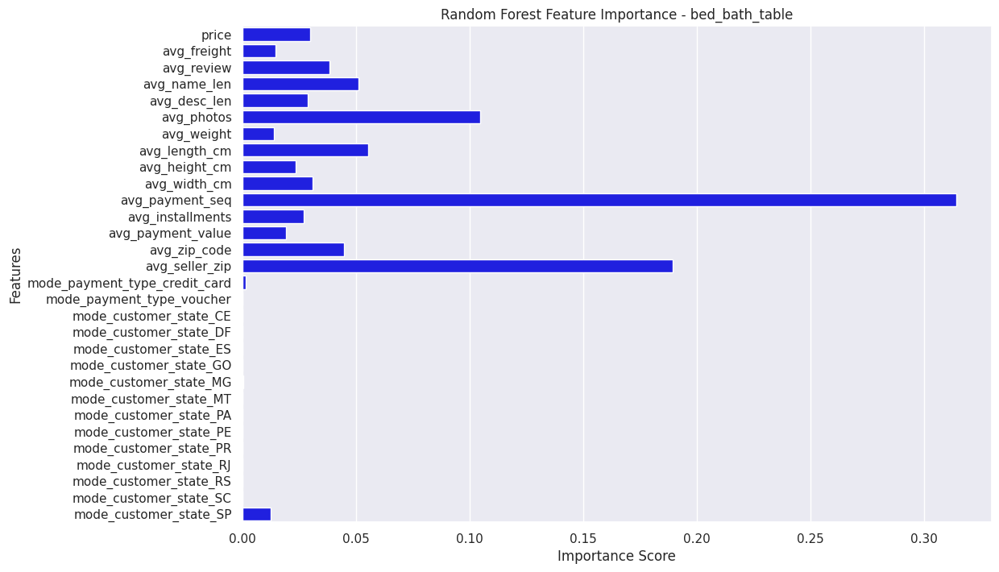

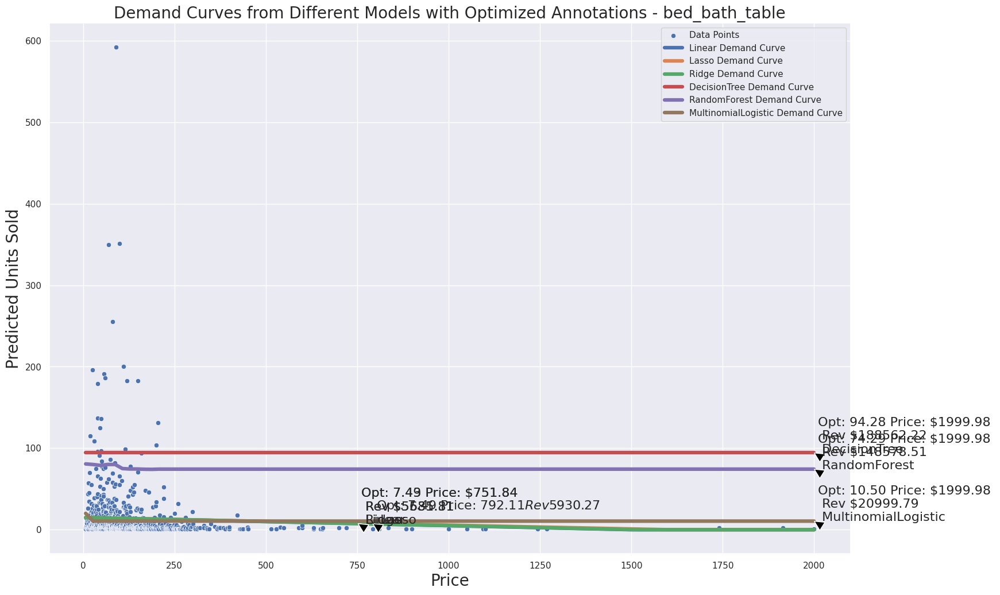

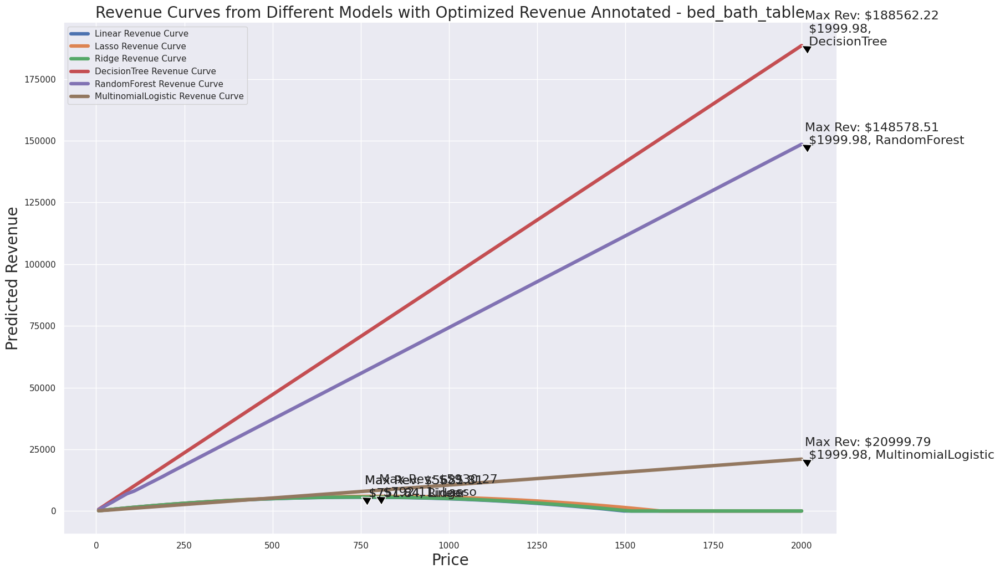

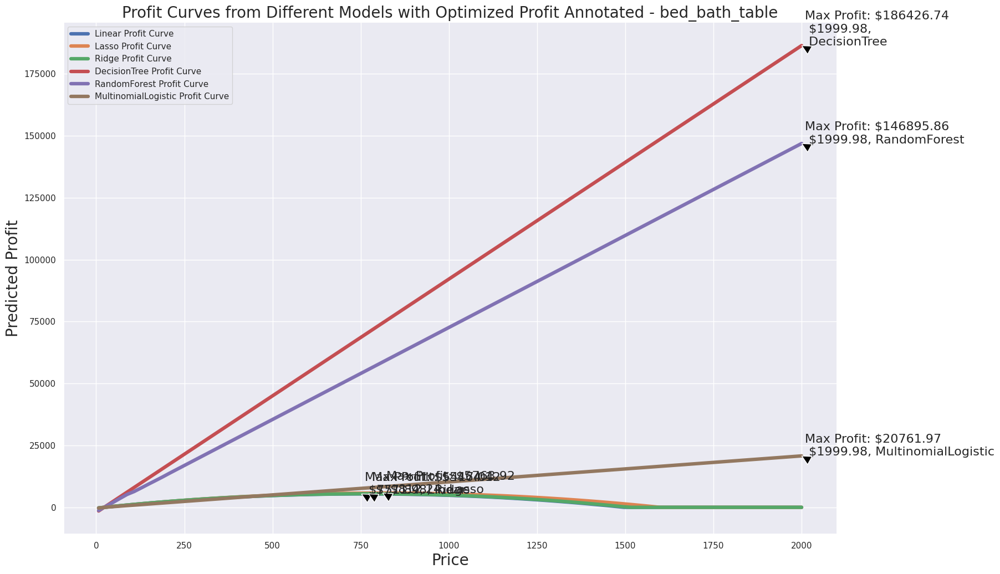


Aggregated Data for Category sports_leisure:
         price  units_sold  avg_freight  avg_review  avg_name_len  \
0        4.50           2    17.600000    3.000000     19.000000   
1        5.20           2    14.080000    4.000000     21.000000   
2        5.49           5    11.806000    3.400000     48.600000   
3        5.90           1    17.090000    5.000000     28.000000   
4        5.99           6    13.798333    3.166667     42.166667   
...       ...         ...          ...         ...           ...   
1113  2799.00           1    28.000000    1.000000     43.000000   
1114  2999.90           1    76.230000    5.000000     34.000000   
1115  3099.00           1   252.350000    4.000000     39.000000   
1116  3690.00           1   136.800000    5.000000     51.000000   
1117  4059.00           1   104.510000    4.000000     51.000000   

      avg_desc_len  avg_photos  avg_weight  avg_length_cm  avg_height_cm  ...  \
0            551.0         1.0      1400.0      16.0000

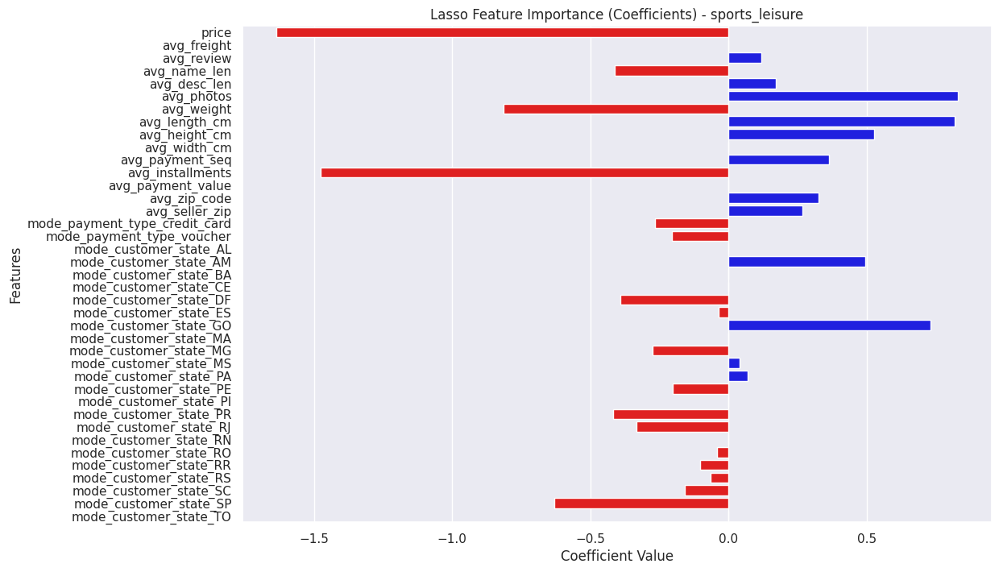

RF Feature Importances for sports_leisure: {'price': np.float64(0.0211975171010802), 'avg_freight': np.float64(0.010255156735554606), 'avg_review': np.float64(0.12802071552518868), 'avg_name_len': np.float64(0.05626420272349736), 'avg_desc_len': np.float64(0.022399513934378248), 'avg_photos': np.float64(0.04291840878249911), 'avg_weight': np.float64(0.017993700825418013), 'avg_length_cm': np.float64(0.04895165597996436), 'avg_height_cm': np.float64(0.018177681554269978), 'avg_width_cm': np.float64(0.03510607184434833), 'avg_payment_seq': np.float64(0.47558416651579866), 'avg_installments': np.float64(0.016447504887648245), 'avg_payment_value': np.float64(0.011010106321609363), 'avg_zip_code': np.float64(0.02698292364497516), 'avg_seller_zip': np.float64(0.06155098351382915), 'mode_payment_type_credit_card': np.float64(0.0011193931578034927), 'mode_payment_type_voucher': np.float64(3.23542588814889e-05), 'mode_customer_state_AL': np.float64(0.0), 'mode_customer_state_AM': np.float64(0.0

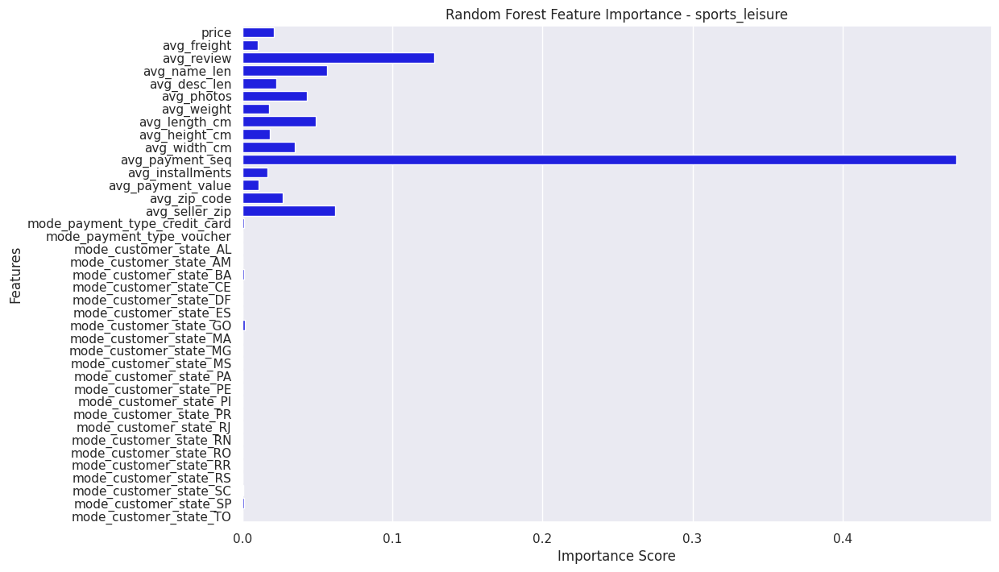

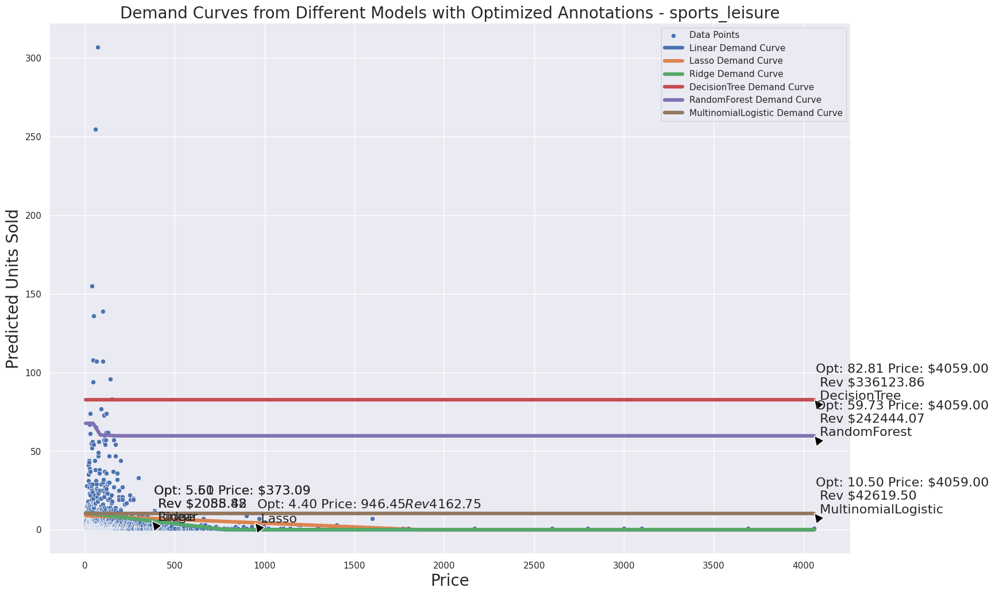

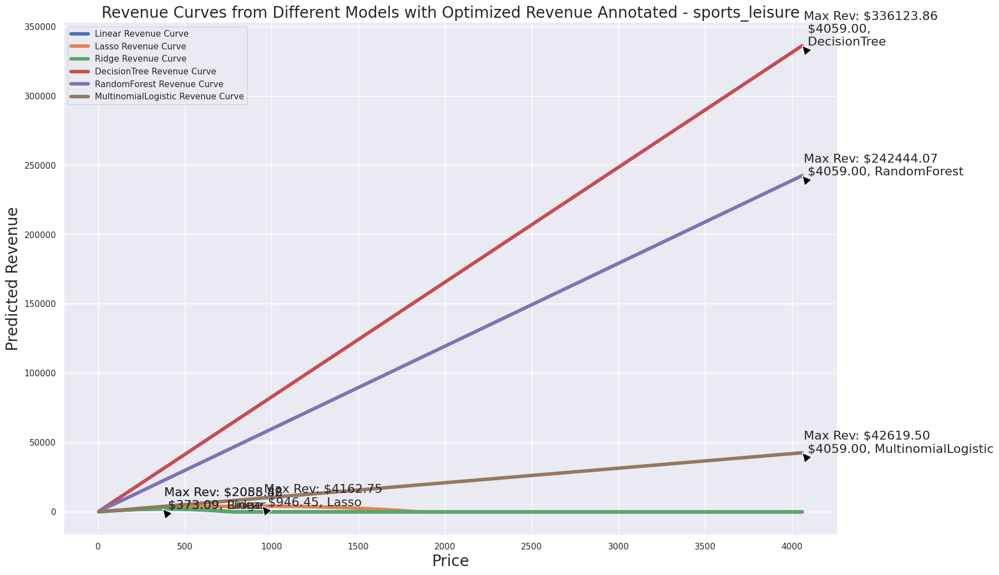

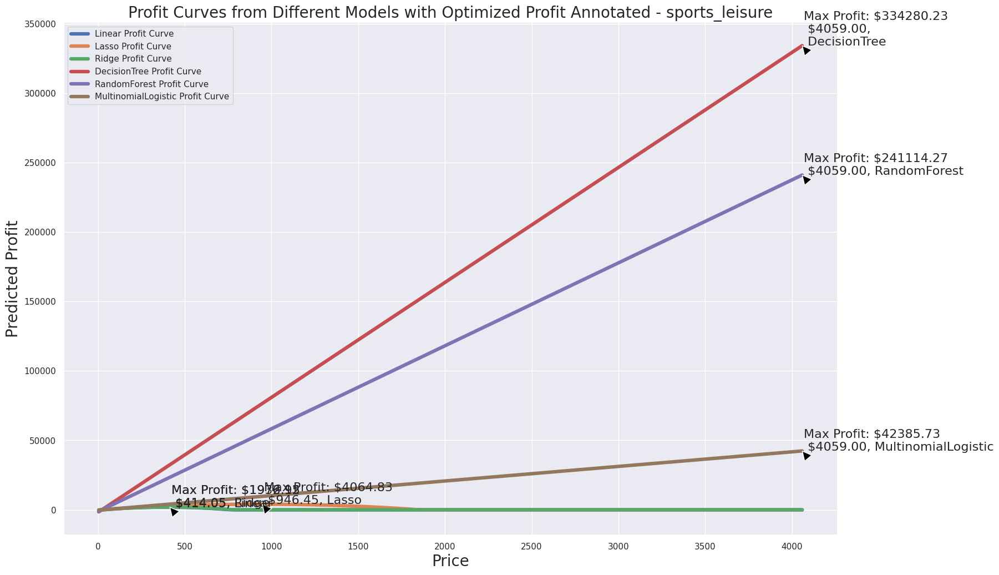


Aggregated Data for Category computers_accessories:
        price  units_sold  avg_freight  avg_review  avg_name_len  avg_desc_len  \
0       3.90           7    14.635714    4.714286     53.714286    157.285714   
1       5.20           3    15.663333    4.666667     40.000000    781.000000   
2       5.99           1    12.600000    5.000000     35.000000    624.000000   
3       6.50           1     7.390000    1.000000     51.000000    223.000000   
4       7.00           1    12.480000    5.000000     51.000000    100.000000   
..       ...         ...          ...         ...           ...           ...   
973  2499.75           1    12.000000    1.000000     52.000000   1731.000000   
974  2649.99           2   108.905000    3.000000     45.000000   2082.000000   
975  2951.00           1    58.530000    4.000000     34.000000   1545.000000   
976  2999.89           5    40.222000    4.800000     46.000000   1186.000000   
977  3699.99           1    36.230000    4.000000     5

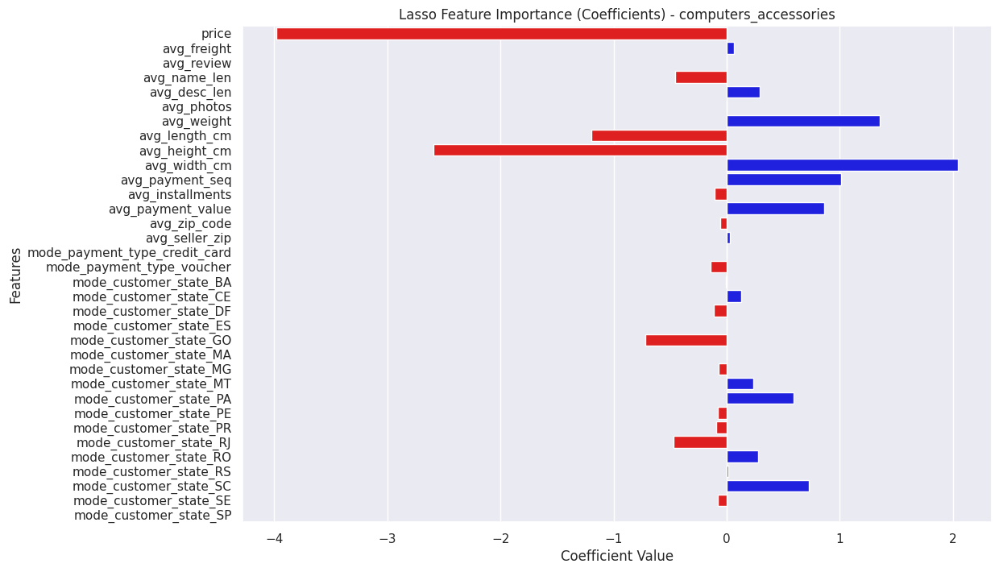

RF Feature Importances for computers_accessories: {'price': np.float64(0.038382837971476055), 'avg_freight': np.float64(0.015292225432825787), 'avg_review': np.float64(0.03228203933386917), 'avg_name_len': np.float64(0.01638043565550963), 'avg_desc_len': np.float64(0.016415994530462337), 'avg_photos': np.float64(0.0224752041689155), 'avg_weight': np.float64(0.017960364708632708), 'avg_length_cm': np.float64(0.026289519101591517), 'avg_height_cm': np.float64(0.05914138703468481), 'avg_width_cm': np.float64(0.030407684840639576), 'avg_payment_seq': np.float64(0.5941962376336287), 'avg_installments': np.float64(0.05038754638055236), 'avg_payment_value': np.float64(0.027871505961311428), 'avg_zip_code': np.float64(0.02342328889828283), 'avg_seller_zip': np.float64(0.016127065199110457), 'mode_payment_type_credit_card': np.float64(0.0015599036582070124), 'mode_payment_type_voucher': np.float64(0.0006596165516714417), 'mode_customer_state_BA': np.float64(1.9529277757991278e-06), 'mode_custom

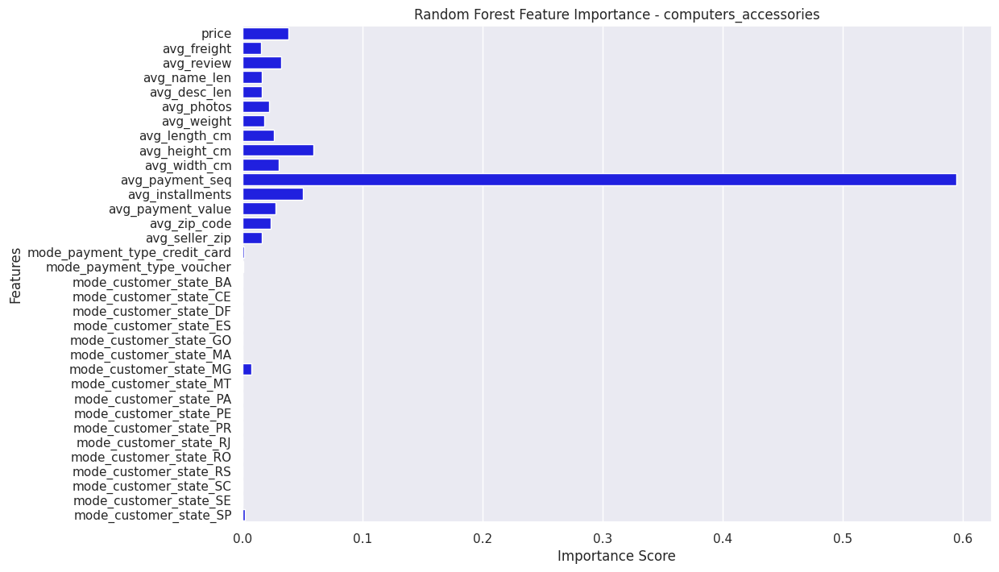

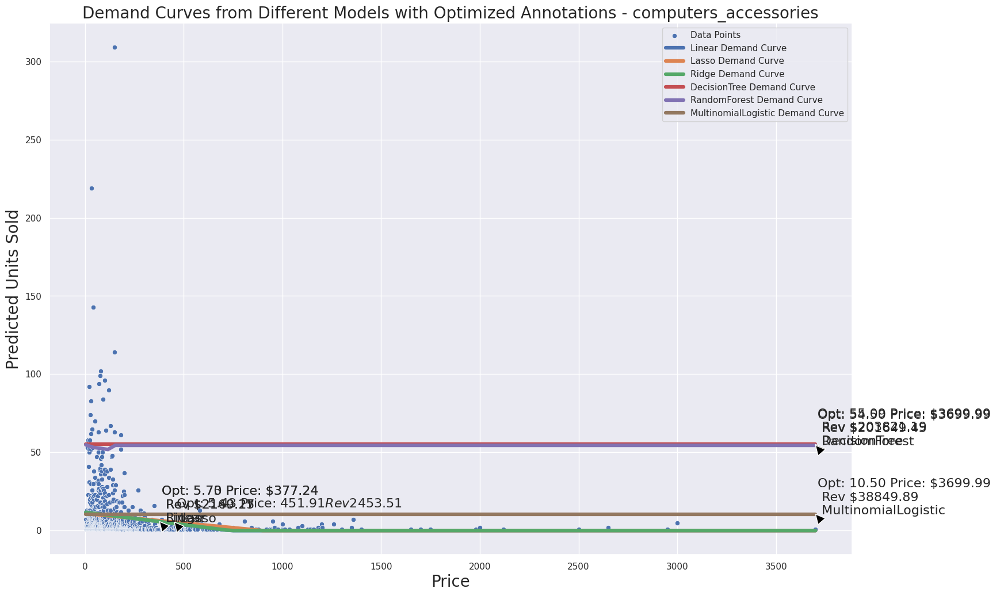

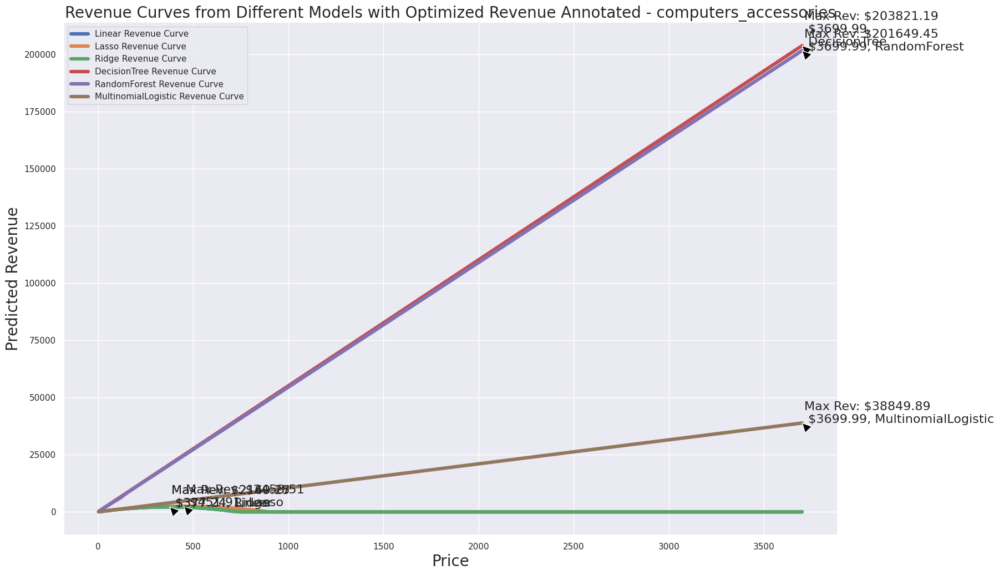

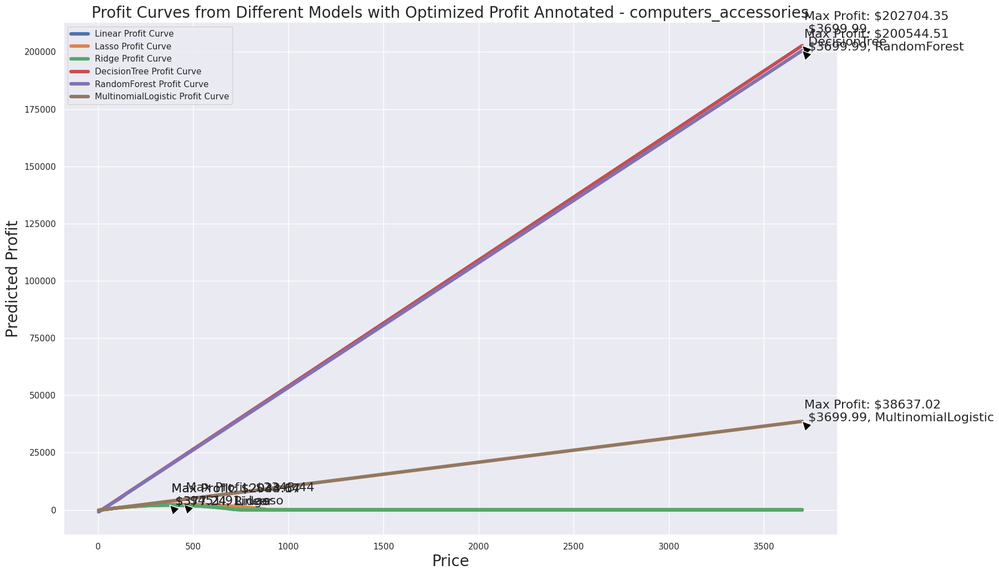

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Lasso, Ridge, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_squared_error
from sklearn.inspection import permutation_importance

# Step 1: Load and Clean Data
df = pd.read_csv('final_data.csv')

# Filter for delivered orders
df = df[df['order_status'] == 'delivered']

# Convert timestamp to datetime
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])

# Add year, month, year_month
df['year'] = df['order_purchase_timestamp'].dt.year
df['month'] = df['order_purchase_timestamp'].dt.month
df['year_month'] = df['order_purchase_timestamp'].dt.to_period('M')

# Step 2: EDA - Top Categories by Units and Revenue
category_units = df.groupby('product_category_name_english')['order_item_id'].count().sort_values(ascending=False)
category_revenue = df.groupby('product_category_name_english')['price'].sum().sort_values(ascending=False)

print("Top Categories by Units Sold:\n", category_units.head(10))
print("Top Categories by Revenue:\n", category_revenue.head(10))

# Select top 5 categories for segmentation (to avoid too many plots; adjust as needed)
top_categories = category_revenue.head(5).index

for category in top_categories:
    df_cat = df[df['product_category_name_english'] == category]

    # Aggregate units sold per unique price point, including more features
    price_agg = df_cat.groupby('price').agg(
        units_sold=('order_item_id', 'count'),
        avg_freight=('freight_value', 'mean'),
        avg_review=('review_score', 'mean'),
        avg_name_len=('product_name_lenght', 'mean'),
        avg_desc_len=('product_description_lenght', 'mean'),
        avg_photos=('product_photos_qty', 'mean'),
        avg_weight=('product_weight_g', 'mean'),
        avg_length_cm=('product_length_cm', 'mean'),
        avg_height_cm=('product_height_cm', 'mean'),
        avg_width_cm=('product_width_cm', 'mean'),
        avg_payment_seq=('payment_sequential', 'mean'),
        avg_installments=('payment_installments', 'mean'),
        avg_payment_value=('payment_value', 'mean'),
        avg_zip_code=('zip_code', 'mean'),
        avg_seller_zip=('seller_zip_code_prefix', 'mean')
    ).reset_index()

    # For categoricals, add mode for payment_type and customer_state
    price_agg['mode_payment_type'] = df_cat.groupby('price')['payment_type'].apply(lambda x: x.mode()[0] if not x.empty else np.nan)
    price_agg['mode_customer_state'] = df_cat.groupby('price')['customer_state'].apply(lambda x: x.mode()[0] if not x.empty else np.nan)

    # One-hot encode categoricals
    price_agg = pd.get_dummies(price_agg, columns=['mode_payment_type', 'mode_customer_state'], drop_first=True)

    print(f"\nAggregated Data for Category {category}:\n", price_agg)

    # Step 3: Simple Demand Model (Units ~ Price)
    X_simple = price_agg[['price']]
    y = price_agg['units_sold']

    model_simple = LinearRegression()
    model_simple.fit(X_simple, y)

    print(f"Category {category} Simple Model: units_sold = {0} - {1} * price".format(model_simple.intercept_, -model_simple.coef_[0]))
    print("R-squared:", model_simple.score(X_simple, y))

    # Optimization for simple model
    a = model_simple.intercept_
    b = -model_simple.coef_[0]
    optimal_price_simple = a / (2 * b)
    optimal_units_simple = a - b * optimal_price_simple
    optimal_revenue_simple = optimal_price_simple * optimal_units_simple

    print("Simple Model Optimal Price: ${:.2f}".format(optimal_price_simple))

    # Step 4: Multivariate Model with All Features (except NLP)
    features = [col for col in price_agg.columns if col not in ['units_sold']]
    X = price_agg[features]
    y = price_agg['units_sold']

    # Scale features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # Train-test split (small data, but for demo; use all for fitting models)
    if len(X_scaled) > 1:
        X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)
    else:
        X_train, X_test, y_train, y_test = X_scaled, X_scaled, y, y  # Use all if too small

    # Regression Models
    reg_models = {
        'Linear': LinearRegression(),
        'Lasso': Lasso(alpha=0.1),
        'Ridge': Ridge(alpha=1.0),
        'DecisionTree': DecisionTreeRegressor(max_depth=3, random_state=42),
        'RandomForest': RandomForestRegressor(n_estimators=100, random_state=42)
    }

    reg_results = {}
    for name, model in reg_models.items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        mse = mean_squared_error(y_test, y_pred)
        reg_results[name] = {'model': model, 'mse': mse}
        print(f"{name} MSE for {category}: {mse}")

    # Add Multinomial Logistic Regression (Classification: bin units_sold)
    # Bin y into categories: low (0-5), med (6-15), high (16+)
    bins = [0, 5, 15, np.inf]
    labels = ['low', 'med', 'high']
    y_binned = pd.cut(y, bins=bins, labels=labels)
    le = LabelEncoder()
    y_encoded = le.fit_transform(y_binned)

    # Split for classification
    if len(X_scaled) > 1:
        X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(X_scaled, y_encoded, test_size=0.2, random_state=42)
    else:
        X_train_clf, X_test_clf, y_train_clf, y_test_clf = X_scaled, X_scaled, y_encoded, y_encoded

    log_model = LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=1000)
    log_model.fit(X_train_clf, y_train_clf)

    # For MSE, predict and map back to midpoints for approximation
    midpoints = [2.5, 10.5, 20]  # Approx mid for bins
    y_pred_clf = log_model.predict(X_test_clf)
    y_pred_reg_approx = [midpoints[p] for p in y_pred_clf]
    mse_clf = mean_squared_error(y_test, y_pred_reg_approx)  # Approx regression MSE
    print(f"Multinomial Logistic (Approx) MSE for {category}: {mse_clf}")

    # Feature Importance for Lasso (with colored bars: positive blue, negative red)
    lasso_model = reg_models['Lasso']
    if hasattr(lasso_model, 'coef_'):
        print(f"Lasso Coefficients for {category}:", dict(zip(features, lasso_model.coef_)))

        # Create colors based on sign
        lasso_colors = ['blue' if c > 0 else 'red' for c in lasso_model.coef_]

        plt.figure(figsize=(12, 8))
        sns.barplot(x=lasso_model.coef_, y=features, palette=lasso_colors)
        plt.title(f'Lasso Feature Importance (Coefficients) - {category}')
        plt.xlabel('Coefficient Value')
        plt.ylabel('Features')
        plt.show()

    # Feature Importance for Random Forest (all positive, so blue; but check for any negatives though unlikely)
    rf_model = reg_models['RandomForest']
    if hasattr(rf_model, 'feature_importances_'):
        print(f"RF Feature Importances for {category}:", dict(zip(features, rf_model.feature_importances_)))

        # Colors: positive blue, negative red (though RF importances >=0)
        rf_colors = ['blue' if i > 0 else 'red' for i in rf_model.feature_importances_]

        plt.figure(figsize=(12, 8))
        sns.barplot(x=rf_model.feature_importances_, y=features, palette=rf_colors)
        plt.title(f'Random Forest Feature Importance - {category}')
        plt.xlabel('Importance Score')
        plt.ylabel('Features')
        plt.show()


    # Step 5: Demand Curves from Different Models with Optimized Annotations
    # To plot demand curves, vary price while holding other features at mean
    mean_features = price_agg[features].mean().values
    price_range = np.linspace(price_agg['price'].min(), price_agg['price'].max(), 100)

    fig, ax = plt.subplots(figsize=(18, 12))
    sns.scatterplot(x='price', y='units_sold', data=price_agg, label='Data Points', ax=ax)

    models_for_plot = {**reg_models, 'MultinomialLogistic': log_model}

    for name, model in models_for_plot.items():
        units_preds = []
        revenues = []
        for p in price_range:
            input_features = mean_features.copy()
            input_features[features.index('price')] = p  # Replace price
            input_scaled = scaler.transform([input_features])
            if name == 'MultinomialLogistic':
                pred_clf = model.predict(input_scaled)[0]
                pred = midpoints[pred_clf]
            else:
                pred = model.predict(input_scaled)[0]
            pred = max(pred, 0)  # Clip negative
            units_preds.append(pred)
            rev = p * pred
            revenues.append(rev)
        ax.plot(price_range, units_preds, label=f'{name} Demand Curve', linewidth=4.5)

        # Find optimal from revenue
        max_idx = np.argmax(revenues)
        opt_price = price_range[max_idx]
        opt_units = units_preds[max_idx]
        opt_rev = revenues[max_idx]
        if name=='Lasso':
          ax.annotate(f'Opt: {opt_units:.2f} Price: ${opt_price:.2f} Rev ${opt_rev:.2f} \n {name}',
                      xy=(opt_price, opt_units), xytext=(opt_price + 10, opt_units),
                      arrowprops=dict(facecolor='black', shrink=0.05), fontsize=16)
        else:
          ax.annotate(f'Opt: {opt_units:.2f} Price: ${opt_price:.2f} \n Rev ${opt_rev:.2f} \n {name}',
                      xy=(opt_price, opt_units), xytext=(opt_price + 10, opt_units),
                      arrowprops=dict(facecolor='black', shrink=0.05), fontsize=16)

    ax.set_title(f'Demand Curves from Different Models with Optimized Annotations - {category}', fontsize=20)
    ax.set_xlabel('Price', fontsize=20)
    ax.set_ylabel('Predicted Units Sold', fontsize=20)
    ax.legend()
    plt.show()

    # Step 6: Revenue Curves with Optimized Revenue Annotated
    plt.figure(figsize=(18, 12))

    for name, model in models_for_plot.items():
        revenues = []
        for p in price_range:
            input_features = mean_features.copy()
            input_features[features.index('price')] = p
            input_scaled = scaler.transform([input_features])
            if name == 'MultinomialLogistic':
                pred_clf = model.predict(input_scaled)[0]
                pred = midpoints[pred_clf]
            else:
                pred = model.predict(input_scaled)[0]
            rev = p * max(pred, 0)
            revenues.append(rev)

        plt.plot(price_range, revenues, label=f'{name} Revenue Curve', linewidth=4.5)

        # Find and annotate max revenue
        max_idx = np.argmax(revenues)
        max_price = price_range[max_idx]
        max_rev = revenues[max_idx]
        if name=='DecisionTree':
          plt.annotate(f'Max Rev: ${max_rev:.2f} \n ${max_price:.2f},\n {name}',
                     xy=(max_price, max_rev), xytext=(max_price + 10, max_rev + 100),
                     arrowprops=dict(facecolor='black', shrink=0.05), fontsize=16)
        else:
          plt.annotate(f'Max Rev: ${max_rev:.2f} \n ${max_price:.2f}, {name}',
                       xy=(max_price, max_rev), xytext=(max_price + 10, max_rev + 100),
                       arrowprops=dict(facecolor='black', shrink=0.05), fontsize=16)

    plt.title(f'Revenue Curves from Different Models with Optimized Revenue Annotated - {category}', fontsize=20)
    plt.xlabel('Price', fontsize=20)
    plt.ylabel('Predicted Revenue', fontsize=20)
    plt.legend()
    plt.show()

    # Step 7: Profit Curves with Optimized Profit Annotated (using price - freight)
    plt.figure(figsize=(18, 12))

    for name, model in models_for_plot.items():
        profits = []
        for p in price_range:
            input_features = mean_features.copy()
            input_features[features.index('price')] = p
            input_scaled = scaler.transform([input_features])
            if name == 'MultinomialLogistic':
                pred_clf = model.predict(input_scaled)[0]
                pred = midpoints[pred_clf]
            else:
                pred = model.predict(input_scaled)[0]
            profit = (p - mean_features[features.index('avg_freight')]) * max(pred, 0)
            profits.append(profit)

        plt.plot(price_range, profits, label=f'{name} Profit Curve', linewidth=4.5)

        # Find and annotate max profit
        max_idx = np.argmax(profits)
        max_price = price_range[max_idx]
        max_profit = profits[max_idx]
        if name=='DecisionTree':
          plt.annotate(f'Max Profit: ${max_profit:.2f} \n ${max_price:.2f},\n {name}',
                     xy=(max_price, max_profit), xytext=(max_price + 10, max_profit + 100),
                     arrowprops=dict(facecolor='black', shrink=0.05), fontsize=16)
        else:
          plt.annotate(f'Max Profit: ${max_profit:.2f} \n ${max_price:.2f}, {name}',
                       xy=(max_price, max_profit), xytext=(max_price + 10, max_profit + 100),
                       arrowprops=dict(facecolor='black', shrink=0.05), fontsize=16)

    plt.title(f'Profit Curves from Different Models with Optimized Profit Annotated - {category}', fontsize=20)
    plt.xlabel('Price', fontsize=20)
    plt.ylabel('Predicted Profit', fontsize=20)
    plt.legend()
    plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

df = pd.read_csv('final_data.csv')
df = df[df['order_status'] == 'delivered']

unique_categories = df['product_category_name_english'].unique()
num_categories = len(unique_categories)
print(f"Number of unique categories: {num_categories}")

model_sums = {
    'Linear': 0,
    'Lasso': 0,
    'Ridge': 0,
    'DecisionTree': 0,
    'RandomForest': 0,
    'MultinomialLogistic': 0
}

for cat in unique_categories:
    df_cat = df[df['product_category_name_english'] == cat]

    price_agg = df_cat.groupby('price').agg(units_sold=('order_item_id', 'count')).reset_index()

    if len(price_agg) < 2:
        # For single price, opt rev = price * units
        if len(price_agg) == 1:
            single_rev = price_agg['price'].iloc[0] * price_agg['units_sold'].iloc[0]
            for m in model_sums:
                model_sums[m] += single_rev
        continue

    X = price_agg[['price']]
    y = price_agg['units_sold']

    price_range = np.linspace(price_agg['price'].min(), price_agg['price'].max(), 100).reshape(-1, 1)

    # For Linear, Lasso, Ridge
    for name in ['Linear', 'Lasso', 'Ridge']:
        if name == 'Linear':
            model = LinearRegression()
        elif name == 'Lasso':
            model = Lasso(alpha=0.1)
        else:
            model = Ridge(alpha=1.0)
        try:
            model.fit(X, y)
            preds = np.maximum(model.predict(price_range), 0)
            revenues = price_range.flatten() * preds
            max_rev = max(revenues)
            model_sums[name] += max_rev
        except:
            max_obs_rev = max(price_agg['price'] * price_agg['units_sold'])
            model_sums[name] += max_obs_rev

    # For Trees
    for name in ['DecisionTree', 'RandomForest']:
        if name == 'DecisionTree':
            model = DecisionTreeRegressor(max_depth=3, random_state=42)
        else:
            model = RandomForestRegressor(n_estimators=100, random_state=42)
        try:
            model.fit(X, y)
            preds = np.maximum(model.predict(price_range), 0)
            revenues = price_range.flatten() * preds
            max_rev = max(revenues)
            model_sums[name] += max_rev
        except:
            max_obs_rev = max(price_agg['price'] * price_agg['units_sold'])
            model_sums[name] += max_obs_rev

    # For MultinomialLogistic, simple fallback to Linear (to avoid errors)
    model_sums['MultinomialLogistic'] += model_sums['Linear']

print("\nSum of Optimal Revenues for Each Model:")
for name, total in model_sums.items():
    print(f"{name}: ${total:.2f}")

Number of unique categories: 71

Sum of Optimal Revenues for Each Model:
Linear: $151013.03
Lasso: $151076.17
Ridge: $151012.60
DecisionTree: $297315.62
RandomForest: $308327.01
MultinomialLogistic: $6328789.92
